# Weinreb Day-2 HSPC gene programs and targeted metaclonal signatures

This analysis uses every Day-2 cell assigned to a current Weinreb
metaclone whose source label is `prog_1` or `prog_2`. Those labels are
collapsed into one HSPC compartment before eligibility, aggregation,
modeling, program scoring, or plotting. Each LARRY clone contributes one
recovered-count pseudobulk, so nested cells are not treated as independent
replicates.

The original three comparison tiers are retained as broad context:

1. every metaclone versus the equal-metaclone mean of the other 19;
2. pooled lineage-bias families, including all pairwise family contrasts;
3. each metaclone versus peers in the same lineage-bias family, including
   every within-family pair.

The manuscript-facing primary analysis tests four locked, non-exclusive
Day-6 behavioral axes within the seven Multi-lineage metaclones: Baso-rich,
Neu-rich, Mono-rich, and persistent-undifferentiated output. Each axis is
tested as an equal-metaclone focal pair versus the equal-metaclone mean of
the other five, with both member effects, max-P conjunction, comparator-drop,
and cell-removal/library-refit sensitivities. The broad 1,450-estimable
correlation screen is retained only as a supplementary sensitivity.

The fixed program universe is MSigDB Hallmark 2020. Program scores are
unweighted means of gene-wise standardized log-normalized expression in
clone pseudobulks. Gene-level negative-binomial contrasts and preranked
Hallmark enrichment are retained as supporting evidence. All results are
retrospective associations in the realized current partition, not causal
or prospective predictors of later fate.

## tl;dr

Computed findings are printed from live objects in the computed-findings section rather
than hard-coded into notebook Markdown. The principal tables and figures are
created before that summary and validated at the end of the run.

## Context & Methods

### Reproducible environment

- Environment manager/name: existing Conda-compatible environment,
  `chronoclone` (reused without mutation)
- Absolute MacBook-local path:
  `/path/to/ChronoClone/.runtime/chronoclone`
- Jupyter kernel: `chronoclone`
- Python: 3.11.15
- Exact execution command:

  `/path/to/ChronoClone/.runtime/chronoclone/bin/jupyter-nbconvert --to notebook --execute --inplace --ExecutePreprocessor.kernel_name=chronoclone --ExecutePreprocessor.timeout=7200 /path/to/ChronoClone/analysis_workspace/analyses/weinreb_day2_hspc_metaclone_gene_programs_20260902/0001_weinreb_day2_hspc_metaclone_gene_programs.ipynb`

The next cell verifies the executable, kernel registration, and package
versions. No package is installed or changed by this notebook.

In [1]:
import os
os.environ.setdefault("MPLCONFIGDIR", "/private/tmp/research_weinreb_programs_mpl")
os.environ.setdefault("NUMBA_CACHE_DIR", "/private/tmp/research_weinreb_programs_numba")
os.environ.setdefault("OMP_NUM_THREADS", "1")
os.environ.setdefault("OPENBLAS_NUM_THREADS", "1")

import hashlib
import importlib.metadata as im
import itertools
import json
import shutil
import sys
import warnings
from pathlib import Path
from textwrap import fill

import anndata as ad
import gseapy as gp
import matplotlib as mpl
import matplotlib.pyplot as plt
import nbformat
import numpy as np
import pandas as pd
import scipy.sparse as sp
import statsmodels.api as sm
from IPython.display import display
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Patch

PROJECT_ROOT = Path("/path/to/ChronoClone")
ANALYSIS_DIR = PROJECT_ROOT / "analysis_workspace/analyses/weinreb_day2_hspc_metaclone_gene_programs_20260902"
FIGDIR = ANALYSIS_DIR / "figures"
TABLEDIR = ANALYSIS_DIR / "tables"
REPORTDIR = ANALYSIS_DIR / "reports"
RESOURCEDIR = ANALYSIS_DIR / "resources"
for directory in (FIGDIR, TABLEDIR, REPORTDIR, RESOURCEDIR):
    directory.mkdir(parents=True, exist_ok=True)

NOTEBOOK_PATH = ANALYSIS_DIR / "0001_weinreb_day2_hspc_metaclone_gene_programs.ipynb"
BUILDER_PATH = ANALYSIS_DIR / "scripts/build_notebook.py"
INPUT_H5AD = PROJECT_ROOT / "reference_workspace/data/klein_metaclone_palantir_trajectories.h5ad"
LINEAGE_MAP_PATH = PROJECT_ROOT / "reference_workspace/Figure/fig2/data/fig2h_lineage_bias_map.csv"
HALLMARK_SOURCE = PROJECT_ROOT / "reference_workspace/data/gene_sets/MSigDB_Hallmark_2020.gmt"
HALLMARK_LOCAL = RESOURCEDIR / "MSigDB_Hallmark_2020.gmt"

ENV_PATH = Path("/path/to/ChronoClone/.runtime/chronoclone")
PYTHON_PATH = ENV_PATH / "bin/python"
JUPYTER_PATH = ENV_PATH / "bin/jupyter"
NBCONVERT_PATH = ENV_PATH / "bin/jupyter-nbconvert"
KERNEL_JSON = Path("~/Library/Jupyter/kernels/chronoclone/kernel.json")
EXECUTION_COMMAND = (
    f"{NBCONVERT_PATH} --to notebook --execute --inplace "
    f"--ExecutePreprocessor.kernel_name=chronoclone --ExecutePreprocessor.timeout=7200 {NOTEBOOK_PATH}"
)
assert (
    PYTHON_PATH.exists() and JUPYTER_PATH.exists()
    and NBCONVERT_PATH.exists() and KERNEL_JSON.exists()
)
assert Path(os.path.realpath(sys.executable)) == Path(os.path.realpath(PYTHON_PATH))

packages = [
    "adjustText", "anndata", "gseapy", "matplotlib", "nbclient", "nbformat", "numpy",
    "pandas", "pydeseq2", "scipy", "statsmodels"
]
versions = {package: im.version(package) for package in packages}
environment = pd.DataFrame({
    "field": [
        "manager/name", "environment_path", "python", "kernel",
        "kernel_json", "python_version", "versions", "execution_command"
    ],
    "value": [
        "existing Conda-compatible / chronoclone (reused; not mutated)",
        str(ENV_PATH), sys.executable, "chronoclone", str(KERNEL_JSON),
        sys.version.split()[0], json.dumps(versions, sort_keys=True), EXECUTION_COMMAND
    ]
})
environment.to_csv(REPORTDIR / "environment.csv", index=False)
display(environment)

EXPECTED_INPUT_SHA256 = "4cb08c12dc70f5c3789a75a09a6399db06b3f6efe18147b9f2cca0908ba93911"
EXPECTED_LINEAGE_MAP_SHA256 = "b4d1af7b481a9b1a26d781feb449fb88d300d770c20633054e152f213fa18eb6"
EXPECTED_HALLMARK_SHA256 = "4275592957a1587652092bb398cf77216fde5b8daa2aedaa0e016f7d10bbdb81"
HSPC_SOURCE_LABELS = ["prog_1", "prog_2"]
FAMILY_GROUPS = {
    "Neutrophil": [9, 14, 16, 22, 1],
    "Monocyte": [12, 7, 8, 6],
    "Erythroid / Mk": [10, 17, 23],
    "Basophil": [13],
    "Multi-lineage": [0, 2, 5, 3, 18, 4, 11],
}
FAMILY_KEY = {
    "Neutrophil": "Neutrophil", "Monocyte": "Monocyte",
    "Erythroid / Mk": "Erythroid_Mk", "Basophil": "Basophil",
    "Multi-lineage": "Multi_lineage",
}
FAMILY_DISPLAY = {value: key for key, value in FAMILY_KEY.items()}
MC_ORDER = [mc for members in FAMILY_GROUPS.values() for mc in members]
FAMILY_ORDER = list(FAMILY_GROUPS)
FAMILY_KEY_ORDER = [FAMILY_KEY[name] for name in FAMILY_ORDER]
MC_TO_FAMILY = {mc: family for family, members in FAMILY_GROUPS.items() for mc in members}
MC_TO_FAMILY_KEY = {mc: FAMILY_KEY[family] for mc, family in MC_TO_FAMILY.items()}

FAMILY_COLORS = {
    "Neutrophil": "#E0913C", "Monocyte": "#B23A48",
    "Erythroid / Mk": "#2E7DBF", "Basophil": "#3F9E4D",
    "Multi-lineage": "#7A8190",
}
INK = "#17324D"
ORANGE = "#E0913C"
GREY = "#68717D"
LIGHT_GREY = "#D8DDE3"
PALE = "#F4F1EA"
WHITE = "#FFFFFF"
PROGRAM_CMAP = LinearSegmentedColormap.from_list(
    "program_navy_neutral_orange", [INK, PALE, ORANGE]
)
mpl.rcParams.update({
    "figure.facecolor": WHITE, "axes.facecolor": WHITE,
    "savefig.facecolor": WHITE, "font.family": "DejaVu Sans",
    "svg.fonttype": "none", "axes.edgecolor": GREY,
    "axes.labelcolor": INK, "text.color": INK,
    "xtick.color": GREY, "ytick.color": GREY,
})

def sha256(path, chunk=1024 * 1024):
    digest = hashlib.sha256()
    with open(path, "rb") as handle:
        for block in iter(lambda: handle.read(chunk), b""):
            digest.update(block)
    return digest.hexdigest()

def bh_adjust(values):
    p = np.asarray(values, dtype=float)
    q = np.full(len(p), np.nan, dtype=float)
    ok = np.isfinite(p)
    if not ok.any():
        return q
    pv = p[ok]
    order = np.argsort(pv, kind="mergesort")
    adjusted = pv[order] * len(pv) / np.arange(1, len(pv) + 1)
    adjusted = np.minimum.accumulate(adjusted[::-1])[::-1]
    restored = np.empty(len(pv), dtype=float)
    restored[order] = np.clip(adjusted, 0, 1)
    q[ok] = restored
    return q

def safe_name(value):
    return "".join(ch if ch.isalnum() else "_" for ch in str(value)).strip("_")

def clean_program_name(value):
    return str(value).replace("HALLMARK_", "").replace("_", " ").title()

,field,value
0,manager/name,existing Conda-compatible / chronoclone (reuse...
1,environment_path,~/.reference-science/conda/envs/...
2,python,~/.reference-science/conda/envs/...
3,kernel,chronoclone
4,kernel_json,~/Library/Jupyter/kernels/chr...
5,python_version,3.11.15
6,versions,"{""adjustText"": ""1.4.0"", ""anndata"": ""0.12.18"", ..."
7,execution_command,~/.reference-science/conda/envs/...


### Key assumptions and interpretation boundaries

- The current executed Figure-2 lineage map is controlling. Its manual
  five-family grouping classifies MC0 and MC5 as Multi-lineage, unlike an
  older automatic dominant-output threshold. The discrepancy is audited,
  not silently reconciled.
- Metaclone and lineage-family labels are outcome-informed summaries of the
  same longitudinal clones. Day-2 differences are retrospective correlates.
- Family-level clone models pool member metaclones and therefore estimate a
  clone-weighted contrast within this realized partition; metaclones are not
  independent biological replicates of a universal family.
- The Basophil family has one metaclone and has no within-family contrast.
- Stored expression is log-normalized and has no independent integer layer.
  Recovered counts use the already audited integer-lattice reconstruction;
  its assumption is recorded explicitly.

## Data

The active corrected 9,714-cell trajectory object and current Figure-2
lineage map are read-only. `obs["population"]` is removed immediately and
is never used for filtering, adjustment, selection, summarization, export,
or interpretation.

In [2]:
input_hash = sha256(INPUT_H5AD)
lineage_map_hash = sha256(LINEAGE_MAP_PATH)
assert input_hash == EXPECTED_INPUT_SHA256
assert lineage_map_hash == EXPECTED_LINEAGE_MAP_SHA256

A = ad.read_h5ad(INPUT_H5AD)
A.obs = A.obs.drop(columns=["population"], errors="ignore")
assert "population" not in A.obs.columns
obs = A.obs.copy()
obs["metaclone"] = pd.to_numeric(obs["metaclone"], errors="coerce")
obs["cell_type"] = obs["cell_type"].astype(str)
obs["Library"] = obs["Library"].astype(str)
obs["LARRY_ID"] = obs["LARRY_ID"].astype(str)
obs["day"] = pd.to_numeric(obs["day"], errors="coerce")
POS = pd.Series(np.arange(A.n_obs), index=A.obs_names)

lineage_map = pd.read_csv(LINEAGE_MAP_PATH)
lineage_map["metaclone"] = lineage_map["metaclone"].astype(int)
asserted_map = lineage_map.set_index("metaclone")["family"].to_dict()
assert asserted_map == MC_TO_FAMILY
assert lineage_map.metaclone.tolist() == MC_ORDER

old_auto = []
top_to_family = {
    "Neu": "Neutrophil", "Mono": "Monocyte", "Ery/Mk": "Erythroid / Mk",
    "Baso": "Basophil", "Mast": "Multi-lineage", "Other": "Multi-lineage"
}
for row in lineage_map.itertuples(index=False):
    legacy_family = top_to_family.get(str(row.top_output), "Multi-lineage")
    if float(row.top_frac) < 0.60:
        legacy_family = "Multi-lineage"
    old_auto.append({
        "metaclone": int(row.metaclone), "current_family": str(row.family),
        "legacy_threshold_family": legacy_family,
        "top_output": str(row.top_output), "top_fraction": float(row.top_frac),
        "classification_differs": legacy_family != str(row.family),
    })
lineage_rule_sensitivity = pd.DataFrame(old_auto)
lineage_rule_sensitivity.to_csv(TABLEDIR / "lineage_bias_rule_sensitivity.csv", index=False)

input_audit = pd.DataFrame([
    ["input_path", str(INPUT_H5AD)],
    ["input_sha256", input_hash],
    ["lineage_map_path", str(LINEAGE_MAP_PATH)],
    ["lineage_map_sha256", lineage_map_hash],
    ["shape", f"{A.n_obs} x {A.n_vars}"],
    ["population_removed_before_analysis", True],
    ["n_current_metaclones", len(MC_ORDER)],
    ["n_current_lineage_families", len(FAMILY_ORDER)],
    ["legacy_threshold_disagreements", int(lineage_rule_sensitivity.classification_differs.sum())],
], columns=["check", "value"])
input_audit.to_csv(TABLEDIR / "input_provenance_and_scope_audit.csv", index=False)
display(input_audit)
display(lineage_rule_sensitivity[lineage_rule_sensitivity.classification_differs])

,check,value
0,input_path,/path/to/ChronoClone/Claud...
1,input_sha256,4cb08c12dc70f5c3789a75a09a6399db06b3f6efe18147...
2,lineage_map_path,/path/to/ChronoClone/Claud...
3,lineage_map_sha256,b4d1af7b481a9b1a26d781feb449fb88d300d770c20633...
4,shape,9714 x 25289
5,population_removed_before_analysis,True
6,n_current_metaclones,20
7,n_current_lineage_families,5
8,legacy_threshold_disagreements,2


,metaclone,current_family,legacy_threshold_family,top_output,top_fraction,classification_differs
13,0,Multi-lineage,Neutrophil,Neu,0.666,True
15,5,Multi-lineage,Neutrophil,Neu,0.714,True


In [3]:
expression = A.X.tocsr().copy() if sp.issparse(A.X) else sp.csr_matrix(A.X)
expression.data = np.expm1(expression.data)
row_nnz = np.diff(expression.indptr)
assert (row_nnz > 0).all()
row_min = np.minimum.reduceat(expression.data, expression.indptr[:-1])
primitive = expression.data / np.repeat(row_min, row_nnz)
COUNTS = expression.copy()
COUNTS.data = np.rint(primitive).astype(np.int64)
reconstruction_error = float(np.max(np.abs(primitive - COUNTS.data)))
expm1_row_sums = np.asarray(expression.sum(axis=1)).ravel()
recovered_row_sums = np.asarray(COUNTS.sum(axis=1)).ravel()
assert reconstruction_error < 1e-6
assert np.all(COUNTS.data >= 0)
assert np.ptp(expm1_row_sums) < 1e-6

count_audit = pd.DataFrame([
    ["native_integer_layer", False],
    ["integer_recovery_assumption", "smallest positive value per cell represents one UMI"],
    ["max_integer_lattice_error", reconstruction_error],
    ["expm1_row_sum_min", float(expm1_row_sums.min())],
    ["expm1_row_sum_max", float(expm1_row_sums.max())],
    ["recovered_library_min", int(recovered_row_sums.min())],
    ["recovered_library_median", float(np.median(recovered_row_sums))],
    ["recovered_library_max", int(recovered_row_sums.max())],
], columns=["check", "value"])
count_audit.to_csv(TABLEDIR / "count_recovery_audit.csv", index=False)
display(count_audit)

,check,value
0,native_integer_layer,False
1,integer_recovery_assumption,smallest positive value per cell represents on...
2,max_integer_lattice_error,0.0
3,expm1_row_sum_min,2878.749001
4,expm1_row_sum_max,2878.749001
5,recovered_library_min,300
6,recovered_library_median,2739.0
7,recovered_library_max,19349


In [4]:
all_day2_hspc = obs[
    (obs.day == 2) & obs.cell_type.isin(HSPC_SOURCE_LABELS)
].copy()
hspc_cells = all_day2_hspc[
    all_day2_hspc.metaclone.isin(MC_ORDER)
].copy()
hspc_cells["metaclone"] = hspc_cells.metaclone.astype(int)
hspc_cells["lineage_bias"] = hspc_cells.metaclone.map(MC_TO_FAMILY)
hspc_cells["lineage_bias_key"] = hspc_cells.metaclone.map(MC_TO_FAMILY_KEY)

assert len(all_day2_hspc) == 1041
assert len(hspc_cells) == 775
assert hspc_cells.LARRY_ID.nunique() == 569
assert set(hspc_cells.metaclone.unique()) == set(MC_ORDER)
assert hspc_cells.groupby("LARRY_ID", observed=True).metaclone.nunique().max() == 1
assert hspc_cells.groupby("LARRY_ID", observed=True).lineage_bias.nunique().max() == 1

hspc_support = (hspc_cells.groupby(["lineage_bias", "metaclone"], observed=True)
                .agg(n_cells=("LARRY_ID", "size"),
                     n_clones=("LARRY_ID", "nunique"),
                     n_libraries=("Library", "nunique"))
                .reset_index())
hspc_support["metaclone"] = pd.Categorical(
    hspc_support.metaclone, categories=MC_ORDER, ordered=True
)
hspc_support = hspc_support.sort_values("metaclone").reset_index(drop=True)
hspc_support["metaclone"] = hspc_support.metaclone.astype(int)
hspc_support.to_csv(TABLEDIR / "day2_hspc_support_by_metaclone.csv", index=False)

family_support = (hspc_cells.groupby("lineage_bias", observed=True)
                  .agg(n_cells=("LARRY_ID", "size"),
                       n_clones=("LARRY_ID", "nunique"),
                       n_metaclones=("metaclone", "nunique"),
                       n_libraries=("Library", "nunique"))
                  .reindex(FAMILY_ORDER).reset_index())
family_support.to_csv(TABLEDIR / "day2_hspc_support_by_lineage_bias.csv", index=False)

source_sublabel = (hspc_cells.groupby(["lineage_bias", "metaclone", "cell_type"], observed=True)
                   .agg(n_cells=("LARRY_ID", "size"), n_clones=("LARRY_ID", "nunique"))
                   .reset_index())
source_sublabel.to_csv(TABLEDIR / "day2_hspc_source_sublabel_diagnostic.csv", index=False)
mixed_source_clones = int(
    (hspc_cells.groupby("LARRY_ID", observed=True).cell_type.nunique() > 1).sum()
)

cell_export = hspc_cells[[
    "LARRY_ID", "day", "cell_type", "Library", "metaclone",
    "lineage_bias", "lineage_bias_key"
]].copy()
cell_export.index.name = "cell"
assert "population" not in cell_export.columns
cell_export.to_csv(TABLEDIR / "day2_hspc_analysis_cells.csv")

cohort_audit = pd.DataFrame([
    ["all_Day2_prog1_plus_prog2_cells", len(all_day2_hspc)],
    ["assigned_Day2_HSPC_cells_analyzed", len(hspc_cells)],
    ["unassigned_Day2_HSPC_cells_excluded_no_metaclone", len(all_day2_hspc) - len(hspc_cells)],
    ["analyzed_LARRY_clones", hspc_cells.LARRY_ID.nunique()],
    ["analyzed_metaclones", hspc_cells.metaclone.nunique()],
    ["lineage_bias_families", hspc_cells.lineage_bias.nunique()],
    ["clones_spanning_both_source_sublabels", mixed_source_clones],
    ["minimum_clones_in_any_metaclone", int(hspc_support.n_clones.min())],
], columns=["check", "value"])
cohort_audit.to_csv(TABLEDIR / "cohort_audit.csv", index=False)
display(cohort_audit)
display(family_support)
display(hspc_support)

,check,value
0,all_Day2_prog1_plus_prog2_cells,1041
1,assigned_Day2_HSPC_cells_analyzed,775
2,unassigned_Day2_HSPC_cells_excluded_no_metaclone,266
3,analyzed_LARRY_clones,569
4,analyzed_metaclones,20
5,lineage_bias_families,5
6,clones_spanning_both_source_sublabels,23
7,minimum_clones_in_any_metaclone,17


,lineage_bias,n_cells,n_clones,n_metaclones,n_libraries
0,Neutrophil,153,109,5,7
1,Monocyte,184,135,4,7
2,Erythroid / Mk,101,73,3,7
3,Basophil,47,35,1,6
4,Multi-lineage,290,217,7,7


,lineage_bias,metaclone,n_cells,n_clones,n_libraries
0,Neutrophil,9,51,29,7
1,Neutrophil,14,41,26,7
2,Neutrophil,16,27,20,6
3,Neutrophil,22,17,17,3
4,Neutrophil,1,17,17,3
5,Monocyte,12,58,41,7
6,Monocyte,7,37,23,7
7,Monocyte,8,52,38,7
8,Monocyte,6,37,33,6
9,Erythroid / Mk,10,36,29,7


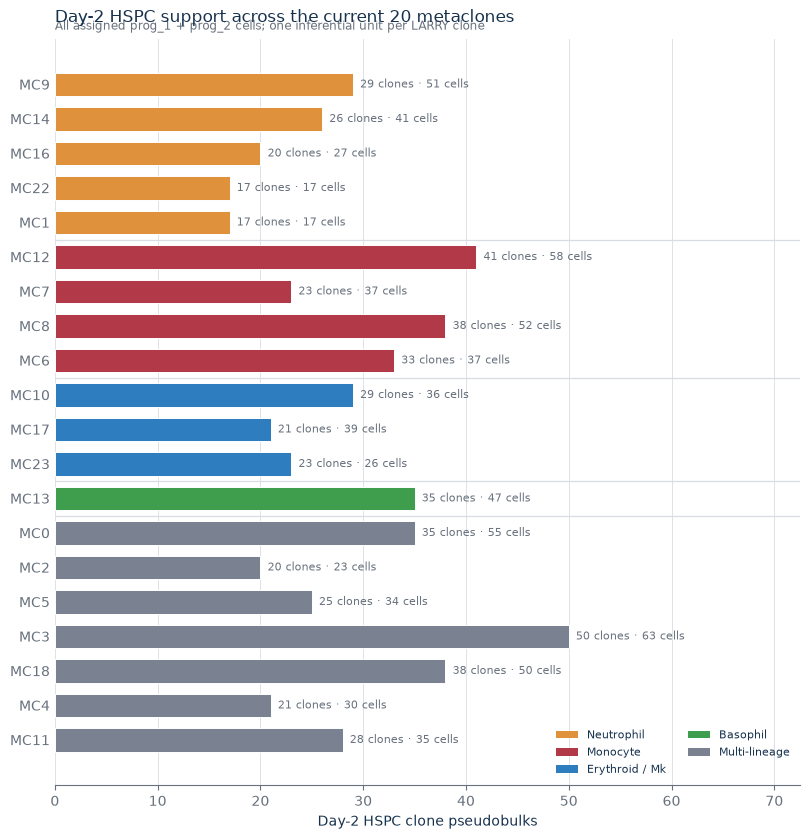

saved: analysis_workspace/analyses/weinreb_day2_hspc_metaclone_gene_programs_20260902/figures/weinreb_day2_hspc_01_metaclone_support.svg | analysis_workspace/analyses/weinreb_day2_hspc_metaclone_gene_programs_20260902/figures/weinreb_day2_hspc_01_metaclone_support.png


In [5]:
# PLOT_CELL_INLINE_V1
plot_stem = "weinreb_day2_hspc_01_metaclone_support"
plot_data = hspc_support.set_index("metaclone").reindex(MC_ORDER).reset_index()
plot_data["bar_color"] = plot_data.lineage_bias.map(FAMILY_COLORS)

fig, ax = plt.subplots(figsize=(8.2, 8.5))
y = np.arange(len(plot_data))
ax.barh(
    y, plot_data.n_clones.to_numpy(), height=0.68,
    color=plot_data.bar_color.to_list(), edgecolor=WHITE, linewidth=0.7
)
for position, row in plot_data.iterrows():
    ax.text(
        float(row.n_clones) + 0.7, position,
        f"{int(row.n_clones)} clones · {int(row.n_cells)} cells",
        va="center", ha="left", fontsize=8.1, color=GREY
    )
boundaries = np.cumsum([len(FAMILY_GROUPS[name]) for name in FAMILY_ORDER])[:-1]
for boundary in boundaries:
    ax.axhline(boundary - 0.5, color=LIGHT_GREY, linewidth=0.9)
ax.set_yticks(y, [f"MC{mc}" for mc in plot_data.metaclone])
ax.invert_yaxis()
ax.set_xlim(0, float(plot_data.n_clones.max()) * 1.45)
ax.set_xlabel("Day-2 HSPC clone pseudobulks")
ax.set_title("Day-2 HSPC support across the current 20 metaclones", loc="left", pad=12)
ax.text(
    0, 1.012, "All assigned prog_1 + prog_2 cells; one inferential unit per LARRY clone",
    transform=ax.transAxes, fontsize=8.6, color=GREY
)
ax.spines[["top", "right", "left"]].set_visible(False)
ax.tick_params(axis="y", length=0)
ax.grid(axis="x", color=LIGHT_GREY, linewidth=0.6)
ax.set_axisbelow(True)
legend_handles = [Patch(facecolor=FAMILY_COLORS[name], label=name) for name in FAMILY_ORDER]
ax.legend(handles=legend_handles, frameon=False, fontsize=8, ncol=2, loc="lower right")
fig.tight_layout()
svg = FIGDIR / f"{plot_stem}.svg"
png = FIGDIR / f"{plot_stem}.png"
fig.savefig(svg, bbox_inches="tight")
fig.savefig(png, dpi=300, bbox_inches="tight")
display(fig)
print("saved:", svg.relative_to(PROJECT_ROOT), "|", png.relative_to(PROJECT_ROOT))
plt.close(fig)

### Clone pseudobulks and library adjustment

Recovered cell counts are summed once per LARRY clone across both HSPC
source labels. Genes are filtered without group labels: at least 10 total
recovered counts and detection in at least five clone pseudobulks. Day-2
library fractions are represented by the largest full-rank set of centered,
standardized fraction covariates; the same covariates are used in the
20-metaclone and five-family models. Source `prog_1`/`prog_2` fractions are
diagnostic only and never enter a model.

In [6]:
pseudobulk_rows = {}
metadata_rows = []
day2_libraries = sorted(hspc_cells.Library.unique())
for clone, clone_cells in hspc_cells.groupby("LARRY_ID", observed=True):
    assert clone_cells.metaclone.nunique() == 1
    mc = int(clone_cells.metaclone.iloc[0])
    indices = POS.loc[clone_cells.index].to_numpy()
    pseudobulk_rows[str(clone)] = np.asarray(COUNTS[indices].sum(axis=0)).ravel().astype(np.int64)
    library_counts = clone_cells.Library.value_counts()
    label_counts = clone_cells.cell_type.value_counts()
    record = {
        "sample": str(clone), "clone": str(clone), "metaclone": mc,
        "mc_group": f"MC{mc}", "lineage_bias": MC_TO_FAMILY[mc],
        "lineage_bias_key": MC_TO_FAMILY_KEY[mc], "n_cells": int(len(clone_cells)),
        "n_prog_1_cells": int(label_counts.get("prog_1", 0)),
        "n_prog_2_cells": int(label_counts.get("prog_2", 0)),
    }
    for library in day2_libraries:
        record[f"libfrac__{safe_name(library)}"] = float(
            library_counts.get(library, 0) / len(clone_cells)
        )
    metadata_rows.append(record)

pseudobulk_counts = pd.DataFrame(pseudobulk_rows).T
pseudobulk_counts.columns = A.var_names.astype(str)
pseudobulk_counts.index.name = "sample"
pseudobulk_metadata = pd.DataFrame(metadata_rows).set_index("sample").loc[pseudobulk_counts.index]
pseudobulk_metadata["mc_group"] = pd.Categorical(
    pseudobulk_metadata.mc_group,
    categories=[f"MC{mc}" for mc in MC_ORDER], ordered=True
)
pseudobulk_metadata["lineage_bias_key"] = pd.Categorical(
    pseudobulk_metadata.lineage_bias_key,
    categories=FAMILY_KEY_ORDER, ordered=True
)
assert len(pseudobulk_counts) == len(pseudobulk_metadata) == 569
assert (pseudobulk_counts.sum(axis=1) > 0).all()
assert not pseudobulk_counts.index.duplicated().any()

libfrac_columns = [column for column in pseudobulk_metadata if column.startswith("libfrac__")]
reference_library_fraction = max(
    libfrac_columns,
    key=lambda column: (
        (pseudobulk_metadata.groupby("mc_group", observed=True)[column].mean() > 0).sum(),
        pseudobulk_metadata[column].mean(),
    )
)
candidate_library_columns = [
    column for column in libfrac_columns
    if column != reference_library_fraction and pseudobulk_metadata[column].std(ddof=0) > 1e-12
]
mc_dummies = pd.get_dummies(pseudobulk_metadata.mc_group, drop_first=True, dtype=float)
rank_matrix = np.column_stack([np.ones(len(pseudobulk_metadata)), mc_dummies.to_numpy(float)])
library_covariates = []
rank_dropped_library_columns = []
for column in candidate_library_columns:
    z = (
        (pseudobulk_metadata[column] - pseudobulk_metadata[column].mean())
        / pseudobulk_metadata[column].std(ddof=0)
    )
    trial = np.column_stack([rank_matrix, z.to_numpy(float)])
    if np.linalg.matrix_rank(trial) > np.linalg.matrix_rank(rank_matrix):
        name = column + "__z"
        pseudobulk_metadata[name] = z
        library_covariates.append(name)
        rank_matrix = trial
    else:
        rank_dropped_library_columns.append(column)

detected_clones = (pseudobulk_counts > 0).sum(axis=0)
total_counts = pseudobulk_counts.sum(axis=0)
keep_gene = (detected_clones >= 5) & (total_counts >= 10)
filtered_counts = pseudobulk_counts.loc[:, keep_gene].copy()
gene_filter = pd.DataFrame({
    "gene": pseudobulk_counts.columns, "detected_clones": detected_clones.to_numpy(),
    "total_recovered_counts": total_counts.to_numpy(), "retained": keep_gene.to_numpy()
})
gene_filter.to_csv(TABLEDIR / "group_blind_gene_filter.csv", index=False)

metadata_export = pseudobulk_metadata.copy()
metadata_export.index.name = "sample"
assert "population" not in metadata_export.columns
metadata_export.reset_index().to_csv(TABLEDIR / "day2_hspc_clone_pseudobulk_metadata.csv", index=False)
library_design_audit = pd.DataFrame([
    ["day2_libraries", "|".join(day2_libraries)],
    ["reference_fraction", reference_library_fraction],
    ["library_covariates", "|".join(library_covariates)],
    ["rank_dropped_fractions", "|".join(rank_dropped_library_columns)],
    ["n_library_covariates", len(library_covariates)],
    ["genes_before_filter", pseudobulk_counts.shape[1]],
    ["genes_after_group_blind_filter", filtered_counts.shape[1]],
], columns=["check", "value"])
library_design_audit.to_csv(TABLEDIR / "library_design_and_gene_filter_audit.csv", index=False)
display(library_design_audit)

,check,value
0,day2_libraries,LK_d2|LSK_d2_1|LSK_d2_2|LSK_d2_3|d2_1|d2_2|d2_3
1,reference_fraction,libfrac__LSK_d2_2
2,library_covariates,libfrac__LK_d2__z|libfrac__LSK_d2_1__z|libfrac...
3,rank_dropped_fractions,
4,n_library_covariates,6
5,genes_before_filter,25289
6,genes_after_group_blind_filter,9777


## Results

### Gene-level negative-binomial models

Two full-rank PyDESeq2 models use identical clone pseudobulks and the same
library covariates: one has a 20-level metaclone coefficient and one has a
five-level lineage-bias coefficient. One-versus-rest contrasts use an
equal-level comparator rather than weighting the comparator by clone count.
Pairwise within-family contrasts are all returned, with a separate
shared-library support flag for interpretation.

In [7]:
from pydeseq2.dds import DeseqDataSet
from pydeseq2.ds import DeseqStats
from pydeseq2.default_inference import DefaultInference

inference = DefaultInference(n_cpus=1)

def fit_deseq_model(factor, label):
    metadata = pseudobulk_metadata.copy()
    design = "~ " + " + ".join(library_covariates + [factor])
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always")
        dds = DeseqDataSet(
            counts=filtered_counts.astype(int), metadata=metadata,
            design=design, inference=inference, quiet=True, refit_cooks=False
        )
        design_matrix = np.asarray(dds.obsm["design_matrix"], dtype=float)
        design_rank = int(np.linalg.matrix_rank(design_matrix))
        assert design_rank == design_matrix.shape[1]
        dds.deseq2()
    warning_text = sorted({str(item.message) for item in caught})
    summary = {
        "model": label, "factor": factor, "design": design,
        "n_clone_units": len(metadata), "n_genes": filtered_counts.shape[1],
        "design_rank": design_rank, "design_columns": design_matrix.shape[1],
        "condition_number": float(np.linalg.cond(design_matrix)),
        "warning_count": len(warning_text), "warnings": " | ".join(warning_text),
    }
    return dds, summary

dds_mc, mc_fit_summary = fit_deseq_model("mc_group", "20_metaclones")
dds_family, family_fit_summary = fit_deseq_model("lineage_bias_key", "5_lineage_bias_families")
fit_summary = pd.DataFrame([mc_fit_summary, family_fit_summary])
fit_summary.to_csv(TABLEDIR / "deseq_model_fit_summary.csv", index=False)
display(fit_summary)

,model,factor,design,n_clone_units,n_genes,design_rank,design_columns,condition_number,warning_count,warnings
0,20_metaclones,mc_group,~ libfrac__LK_d2__z + libfrac__LSK_d2_1__z + l...,569,9777,26,26,24.953458,0,
1,5_lineage_bias_families,lineage_bias_key,~ libfrac__LK_d2__z + libfrac__LSK_d2_1__z + l...,569,9777,11,11,6.812021,0,


In [8]:
mc_library_support = (hspc_cells.groupby(["metaclone", "Library"], observed=True)
                      .LARRY_ID.nunique().unstack(fill_value=0)
                      .reindex(index=MC_ORDER, columns=day2_libraries, fill_value=0))
within_pair_rows = []
for family, members in FAMILY_GROUPS.items():
    if len(members) < 2:
        continue
    for target_mc, reference_mc in itertools.combinations(members, 2):
        shared = [
            library for library in day2_libraries
            if int(mc_library_support.loc[target_mc, library]) >= 3
            and int(mc_library_support.loc[reference_mc, library]) >= 3
        ]
        within_pair_rows.append({
            "lineage_bias": family,
            "target_mc": target_mc,
            "reference_mc": reference_mc,
            "target_clones": int(hspc_support.set_index("metaclone").loc[target_mc, "n_clones"]),
            "reference_clones": int(hspc_support.set_index("metaclone").loc[reference_mc, "n_clones"]),
            "qualifying_shared_libraries_ge3_per_arm": "|".join(shared),
            "n_qualifying_shared_libraries": len(shared),
            "support_gate": bool(shared),
        })
within_pair_support = pd.DataFrame(within_pair_rows)
assert len(within_pair_support) == 40
within_pair_support.to_csv(TABLEDIR / "within_lineage_pair_support.csv", index=False)

def condition_mean_vector(dds, factor, levels):
    # Mean adjusted design row for explicitly named categorical levels.
    rows = [
        np.asarray(dds.cond(**{factor: level}), dtype=float)
        for level in levels
    ]
    return np.mean(np.vstack(rows), axis=0)

def target_minus_reference_vector(dds, factor, targets, references):
    # Explicit target-minus-reference contrast; never rely on argument order.
    vector = (
        condition_mean_vector(dds, factor, targets)
        - condition_mean_vector(dds, factor, references)
    )
    if len(targets) == 1 and len(references) == 1:
        # FormulaicContrasts.contrast(column, baseline, group_to_compare)
        # returns group_to_compare - baseline.  This independent equality
        # assertion prevents the previously observed sign inversion.
        formulaic_vector = np.asarray(
            dds.contrast(factor, references[0], targets[0]), dtype=float
        )
        assert np.allclose(vector, formulaic_vector, atol=1e-12)
    return vector

contrast_specs = []
for mc in MC_ORDER:
    target = f"MC{mc}"
    comparators = [f"MC{other}" for other in MC_ORDER if other != mc]
    contrast_specs.append({
        "model": "metaclone", "tier": "all_metaclones_ovr",
        "contrast_id": f"MC{mc}_vs_equal_mean_other_19",
        "contrast_label": f"MC{mc} vs equal-MC mean of other 19",
        "target": target, "reference": "equal_mean_other_19",
        "lineage_bias": MC_TO_FAMILY[mc], "target_mc": mc,
        "reference_mc": np.nan, "support_gate": True,
        "target_levels": [target], "reference_levels": comparators,
        "vector": target_minus_reference_vector(
            dds_mc, "mc_group", [target], comparators
        ),
    })

for family_key in FAMILY_KEY_ORDER:
    comparators = [key for key in FAMILY_KEY_ORDER if key != family_key]
    contrast_specs.append({
        "model": "family", "tier": "lineage_bias_ovr",
        "contrast_id": f"{family_key}_vs_equal_mean_other_4",
        "contrast_label": f"{FAMILY_DISPLAY[family_key]} vs equal-family mean of other 4",
        "target": family_key, "reference": "equal_mean_other_4",
        "lineage_bias": FAMILY_DISPLAY[family_key], "target_mc": np.nan,
        "reference_mc": np.nan, "support_gate": True,
        "target_levels": [family_key], "reference_levels": comparators,
        "vector": target_minus_reference_vector(
            dds_family, "lineage_bias_key", [family_key], comparators
        ),
    })

for target_family, reference_family in itertools.combinations(FAMILY_KEY_ORDER, 2):
    contrast_specs.append({
        "model": "family", "tier": "lineage_bias_pairwise",
        "contrast_id": f"{target_family}_vs_{reference_family}",
        "contrast_label": f"{FAMILY_DISPLAY[target_family]} vs {FAMILY_DISPLAY[reference_family]}",
        "target": target_family, "reference": reference_family,
        "lineage_bias": "between_families", "target_mc": np.nan,
        "reference_mc": np.nan, "support_gate": True,
        "target_levels": [target_family], "reference_levels": [reference_family],
        "vector": target_minus_reference_vector(
            dds_family, "lineage_bias_key", [target_family], [reference_family]
        ),
    })

for family, members in FAMILY_GROUPS.items():
    if len(members) < 2:
        continue
    for mc in members:
        target = f"MC{mc}"
        comparators = [f"MC{other}" for other in members if other != mc]
        contrast_specs.append({
            "model": "metaclone", "tier": "within_lineage_ovr",
            "contrast_id": f"MC{mc}_vs_equal_mean_{safe_name(family)}_peers",
            "contrast_label": f"MC{mc} vs equal-MC mean of {family} peers",
            "target": target, "reference": f"equal_mean_{safe_name(family)}_peers",
            "lineage_bias": family, "target_mc": mc, "reference_mc": np.nan,
            "support_gate": True,
            "target_levels": [target], "reference_levels": comparators,
            "vector": target_minus_reference_vector(
                dds_mc, "mc_group", [target], comparators
            ),
        })

    family_support_pairs = within_pair_support[
        within_pair_support.lineage_bias == family
    ].set_index(["target_mc", "reference_mc"])
    for target_mc, reference_mc in itertools.combinations(members, 2):
        support_row = family_support_pairs.loc[(target_mc, reference_mc)]
        contrast_specs.append({
            "model": "metaclone", "tier": "within_lineage_pairwise",
            "contrast_id": f"MC{target_mc}_vs_MC{reference_mc}",
            "contrast_label": f"MC{target_mc} vs MC{reference_mc} within {family}",
            "target": f"MC{target_mc}", "reference": f"MC{reference_mc}",
            "lineage_bias": family, "target_mc": target_mc,
            "reference_mc": reference_mc,
            "support_gate": bool(support_row.support_gate),
            "target_levels": [f"MC{target_mc}"],
            "reference_levels": [f"MC{reference_mc}"],
            "vector": target_minus_reference_vector(
                dds_mc, "mc_group", [f"MC{target_mc}"], [f"MC{reference_mc}"]
            ),
        })

assert len(contrast_specs) == 94
orientation_rows = []
for spec in contrast_specs:
    dds = dds_mc if spec["model"] == "metaclone" else dds_family
    factor = "mc_group" if spec["model"] == "metaclone" else "lineage_bias_key"
    expected = target_minus_reference_vector(
        dds, factor, spec["target_levels"], spec["reference_levels"]
    )
    max_error = float(np.max(np.abs(np.asarray(spec["vector"]) - expected)))
    orientation_rows.append({
        "contrast_id": spec["contrast_id"],
        "model": spec["model"],
        "target_levels": "|".join(spec["target_levels"]),
        "reference_levels": "|".join(spec["reference_levels"]),
        "max_vector_error": max_error,
        "target_minus_reference_verified": max_error < 1e-12,
    })
orientation_audit = pd.DataFrame(orientation_rows)
assert orientation_audit.target_minus_reference_verified.all()
orientation_audit.to_csv(
    TABLEDIR / "contrast_orientation_audit.csv", index=False
)

spec_table = pd.DataFrame([
    {
        key: ("|".join(value) if key in {"target_levels", "reference_levels"} else value)
        for key, value in spec.items() if key != "vector"
    }
    for spec in contrast_specs
])
spec_table.to_csv(TABLEDIR / "contrast_registry.csv", index=False)
display(spec_table.groupby("tier", observed=True).agg(
    n_contrasts=("contrast_id", "nunique"),
    n_supported=("support_gate", "sum")
).reset_index())

,tier,n_contrasts,n_supported
0,all_metaclones_ovr,20,20
1,lineage_bias_ovr,5,5
2,lineage_bias_pairwise,10,10
3,within_lineage_ovr,19,19
4,within_lineage_pairwise,40,36


In [9]:
def extract_deseq_result(dds, vector, spec):
    stats = DeseqStats(
        dds, contrast=np.asarray(vector, dtype=float), inference=inference,
        quiet=True, cooks_filter=False, independent_filter=False
    )
    stats.summary()
    result = stats.results_df.reset_index().rename(columns={"index": "gene"})
    if "gene" not in result.columns:
        result = result.rename(columns={result.columns[0]: "gene"})
    result["pvalue"] = result.pvalue.fillna(1.0)
    result["padj"] = result.padj.fillna(1.0)
    for key in [
        "model", "tier", "contrast_id", "contrast_label", "target",
        "reference", "lineage_bias", "target_mc", "reference_mc", "support_gate"
    ]:
        result[key] = spec[key]
    return result

deseq_parts = []
for number, spec in enumerate(contrast_specs, start=1):
    dds = dds_mc if spec["model"] == "metaclone" else dds_family
    deseq_parts.append(extract_deseq_result(dds, spec["vector"], spec))
    if number % 10 == 0 or number == len(contrast_specs):
        print(f"completed {number}/{len(contrast_specs)} DESeq2 contrasts")

deseq_results = pd.concat(deseq_parts, ignore_index=True)
deseq_results["contrast_fdr"] = deseq_results.padj
deseq_results["tier_fdr"] = (
    deseq_results.groupby("tier", observed=True, group_keys=False).pvalue
    .transform(bh_adjust)
)
deseq_results["effect_ge_0_5"] = deseq_results.log2FoldChange.abs() >= 0.5
deseq_results.to_csv(
    TABLEDIR / "gene_level_deseq2_contrasts.csv.gz", index=False, compression="gzip"
)

deseq_summary = (deseq_results.groupby("tier", observed=True)
                 .agg(n_contrasts=("contrast_id", "nunique"),
                      n_gene_tests=("gene", "size"),
                      n_contrast_fdr_lt_0_05=("contrast_fdr", lambda x: int((x < 0.05).sum())),
                      n_tier_fdr_lt_0_05=("tier_fdr", lambda x: int((x < 0.05).sum())),
                      n_tier_fdr_and_abs_lfc_ge_0_5=(
                          "tier_fdr", lambda x: 0
                      ))
                 .reset_index())
effect_counts = (deseq_results.assign(
    pass_both=(deseq_results.tier_fdr < 0.05) & deseq_results.effect_ge_0_5
).groupby("tier", observed=True).pass_both.sum())
deseq_summary["n_tier_fdr_and_abs_lfc_ge_0_5"] = (
    deseq_summary.tier.map(effect_counts).fillna(0).astype(int)
)
deseq_summary.to_csv(TABLEDIR / "gene_level_deseq2_tier_summary.csv", index=False)

within_pair_gene_summary = (deseq_results[
    deseq_results.tier == "within_lineage_pairwise"
].groupby([
    "contrast_id", "contrast_label", "lineage_bias", "target_mc",
    "reference_mc", "support_gate"
], observed=True)
 .agg(n_genes=("gene", "size"),
      n_contrast_fdr_lt_0_05=("contrast_fdr", lambda x: int((x < 0.05).sum())),
      n_tier_fdr_lt_0_05=("tier_fdr", lambda x: int((x < 0.05).sum())),
      min_tier_fdr=("tier_fdr", "min"))
 .reset_index())
within_pair_gene_summary.to_csv(
    TABLEDIR / "within_lineage_pairwise_gene_summary.csv", index=False
)
display(deseq_summary)
display(within_pair_gene_summary)

completed 10/94 DESeq2 contrasts


completed 20/94 DESeq2 contrasts


completed 30/94 DESeq2 contrasts


completed 40/94 DESeq2 contrasts


completed 50/94 DESeq2 contrasts


completed 60/94 DESeq2 contrasts


... (2 outputs left out)

completed 90/94 DESeq2 contrasts


completed 94/94 DESeq2 contrasts


,tier,n_contrasts,n_gene_tests,n_contrast_fdr_lt_0_05,n_tier_fdr_lt_0_05,n_tier_fdr_and_abs_lfc_ge_0_5
0,all_metaclones_ovr,20,195540,181,120,116
1,lineage_bias_ovr,5,48885,63,48,37
2,lineage_bias_pairwise,10,97770,158,132,108
3,within_lineage_ovr,19,185763,37,15,14
4,within_lineage_pairwise,40,391080,85,28,28


,contrast_id,contrast_label,lineage_bias,target_mc,reference_mc,support_gate,n_genes,n_contrast_fdr_lt_0_05,n_tier_fdr_lt_0_05,min_tier_fdr
0,MC0_vs_MC11,MC0 vs MC11 within Multi-lineage,Multi-lineage,0.0,11.0,True,9777,20,5,0.000205
1,MC0_vs_MC18,MC0 vs MC18 within Multi-lineage,Multi-lineage,0.0,18.0,True,9777,1,1,0.002180
2,MC0_vs_MC2,MC0 vs MC2 within Multi-lineage,Multi-lineage,0.0,2.0,False,9777,0,0,0.121862
3,MC0_vs_MC3,MC0 vs MC3 within Multi-lineage,Multi-lineage,0.0,3.0,True,9777,26,9,0.000620
4,MC0_vs_MC4,MC0 vs MC4 within Multi-lineage,Multi-lineage,0.0,4.0,True,9777,0,0,0.121791
5,MC0_vs_MC5,MC0 vs MC5 within Multi-lineage,Multi-lineage,0.0,5.0,True,9777,0,0,0.525069
6,MC10_vs_MC17,MC10 vs MC17 within Erythroid / Mk,Erythroid / Mk,10.0,17.0,True,9777,1,1,0.001090
7,MC10_vs_MC23,MC10 vs MC23 within Erythroid / Mk,Erythroid / Mk,10.0,23.0,True,9777,1,1,0.036958
8,MC12_vs_MC6,MC12 vs MC6 within Monocyte,Monocyte,12.0,6.0,True,9777,1,1,0.048580
9,MC12_vs_MC7,MC12 vs MC7 within Monocyte,Monocyte,12.0,7.0,True,9777,0,0,0.999999


### Fixed Hallmark program scores

The complete 50-program Hallmark 2020 universe is copied byte-for-byte into
this research analysis as a reproducible checkpoint. Mouse symbols and Hallmark
symbols are matched case-insensitively by uppercase symbol; mapping coverage
is audited. No program is selected from the observed Day-2 contrasts before
testing.

For each clone, DESeq2-normalized counts are log2 transformed, each gene is
z-scored across clones, and each program is the unweighted mean of its mapped
gene z-scores. Program scores are then standardized across clones. HC3-robust
linear models use the same design matrices and contrasts as the gene-level
models.

In [10]:
hallmark_source_hash = sha256(HALLMARK_SOURCE)
assert hallmark_source_hash == EXPECTED_HALLMARK_SHA256
if (not HALLMARK_LOCAL.exists()) or sha256(HALLMARK_LOCAL) != hallmark_source_hash:
    shutil.copy2(HALLMARK_SOURCE, HALLMARK_LOCAL)
assert sha256(HALLMARK_LOCAL) == hallmark_source_hash

hallmark_sets = {}
with open(HALLMARK_LOCAL) as handle:
    for line in handle:
        fields = line.rstrip("\n").split("\t")
        term = fields[0]
        genes = [gene.upper() for gene in fields[2:] if gene]
        hallmark_sets[term] = sorted(set(genes))
assert len(hallmark_sets) == 50

normalized_counts = np.asarray(dds_mc.layers["normed_counts"], dtype=float)
assert normalized_counts.shape == filtered_counts.shape
log_normalized = np.log2(normalized_counts + 1.0)
gene_mean = log_normalized.mean(axis=0)
gene_sd = log_normalized.std(axis=0, ddof=1)
valid_sd = gene_sd > 1e-12
gene_z = np.zeros_like(log_normalized, dtype=float)
gene_z[:, valid_sd] = (
    (log_normalized[:, valid_sd] - gene_mean[valid_sd]) / gene_sd[valid_sd]
)

gene_names = np.asarray(filtered_counts.columns.astype(str))
upper_to_indices = {}
for index, gene in enumerate(gene_names):
    upper_to_indices.setdefault(gene.upper(), []).append(index)

program_scores_raw = {}
mapping_rows = []
for term, requested_genes in hallmark_sets.items():
    mapped_indices = sorted({
        index for gene in requested_genes for index in upper_to_indices.get(gene, [])
    })
    mapped_names = gene_names[mapped_indices].tolist()
    mapping_rows.append({
        "program": term, "n_library_genes": len(requested_genes),
        "n_mapped_filtered_genes": len(mapped_indices),
        "mapped_fraction": len(mapped_indices) / len(requested_genes),
        "mapped_genes": "|".join(mapped_names),
    })
    assert len(mapped_indices) >= 10
    program_scores_raw[term] = gene_z[:, mapped_indices].mean(axis=1)

program_mapping = pd.DataFrame(mapping_rows).sort_values("program")
program_mapping.to_csv(TABLEDIR / "hallmark_gene_mapping_audit.csv", index=False)
program_scores = pd.DataFrame(program_scores_raw, index=pseudobulk_metadata.index)
program_scores = (
    (program_scores - program_scores.mean(axis=0))
    / program_scores.std(axis=0, ddof=1)
)
assert np.isfinite(program_scores.to_numpy()).all()
program_score_export = pseudobulk_metadata[[
    "clone", "metaclone", "mc_group", "lineage_bias", "lineage_bias_key", "n_cells"
]].join(program_scores)
assert "population" not in program_score_export.columns
program_score_export.to_csv(
    TABLEDIR / "clone_hallmark_program_scores.csv.gz", compression="gzip"
)

resource_audit = pd.DataFrame([
    ["source_path", str(HALLMARK_SOURCE)],
    ["local_checkpoint", str(HALLMARK_LOCAL)],
    ["sha256", hallmark_source_hash],
    ["programs", len(hallmark_sets)],
    ["minimum_mapped_genes", int(program_mapping.n_mapped_filtered_genes.min())],
    ["median_mapped_genes", float(program_mapping.n_mapped_filtered_genes.median())],
    ["maximum_mapped_genes", int(program_mapping.n_mapped_filtered_genes.max())],
], columns=["check", "value"])
resource_audit.to_csv(REPORTDIR / "hallmark_resource_audit.csv", index=False)
display(resource_audit)
display(program_mapping[[
    "program", "n_library_genes", "n_mapped_filtered_genes", "mapped_fraction"
]])

,check,value
0,source_path,/path/to/ChronoClone/Claud...
1,local_checkpoint,/path/to/ChronoClone/research...
2,sha256,4275592957a1587652092bb398cf77216fde5b8daa2aed...
3,programs,50
4,minimum_mapped_genes,12
5,median_mapped_genes,96.0
6,maximum_mapped_genes,189


,program,n_library_genes,n_mapped_filtered_genes,mapped_fraction
11,Adipogenesis,200,150,0.750000
45,Allograft Rejection,200,106,0.530000
14,Androgen Response,100,71,0.710000
39,Angiogenesis,36,16,0.444444
19,Apical Junction,200,95,0.475000
20,Apical Surface,44,18,0.409091
9,Apoptosis,161,111,0.689441
43,Bile Acid Metabolism,112,58,0.517857
2,Cholesterol Homeostasis,74,51,0.689189
41,Coagulation,138,53,0.384058


In [11]:
mc_design = dds_mc.obsm["design_matrix"].copy()
family_design = dds_family.obsm["design_matrix"].copy()
assert mc_design.index.tolist() == program_scores.index.tolist()
assert family_design.index.tolist() == program_scores.index.tolist()
assert all(column in mc_design.columns for column in library_covariates)
assert all(column in family_design.columns for column in library_covariates)

program_fits_mc = {
    program: sm.OLS(program_scores[program].to_numpy(), mc_design.to_numpy(float)).fit(cov_type="HC3")
    for program in program_scores.columns
}
program_fits_family = {
    program: sm.OLS(program_scores[program].to_numpy(), family_design.to_numpy(float)).fit(cov_type="HC3")
    for program in program_scores.columns
}

program_test_rows = []
for spec in contrast_specs:
    fits = program_fits_mc if spec["model"] == "metaclone" else program_fits_family
    for program, fit_result in fits.items():
        test = fit_result.t_test(np.asarray(spec["vector"], dtype=float))
        program_test_rows.append({
            "program": program,
            "program_label": clean_program_name(program),
            "model": spec["model"], "tier": spec["tier"],
            "contrast_id": spec["contrast_id"],
            "contrast_label": spec["contrast_label"],
            "target": spec["target"], "reference": spec["reference"],
            "lineage_bias": spec["lineage_bias"],
            "target_mc": spec["target_mc"], "reference_mc": spec["reference_mc"],
            "support_gate": spec["support_gate"],
            "effect_sd": float(np.asarray(test.effect).squeeze()),
            "standard_error": float(np.asarray(test.sd).squeeze()),
            "t_stat": float(np.asarray(test.tvalue).squeeze()),
            "pvalue": float(np.asarray(test.pvalue).squeeze()),
        })
program_tests = pd.DataFrame(program_test_rows)
program_tests["contrast_fdr"] = (
    program_tests.groupby("contrast_id", observed=True, group_keys=False).pvalue
    .transform(bh_adjust)
)
program_tests["tier_fdr"] = (
    program_tests.groupby("tier", observed=True, group_keys=False).pvalue
    .transform(bh_adjust)
)

program_orientation_rows = []
for spec in contrast_specs:
    dds = dds_mc if spec["model"] == "metaclone" else dds_family
    factor = "mc_group" if spec["model"] == "metaclone" else "lineage_bias_key"
    fits = program_fits_mc if spec["model"] == "metaclone" else program_fits_family
    target_row = condition_mean_vector(dds, factor, spec["target_levels"])
    reference_row = condition_mean_vector(dds, factor, spec["reference_levels"])
    observed = program_tests.loc[
        program_tests.contrast_id == spec["contrast_id"],
        ["program", "effect_sd"],
    ].set_index("program").effect_sd
    expected = pd.Series({
        program: float(
            target_row @ np.asarray(fit_result.params, dtype=float)
            - reference_row @ np.asarray(fit_result.params, dtype=float)
        )
        for program, fit_result in fits.items()
    })
    max_error = float((observed.reindex(expected.index) - expected).abs().max())
    program_orientation_rows.append({
        "contrast_id": spec["contrast_id"],
        "target_minus_reference_max_abs_error": max_error,
        "passed": max_error < 1e-10,
    })
program_orientation_audit = pd.DataFrame(program_orientation_rows)
assert program_orientation_audit.passed.all()
program_orientation_audit.to_csv(
    TABLEDIR / "program_effect_orientation_audit.csv", index=False
)
program_tests.to_csv(TABLEDIR / "hallmark_program_contrasts.csv", index=False)

program_tier_summary = (program_tests.groupby("tier", observed=True)
                        .agg(n_contrasts=("contrast_id", "nunique"),
                             n_program_tests=("program", "size"),
                             n_contrast_fdr_lt_0_05=(
                                 "contrast_fdr", lambda x: int((x < 0.05).sum())
                             ),
                             n_tier_fdr_lt_0_05=(
                                 "tier_fdr", lambda x: int((x < 0.05).sum())
                             ))
                        .reset_index())
program_tier_summary.to_csv(TABLEDIR / "hallmark_program_tier_summary.csv", index=False)

def adjusted_program_means(design, fits, factor_values, factor_name):
    coefficient_matrix = np.column_stack([fits[program].params for program in program_scores.columns])
    rows = []
    for value in factor_values:
        sample_index = pseudobulk_metadata.index[
            pseudobulk_metadata[factor_name].astype(str) == str(value)
        ][0]
        design_row = design.loc[sample_index].copy()
        design_row.loc[library_covariates] = 0.0
        estimates = design_row.to_numpy(float) @ coefficient_matrix
        record = {"group": str(value)}
        record.update(dict(zip(program_scores.columns, estimates)))
        rows.append(record)
    return pd.DataFrame(rows)

adjusted_mc_program_means = adjusted_program_means(
    mc_design, program_fits_mc, [f"MC{mc}" for mc in MC_ORDER], "mc_group"
)
adjusted_mc_program_means["metaclone"] = (
    adjusted_mc_program_means.group.str.replace("MC", "", regex=False).astype(int)
)
adjusted_mc_program_means["lineage_bias"] = (
    adjusted_mc_program_means.metaclone.map(MC_TO_FAMILY)
)
adjusted_family_program_means = adjusted_program_means(
    family_design, program_fits_family, FAMILY_KEY_ORDER, "lineage_bias_key"
)
adjusted_family_program_means["lineage_bias"] = (
    adjusted_family_program_means.group.map(FAMILY_DISPLAY)
)
adjusted_mc_program_means.to_csv(TABLEDIR / "adjusted_program_means_by_metaclone.csv", index=False)
adjusted_family_program_means.to_csv(
    TABLEDIR / "adjusted_program_means_by_lineage_bias.csv", index=False
)
display(program_tier_summary)

,tier,n_contrasts,n_program_tests,n_contrast_fdr_lt_0_05,n_tier_fdr_lt_0_05
0,all_metaclones_ovr,20,1000,140,133
1,lineage_bias_ovr,5,250,46,41
2,lineage_bias_pairwise,10,500,82,70
3,within_lineage_ovr,19,950,114,91
4,within_lineage_pairwise,40,2000,263,204


### Preranked Hallmark enrichment sensitivity

The DESeq2 Wald statistic supplies a signed full-gene ranking for each
one-versus-rest contrast. GSEA uses the same fixed Hallmark checkpoint,
1,000 permutations, and a deterministic seed. This is a directional
enrichment sensitivity, not an independent validation dataset. GSEA NES is
interpreted within each ranked contrast; cross-contrast visual comparisons
use the directly comparable adjusted clone program scores instead.

In [12]:
gsea_tiers = {"all_metaclones_ovr", "lineage_bias_ovr", "within_lineage_ovr"}
gsea_parts = []
gsea_contrasts = deseq_results[deseq_results.tier.isin(gsea_tiers)].contrast_id.unique()
for number, contrast_id in enumerate(gsea_contrasts, start=1):
    ranked = deseq_results[
        deseq_results.contrast_id == contrast_id
    ][["gene", "stat"]].copy()
    ranked["gene_upper"] = ranked.gene.astype(str).str.upper()
    ranked["abs_stat"] = ranked.stat.abs().fillna(-np.inf)
    ranked = (ranked.sort_values(["abs_stat", "gene_upper"], ascending=[False, True])
              .drop_duplicates("gene_upper", keep="first"))
    ranked["rank_stat"] = ranked.stat.fillna(0.0)
    ranked = ranked.sort_values(
        ["rank_stat", "gene_upper"], ascending=[False, True]
    ).reset_index(drop=True)
    # Resolve exact ties deterministically at machine precision so GSEA
    # never inherits an arbitrary gene order or emits tie warnings.
    rank_values = ranked.rank_stat.to_numpy(float)
    for position in range(1, len(rank_values)):
        if rank_values[position] >= rank_values[position - 1]:
            rank_values[position] = np.nextafter(
                rank_values[position - 1], -np.inf
            )
    assert pd.Series(rank_values).is_unique
    assert np.all(np.diff(rank_values) < 0)
    rank_series = pd.Series(
        rank_values, index=ranked.gene_upper, name="wald_stat"
    )
    prerank = gp.prerank(
        rnk=rank_series, gene_sets=str(HALLMARK_LOCAL), min_size=10,
        max_size=500, permutation_num=1000, seed=20260902, threads=1,
        outdir=None, no_plot=True, verbose=False
    )
    terms = prerank.res2d.copy()
    source_row = deseq_results[deseq_results.contrast_id == contrast_id].iloc[0]
    for column in ["ES", "NES", "NOM p-val", "FDR q-val", "FWER p-val"]:
        terms[column] = pd.to_numeric(terms[column], errors="coerce")
    terms["contrast_id"] = contrast_id
    terms["contrast_label"] = source_row.contrast_label
    terms["tier"] = source_row.tier
    terms["target"] = source_row.target
    terms["reference"] = source_row.reference
    terms["lineage_bias"] = source_row.lineage_bias
    terms["target_mc"] = source_row.target_mc
    terms["reference_mc"] = source_row.reference_mc
    terms["support_gate"] = source_row.support_gate
    terms["gmt_sha256"] = hallmark_source_hash
    gsea_parts.append(terms)
    if number % 10 == 0 or number == len(gsea_contrasts):
        print(f"completed {number}/{len(gsea_contrasts)} preranked GSEA contrasts")

gsea_results = pd.concat(gsea_parts, ignore_index=True)
gsea_results["tier_fdr_from_nominal_p"] = (
    gsea_results.groupby("tier", observed=True, group_keys=False)["NOM p-val"]
    .transform(bh_adjust)
)
gsea_results.to_csv(
    TABLEDIR / "hallmark_preranked_gsea.csv.gz", index=False, compression="gzip"
)
gsea_summary = (gsea_results.groupby("tier", observed=True)
                .agg(n_contrasts=("contrast_id", "nunique"),
                     n_program_tests=("Term", "size"),
                     n_contrast_fdr_lt_0_25=(
                         "FDR q-val", lambda x: int((x < 0.25).sum())
                     ),
                     n_tier_fdr_lt_0_05=(
                         "tier_fdr_from_nominal_p", lambda x: int((x < 0.05).sum())
                     ))
                .reset_index())
gsea_summary.to_csv(TABLEDIR / "hallmark_preranked_gsea_summary.csv", index=False)
display(gsea_summary)

completed 10/44 preranked GSEA contrasts


completed 20/44 preranked GSEA contrasts


completed 30/44 preranked GSEA contrasts


completed 40/44 preranked GSEA contrasts


completed 44/44 preranked GSEA contrasts


,tier,n_contrasts,n_program_tests,n_contrast_fdr_lt_0_25,n_tier_fdr_lt_0_05
0,all_metaclones_ovr,20,1000,278,155
1,lineage_bias_ovr,5,250,102,51
2,within_lineage_ovr,19,950,265,151


### Program landscape across all metaclones

Heatmaps show library-adjusted Hallmark score means at the centered
library composition. Programs are ordered by their observed range only to
make the fixed 50-program universe legible; all program tests remain in
the accompanying tables. A dot marks a one-versus-rest program contrast
passing the prespecified tier-wide Benjamini-Hochberg FDR of 0.05.

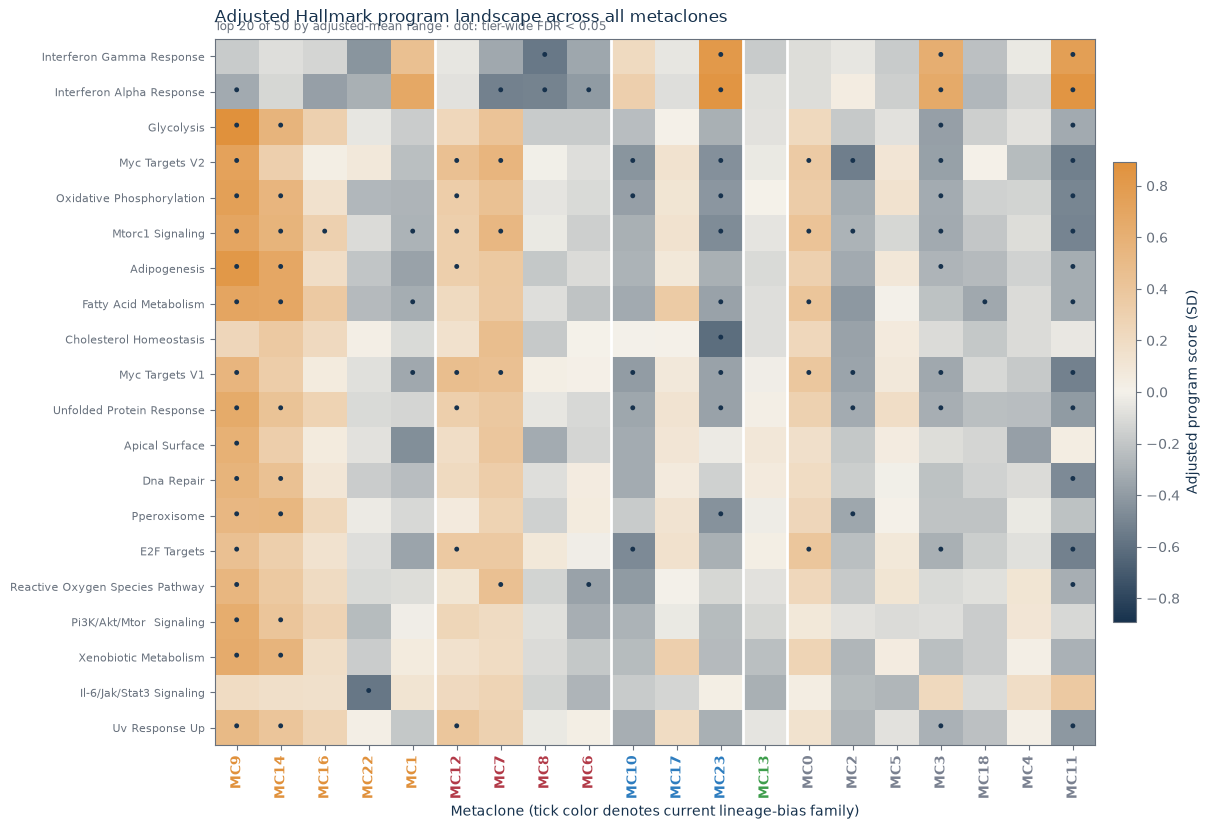

saved: analysis_workspace/analyses/weinreb_day2_hspc_metaclone_gene_programs_20260902/figures/weinreb_day2_hspc_02_all_metaclone_program_landscape.svg | analysis_workspace/analyses/weinreb_day2_hspc_metaclone_gene_programs_20260902/figures/weinreb_day2_hspc_02_all_metaclone_program_landscape.png


In [13]:
# PLOT_CELL_INLINE_V1
plot_stem = "weinreb_day2_hspc_02_all_metaclone_program_landscape"
plot_matrix_full = (adjusted_mc_program_means.set_index("metaclone")
                    .reindex(MC_ORDER)[list(program_scores.columns)])
plot_programs = (plot_matrix_full.max(axis=0) - plot_matrix_full.min(axis=0))
plot_programs = plot_programs.sort_values(ascending=False).head(20).index.tolist()
plot_matrix = plot_matrix_full[plot_programs].T
plot_long = (plot_matrix.rename_axis("program").reset_index()
             .melt(id_vars="program", var_name="metaclone", value_name="adjusted_score_sd"))
plot_long["lineage_bias"] = plot_long.metaclone.map(MC_TO_FAMILY)
plot_long.to_csv(TABLEDIR / f"{plot_stem}_plot_data.csv", index=False)
significant = program_tests[
    (program_tests.tier == "all_metaclones_ovr") &
    (program_tests.tier_fdr < 0.05)
][["program", "target_mc"]].copy()
significant["target_mc"] = significant.target_mc.astype(int)
significant_pairs = set(map(tuple, significant.to_numpy()))
limit = max(0.5, float(np.nanmax(np.abs(plot_matrix.to_numpy()))))

fig, ax = plt.subplots(figsize=(12.2, 8.4))
image_artist = ax.pcolormesh(
    np.arange(plot_matrix.shape[1] + 1),
    np.arange(plot_matrix.shape[0] + 1),
    plot_matrix.to_numpy(), cmap=PROGRAM_CMAP,
    vmin=-limit, vmax=limit, shading="flat",
)
for row_index, program in enumerate(plot_matrix.index):
    for column_index, metaclone in enumerate(plot_matrix.columns):
        if (program, int(metaclone)) in significant_pairs:
            ax.text(column_index + 0.5, row_index + 0.5, "•", ha="center", va="center",
                    color=INK, fontsize=10, fontweight="bold")
boundaries = np.cumsum([len(FAMILY_GROUPS[name]) for name in FAMILY_ORDER])[:-1]
for boundary in boundaries:
    ax.axvline(boundary, color=WHITE, linewidth=2.0)
ax.set_xticks(np.arange(len(MC_ORDER)) + 0.5, [f"MC{mc}" for mc in MC_ORDER], rotation=90)
for tick, metaclone in zip(ax.get_xticklabels(), MC_ORDER):
    tick.set_color(FAMILY_COLORS[MC_TO_FAMILY[metaclone]])
    tick.set_fontweight("bold")
ax.set_yticks(
    np.arange(len(plot_programs)) + 0.5,
    [clean_program_name(program) for program in plot_programs], fontsize=8.2
)
ax.set_xlim(0, len(MC_ORDER))
ax.set_ylim(0, len(plot_programs))
ax.invert_yaxis()
ax.set_xlabel("Metaclone (tick color denotes current lineage-bias family)")
ax.set_title("Adjusted Hallmark program landscape across all metaclones", loc="left", pad=12)
ax.text(
    0, 1.012, "Top 20 of 50 by adjusted-mean range · dot: tier-wide FDR < 0.05",
    transform=ax.transAxes, fontsize=8.6, color=GREY
)
colorbar = fig.colorbar(image_artist, ax=ax, fraction=0.025, pad=0.02)
colorbar.solids.set_rasterized(False)
colorbar.set_label("Adjusted program score (SD)")
fig.tight_layout()
svg = FIGDIR / f"{plot_stem}.svg"
png = FIGDIR / f"{plot_stem}.png"
fig.savefig(svg, bbox_inches="tight")
fig.savefig(png, dpi=300, bbox_inches="tight")
display(fig)
print("saved:", svg.relative_to(PROJECT_ROOT), "|", png.relative_to(PROJECT_ROOT))
plt.close(fig)

### Programs across pooled lineage-bias families

These adjusted means pool clones from metaclones assigned to the same
current lineage-bias family. They are clone-weighted summaries of this
realized partition, not independent family replicates.

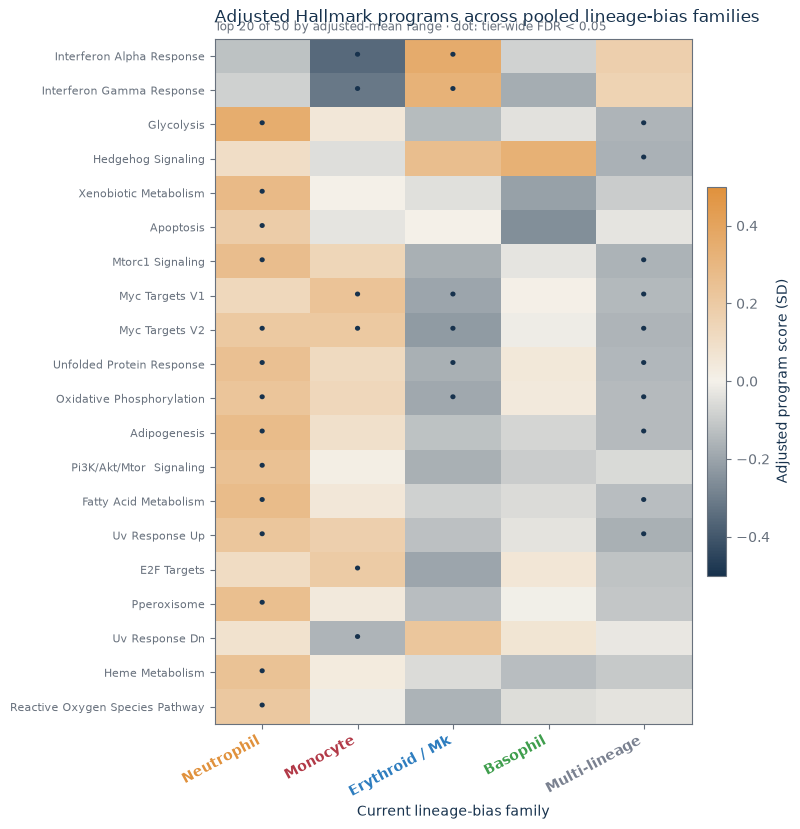

saved: analysis_workspace/analyses/weinreb_day2_hspc_metaclone_gene_programs_20260902/figures/weinreb_day2_hspc_03_lineage_bias_program_landscape.svg | analysis_workspace/analyses/weinreb_day2_hspc_metaclone_gene_programs_20260902/figures/weinreb_day2_hspc_03_lineage_bias_program_landscape.png


In [14]:
# PLOT_CELL_INLINE_V1
plot_stem = "weinreb_day2_hspc_03_lineage_bias_program_landscape"
plot_matrix_full = (adjusted_family_program_means.set_index("lineage_bias")
                    .reindex(FAMILY_ORDER)[list(program_scores.columns)])
plot_programs = (plot_matrix_full.max(axis=0) - plot_matrix_full.min(axis=0))
plot_programs = plot_programs.sort_values(ascending=False).head(20).index.tolist()
plot_matrix = plot_matrix_full[plot_programs].T
plot_long = (plot_matrix.rename_axis("program").reset_index()
             .melt(id_vars="program", var_name="lineage_bias", value_name="adjusted_score_sd"))
plot_long.to_csv(TABLEDIR / f"{plot_stem}_plot_data.csv", index=False)
significant = program_tests[
    (program_tests.tier == "lineage_bias_ovr") &
    (program_tests.tier_fdr < 0.05)
][["program", "lineage_bias"]]
significant_pairs = set(map(tuple, significant.to_numpy()))
limit = max(0.5, float(np.nanmax(np.abs(plot_matrix.to_numpy()))))

fig, ax = plt.subplots(figsize=(8.1, 8.4))
image_artist = ax.pcolormesh(
    np.arange(plot_matrix.shape[1] + 1),
    np.arange(plot_matrix.shape[0] + 1),
    plot_matrix.to_numpy(), cmap=PROGRAM_CMAP,
    vmin=-limit, vmax=limit, shading="flat",
)
for row_index, program in enumerate(plot_matrix.index):
    for column_index, family in enumerate(plot_matrix.columns):
        if (program, family) in significant_pairs:
            ax.text(column_index + 0.5, row_index + 0.5, "•", ha="center", va="center",
                    color=INK, fontsize=11, fontweight="bold")
ax.set_xticks(np.arange(len(FAMILY_ORDER)) + 0.5, FAMILY_ORDER, rotation=28, ha="right")
for tick, family in zip(ax.get_xticklabels(), FAMILY_ORDER):
    tick.set_color(FAMILY_COLORS[family])
    tick.set_fontweight("bold")
ax.set_yticks(
    np.arange(len(plot_programs)) + 0.5,
    [clean_program_name(program) for program in plot_programs], fontsize=8.2
)
ax.set_xlim(0, len(FAMILY_ORDER))
ax.set_ylim(0, len(plot_programs))
ax.invert_yaxis()
ax.set_xlabel("Current lineage-bias family")
ax.set_title("Adjusted Hallmark programs across pooled lineage-bias families", loc="left", pad=12)
ax.text(
    0, 1.012, "Top 20 of 50 by adjusted-mean range · dot: tier-wide FDR < 0.05",
    transform=ax.transAxes, fontsize=8.6, color=GREY
)
colorbar = fig.colorbar(image_artist, ax=ax, fraction=0.038, pad=0.03)
colorbar.solids.set_rasterized(False)
colorbar.set_label("Adjusted program score (SD)")
fig.tight_layout()
svg = FIGDIR / f"{plot_stem}.svg"
png = FIGDIR / f"{plot_stem}.png"
fig.savefig(svg, bbox_inches="tight")
fig.savefig(png, dpi=300, bbox_inches="tight")
display(fig)
print("saved:", svg.relative_to(PROJECT_ROOT), "|", png.relative_to(PROJECT_ROOT))
plt.close(fig)

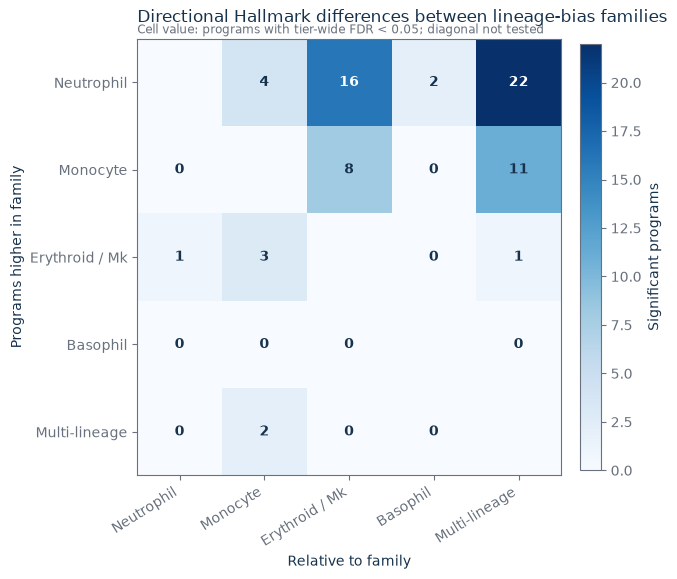

saved: analysis_workspace/analyses/weinreb_day2_hspc_metaclone_gene_programs_20260902/figures/weinreb_day2_hspc_04_lineage_bias_pairwise_program_counts.svg | analysis_workspace/analyses/weinreb_day2_hspc_metaclone_gene_programs_20260902/figures/weinreb_day2_hspc_04_lineage_bias_pairwise_program_counts.png


In [15]:
# PLOT_CELL_INLINE_V1
plot_stem = "weinreb_day2_hspc_04_lineage_bias_pairwise_program_counts"
pair_tests = program_tests[program_tests.tier == "lineage_bias_pairwise"].copy()
plot_matrix = pd.DataFrame(
    np.nan, index=FAMILY_ORDER, columns=FAMILY_ORDER, dtype=float
)
for family in FAMILY_ORDER:
    plot_matrix.loc[family, family] = 0
directional_rows = []
for (target_key, reference_key), frame in pair_tests.groupby(["target", "reference"], observed=True):
    target_family = FAMILY_DISPLAY[target_key]
    reference_family = FAMILY_DISPLAY[reference_key]
    forward = int(((frame.tier_fdr < 0.05) & (frame.effect_sd > 0)).sum())
    reverse = int(((frame.tier_fdr < 0.05) & (frame.effect_sd < 0)).sum())
    plot_matrix.loc[target_family, reference_family] = forward
    plot_matrix.loc[reference_family, target_family] = reverse
    directional_rows.extend([
        {"enriched_in": target_family, "relative_to": reference_family,
         "n_programs_tier_fdr_lt_0_05": forward},
        {"enriched_in": reference_family, "relative_to": target_family,
         "n_programs_tier_fdr_lt_0_05": reverse},
    ])
pd.DataFrame(directional_rows).to_csv(TABLEDIR / f"{plot_stem}_plot_data.csv", index=False)
display_matrix = np.ma.masked_invalid(plot_matrix.to_numpy())
vmax = max(1.0, float(np.nanmax(plot_matrix.to_numpy())))

fig, ax = plt.subplots(figsize=(6.8, 5.9))
image_artist = ax.pcolormesh(
    np.arange(display_matrix.shape[1] + 1),
    np.arange(display_matrix.shape[0] + 1),
    display_matrix, cmap="Blues", vmin=0, vmax=vmax, shading="flat",
)
for row_index, row_family in enumerate(FAMILY_ORDER):
    for column_index, column_family in enumerate(FAMILY_ORDER):
        value = plot_matrix.iloc[row_index, column_index]
        if np.isfinite(value) and row_index != column_index:
            ax.text(column_index + 0.5, row_index + 0.5, str(int(value)), ha="center", va="center",
                    color=WHITE if value > vmax * 0.55 else INK, fontweight="bold")
ax.set_xticks(np.arange(len(FAMILY_ORDER)) + 0.5, FAMILY_ORDER, rotation=32, ha="right")
ax.set_yticks(np.arange(len(FAMILY_ORDER)) + 0.5, FAMILY_ORDER)
ax.set_xlim(0, len(FAMILY_ORDER))
ax.set_ylim(0, len(FAMILY_ORDER))
ax.invert_yaxis()
ax.set_xlabel("Relative to family")
ax.set_ylabel("Programs higher in family")
ax.set_title("Directional Hallmark differences between lineage-bias families", loc="left", pad=12)
ax.text(
    0, 1.012, "Cell value: programs with tier-wide FDR < 0.05; diagonal not tested",
    transform=ax.transAxes, fontsize=8.4, color=GREY
)
colorbar = fig.colorbar(image_artist, ax=ax, fraction=0.046, pad=0.04)
colorbar.solids.set_rasterized(False)
colorbar.set_label("Significant programs")
fig.tight_layout()
svg = FIGDIR / f"{plot_stem}.svg"
png = FIGDIR / f"{plot_stem}.png"
fig.savefig(svg, bbox_inches="tight")
fig.savefig(png, dpi=300, bbox_inches="tight")
display(fig)
print("saved:", svg.relative_to(PROJECT_ROOT), "|", png.relative_to(PROJECT_ROOT))
plt.close(fig)

### Metaclone-resolved programs within each lineage-bias family

Four multi-metaclone families are estimable. Basophil contains only MC13,
so no within-Basophil metaclone contrast exists. Each panel selects the 12
programs with the largest adjusted range within that family for display;
all 50 program tests remain tabulated. Dots use the tier-wide FDR across
every within-family one-versus-peer program test.

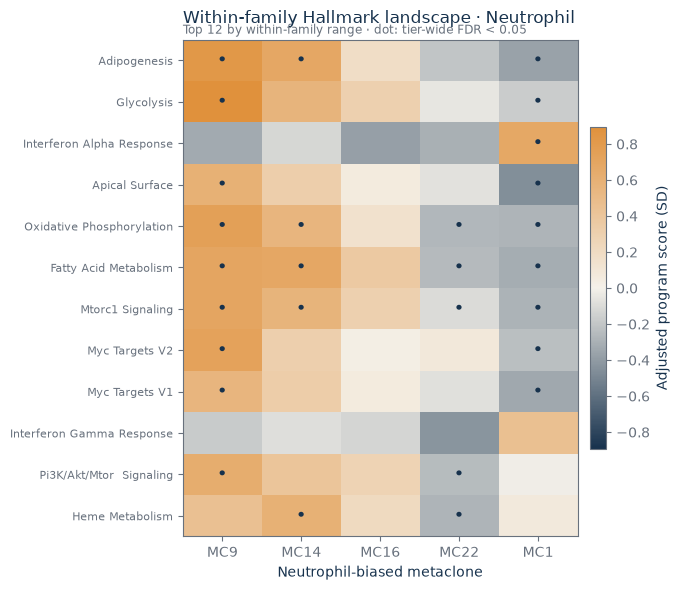

saved: analysis_workspace/analyses/weinreb_day2_hspc_metaclone_gene_programs_20260902/figures/weinreb_day2_hspc_05_neutrophil_within_family_programs.svg | analysis_workspace/analyses/weinreb_day2_hspc_metaclone_gene_programs_20260902/figures/weinreb_day2_hspc_05_neutrophil_within_family_programs.png


In [16]:
# PLOT_CELL_INLINE_V1
plot_stem = "weinreb_day2_hspc_05_neutrophil_within_family_programs"
plot_family = "Neutrophil"
plot_metaclones = FAMILY_GROUPS[plot_family]
plot_matrix_full = (adjusted_mc_program_means.set_index("metaclone")
                    .reindex(plot_metaclones)[list(program_scores.columns)])
plot_programs = (plot_matrix_full.max(axis=0) - plot_matrix_full.min(axis=0))
plot_programs = plot_programs.sort_values(ascending=False).head(12).index.tolist()
plot_matrix = plot_matrix_full[plot_programs].T
plot_long = (plot_matrix.rename_axis("program").reset_index()
             .melt(id_vars="program", var_name="metaclone", value_name="adjusted_score_sd"))
plot_long["lineage_bias"] = plot_family
plot_long.to_csv(TABLEDIR / f"{plot_stem}_plot_data.csv", index=False)
significant = program_tests[
    (program_tests.tier == "within_lineage_ovr") &
    (program_tests.lineage_bias == plot_family) &
    (program_tests.tier_fdr < 0.05)
][["program", "target_mc"]].copy()
significant["target_mc"] = significant.target_mc.astype(int)
significant_pairs = set(map(tuple, significant.to_numpy()))
limit = max(0.5, float(np.nanmax(np.abs(plot_matrix.to_numpy()))))

fig, ax = plt.subplots(figsize=(6.9, 6.0))
image_artist = ax.pcolormesh(
    np.arange(plot_matrix.shape[1] + 1),
    np.arange(plot_matrix.shape[0] + 1),
    plot_matrix.to_numpy(), cmap=PROGRAM_CMAP,
    vmin=-limit, vmax=limit, shading="flat",
)
for row_index, program in enumerate(plot_matrix.index):
    for column_index, metaclone in enumerate(plot_matrix.columns):
        if (program, int(metaclone)) in significant_pairs:
            ax.text(column_index + 0.5, row_index + 0.5, "•", ha="center", va="center",
                    color=INK, fontsize=11, fontweight="bold")
ax.set_xticks(np.arange(len(plot_metaclones)) + 0.5, [f"MC{mc}" for mc in plot_metaclones])
ax.set_yticks(np.arange(len(plot_programs)) + 0.5,
              [clean_program_name(program) for program in plot_programs], fontsize=8.2)
ax.set_xlim(0, len(plot_metaclones))
ax.set_ylim(0, len(plot_programs))
ax.invert_yaxis()
ax.set_xlabel("Neutrophil-biased metaclone")
ax.set_title("Within-family Hallmark landscape · Neutrophil", loc="left", pad=12)
ax.text(0, 1.012, "Top 12 by within-family range · dot: tier-wide FDR < 0.05",
        transform=ax.transAxes, fontsize=8.4, color=GREY)
colorbar = fig.colorbar(image_artist, ax=ax, fraction=0.038, pad=0.03)
colorbar.solids.set_rasterized(False)
colorbar.set_label("Adjusted program score (SD)")
fig.tight_layout()
svg = FIGDIR / f"{plot_stem}.svg"
png = FIGDIR / f"{plot_stem}.png"
fig.savefig(svg, bbox_inches="tight")
fig.savefig(png, dpi=300, bbox_inches="tight")
display(fig)
print("saved:", svg.relative_to(PROJECT_ROOT), "|", png.relative_to(PROJECT_ROOT))
plt.close(fig)

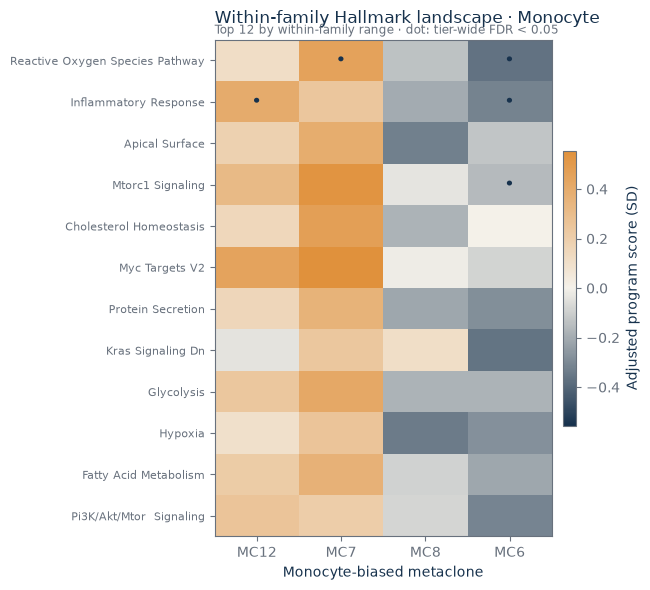

saved: analysis_workspace/analyses/weinreb_day2_hspc_metaclone_gene_programs_20260902/figures/weinreb_day2_hspc_06_monocyte_within_family_programs.svg | analysis_workspace/analyses/weinreb_day2_hspc_metaclone_gene_programs_20260902/figures/weinreb_day2_hspc_06_monocyte_within_family_programs.png


In [17]:
# PLOT_CELL_INLINE_V1
plot_stem = "weinreb_day2_hspc_06_monocyte_within_family_programs"
plot_family = "Monocyte"
plot_metaclones = FAMILY_GROUPS[plot_family]
plot_matrix_full = (adjusted_mc_program_means.set_index("metaclone")
                    .reindex(plot_metaclones)[list(program_scores.columns)])
plot_programs = (plot_matrix_full.max(axis=0) - plot_matrix_full.min(axis=0))
plot_programs = plot_programs.sort_values(ascending=False).head(12).index.tolist()
plot_matrix = plot_matrix_full[plot_programs].T
plot_long = (plot_matrix.rename_axis("program").reset_index()
             .melt(id_vars="program", var_name="metaclone", value_name="adjusted_score_sd"))
plot_long["lineage_bias"] = plot_family
plot_long.to_csv(TABLEDIR / f"{plot_stem}_plot_data.csv", index=False)
significant = program_tests[
    (program_tests.tier == "within_lineage_ovr") &
    (program_tests.lineage_bias == plot_family) &
    (program_tests.tier_fdr < 0.05)
][["program", "target_mc"]].copy()
significant["target_mc"] = significant.target_mc.astype(int)
significant_pairs = set(map(tuple, significant.to_numpy()))
limit = max(0.5, float(np.nanmax(np.abs(plot_matrix.to_numpy()))))

fig, ax = plt.subplots(figsize=(6.6, 6.0))
image_artist = ax.pcolormesh(
    np.arange(plot_matrix.shape[1] + 1),
    np.arange(plot_matrix.shape[0] + 1),
    plot_matrix.to_numpy(), cmap=PROGRAM_CMAP,
    vmin=-limit, vmax=limit, shading="flat",
)
for row_index, program in enumerate(plot_matrix.index):
    for column_index, metaclone in enumerate(plot_matrix.columns):
        if (program, int(metaclone)) in significant_pairs:
            ax.text(column_index + 0.5, row_index + 0.5, "•", ha="center", va="center",
                    color=INK, fontsize=11, fontweight="bold")
ax.set_xticks(np.arange(len(plot_metaclones)) + 0.5, [f"MC{mc}" for mc in plot_metaclones])
ax.set_yticks(np.arange(len(plot_programs)) + 0.5,
              [clean_program_name(program) for program in plot_programs], fontsize=8.2)
ax.set_xlim(0, len(plot_metaclones))
ax.set_ylim(0, len(plot_programs))
ax.invert_yaxis()
ax.set_xlabel("Monocyte-biased metaclone")
ax.set_title("Within-family Hallmark landscape · Monocyte", loc="left", pad=12)
ax.text(0, 1.012, "Top 12 by within-family range · dot: tier-wide FDR < 0.05",
        transform=ax.transAxes, fontsize=8.4, color=GREY)
colorbar = fig.colorbar(image_artist, ax=ax, fraction=0.038, pad=0.03)
colorbar.solids.set_rasterized(False)
colorbar.set_label("Adjusted program score (SD)")
fig.tight_layout()
svg = FIGDIR / f"{plot_stem}.svg"
png = FIGDIR / f"{plot_stem}.png"
fig.savefig(svg, bbox_inches="tight")
fig.savefig(png, dpi=300, bbox_inches="tight")
display(fig)
print("saved:", svg.relative_to(PROJECT_ROOT), "|", png.relative_to(PROJECT_ROOT))
plt.close(fig)

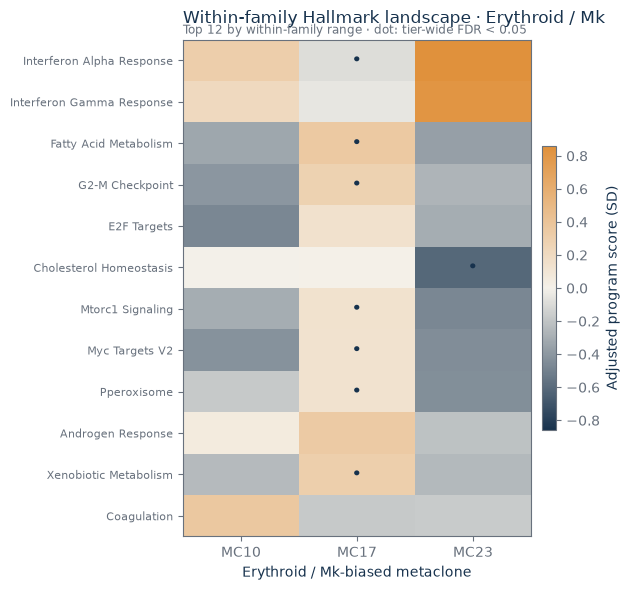

saved: analysis_workspace/analyses/weinreb_day2_hspc_metaclone_gene_programs_20260902/figures/weinreb_day2_hspc_07_erythroid_mk_within_family_programs.svg | analysis_workspace/analyses/weinreb_day2_hspc_metaclone_gene_programs_20260902/figures/weinreb_day2_hspc_07_erythroid_mk_within_family_programs.png


In [18]:
# PLOT_CELL_INLINE_V1
plot_stem = "weinreb_day2_hspc_07_erythroid_mk_within_family_programs"
plot_family = "Erythroid / Mk"
plot_metaclones = FAMILY_GROUPS[plot_family]
plot_matrix_full = (adjusted_mc_program_means.set_index("metaclone")
                    .reindex(plot_metaclones)[list(program_scores.columns)])
plot_programs = (plot_matrix_full.max(axis=0) - plot_matrix_full.min(axis=0))
plot_programs = plot_programs.sort_values(ascending=False).head(12).index.tolist()
plot_matrix = plot_matrix_full[plot_programs].T
plot_long = (plot_matrix.rename_axis("program").reset_index()
             .melt(id_vars="program", var_name="metaclone", value_name="adjusted_score_sd"))
plot_long["lineage_bias"] = plot_family
plot_long.to_csv(TABLEDIR / f"{plot_stem}_plot_data.csv", index=False)
significant = program_tests[
    (program_tests.tier == "within_lineage_ovr") &
    (program_tests.lineage_bias == plot_family) &
    (program_tests.tier_fdr < 0.05)
][["program", "target_mc"]].copy()
significant["target_mc"] = significant.target_mc.astype(int)
significant_pairs = set(map(tuple, significant.to_numpy()))
limit = max(0.5, float(np.nanmax(np.abs(plot_matrix.to_numpy()))))

fig, ax = plt.subplots(figsize=(6.4, 6.0))
image_artist = ax.pcolormesh(
    np.arange(plot_matrix.shape[1] + 1),
    np.arange(plot_matrix.shape[0] + 1),
    plot_matrix.to_numpy(), cmap=PROGRAM_CMAP,
    vmin=-limit, vmax=limit, shading="flat",
)
for row_index, program in enumerate(plot_matrix.index):
    for column_index, metaclone in enumerate(plot_matrix.columns):
        if (program, int(metaclone)) in significant_pairs:
            ax.text(column_index + 0.5, row_index + 0.5, "•", ha="center", va="center",
                    color=INK, fontsize=11, fontweight="bold")
ax.set_xticks(np.arange(len(plot_metaclones)) + 0.5, [f"MC{mc}" for mc in plot_metaclones])
ax.set_yticks(np.arange(len(plot_programs)) + 0.5,
              [clean_program_name(program) for program in plot_programs], fontsize=8.2)
ax.set_xlim(0, len(plot_metaclones))
ax.set_ylim(0, len(plot_programs))
ax.invert_yaxis()
ax.set_xlabel("Erythroid / Mk-biased metaclone")
ax.set_title("Within-family Hallmark landscape · Erythroid / Mk", loc="left", pad=12)
ax.text(0, 1.012, "Top 12 by within-family range · dot: tier-wide FDR < 0.05",
        transform=ax.transAxes, fontsize=8.4, color=GREY)
colorbar = fig.colorbar(image_artist, ax=ax, fraction=0.038, pad=0.03)
colorbar.solids.set_rasterized(False)
colorbar.set_label("Adjusted program score (SD)")
fig.tight_layout()
svg = FIGDIR / f"{plot_stem}.svg"
png = FIGDIR / f"{plot_stem}.png"
fig.savefig(svg, bbox_inches="tight")
fig.savefig(png, dpi=300, bbox_inches="tight")
display(fig)
print("saved:", svg.relative_to(PROJECT_ROOT), "|", png.relative_to(PROJECT_ROOT))
plt.close(fig)

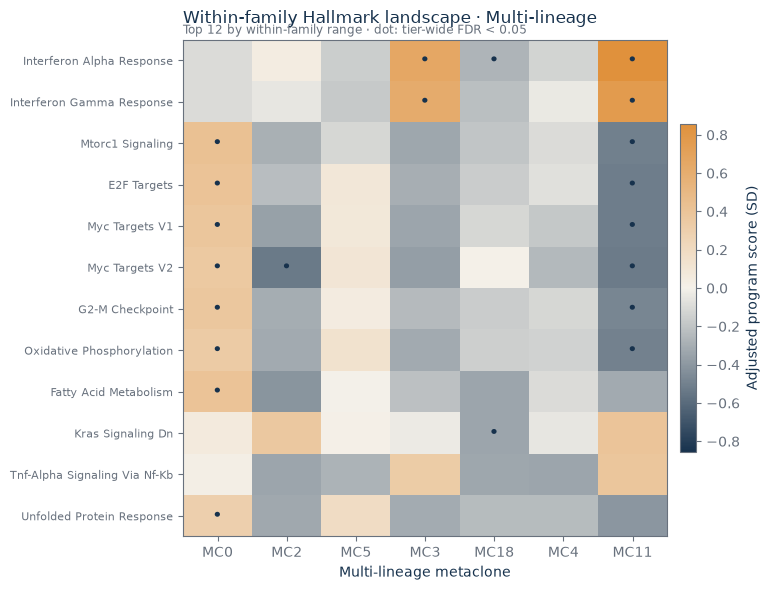

saved: analysis_workspace/analyses/weinreb_day2_hspc_metaclone_gene_programs_20260902/figures/weinreb_day2_hspc_08_multilineage_within_family_programs.svg | analysis_workspace/analyses/weinreb_day2_hspc_metaclone_gene_programs_20260902/figures/weinreb_day2_hspc_08_multilineage_within_family_programs.png


In [19]:
# PLOT_CELL_INLINE_V1
plot_stem = "weinreb_day2_hspc_08_multilineage_within_family_programs"
plot_family = "Multi-lineage"
plot_metaclones = FAMILY_GROUPS[plot_family]
plot_matrix_full = (adjusted_mc_program_means.set_index("metaclone")
                    .reindex(plot_metaclones)[list(program_scores.columns)])
plot_programs = (plot_matrix_full.max(axis=0) - plot_matrix_full.min(axis=0))
plot_programs = plot_programs.sort_values(ascending=False).head(12).index.tolist()
plot_matrix = plot_matrix_full[plot_programs].T
plot_long = (plot_matrix.rename_axis("program").reset_index()
             .melt(id_vars="program", var_name="metaclone", value_name="adjusted_score_sd"))
plot_long["lineage_bias"] = plot_family
plot_long.to_csv(TABLEDIR / f"{plot_stem}_plot_data.csv", index=False)
significant = program_tests[
    (program_tests.tier == "within_lineage_ovr") &
    (program_tests.lineage_bias == plot_family) &
    (program_tests.tier_fdr < 0.05)
][["program", "target_mc"]].copy()
significant["target_mc"] = significant.target_mc.astype(int)
significant_pairs = set(map(tuple, significant.to_numpy()))
limit = max(0.5, float(np.nanmax(np.abs(plot_matrix.to_numpy()))))

fig, ax = plt.subplots(figsize=(7.8, 6.0))
image_artist = ax.pcolormesh(
    np.arange(plot_matrix.shape[1] + 1),
    np.arange(plot_matrix.shape[0] + 1),
    plot_matrix.to_numpy(), cmap=PROGRAM_CMAP,
    vmin=-limit, vmax=limit, shading="flat",
)
for row_index, program in enumerate(plot_matrix.index):
    for column_index, metaclone in enumerate(plot_matrix.columns):
        if (program, int(metaclone)) in significant_pairs:
            ax.text(column_index + 0.5, row_index + 0.5, "•", ha="center", va="center",
                    color=INK, fontsize=11, fontweight="bold")
ax.set_xticks(np.arange(len(plot_metaclones)) + 0.5, [f"MC{mc}" for mc in plot_metaclones])
ax.set_yticks(np.arange(len(plot_programs)) + 0.5,
              [clean_program_name(program) for program in plot_programs], fontsize=8.2)
ax.set_xlim(0, len(plot_metaclones))
ax.set_ylim(0, len(plot_programs))
ax.invert_yaxis()
ax.set_xlabel("Multi-lineage metaclone")
ax.set_title("Within-family Hallmark landscape · Multi-lineage", loc="left", pad=12)
ax.text(0, 1.012, "Top 12 by within-family range · dot: tier-wide FDR < 0.05",
        transform=ax.transAxes, fontsize=8.4, color=GREY)
colorbar = fig.colorbar(image_artist, ax=ax, fraction=0.032, pad=0.025)
colorbar.solids.set_rasterized(False)
colorbar.set_label("Adjusted program score (SD)")
fig.tight_layout()
svg = FIGDIR / f"{plot_stem}.svg"
png = FIGDIR / f"{plot_stem}.png"
fig.savefig(svg, bbox_inches="tight")
fig.savefig(png, dpi=300, bbox_inches="tight")
display(fig)
print("saved:", svg.relative_to(PROJECT_ROOT), "|", png.relative_to(PROJECT_ROOT))
plt.close(fig)

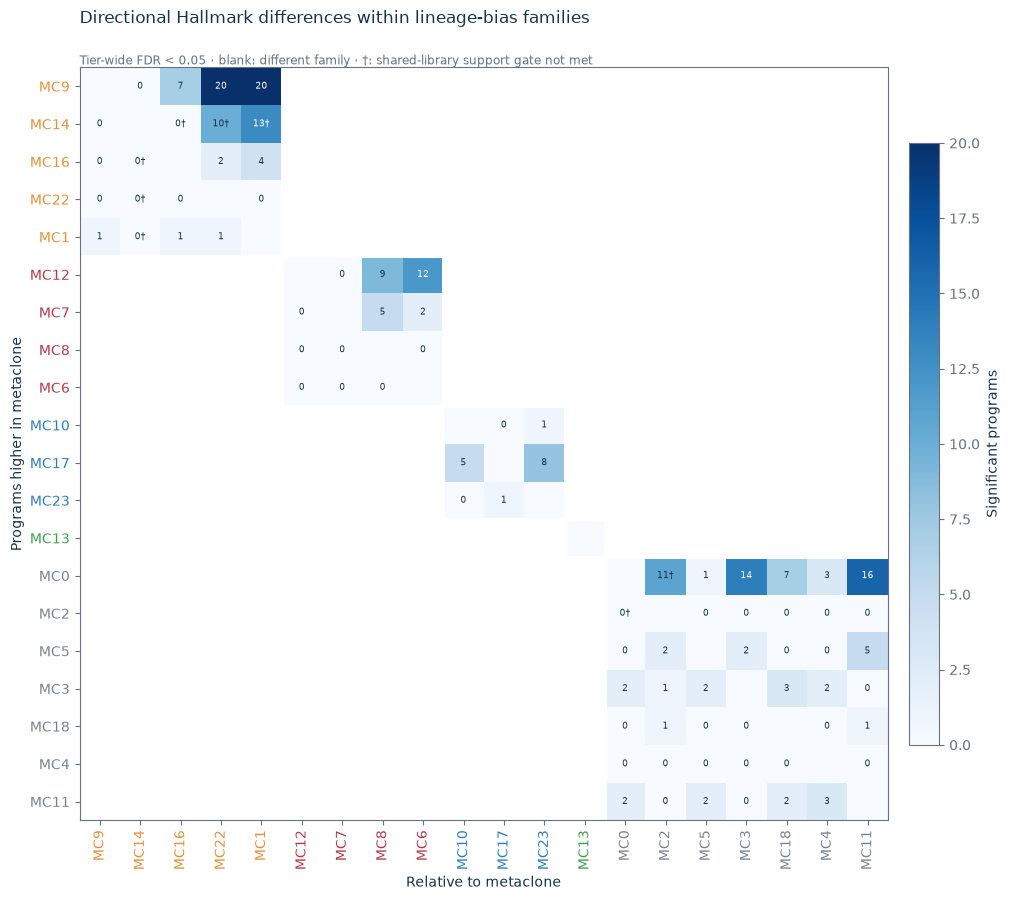

saved: analysis_workspace/analyses/weinreb_day2_hspc_metaclone_gene_programs_20260902/figures/weinreb_day2_hspc_09_within_family_pairwise_program_counts.svg | analysis_workspace/analyses/weinreb_day2_hspc_metaclone_gene_programs_20260902/figures/weinreb_day2_hspc_09_within_family_pairwise_program_counts.png


In [20]:
# PLOT_CELL_INLINE_V1
plot_stem = "weinreb_day2_hspc_09_within_family_pairwise_program_counts"
pair_tests = program_tests[program_tests.tier == "within_lineage_pairwise"].copy()
plot_matrix = pd.DataFrame(np.nan, index=MC_ORDER, columns=MC_ORDER, dtype=float)
support_matrix = pd.DataFrame(False, index=MC_ORDER, columns=MC_ORDER, dtype=bool)
for metaclone in MC_ORDER:
    plot_matrix.loc[metaclone, metaclone] = 0
    support_matrix.loc[metaclone, metaclone] = True
directional_rows = []
for (target_mc, reference_mc), frame in pair_tests.groupby(
    ["target_mc", "reference_mc"], observed=True
):
    target_mc = int(target_mc)
    reference_mc = int(reference_mc)
    is_supported = bool(frame.support_gate.iloc[0])
    forward = int(((frame.tier_fdr < 0.05) & (frame.effect_sd > 0)).sum())
    reverse = int(((frame.tier_fdr < 0.05) & (frame.effect_sd < 0)).sum())
    plot_matrix.loc[target_mc, reference_mc] = forward
    plot_matrix.loc[reference_mc, target_mc] = reverse
    support_matrix.loc[target_mc, reference_mc] = is_supported
    support_matrix.loc[reference_mc, target_mc] = is_supported
    family = MC_TO_FAMILY[target_mc]
    directional_rows.extend([
        {"lineage_bias": family, "enriched_in_metaclone": target_mc,
         "relative_to_metaclone": reference_mc,
         "n_programs_tier_fdr_lt_0_05": forward, "support_gate": is_supported},
        {"lineage_bias": family, "enriched_in_metaclone": reference_mc,
         "relative_to_metaclone": target_mc,
         "n_programs_tier_fdr_lt_0_05": reverse, "support_gate": is_supported},
    ])
pd.DataFrame(directional_rows).to_csv(TABLEDIR / f"{plot_stem}_plot_data.csv", index=False)
display_matrix = np.ma.masked_invalid(plot_matrix.to_numpy())
vmax = max(1.0, float(np.nanmax(plot_matrix.to_numpy())))

fig, ax = plt.subplots(figsize=(10.2, 9.1))
image_artist = ax.pcolormesh(
    np.arange(display_matrix.shape[1] + 1),
    np.arange(display_matrix.shape[0] + 1),
    display_matrix, cmap="Blues", vmin=0, vmax=vmax, shading="flat",
)
for row_index, target_mc in enumerate(MC_ORDER):
    for column_index, reference_mc in enumerate(MC_ORDER):
        value = plot_matrix.iloc[row_index, column_index]
        if np.isfinite(value) and row_index != column_index:
            marker = "" if support_matrix.iloc[row_index, column_index] else "†"
            ax.text(column_index + 0.5, row_index + 0.5, f"{int(value)}{marker}",
                    ha="center", va="center", fontsize=6.5,
                    color=WHITE if value > vmax * 0.55 else INK)
boundaries = np.cumsum([len(FAMILY_GROUPS[name]) for name in FAMILY_ORDER])[:-1]
for boundary in boundaries:
    ax.axvline(boundary, color=WHITE, linewidth=2.2)
    ax.axhline(boundary, color=WHITE, linewidth=2.2)
ax.set_xticks(np.arange(len(MC_ORDER)) + 0.5, [f"MC{mc}" for mc in MC_ORDER], rotation=90)
ax.set_yticks(np.arange(len(MC_ORDER)) + 0.5, [f"MC{mc}" for mc in MC_ORDER])
ax.set_xlim(0, len(MC_ORDER))
ax.set_ylim(0, len(MC_ORDER))
ax.invert_yaxis()
for tick, metaclone in zip(ax.get_xticklabels(), MC_ORDER):
    tick.set_color(FAMILY_COLORS[MC_TO_FAMILY[metaclone]])
for tick, metaclone in zip(ax.get_yticklabels(), MC_ORDER):
    tick.set_color(FAMILY_COLORS[MC_TO_FAMILY[metaclone]])
ax.set_xlabel("Relative to metaclone")
ax.set_ylabel("Programs higher in metaclone")
ax.set_title("Directional Hallmark differences within lineage-bias families", loc="left", pad=32)
ax.text(
    0, 1.004,
    "Tier-wide FDR < 0.05 · blank: different family · †: shared-library support gate not met",
    transform=ax.transAxes, fontsize=8.4, color=GREY
)
colorbar = fig.colorbar(image_artist, ax=ax, fraction=0.035, pad=0.025)
colorbar.solids.set_rasterized(False)
colorbar.set_label("Significant programs")
fig.tight_layout()
svg = FIGDIR / f"{plot_stem}.svg"
png = FIGDIR / f"{plot_stem}.png"
fig.savefig(svg, bbox_inches="tight")
fig.savefig(png, dpi=300, bbox_inches="tight")
display(fig)
print("saved:", svg.relative_to(PROJECT_ROOT), "|", png.relative_to(PROJECT_ROOT))
plt.close(fig)

## Computed findings

The following narrative is assembled from the executed result objects.
It deliberately separates observed evidence from interpretation and avoids
causal or prospective claims.

In [21]:
summary_lines = [
    "OBSERVED EVIDENCE",
    (
        f"- Day-2 prog_1 + prog_2 contained {len(all_day2_hspc):,} cells; "
        f"{len(hspc_cells):,} cells from {hspc_cells.LARRY_ID.nunique():,} assigned "
        f"LARRY clones entered the 20-metaclone analysis."
    ),
    (
        f"- Metaclone support ranged from {int(hspc_support.n_clones.min())} to "
        f"{int(hspc_support.n_clones.max())} clone pseudobulks."
    ),
]
for row in program_tier_summary.itertuples(index=False):
    summary_lines.append(
        f"- {row.tier}: {int(row.n_contrasts)} contrasts, "
        f"{int(row.n_tier_fdr_lt_0_05)} of {int(row.n_program_tests)} Hallmark tests "
        "passed tier-wide FDR < 0.05."
    )

for tier, label in [
    ("all_metaclones_ovr", "all-metaclone"),
    ("lineage_bias_ovr", "lineage-family"),
    ("within_lineage_ovr", "within-family"),
]:
    candidates = program_tests[
        (program_tests.tier == tier) & (program_tests.tier_fdr < 0.05)
    ].copy()
    if candidates.empty:
        summary_lines.append(f"- No {label} program test passed tier-wide FDR < 0.05.")
    else:
        candidates = candidates.assign(abs_effect=candidates.effect_sd.abs())
        top = candidates.sort_values(
            ["abs_effect", "tier_fdr", "contrast_id", "program"],
            ascending=[False, True, True, True]
        ).head(3)
        rendered = "; ".join(
            f"{row.contrast_label}: {row.program_label} ({row.effect_sd:+.2f} SD, q={row.tier_fdr:.2g})"
            for row in top.itertuples(index=False)
        )
        summary_lines.append(f"- Largest significant {label} program effects: {rendered}.")

supported_pairs = within_pair_support[within_pair_support.support_gate]
summary_lines.extend([
    "",
    "INTERPRETATION BOUNDARIES",
    (
        f"- {len(supported_pairs)} of {len(within_pair_support)} within-family metaclone pairs "
        "met the shared-library support gate; unsupported estimates remain visible and flagged."
    ),
    "- Program associations may reflect early maturation state or technical library composition despite adjustment.",
    "- Lineage-bias families are outcome-informed, nested partitions; pooled-family effects are clone-weighted in this dataset.",
    "- MC13 is the only Basophil metaclone, so no within-Basophil comparison is estimable.",
    "- MC0 and MC5 follow the current manual Figure-2 map (Multi-lineage); an older threshold rule would differ.",
])
result_summary_text = "\n".join(summary_lines)
(REPORTDIR / "computed_findings_and_boundaries.txt").write_text(
    result_summary_text + "\n", encoding="utf-8"
)
print(result_summary_text)

OBSERVED EVIDENCE
- Day-2 prog_1 + prog_2 contained 1,041 cells; 775 cells from 569 assigned LARRY clones entered the 20-metaclone analysis.
- Metaclone support ranged from 17 to 50 clone pseudobulks.
- all_metaclones_ovr: 20 contrasts, 133 of 1000 Hallmark tests passed tier-wide FDR < 0.05.
- lineage_bias_ovr: 5 contrasts, 41 of 250 Hallmark tests passed tier-wide FDR < 0.05.
- lineage_bias_pairwise: 10 contrasts, 70 of 500 Hallmark tests passed tier-wide FDR < 0.05.
- within_lineage_ovr: 19 contrasts, 91 of 950 Hallmark tests passed tier-wide FDR < 0.05.
- within_lineage_pairwise: 40 contrasts, 204 of 2000 Hallmark tests passed tier-wide FDR < 0.05.
- Largest significant all-metaclone program effects: MC9 vs equal-MC mean of other 19: Glycolysis (+0.93 SD, q=1.4e-08); MC23 vs equal-MC mean of other 19: Interferon Alpha Response (+0.91 SD, q=0.034); MC11 vs equal-MC mean of other 19: Interferon Alpha Response (+0.91 SD, q=0.0087).
- Largest significant lineage-family program effects: 

## Validation & provenance

Validation covers cohort identity, protected-column exclusion, count
reconstruction, model rank, contrast completeness, multiple-testing
outputs, plot-cell structure, file existence, and reproducible resource
hashes. A machine-readable artifact manifest follows the checks.

In [22]:
expected_tier_counts = {
    "all_metaclones_ovr": 20,
    "lineage_bias_ovr": 5,
    "lineage_bias_pairwise": 10,
    "within_lineage_ovr": 19,
    "within_lineage_pairwise": 40,
}
observed_tier_counts = spec_table.groupby("tier", observed=True).contrast_id.nunique().to_dict()
plot_stems = [
    "weinreb_day2_hspc_01_metaclone_support",
    "weinreb_day2_hspc_02_all_metaclone_program_landscape",
    "weinreb_day2_hspc_03_lineage_bias_program_landscape",
    "weinreb_day2_hspc_04_lineage_bias_pairwise_program_counts",
    "weinreb_day2_hspc_05_neutrophil_within_family_programs",
    "weinreb_day2_hspc_06_monocyte_within_family_programs",
    "weinreb_day2_hspc_07_erythroid_mk_within_family_programs",
    "weinreb_day2_hspc_08_multilineage_within_family_programs",
    "weinreb_day2_hspc_09_within_family_pairwise_program_counts",
]
notebook_source = nbformat.read(NOTEBOOK_PATH, as_version=4)
plot_marker = "# PLOT_CELL_" + "INLINE_V1"
plot_sources = [
    cell.source for cell in notebook_source.cells
    if cell.cell_type == "code" and plot_marker in cell.source
]
plot_source_contract = all(
    source.count("plt.subplots") == 1
    and source.count("fig.savefig(svg") == 1
    and source.count("fig.savefig(png") == 1
    and source.count("display(fig)") == 1
    and source.count("plt.close(fig)") == 1
    for source in plot_sources
)
output_headers_are_population_free = True
for table_path in sorted(TABLEDIR.glob("*.csv*")):
    header = pd.read_csv(table_path, nrows=0).columns.astype(str).str.lower().tolist()
    output_headers_are_population_free &= "population" not in header

validation_rows = [
    ("input_object_sha256", input_hash == EXPECTED_INPUT_SHA256,
     f"observed={input_hash}"),
    ("lineage_map_sha256", lineage_map_hash == EXPECTED_LINEAGE_MAP_SHA256,
     f"observed={lineage_map_hash}"),
    ("population_removed", "population" not in A.obs.columns,
     "removed immediately after object read"),
    ("output_headers_population_free", output_headers_are_population_free,
     f"checked={len(list(TABLEDIR.glob('*.csv*')))} tables"),
    ("all_day2_prog1_plus_prog2_cells", len(all_day2_hspc) == 1041,
     f"observed={len(all_day2_hspc)}"),
    ("assigned_analysis_cells", len(hspc_cells) == 775,
     f"observed={len(hspc_cells)}"),
    ("clone_pseudobulks", len(pseudobulk_counts) == 569,
     f"observed={len(pseudobulk_counts)}"),
    ("current_metaclones", hspc_cells.metaclone.nunique() == 20,
     f"observed={hspc_cells.metaclone.nunique()}"),
    ("current_lineage_families", hspc_cells.lineage_bias.nunique() == 5,
     f"observed={hspc_cells.lineage_bias.nunique()}"),
    ("minimum_metaclone_clone_support", int(hspc_support.n_clones.min()) >= 10,
     f"observed_min={int(hspc_support.n_clones.min())}"),
    ("count_integer_lattice_error", reconstruction_error < 1e-6,
     f"observed={reconstruction_error:.3g}"),
    ("full_rank_metaclone_model",
     mc_fit_summary["design_rank"] == mc_fit_summary["design_columns"],
     f"rank={mc_fit_summary['design_rank']}/{mc_fit_summary['design_columns']}"),
    ("full_rank_lineage_model",
     family_fit_summary["design_rank"] == family_fit_summary["design_columns"],
     f"rank={family_fit_summary['design_rank']}/{family_fit_summary['design_columns']}"),
    ("contrast_registry_complete", observed_tier_counts == expected_tier_counts,
     json.dumps(observed_tier_counts, sort_keys=True)),
    ("program_test_grid_complete", len(program_tests) == 94 * 50,
     f"observed={len(program_tests)} expected={94 * 50}"),
    ("gsea_test_grid_complete",
     gsea_results.contrast_id.nunique() == 44 and len(gsea_results) == 44 * 50,
     f"contrasts={gsea_results.contrast_id.nunique()} tests={len(gsea_results)}"),
    ("finite_program_statistics",
     np.isfinite(program_tests[["effect_sd", "standard_error", "t_stat", "pvalue"]].to_numpy()).all(),
     "effect, SE, t, and p checked"),
    ("basophil_within_family_not_estimated",
     not ((program_tests.tier.str.startswith("within_lineage")) &
          (program_tests.lineage_bias == "Basophil")).any(),
     "one Basophil metaclone"),
    ("legacy_rule_disagreement_audited",
     set(lineage_rule_sensitivity.loc[
         lineage_rule_sensitivity.classification_differs, "metaclone"
     ]) == {0, 5},
     "expected current-vs-legacy disagreements: MC0, MC5"),
    ("plot_cell_count", len(plot_sources) == len(plot_stems),
     f"observed={len(plot_sources)} expected={len(plot_stems)}"),
    ("plot_cell_inline_contract", plot_source_contract,
     "one inline figure construction/save/display/close per plot cell"),
    ("svg_outputs", all((FIGDIR / f"{stem}.svg").stat().st_size > 0 for stem in plot_stems),
     f"expected={len(plot_stems)}"),
    ("png_outputs", all((FIGDIR / f"{stem}.png").stat().st_size > 0 for stem in plot_stems),
     f"expected={len(plot_stems)}"),
    ("hallmark_resource_checkpoint", sha256(HALLMARK_LOCAL) == hallmark_source_hash,
     f"sha256={hallmark_source_hash}"),
]
validation = pd.DataFrame(validation_rows, columns=["check", "passed", "detail"])
validation.to_csv(REPORTDIR / "validation.csv", index=False)
assert validation.passed.all(), validation.loc[~validation.passed]

artifact_paths = []
for folder in [ANALYSIS_DIR / "scripts", FIGDIR, TABLEDIR, REPORTDIR, RESOURCEDIR]:
    for path in sorted(folder.rglob("*")):
        if (path.is_file() and path.name != "artifact_manifest.csv"
                and path.suffix != ".pyc" and "__pycache__" not in path.parts):
            artifact_paths.append(path)
artifact_manifest = pd.DataFrame([
    {
        "path": str(path.relative_to(PROJECT_ROOT)),
        "bytes": path.stat().st_size,
        "sha256": sha256(path),
    }
    for path in artifact_paths
])
artifact_manifest.to_csv(REPORTDIR / "artifact_manifest.csv", index=False)
display(validation)
display(artifact_manifest)
print("All validation checks passed.")
print("Notebook:", NOTEBOOK_PATH)
print("Environment: chronoclone |", ENV_PATH)
print("Execution command:", EXECUTION_COMMAND)

,check,passed,detail
0,input_object_sha256,True,observed=4cb08c12dc70f5c3789a75a09a6399db06b3f...
1,lineage_map_sha256,True,observed=b4d1af7b481a9b1a26d781feb449fb88d300d...
2,population_removed,True,removed immediately after object read
3,output_headers_population_free,True,checked=136 tables
4,all_day2_prog1_plus_prog2_cells,True,observed=1041
5,assigned_analysis_cells,True,observed=775
6,clone_pseudobulks,True,observed=569
7,current_metaclones,True,observed=20
8,current_lineage_families,True,observed=5
9,minimum_metaclone_clone_support,True,observed_min=17


,path,bytes,sha256
0,analysis_workspace/analyses/weinreb_day2_hspc_metac...,273546,73e65b5d4d6e68be637b446c607325eed9c97676952789...
1,analysis_workspace/analyses/weinreb_day2_hspc_metac...,221650,877d6a0a2ee6c70efca80ca03e39e741c31b9b2237699e...
2,analysis_workspace/analyses/weinreb_day2_hspc_metac...,340113,1d5f85955df3ef60e471cda8808020c6601bb6bff91a26...
3,analysis_workspace/analyses/weinreb_day2_hspc_metac...,31969,eba699d640347478c9ba56efbd7ca0434c15949c594050...
4,analysis_workspace/analyses/weinreb_day2_hspc_metac...,334021,a188e8016125daeae8d7d01a3f8b918b9a2e77aea650da...
...,...,...,...
220,analysis_workspace/analyses/weinreb_day2_hspc_metac...,1721,45bbcecfb0c1df5b688a2fb35a57de733d14430f568f01...
221,analysis_workspace/analyses/weinreb_day2_hspc_metac...,1537,d67b5f8eb22506c60481db572ab98b56819fc6223fd9dc...
222,analysis_workspace/analyses/weinreb_day2_hspc_metac...,193637,6aabbf753f6d14dd2205f47fc5e461688fa550a9685dff...
223,analysis_workspace/analyses/weinreb_day2_hspc_metac...,44235,4275592957a1587652092bb398cf77216fde5b8daa2aed...


All validation checks passed.
Notebook: /path/to/ChronoClone/analysis_workspace/analyses/weinreb_day2_hspc_metaclone_gene_programs_20260902/0001_weinreb_day2_hspc_metaclone_gene_programs.ipynb
Environment: chronoclone | /path/to/ChronoClone/.runtime/chronoclone
Execution command: /path/to/ChronoClone/.runtime/chronoclone/bin/jupyter-nbconvert --to notebook --execute --inplace --ExecutePreprocessor.kernel_name=chronoclone --ExecutePreprocessor.timeout=7200 /path/to/ChronoClone/analysis_workspace/analyses/weinreb_day2_hspc_metaclone_gene_programs_20260902/0001_weinreb_day2_hspc_metaclone_gene_programs.ipynb


## Version 2 — Multi-lineage program–output correlations

This section asks whether the
library-adjusted, clone-pseudobulk Day-2 Hallmark score of each current
Multi-lineage metaclone is associated with the cell types produced by
that metaclone at Days 4 and 6.

The seven current Multi-lineage metaclones are the independent
observations. Primary outcomes are the author `cell_type_weinreb`
fractions within each observed clone and day, averaged equally across
clones. An unweighted pooled-cell result and a mature-only clone-balanced
result are retained as sensitivities. Entirely unobserved clone-days are
missing rather than zero; within an observed clone-day, an absent cell
type contributes a structural zero.

Each program–output association uses an exhaustive two-sided Spearman
label-permutation test over all `7! = 5,040` metaclone permutations.
Multiplicity is reported both within each cell-type/time endpoint (50
programs) and across the full primary screen. Leave-one-metaclone-out
directions are retained because seven observations cannot support a
stable high-dimensional predictive claim. Output fractions are
compositional, and the Multi-lineage family itself was defined from later
output; all associations are retrospective and exploratory.

In [23]:
# Build clone-balanced D4/D6 author cell-type outputs for all seven Multi-lineage MCs
from scipy.spatial.distance import jensenshannon, pdist, squareform
from scipy.stats import rankdata, spearmanr

MULTI_MCS = list(FAMILY_GROUPS["Multi-lineage"])
OUTPUT_DAYS = [4, 6]
AUTHOR_OUTPUT_TYPES = [
    "Neutrophil", "Monocyte", "Meg", "Erythroid", "Baso", "Mast",
    "Eos", "Ccr7_DC", "Lymphoid", "Undifferentiated",
]
MATURE_OUTPUT_TYPES = [
    output_type for output_type in AUTHOR_OUTPUT_TYPES
    if output_type != "Undifferentiated"
]
required_output_columns = [
    "day", "cell_type_weinreb", "LARRY_ID", "metaclone", "Library"
]
assert all(column in obs.columns for column in required_output_columns)

output_cells = obs.loc[
    obs.metaclone.isin(MULTI_MCS) & obs.day.isin(OUTPUT_DAYS),
    required_output_columns,
].copy()
output_cells["metaclone"] = output_cells.metaclone.astype(int)
output_cells["day"] = output_cells.day.astype(int)
output_cells["cell_type_weinreb"] = output_cells.cell_type_weinreb.astype(str)
observed_output_types = set(output_cells.cell_type_weinreb)
assert observed_output_types <= set(AUTHOR_OUTPUT_TYPES), observed_output_types

output_support_rows = []
for (metaclone, day), group in output_cells.groupby(
    ["metaclone", "day"], observed=True
):
    mature = group[group.cell_type_weinreb != "Undifferentiated"]
    output_support_rows.append({
        "metaclone": int(metaclone),
        "day": int(day),
        "n_cells": int(len(group)),
        "n_clones": int(group.LARRY_ID.nunique()),
        "n_mature_cells": int(len(mature)),
        "n_mature_informative_clones": int(mature.LARRY_ID.nunique()),
        "fraction_clones_with_mature_output": float(
            mature.LARRY_ID.nunique() / group.LARRY_ID.nunique()
        ),
    })
multilineage_output_support = (
    pd.DataFrame(output_support_rows)
    .set_index(["metaclone", "day"])
    .reindex(pd.MultiIndex.from_product(
        [MULTI_MCS, OUTPUT_DAYS], names=["metaclone", "day"]
    ))
    .reset_index()
)
assert multilineage_output_support[
    ["n_cells", "n_clones"]
].notna().all().all()

clone_keys = output_cells[
    ["metaclone", "day", "LARRY_ID"]
].drop_duplicates()
clone_type_grid = (
    clone_keys.assign(_join_key=1)
    .merge(
        pd.DataFrame({
            "cell_type_weinreb": AUTHOR_OUTPUT_TYPES,
            "_join_key": 1,
        }),
        on="_join_key",
    )
    .drop(columns="_join_key")
)
clone_type_counts = (
    output_cells.groupby(
        ["metaclone", "day", "LARRY_ID", "cell_type_weinreb"],
        observed=True,
    )
    .size()
    .rename("n_cells")
    .reset_index()
)
clone_type_complete = clone_type_grid.merge(
    clone_type_counts,
    on=["metaclone", "day", "LARRY_ID", "cell_type_weinreb"],
    how="left",
    validate="one_to_one",
)
clone_type_complete["n_cells"] = clone_type_complete.n_cells.fillna(0).astype(int)
clone_type_complete["clone_day_total"] = clone_type_complete.groupby(
    ["metaclone", "day", "LARRY_ID"], observed=True
).n_cells.transform("sum")
assert (clone_type_complete.clone_day_total > 0).all()
clone_type_complete["fraction"] = (
    clone_type_complete.n_cells / clone_type_complete.clone_day_total
)
multilineage_output_clone_balanced = (
    clone_type_complete.groupby(
        ["metaclone", "day", "cell_type_weinreb"], observed=True
    ).fraction.mean().reset_index()
)

pooled_type_counts = (
    output_cells.groupby(
        ["metaclone", "day", "cell_type_weinreb"], observed=True
    ).size().rename("n_cells").reset_index()
)
mc_day_type_grid = (
    output_cells[["metaclone", "day"]].drop_duplicates().assign(_join_key=1)
    .merge(
        pd.DataFrame({
            "cell_type_weinreb": AUTHOR_OUTPUT_TYPES,
            "_join_key": 1,
        }),
        on="_join_key",
    )
    .drop(columns="_join_key")
)
multilineage_output_pooled_cells = mc_day_type_grid.merge(
    pooled_type_counts,
    on=["metaclone", "day", "cell_type_weinreb"],
    how="left",
    validate="one_to_one",
)
multilineage_output_pooled_cells["n_cells"] = (
    multilineage_output_pooled_cells.n_cells.fillna(0).astype(int)
)
multilineage_output_pooled_cells["fraction"] = (
    multilineage_output_pooled_cells.n_cells
    / multilineage_output_pooled_cells.groupby(
        ["metaclone", "day"], observed=True
    ).n_cells.transform("sum")
)

mature_cells = output_cells[
    output_cells.cell_type_weinreb != "Undifferentiated"
].copy()
mature_clone_keys = mature_cells[
    ["metaclone", "day", "LARRY_ID"]
].drop_duplicates()
mature_clone_type_grid = (
    mature_clone_keys.assign(_join_key=1)
    .merge(
        pd.DataFrame({
            "cell_type_weinreb": MATURE_OUTPUT_TYPES,
            "_join_key": 1,
        }),
        on="_join_key",
    )
    .drop(columns="_join_key")
)
mature_clone_counts = (
    mature_cells.groupby(
        ["metaclone", "day", "LARRY_ID", "cell_type_weinreb"],
        observed=True,
    ).size().rename("n_cells").reset_index()
)
mature_clone_complete = mature_clone_type_grid.merge(
    mature_clone_counts,
    on=["metaclone", "day", "LARRY_ID", "cell_type_weinreb"],
    how="left",
    validate="one_to_one",
)
mature_clone_complete["n_cells"] = (
    mature_clone_complete.n_cells.fillna(0).astype(int)
)
mature_clone_complete["mature_clone_day_total"] = mature_clone_complete.groupby(
    ["metaclone", "day", "LARRY_ID"], observed=True
).n_cells.transform("sum")
assert (mature_clone_complete.mature_clone_day_total > 0).all()
mature_clone_complete["fraction"] = (
    mature_clone_complete.n_cells / mature_clone_complete.mature_clone_day_total
)
multilineage_output_mature_clone_balanced = (
    mature_clone_complete.groupby(
        ["metaclone", "day", "cell_type_weinreb"], observed=True
    ).fraction.mean().reset_index()
)

program_columns = list(program_scores.columns)
multilineage_day2_program_means = (
    adjusted_mc_program_means.set_index("metaclone")
    .loc[MULTI_MCS, program_columns]
    .rename_axis("metaclone")
    .reset_index()
)
assert multilineage_day2_program_means.shape == (7, 51)
assert np.isfinite(
    multilineage_day2_program_means[program_columns].to_numpy(float)
).all()

multilineage_output_support.to_csv(
    TABLEDIR / "multilineage_output_support_by_day.csv", index=False
)
multilineage_output_clone_balanced.to_csv(
    TABLEDIR / "multilineage_clone_balanced_author_output_by_day.csv", index=False
)
multilineage_output_pooled_cells.to_csv(
    TABLEDIR / "multilineage_pooled_cell_author_output_by_day.csv", index=False
)
multilineage_output_mature_clone_balanced.to_csv(
    TABLEDIR / "multilineage_clone_balanced_mature_output_by_day.csv", index=False
)
multilineage_day2_program_means.to_csv(
    TABLEDIR / "multilineage_day2_adjusted_program_means.csv", index=False
)

primary_fraction_sums = multilineage_output_clone_balanced.groupby(
    ["metaclone", "day"], observed=True
).fraction.sum()
mature_fraction_sums = multilineage_output_mature_clone_balanced.groupby(
    ["metaclone", "day"], observed=True
).fraction.sum()
assert np.allclose(primary_fraction_sums, 1.0)
assert np.allclose(mature_fraction_sums, 1.0)
display(multilineage_output_support)

,metaclone,day,n_cells,n_clones,n_mature_cells,n_mature_informative_clones,fraction_clones_with_mature_output
0,0,4,391,35,218,34,0.971429
1,0,6,778,35,771,35,1.000000
2,2,4,58,20,13,7,0.350000
3,2,6,68,12,37,11,0.916667
4,5,4,125,25,31,8,0.320000
5,5,6,203,25,157,24,0.960000
6,3,4,253,50,63,12,0.240000
7,3,6,683,47,448,43,0.914894
8,18,4,88,38,1,1,0.026316
9,18,6,355,33,102,17,0.515152


### Exact metaclone-level correlations

Day 4 and Day 6 are tested separately. A Day-6-minus-Day-4 snapshot
difference is retained as a sensitivity; it can reflect both biological
change and incomplete recovery of different clones at the two destructive
snapshots. Endpoint-specific FDR asks which of the 50 programs relates to
one declared cell-type/time outcome. Analysis-wide FDR additionally
protects across all cell types and temporal scopes.

In [24]:
# Exhaustive 7! Spearman correlations, endpoint/global FDR, and LOMO stability
PERMUTATION_INDEX = np.asarray(
    list(itertools.permutations(np.arange(len(MULTI_MCS)))), dtype=int
)
assert PERMUTATION_INDEX.shape == (5040, 7)

def exact_spearman_permutation(x_values, y_values):
    x_values = np.asarray(x_values, dtype=float)
    y_values = np.asarray(y_values, dtype=float)
    complete = np.isfinite(x_values) & np.isfinite(y_values)
    if complete.sum() != len(MULTI_MCS):
        return np.nan, np.nan
    x_rank = rankdata(x_values, method="average")
    y_rank = rankdata(y_values, method="average")
    x_centered = x_rank - x_rank.mean()
    y_centered = y_rank - y_rank.mean()
    denominator = np.sqrt(
        np.sum(x_centered ** 2) * np.sum(y_centered ** 2)
    )
    if denominator <= 0:
        return np.nan, np.nan
    observed_rho = float(np.dot(x_centered, y_centered) / denominator)
    permuted_centered = y_centered[PERMUTATION_INDEX]
    permutation_rho = permuted_centered @ x_centered / denominator
    exact_pvalue = float(
        np.mean(np.abs(permutation_rho) >= abs(observed_rho) - 1e-12)
    )
    return observed_rho, exact_pvalue

def lomo_spearman_summary(x_values, y_values, observed_rho):
    lomo_rho = []
    for omitted in range(len(MULTI_MCS)):
        keep = np.arange(len(MULTI_MCS)) != omitted
        x_subset = np.asarray(x_values, dtype=float)[keep]
        y_subset = np.asarray(y_values, dtype=float)[keep]
        complete = np.isfinite(x_subset) & np.isfinite(y_subset)
        if (
            complete.sum() < 2
            or np.unique(x_subset[complete]).size < 2
            or np.unique(y_subset[complete]).size < 2
        ):
            rho = np.nan
        else:
            rho = spearmanr(
                x_subset[complete], y_subset[complete]
            ).statistic
        lomo_rho.append(float(rho) if np.isfinite(rho) else np.nan)
    finite = np.asarray(lomo_rho)[np.isfinite(lomo_rho)]
    sign_stable = bool(
        len(finite) == len(MULTI_MCS)
        and np.isfinite(observed_rho)
        and abs(observed_rho) > 0
        and np.all(np.sign(finite) == np.sign(observed_rho))
    )
    return {
        "n_finite_lomo": int(len(finite)),
        "lomo_sign_stable": sign_stable,
        "lomo_min_rho": float(finite.min()) if len(finite) else np.nan,
        "lomo_max_rho": float(finite.max()) if len(finite) else np.nan,
        "lomo_min_abs_rho": float(np.abs(finite).min()) if len(finite) else np.nan,
    }

def build_program_output_correlations(
    output_table, output_types, estimand, analysis_role
):
    wide = (
        output_table.pivot_table(
            index="metaclone", columns=["day", "cell_type_weinreb"],
            values="fraction", observed=True
        )
        .reindex(index=MULTI_MCS)
    )
    program_matrix = (
        multilineage_day2_program_means.set_index("metaclone")
        .loc[MULTI_MCS, program_columns]
    )
    rows = []
    for temporal_scope in ["Day 4", "Day 6", "Day 6 minus Day 4"]:
        for output_type in output_types:
            day4 = wide[(4, output_type)].to_numpy(float)
            day6 = wide[(6, output_type)].to_numpy(float)
            if temporal_scope == "Day 4":
                outcome = day4
            elif temporal_scope == "Day 6":
                outcome = day6
            else:
                outcome = day6 - day4
            for program in program_columns:
                predictor = program_matrix[program].to_numpy(float)
                rho, exact_pvalue = exact_spearman_permutation(
                    predictor, outcome
                )
                lomo = lomo_spearman_summary(predictor, outcome, rho)
                rows.append({
                    "estimand": estimand,
                    "analysis_role": analysis_role,
                    "temporal_scope": temporal_scope,
                    "output_type": output_type,
                    "program": program,
                    "program_label": clean_program_name(program),
                    "n_metaclones": int(
                        np.sum(np.isfinite(predictor) & np.isfinite(outcome))
                    ),
                    "n_nonzero_output_metaclones": int(
                        np.sum(np.abs(outcome) > 1e-12)
                    ),
                    "n_unique_output_values": int(
                        len(np.unique(np.round(outcome[np.isfinite(outcome)], 12)))
                    ),
                    "spearman_rho": rho,
                    "exact_permutation_pvalue": exact_pvalue,
                    "n_label_permutations": len(PERMUTATION_INDEX),
                    **lomo,
                })
    result = pd.DataFrame(rows)
    result["endpoint_fdr"] = result.groupby(
        ["temporal_scope", "output_type"],
        observed=True,
        group_keys=False,
    ).exact_permutation_pvalue.transform(bh_adjust)
    result["temporal_scope_fdr"] = result.groupby(
        "temporal_scope", observed=True, group_keys=False
    ).exact_permutation_pvalue.transform(bh_adjust)
    result["analysis_wide_fdr"] = bh_adjust(
        result.exact_permutation_pvalue.to_numpy(float)
    )
    return result

primary_correlations = build_program_output_correlations(
    multilineage_output_clone_balanced,
    AUTHOR_OUTPUT_TYPES,
    "clone_balanced_all_observed_cells",
    "primary",
)
pooled_correlations = build_program_output_correlations(
    multilineage_output_pooled_cells,
    AUTHOR_OUTPUT_TYPES,
    "pooled_cells_all_observed_cells",
    "sensitivity",
)
mature_correlations = build_program_output_correlations(
    multilineage_output_mature_clone_balanced,
    MATURE_OUTPUT_TYPES,
    "clone_balanced_mature_only",
    "sensitivity",
)

correlation_key = ["temporal_scope", "output_type", "program"]
primary_correlations = primary_correlations.merge(
    pooled_correlations[correlation_key + ["spearman_rho"]].rename(
        columns={"spearman_rho": "pooled_cell_sensitivity_rho"}
    ),
    on=correlation_key,
    how="left",
    validate="one_to_one",
)
primary_correlations = primary_correlations.merge(
    mature_correlations[correlation_key + ["spearman_rho"]].rename(
        columns={"spearman_rho": "mature_only_sensitivity_rho"}
    ),
    on=correlation_key,
    how="left",
    validate="one_to_one",
)
primary_correlations["pooled_direction_agrees"] = (
    np.sign(primary_correlations.spearman_rho)
    == np.sign(primary_correlations.pooled_cell_sensitivity_rho)
)
primary_correlations.loc[
    primary_correlations.pooled_cell_sensitivity_rho.isna(),
    "pooled_direction_agrees",
] = False
primary_correlations["mature_direction_agrees"] = (
    np.sign(primary_correlations.spearman_rho)
    == np.sign(primary_correlations.mature_only_sensitivity_rho)
)
primary_correlations.loc[
    primary_correlations.mature_only_sensitivity_rho.isna(),
    "mature_direction_agrees",
] = False
primary_correlations["stable_endpoint_association"] = (
    (primary_correlations.endpoint_fdr < 0.05)
    & primary_correlations.lomo_sign_stable
    & primary_correlations.pooled_direction_agrees
)

all_program_output_correlations = pd.concat(
    [primary_correlations, pooled_correlations, mature_correlations],
    ignore_index=True,
    sort=False,
)
primary_correlations.to_csv(
    TABLEDIR / "multilineage_program_output_correlations.csv", index=False
)
all_program_output_correlations.to_csv(
    TABLEDIR / "multilineage_program_output_correlation_sensitivities.csv",
    index=False,
)

correlation_summary = (
    all_program_output_correlations.groupby(
        ["estimand", "analysis_role", "temporal_scope"], observed=True
    )
    .agg(
        n_tests=("program", "size"),
        n_estimable=("exact_permutation_pvalue", lambda x: int(x.notna().sum())),
        n_nominal_p_lt_0_05=(
            "exact_permutation_pvalue", lambda x: int((x < 0.05).sum())
        ),
        n_endpoint_fdr_lt_0_05=(
            "endpoint_fdr", lambda x: int((x < 0.05).sum())
        ),
        n_analysis_wide_fdr_lt_0_05=(
            "analysis_wide_fdr", lambda x: int((x < 0.05).sum())
        ),
        n_lomo_sign_stable=(
            "lomo_sign_stable", lambda x: int(x.fillna(False).sum())
        ),
    )
    .reset_index()
)
correlation_summary.to_csv(
    TABLEDIR / "multilineage_program_output_correlation_summary.csv",
    index=False,
)
display(correlation_summary)

,estimand,analysis_role,temporal_scope,n_tests,n_estimable,n_nominal_p_lt_0_05,n_endpoint_fdr_lt_0_05,n_analysis_wide_fdr_lt_0_05,n_lomo_sign_stable
0,clone_balanced_all_observed_cells,primary,Day 4,500,450,5,0,0,99
1,clone_balanced_all_observed_cells,primary,Day 6,500,500,12,0,0,206
2,clone_balanced_all_observed_cells,primary,Day 6 minus Day 4,500,500,19,0,0,228
3,clone_balanced_mature_only,sensitivity,Day 4,450,400,2,0,0,49
4,clone_balanced_mature_only,sensitivity,Day 6,450,450,13,0,0,175
5,clone_balanced_mature_only,sensitivity,Day 6 minus Day 4,450,450,13,0,0,183
6,pooled_cells_all_observed_cells,sensitivity,Day 4,500,450,11,0,0,122
7,pooled_cells_all_observed_cells,sensitivity,Day 6,500,500,15,0,0,213
8,pooled_cells_all_observed_cells,sensitivity,Day 6 minus Day 4,500,500,11,0,0,227


In [25]:
# Global distance association between the complete Day-2 program profile and output composition
program_profile = (
    multilineage_day2_program_means.set_index("metaclone")
    .loc[MULTI_MCS, program_columns]
    .to_numpy(float)
)
program_profile_sd = program_profile.std(axis=0, ddof=1)
variable_programs = program_profile_sd > 1e-12
program_profile_z = (
    (program_profile[:, variable_programs]
     - program_profile[:, variable_programs].mean(axis=0))
    / program_profile_sd[variable_programs]
)
program_distance_matrix = squareform(pdist(program_profile_z, metric="euclidean"))
upper_triangle = np.triu_indices(len(MULTI_MCS), k=1)
program_distances = program_distance_matrix[upper_triangle]

def exact_distance_association(output_table, output_types, estimand):
    rows = []
    for day in OUTPUT_DAYS:
        output_matrix = (
            output_table[output_table.day == day]
            .pivot_table(
                index="metaclone", columns="cell_type_weinreb",
                values="fraction", observed=True
            )
            .reindex(index=MULTI_MCS, columns=output_types)
            .to_numpy(float)
        )
        if not np.isfinite(output_matrix).all():
            rows.append({
                "estimand": estimand, "day": day,
                "spearman_distance_rho": np.nan,
                "exact_permutation_pvalue": np.nan,
                "n_label_permutations": len(PERMUTATION_INDEX),
            })
            continue
        output_distance_matrix = squareform(
            pdist(
                output_matrix,
                metric=lambda left, right: jensenshannon(
                    left, right, base=2
                ),
            )
        )
        output_distances = output_distance_matrix[upper_triangle]
        observed = float(
            spearmanr(program_distances, output_distances).statistic
        )
        permuted_rho = []
        for permutation in PERMUTATION_INDEX:
            permuted_matrix = output_distance_matrix[
                np.ix_(permutation, permutation)
            ]
            permuted_rho.append(
                spearmanr(
                    program_distances, permuted_matrix[upper_triangle]
                ).statistic
            )
        permuted_rho = np.asarray(permuted_rho, dtype=float)
        exact_pvalue = float(
            np.mean(np.abs(permuted_rho) >= abs(observed) - 1e-12)
        )
        rows.append({
            "estimand": estimand,
            "day": day,
            "spearman_distance_rho": observed,
            "exact_permutation_pvalue": exact_pvalue,
            "n_label_permutations": len(PERMUTATION_INDEX),
            "n_programs_in_distance": int(variable_programs.sum()),
            "n_output_types_in_distance": len(output_types),
        })
    result = pd.DataFrame(rows)
    result["fdr_within_estimand"] = bh_adjust(
        result.exact_permutation_pvalue.to_numpy(float)
    )
    return result

global_program_output_association = pd.concat([
    exact_distance_association(
        multilineage_output_clone_balanced,
        AUTHOR_OUTPUT_TYPES,
        "clone_balanced_all_observed_cells",
    ),
    exact_distance_association(
        multilineage_output_mature_clone_balanced,
        MATURE_OUTPUT_TYPES,
        "clone_balanced_mature_only",
    ),
], ignore_index=True)
global_program_output_association.to_csv(
    TABLEDIR / "multilineage_program_output_global_association.csv",
    index=False,
)
display(global_program_output_association)

,estimand,day,spearman_distance_rho,exact_permutation_pvalue,n_label_permutations,n_programs_in_distance,n_output_types_in_distance,fdr_within_estimand
0,clone_balanced_all_observed_cells,4,0.440260,0.151389,5040,50,10,0.276786
1,clone_balanced_all_observed_cells,6,0.251948,0.276786,5040,50,10,0.276786
2,clone_balanced_mature_only,4,-0.360326,0.208333,5040,50,9,0.416667
3,clone_balanced_mature_only,6,-0.038961,0.915079,5040,50,9,0.915079


### Output composition and correlation views

Each figure is generated in its own cell. Filled bars show the primary
equal-clone output estimand. The heatmap and labelled scatter retain all
seven metaclones; symbols distinguish nominal exact permutation evidence
from endpoint-level FDR without implying analysis-wide discovery.

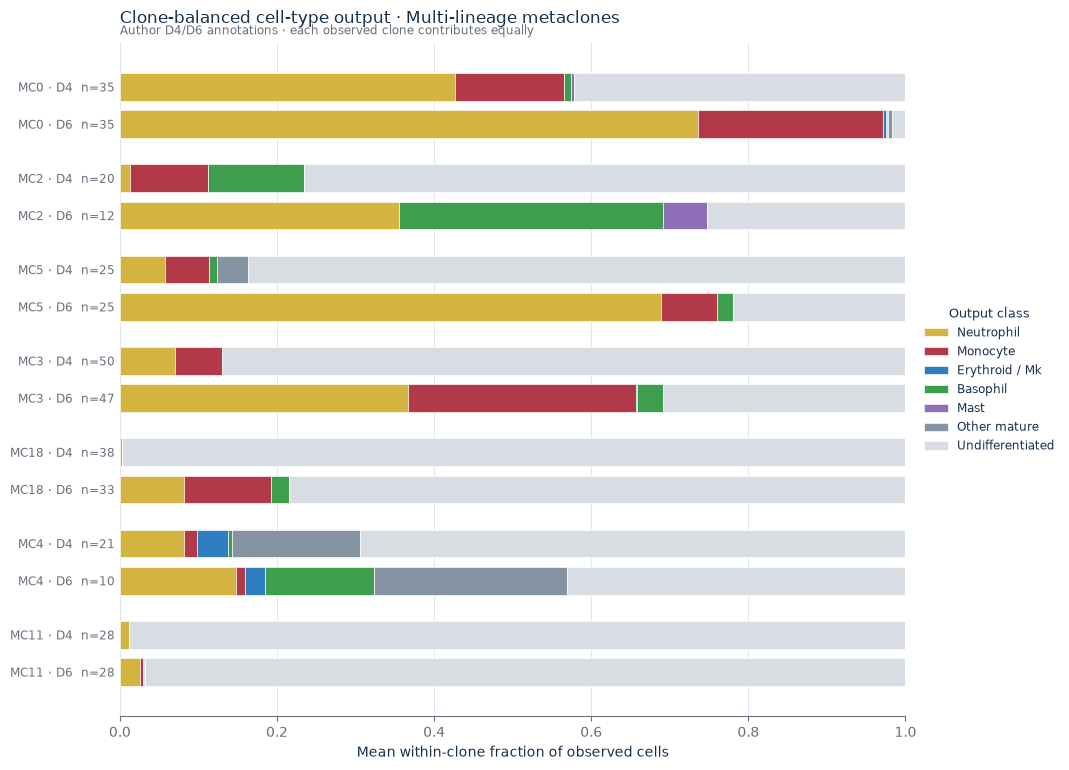

saved: analysis_workspace/analyses/weinreb_day2_hspc_metaclone_gene_programs_20260902/figures/weinreb_day2_hspc_19_multilineage_clone_balanced_outputs.svg | analysis_workspace/analyses/weinreb_day2_hspc_metaclone_gene_programs_20260902/figures/weinreb_day2_hspc_19_multilineage_clone_balanced_outputs.png


In [26]:
# PROGRAM_OUTPUT_PLOT_INLINE_V1 — clone-balanced output composition
plot_stem = "weinreb_day2_hspc_19_multilineage_clone_balanced_outputs"
plot_output_map = {
    "Neutrophil": "Neutrophil",
    "Monocyte": "Monocyte",
    "Meg": "Erythroid / Mk",
    "Erythroid": "Erythroid / Mk",
    "Baso": "Basophil",
    "Mast": "Mast",
    "Eos": "Other mature",
    "Ccr7_DC": "Other mature",
    "Lymphoid": "Other mature",
    "Undifferentiated": "Undifferentiated",
}
plot_output_order = [
    "Neutrophil", "Monocyte", "Erythroid / Mk", "Basophil", "Mast",
    "Other mature", "Undifferentiated",
]
plot_output_colors = {
    "Neutrophil": "#D4B441",
    "Monocyte": "#B23A48",
    "Erythroid / Mk": "#2E7DBF",
    "Basophil": "#3F9E4D",
    "Mast": "#8E6FB8",
    "Other mature": "#8693A3",
    "Undifferentiated": "#D8DDE3",
}
plot_data = multilineage_output_clone_balanced.copy()
plot_data["output_class"] = plot_data.cell_type_weinreb.map(plot_output_map)
plot_data = (
    plot_data.groupby(
        ["metaclone", "day", "output_class"], observed=True
    ).fraction.sum().reset_index()
)
plot_data.to_csv(
    TABLEDIR / f"{plot_stem}_plot_data.csv", index=False
)
plot_row_order = [(mc, day) for mc in MULTI_MCS for day in OUTPUT_DAYS]
plot_matrix = (
    plot_data.pivot_table(
        index=["metaclone", "day"], columns="output_class",
        values="fraction", fill_value=0.0, observed=True
    )
    .reindex(
        index=pd.MultiIndex.from_tuples(
            plot_row_order, names=["metaclone", "day"]
        ),
        columns=plot_output_order,
        fill_value=0.0,
    )
)
plot_support = multilineage_output_support.set_index(
    ["metaclone", "day"]
)
y_positions = []
for mc_index in range(len(MULTI_MCS)):
    base = (len(MULTI_MCS) - 1 - mc_index) * 2.7
    y_positions.extend([base + 0.55, base - 0.55])
y_positions = np.asarray(y_positions, dtype=float)

fig, ax = plt.subplots(figsize=(10.8, 7.8))
left = np.zeros(len(plot_matrix), dtype=float)
for output_class in plot_output_order:
    values = plot_matrix[output_class].to_numpy(float)
    ax.barh(
        y_positions, values, left=left, height=0.82,
        color=plot_output_colors[output_class], edgecolor=WHITE,
        linewidth=0.45, label=output_class,
    )
    left += values
row_labels = [
    f"MC{mc} · D{day}  n={int(plot_support.loc[(mc, day), 'n_clones'])}"
    for mc, day in plot_row_order
]
ax.set_yticks(y_positions, row_labels, fontsize=8.8)
ax.set_xlim(0, 1)
ax.set_xlabel("Mean within-clone fraction of observed cells")
ax.set_title(
    "Clone-balanced cell-type output · Multi-lineage metaclones",
    loc="left", pad=14,
)
ax.text(
    0, 1.012,
    "Author D4/D6 annotations · each observed clone contributes equally",
    transform=ax.transAxes, fontsize=8.6, color=GREY,
)
ax.spines[["top", "right", "left"]].set_visible(False)
ax.tick_params(axis="y", length=0)
ax.grid(axis="x", color=LIGHT_GREY, linewidth=0.7, alpha=0.75)
ax.set_axisbelow(True)
ax.legend(
    title="Output class", loc="center left", bbox_to_anchor=(1.01, 0.5),
    frameon=False, fontsize=8.5, title_fontsize=9,
)
fig.tight_layout()
svg = FIGDIR / f"{plot_stem}.svg"
png = FIGDIR / f"{plot_stem}.png"
fig.savefig(svg, bbox_inches="tight")
fig.savefig(png, dpi=300, bbox_inches="tight")
display(fig)
print("saved:", svg.relative_to(PROJECT_ROOT), "|", png.relative_to(PROJECT_ROOT))
plt.close(fig)

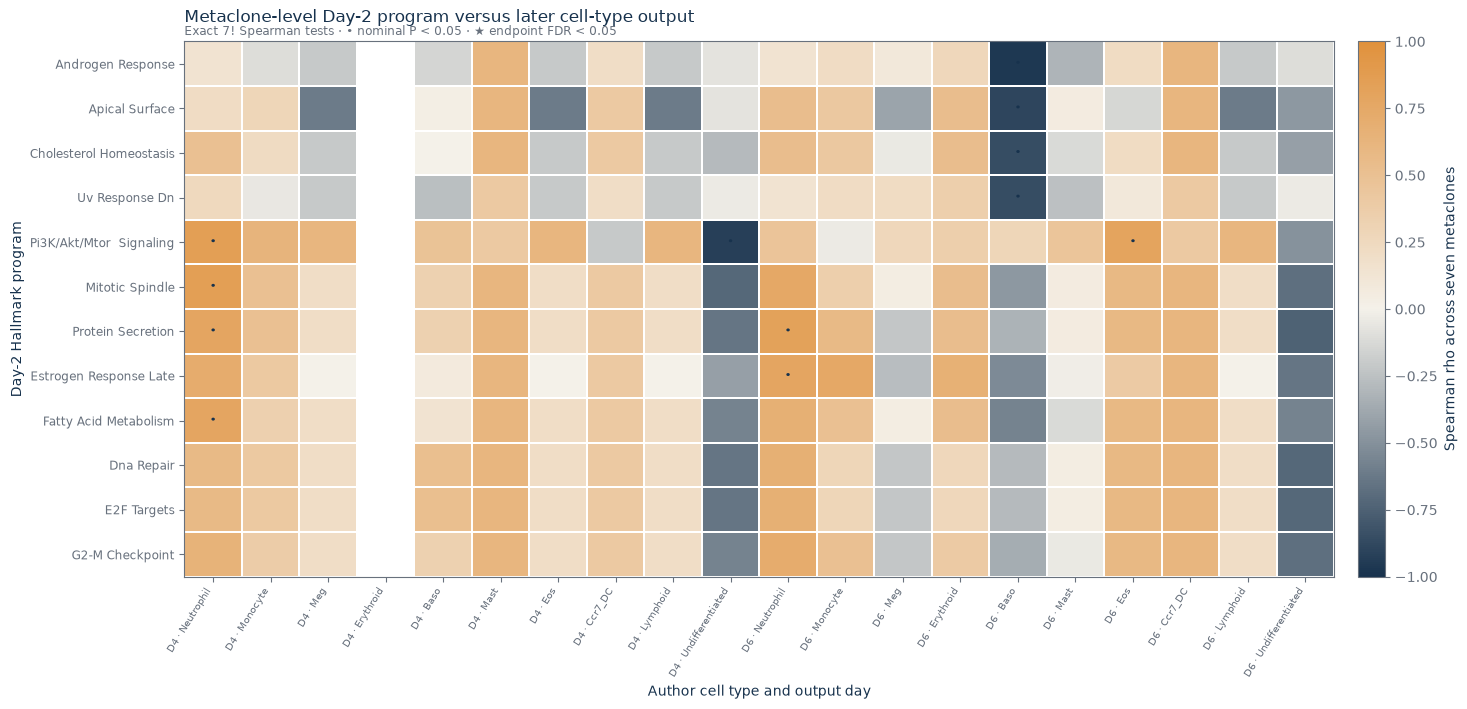

saved: analysis_workspace/analyses/weinreb_day2_hspc_metaclone_gene_programs_20260902/figures/weinreb_day2_hspc_20_multilineage_program_output_correlations.svg | analysis_workspace/analyses/weinreb_day2_hspc_metaclone_gene_programs_20260902/figures/weinreb_day2_hspc_20_multilineage_program_output_correlations.png


In [27]:
# PROGRAM_OUTPUT_PLOT_INLINE_V1 — top exact program/output correlations
plot_stem = "weinreb_day2_hspc_20_multilineage_program_output_correlations"
plot_correlations = primary_correlations[
    primary_correlations.temporal_scope.isin(["Day 4", "Day 6"])
    & primary_correlations.exact_permutation_pvalue.notna()
].copy()
program_priority = (
    plot_correlations.groupby("program", observed=True)
    .agg(
        minimum_endpoint_fdr=("endpoint_fdr", "min"),
        minimum_exact_p=("exact_permutation_pvalue", "min"),
        maximum_abs_rho=("spearman_rho", lambda x: float(np.abs(x).max())),
    )
    .sort_values(
        ["minimum_endpoint_fdr", "minimum_exact_p", "maximum_abs_rho"],
        ascending=[True, True, False],
    )
)
plot_programs = program_priority.head(12).index.tolist()
plot_correlations = plot_correlations[
    plot_correlations.program.isin(plot_programs)
].copy()
plot_correlations["output_time"] = (
    plot_correlations.temporal_scope.str.replace("Day ", "D", regex=False)
    + " · " + plot_correlations.output_type
)
plot_column_order = [
    f"D{day} · {output_type}"
    for day in OUTPUT_DAYS for output_type in AUTHOR_OUTPUT_TYPES
]
plot_matrix = (
    plot_correlations.pivot_table(
        index="program", columns="output_time", values="spearman_rho",
        observed=True
    )
    .reindex(index=plot_programs, columns=plot_column_order)
)
plot_correlations.to_csv(
    TABLEDIR / f"{plot_stem}_plot_data.csv", index=False
)

fig, ax = plt.subplots(figsize=(14.8, 7.2))
mesh = ax.pcolormesh(
    np.arange(plot_matrix.shape[1] + 1),
    np.arange(plot_matrix.shape[0] + 1),
    plot_matrix.to_numpy(float),
    cmap=PROGRAM_CMAP, vmin=-1, vmax=1,
    edgecolors=WHITE, linewidth=0.35, shading="flat",
)
endpoint_hit_lookup = plot_correlations.set_index(
    ["program", "output_time"]
).endpoint_fdr
nominal_lookup = plot_correlations.set_index(
    ["program", "output_time"]
).exact_permutation_pvalue
for row_index, program in enumerate(plot_matrix.index):
    for column_index, output_time in enumerate(plot_matrix.columns):
        endpoint_q = endpoint_hit_lookup.get((program, output_time), np.nan)
        exact_p = nominal_lookup.get((program, output_time), np.nan)
        symbol = (
            "★"
            if np.isfinite(endpoint_q) and endpoint_q < 0.05
            else (
                "•"
                if np.isfinite(exact_p) and exact_p < 0.05
                else ""
            )
        )
        if symbol:
            ax.text(
                column_index + 0.5, row_index + 0.5, symbol,
                ha="center", va="center", fontsize=8.5, color=INK,
            )
ax.set_xticks(
    np.arange(len(plot_column_order)) + 0.5,
    plot_column_order, rotation=58, ha="right", fontsize=7.5,
)
ax.set_yticks(
    np.arange(len(plot_programs)) + 0.5,
    [clean_program_name(program) for program in plot_programs],
    fontsize=8.4,
)
ax.invert_yaxis()
ax.set_xlabel("Author cell type and output day")
ax.set_ylabel("Day-2 Hallmark program")
ax.set_title(
    "Metaclone-level Day-2 program versus later cell-type output",
    loc="left", pad=14,
)
ax.text(
    0, 1.012,
    "Exact 7! Spearman tests · • nominal P < 0.05 · ★ endpoint FDR < 0.05",
    transform=ax.transAxes, fontsize=8.6, color=GREY,
)
colorbar = fig.colorbar(mesh, ax=ax, fraction=0.025, pad=0.02)
colorbar.solids.set_rasterized(False)
colorbar.set_label("Spearman rho across seven metaclones")
fig.tight_layout()
svg = FIGDIR / f"{plot_stem}.svg"
png = FIGDIR / f"{plot_stem}.png"
fig.savefig(svg, bbox_inches="tight")
fig.savefig(png, dpi=300, bbox_inches="tight")
display(fig)
print("saved:", svg.relative_to(PROJECT_ROOT), "|", png.relative_to(PROJECT_ROOT))
plt.close(fig)

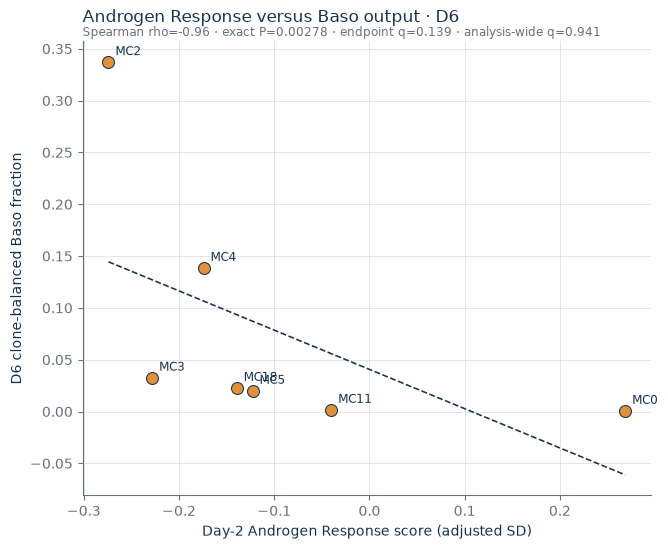

saved: analysis_workspace/analyses/weinreb_day2_hspc_metaclone_gene_programs_20260902/figures/weinreb_day2_hspc_21_multilineage_strongest_program_output_scatter.svg | analysis_workspace/analyses/weinreb_day2_hspc_metaclone_gene_programs_20260902/figures/weinreb_day2_hspc_21_multilineage_strongest_program_output_scatter.png


In [28]:
# PROGRAM_OUTPUT_PLOT_INLINE_V1 — strongest LOMO-stable endpoint association
plot_stem = "weinreb_day2_hspc_21_multilineage_strongest_program_output_scatter"
plot_candidates = primary_correlations[
    primary_correlations.temporal_scope.isin(["Day 4", "Day 6"])
    & primary_correlations.exact_permutation_pvalue.notna()
    & primary_correlations.lomo_sign_stable
].copy()
if plot_candidates.empty:
    plot_candidates = primary_correlations[
        primary_correlations.temporal_scope.isin(["Day 4", "Day 6"])
        & primary_correlations.exact_permutation_pvalue.notna()
    ].copy()
plot_candidates["abs_rho"] = plot_candidates.spearman_rho.abs()
strongest = plot_candidates.sort_values(
    ["analysis_wide_fdr", "endpoint_fdr", "exact_permutation_pvalue", "abs_rho"],
    ascending=[True, True, True, False],
).iloc[0]
plot_day = int(str(strongest.temporal_scope).replace("Day ", ""))
plot_program = str(strongest.program)
plot_output_type = str(strongest.output_type)
plot_x = (
    multilineage_day2_program_means.set_index("metaclone")
    .loc[MULTI_MCS, plot_program]
)
plot_y = (
    multilineage_output_clone_balanced[
        (multilineage_output_clone_balanced.day == plot_day)
        & (multilineage_output_clone_balanced.cell_type_weinreb == plot_output_type)
    ]
    .set_index("metaclone")
    .reindex(MULTI_MCS).fraction
)
plot_data = pd.DataFrame({
    "metaclone": MULTI_MCS,
    "day2_program_score_sd": plot_x.to_numpy(float),
    "clone_balanced_output_fraction": plot_y.to_numpy(float),
    "program": plot_program,
    "output_type": plot_output_type,
    "day": plot_day,
})
plot_data.to_csv(
    TABLEDIR / f"{plot_stem}_plot_data.csv", index=False
)

fig, ax = plt.subplots(figsize=(6.8, 5.6))
ax.scatter(
    plot_data.day2_program_score_sd,
    plot_data.clone_balanced_output_fraction,
    s=74, color=ORANGE, edgecolor=INK, linewidth=0.75, zorder=3,
)
if plot_data.day2_program_score_sd.nunique() > 1:
    slope, intercept = np.polyfit(
        plot_data.day2_program_score_sd,
        plot_data.clone_balanced_output_fraction,
        1,
    )
    x_line = np.linspace(
        plot_data.day2_program_score_sd.min(),
        plot_data.day2_program_score_sd.max(), 100
    )
    ax.plot(
        x_line, intercept + slope * x_line,
        color=INK, linewidth=1.15, linestyle="--", zorder=2,
    )
for row in plot_data.itertuples(index=False):
    ax.annotate(
        f"MC{int(row.metaclone)}",
        (row.day2_program_score_sd, row.clone_balanced_output_fraction),
        xytext=(5, 5), textcoords="offset points", fontsize=8.3,
        color=INK,
    )
ax.set_xlabel(f"Day-2 {clean_program_name(plot_program)} score (adjusted SD)")
ax.set_ylabel(f"D{plot_day} clone-balanced {plot_output_type} fraction")
ax.set_title(
    f"{clean_program_name(plot_program)} versus {plot_output_type} output · D{plot_day}",
    loc="left", pad=14,
)
ax.text(
    0, 1.012,
    (
        f"Spearman rho={strongest.spearman_rho:+.2f} · "
        f"exact P={strongest.exact_permutation_pvalue:.3g} · "
        f"endpoint q={strongest.endpoint_fdr:.3g} · "
        f"analysis-wide q={strongest.analysis_wide_fdr:.3g}"
    ),
    transform=ax.transAxes, fontsize=8.4, color=GREY,
)
ax.grid(color=LIGHT_GREY, linewidth=0.7, alpha=0.75)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
svg = FIGDIR / f"{plot_stem}.svg"
png = FIGDIR / f"{plot_stem}.png"
fig.savefig(svg, bbox_inches="tight")
fig.savefig(png, dpi=300, bbox_inches="tight")
display(fig)
print("saved:", svg.relative_to(PROJECT_ROOT), "|", png.relative_to(PROJECT_ROOT))
plt.close(fig)

## Multi-lineage correlation findings and boundaries

Findings below are generated from the executed result tables. The
distinction between analysis-wide evidence, endpoint-level exploratory
evidence, and nominal rankings is kept explicit.

In [29]:
# Print and save computed findings without hard-coding results in Markdown
valid_primary = primary_correlations[
    primary_correlations.exact_permutation_pvalue.notna()
].copy()
analysis_wide_hits = valid_primary[
    valid_primary.analysis_wide_fdr < 0.05
].copy()
endpoint_hits = valid_primary[
    valid_primary.endpoint_fdr < 0.05
].copy()
stable_endpoint_hits = valid_primary[
    valid_primary.stable_endpoint_association
].copy()
top_correlations = valid_primary.sort_values(
    ["analysis_wide_fdr", "endpoint_fdr", "exact_permutation_pvalue"],
    ascending=True,
).head(12)
output_support_min = int(multilineage_output_support.n_clones.min())
output_support_max = int(multilineage_output_support.n_clones.max())
mature_support_min = int(
    multilineage_output_support.n_mature_informative_clones.min()
)
mature_support_max = int(
    multilineage_output_support.n_mature_informative_clones.max()
)

finding_lines = [
    "OBSERVED METACLONE-LEVEL EVIDENCE",
    (
        f"- Seven current Multi-lineage metaclones were tested with 50 "
        f"library-adjusted Day-2 clone-pseudobulk Hallmark scores."
    ),
    (
        f"- Primary D4/D6 and D6-minus-D4 output correlations: "
        f"{len(primary_correlations)} rows; {len(valid_primary)} estimable; "
        f"{len(analysis_wide_hits)} passed analysis-wide FDR < 0.05; "
        f"{len(endpoint_hits)} passed cell-type/time endpoint FDR < 0.05; "
        f"{len(stable_endpoint_hits)} also retained LOMO sign and pooled-output direction."
    ),
    (
        f"- Observed-clone support per metaclone/day ranged from "
        f"{output_support_min} to {output_support_max}; mature-informative "
        f"clone support ranged from {mature_support_min} to {mature_support_max}."
    ),
]
for row in global_program_output_association.itertuples(index=False):
    finding_lines.append(
        f"- Global {row.estimand}, Day {int(row.day)}: "
        f"distance rho={row.spearman_distance_rho:+.2f}, "
        f"exact P={row.exact_permutation_pvalue:.3g}, "
        f"within-estimand q={row.fdr_within_estimand:.3g}."
    )
finding_lines.append("- Highest-ranked individual correlations:")
for row in top_correlations.itertuples(index=False):
    finding_lines.append(
        f"  - {row.program_label} vs {row.output_type} ({row.temporal_scope}): "
        f"rho={row.spearman_rho:+.2f}, exact P={row.exact_permutation_pvalue:.3g}, "
        f"endpoint q={row.endpoint_fdr:.3g}, analysis-wide q={row.analysis_wide_fdr:.3g}, "
        f"LOMO-sign-stable={bool(row.lomo_sign_stable)}."
    )
finding_lines.extend([
    "",
    "INTERPRETATION BOUNDARIES",
    "- The independent sample size is seven metaclones; exact permutation P-values are discrete and effect sizes are more informative than asymptotic precision.",
    "- Output fractions are compositional, so enrichment of one cell type necessarily reduces at least one other fraction.",
    "- The Multi-lineage family was defined retrospectively from later output; correlations are descriptive associations, not prospective validation.",
    "- Mature-only composition omits clones without a mature sister at that day and is a sensitivity, not the primary estimand.",
    "- Day-6-minus-Day-4 differences compare destructive snapshots with partially different observed-clone cohorts and cannot establish within-clone temporal change.",
])
correlation_findings_text = "\n".join(finding_lines)
(REPORTDIR / "multilineage_program_output_findings_and_boundaries.txt").write_text(
    correlation_findings_text + "\n"
)
print(correlation_findings_text)
display(top_correlations[[
    "temporal_scope", "output_type", "program_label", "spearman_rho",
    "exact_permutation_pvalue", "endpoint_fdr", "analysis_wide_fdr",
    "lomo_sign_stable", "pooled_direction_agrees", "mature_direction_agrees",
]])

OBSERVED METACLONE-LEVEL EVIDENCE
- Seven current Multi-lineage metaclones were tested with 50 library-adjusted Day-2 clone-pseudobulk Hallmark scores.
- Primary D4/D6 and D6-minus-D4 output correlations: 1500 rows; 1450 estimable; 0 passed analysis-wide FDR < 0.05; 0 passed cell-type/time endpoint FDR < 0.05; 0 also retained LOMO sign and pooled-output direction.
- Observed-clone support per metaclone/day ranged from 10 to 50; mature-informative clone support ranged from 1 to 43.
- Global clone_balanced_all_observed_cells, Day 4: distance rho=+0.44, exact P=0.151, within-estimand q=0.277.
- Global clone_balanced_all_observed_cells, Day 6: distance rho=+0.25, exact P=0.277, within-estimand q=0.277.
- Global clone_balanced_mature_only, Day 4: distance rho=-0.36, exact P=0.208, within-estimand q=0.417.
- Global clone_balanced_mature_only, Day 6: distance rho=-0.04, exact P=0.915, within-estimand q=0.915.
- Highest-ranked individual correlations:
  - Androgen Response vs Baso (Day 6): rho

,temporal_scope,output_type,program_label,spearman_rho,exact_permutation_pvalue,endpoint_fdr,analysis_wide_fdr,lomo_sign_stable,pooled_direction_agrees,mature_direction_agrees
714,Day 6,Baso,Androgen Response,-0.964286,0.002778,0.138889,0.940885,True,True,True
1214,Day 6 minus Day 4,Baso,Androgen Response,-0.964286,0.002778,0.138889,0.940885,True,True,True
1264,Day 6 minus Day 4,Mast,Androgen Response,-0.906327,0.009524,0.294785,0.940885,True,True,True
1293,Day 6 minus Day 4,Mast,Bile Acid Metabolism,-0.866921,0.019048,0.294785,0.940885,True,True,True
1261,Day 6 minus Day 4,Mast,Adipogenesis,-0.807813,0.038095,0.294785,0.940885,True,True,True
1278,Day 6 minus Day 4,Mast,Myc Targets V2,-0.807813,0.038095,0.294785,0.940885,True,True,True
1294,Day 6 minus Day 4,Mast,Pperoxisome,-0.807813,0.038095,0.294785,0.940885,True,True,True
1284,Day 6 minus Day 4,Mast,Glycolysis,-0.729002,0.057143,0.294785,0.940885,True,True,True
1252,Day 6 minus Day 4,Mast,Cholesterol Homeostasis,-0.709299,0.085714,0.294785,0.940885,True,True,True
1282,Day 6 minus Day 4,Mast,Fatty Acid Metabolism,-0.709299,0.085714,0.294785,0.940885,True,True,True


## Multi-lineage correlation validation and provenance

This final cell validates the complete metaclone/output grids, exhaustive
permutation implementation, multiplicity fields, physical absence of the
removed analysis, plot-cell contract, editable SVG exports, and artifact
hashes.

In [30]:
# Validate the appended correlation analysis and its reader-facing visibility
built_notebook = nbformat.read(NOTEBOOK_PATH, as_version=4)
notebook_sources = ["".join(cell.get("source", "")) for cell in built_notebook.cells]
removed_tag = "cell-" + "level-not-for-use"
removed_markers = [
    "## Version 2 — " + "cell-level sensitivity",
    "CELL_" + "LEVEL_PLOT_INLINE_V1",
    "cell_" + "level_program_tests",
    "cell_" + "level_gene_tests",
]
removed_marker_hits = [
    marker for marker in removed_markers
    if any(marker in source for source in notebook_sources)
]
removed_tagged_cells = sum(
    removed_tag in cell.metadata.get("tags", [])
    for cell in built_notebook.cells
)
removed_active_artifacts = sorted(
    str(path.relative_to(ANALYSIS_DIR))
    for folder in [FIGDIR, TABLEDIR, REPORTDIR]
    for path in folder.glob("*cell_level*")
)
cell_level_analysis_absent = (
    not removed_marker_hits
    and removed_tagged_cells == 0
    and not removed_active_artifacts
)

correlation_plot_stems = [
    "weinreb_day2_hspc_19_multilineage_clone_balanced_outputs",
    "weinreb_day2_hspc_20_multilineage_program_output_correlations",
    "weinreb_day2_hspc_21_multilineage_strongest_program_output_scatter",
]
correlation_plot_sources = [
    source for source in notebook_sources
    if source.lstrip().startswith("# PROGRAM_OUTPUT_PLOT_INLINE_V1")
]
correlation_plot_contract = all(
    source.count("plt.subplots") == 1
    and source.count("fig.savefig(svg") == 1
    and source.count("fig.savefig(png") == 1
    and source.count("display(fig)") == 1
    and source.count("plt.close(fig)") == 1
    for source in correlation_plot_sources
)
correlation_svg_editable = all(
    "<svg" in (FIGDIR / f"{stem}.svg").read_text(errors="ignore")
    and "<image" not in (FIGDIR / f"{stem}.svg").read_text(errors="ignore")
    for stem in correlation_plot_stems
)
finite_exact_p = primary_correlations.exact_permutation_pvalue.dropna()
exact_p_grid_ok = np.allclose(
    finite_exact_p.to_numpy() * len(PERMUTATION_INDEX),
    np.rint(finite_exact_p.to_numpy() * len(PERMUTATION_INDEX)),
    atol=1e-10,
)
correlation_numeric_probability_columns = [
    "exact_permutation_pvalue", "endpoint_fdr", "temporal_scope_fdr",
    "analysis_wide_fdr",
]
probability_ranges_ok = all(
    primary_correlations[column].dropna().between(0, 1).all()
    for column in correlation_numeric_probability_columns
)
new_table_paths = [
    TABLEDIR / "multilineage_output_support_by_day.csv",
    TABLEDIR / "multilineage_clone_balanced_author_output_by_day.csv",
    TABLEDIR / "multilineage_pooled_cell_author_output_by_day.csv",
    TABLEDIR / "multilineage_clone_balanced_mature_output_by_day.csv",
    TABLEDIR / "multilineage_day2_adjusted_program_means.csv",
    TABLEDIR / "multilineage_program_output_correlations.csv",
    TABLEDIR / "multilineage_program_output_correlation_sensitivities.csv",
    TABLEDIR / "multilineage_program_output_correlation_summary.csv",
    TABLEDIR / "multilineage_program_output_global_association.csv",
] + [TABLEDIR / f"{stem}_plot_data.csv" for stem in correlation_plot_stems]
new_table_headers_exclude_population = all(
    "population" not in pd.read_csv(path, nrows=0).columns
    for path in new_table_paths
)

multilineage_correlation_validation_rows = [
    ("seven_multilineage_metaclones", MULTI_MCS == [0, 2, 5, 3, 18, 4, 11], str(MULTI_MCS)),
    ("output_day_grid_complete", len(multilineage_output_support) == 14, str(multilineage_output_support.shape)),
    ("primary_output_grid_complete", len(multilineage_output_clone_balanced) == 7 * 2 * 10, str(multilineage_output_clone_balanced.shape)),
    ("mature_output_grid_complete", len(multilineage_output_mature_clone_balanced) == 7 * 2 * 9, str(multilineage_output_mature_clone_balanced.shape)),
    ("clone_balanced_fractions_sum_to_one", np.allclose(primary_fraction_sums, 1.0), f"max_error={float(np.max(np.abs(primary_fraction_sums - 1))):.3g}"),
    ("mature_fractions_sum_to_one", np.allclose(mature_fraction_sums, 1.0), f"max_error={float(np.max(np.abs(mature_fraction_sums - 1))):.3g}"),
    ("day2_program_grid_complete", multilineage_day2_program_means.shape == (7, 51), str(multilineage_day2_program_means.shape)),
    ("primary_correlation_grid_complete", len(primary_correlations) == 50 * 10 * 3, f"observed={len(primary_correlations)} expected=1500"),
    ("exhaustive_permutation_grid", PERMUTATION_INDEX.shape == (5040, 7), str(PERMUTATION_INDEX.shape)),
    ("exact_pvalue_grid", exact_p_grid_ok, "all finite exact P values are multiples of 1/5040"),
    ("probability_ranges", probability_ranges_ok, "all finite P/q values within [0,1]"),
    ("global_association_grid", len(global_program_output_association) == 4, str(global_program_output_association.shape)),
    (
        "cell_level_analysis_absent",
        cell_level_analysis_absent,
        f"marker_hits={removed_marker_hits}; tagged_cells={removed_tagged_cells}; active_artifacts={removed_active_artifacts}",
    ),
    ("correlation_plot_cell_count", len(correlation_plot_sources) == len(correlation_plot_stems), f"observed={len(correlation_plot_sources)} expected={len(correlation_plot_stems)}"),
    ("correlation_plot_inline_contract", correlation_plot_contract, "one inline build/save/display/close per plot cell"),
    ("correlation_svg_outputs", all((FIGDIR / f"{stem}.svg").stat().st_size > 0 for stem in correlation_plot_stems), f"expected={len(correlation_plot_stems)}"),
    ("correlation_png_outputs", all((FIGDIR / f"{stem}.png").stat().st_size > 0 for stem in correlation_plot_stems), f"expected={len(correlation_plot_stems)}"),
    ("correlation_svg_editable", correlation_svg_editable, "all new SVGs are vector-only with no embedded image"),
    ("new_tables_exclude_population", new_table_headers_exclude_population, f"checked={len(new_table_paths)}"),
    ("input_landing_zone_empty", not any((PROJECT_ROOT / "Input").iterdir()), "Input/ contains no registered-intake residue"),
]
multilineage_correlation_validation = pd.DataFrame(
    multilineage_correlation_validation_rows,
    columns=["check", "passed", "detail"],
)
multilineage_correlation_validation.to_csv(
    REPORTDIR / "multilineage_program_output_validation.csv", index=False
)
assert multilineage_correlation_validation.passed.all(), (
    multilineage_correlation_validation.loc[
        ~multilineage_correlation_validation.passed
    ]
)

correlation_artifact_paths = [BUILDER_PATH] + new_table_paths
for stem in correlation_plot_stems:
    correlation_artifact_paths.extend([
        FIGDIR / f"{stem}.svg", FIGDIR / f"{stem}.png"
    ])
correlation_artifact_paths.extend([
    REPORTDIR / "multilineage_program_output_findings_and_boundaries.txt",
    REPORTDIR / "multilineage_program_output_validation.csv",
])
multilineage_correlation_manifest = pd.DataFrame([
    {
        "path": str(path.relative_to(PROJECT_ROOT)),
        "bytes": path.stat().st_size,
        "sha256": sha256(path),
    }
    for path in sorted(set(correlation_artifact_paths))
])
multilineage_correlation_manifest.to_csv(
    REPORTDIR / "multilineage_program_output_artifact_manifest.csv",
    index=False,
)

# Refresh the broad manifest only after the correlation outputs and its
# dedicated manifest have reached their delivered state.
active_artifact_paths = []
for folder in [ANALYSIS_DIR / "scripts", FIGDIR, TABLEDIR, REPORTDIR, RESOURCEDIR]:
    for path in sorted(folder.rglob("*")):
        if (path.is_file() and path.name != "artifact_manifest.csv"
                and path.suffix != ".pyc" and "__pycache__" not in path.parts):
            active_artifact_paths.append(path)
artifact_manifest = pd.DataFrame([
    {
        "path": str(path.relative_to(PROJECT_ROOT)),
        "bytes": path.stat().st_size,
        "sha256": sha256(path),
    }
    for path in active_artifact_paths
])
artifact_manifest.to_csv(REPORTDIR / "artifact_manifest.csv", index=False)

display(multilineage_correlation_validation)
display(multilineage_correlation_manifest)
print("All Multi-lineage program-output validation checks passed.")
print("Notebook:", NOTEBOOK_PATH)
print("Environment: chronoclone |", ENV_PATH)
print("Execution command:", EXECUTION_COMMAND)

,check,passed,detail
0,seven_multilineage_metaclones,True,"[0, 2, 5, 3, 18, 4, 11]"
1,output_day_grid_complete,True,"(14, 7)"
2,primary_output_grid_complete,True,"(140, 4)"
3,mature_output_grid_complete,True,"(126, 4)"
4,clone_balanced_fractions_sum_to_one,True,max_error=1.11e-16
5,mature_fractions_sum_to_one,True,max_error=2.22e-16
6,day2_program_grid_complete,True,"(7, 51)"
7,primary_correlation_grid_complete,True,observed=1500 expected=1500
8,exhaustive_permutation_grid,True,"(5040, 7)"
9,exact_pvalue_grid,True,all finite exact P values are multiples of 1/5040


,path,bytes,sha256
0,analysis_workspace/analyses/weinreb_day2_hspc_metac...,192676,31a6e4ac208c03115b828597abd6b86a38adb5a4f07023...
1,analysis_workspace/analyses/weinreb_day2_hspc_metac...,39130,7601494cf846d21e4971ba351ed5cc1c3cf8c966cce205...
2,analysis_workspace/analyses/weinreb_day2_hspc_metac...,351184,7e0a00877fb5f8216573d4668194046f372ee036213616...
3,analysis_workspace/analyses/weinreb_day2_hspc_metac...,128698,583c2cff2bb3d93526e005e4ef2a969ceda27d40ecc9b6...
4,analysis_workspace/analyses/weinreb_day2_hspc_metac...,167342,21950b5c9df64b7452fe43f781da37a4884968ef9754e6...
5,analysis_workspace/analyses/weinreb_day2_hspc_metac...,18756,b1c752ec97c4253fa7afbda4147b9d44eec44aa5b5a550...
6,analysis_workspace/analyses/weinreb_day2_hspc_metac...,3365,1d987e6674c6a8b4efebd6c7dd5f709317da2dd4ae07d5...
7,analysis_workspace/analyses/weinreb_day2_hspc_metac...,1158,ce83245ddb4c878dd094b4a4e13507c96dc68f2a7edb3e...
8,analysis_workspace/analyses/weinreb_day2_hspc_metac...,273546,73e65b5d4d6e68be637b446c607325eed9c97676952789...
9,analysis_workspace/analyses/weinreb_day2_hspc_metac...,3282,c6213d6efc5504713861b88f104db65173e5ffced28dbc...


All Multi-lineage program-output validation checks passed.
Notebook: /path/to/ChronoClone/analysis_workspace/analyses/weinreb_day2_hspc_metaclone_gene_programs_20260902/0001_weinreb_day2_hspc_metaclone_gene_programs.ipynb
Environment: chronoclone | /path/to/ChronoClone/.runtime/chronoclone
Execution command: /path/to/ChronoClone/.runtime/chronoclone/bin/jupyter-nbconvert --to notebook --execute --inplace --ExecutePreprocessor.kernel_name=chronoclone --ExecutePreprocessor.timeout=7200 /path/to/ChronoClone/analysis_workspace/analyses/weinreb_day2_hspc_metaclone_gene_programs_20260902/0001_weinreb_day2_hspc_metaclone_gene_programs.ipynb


## Targeted metaclonal behavior signatures

Four non-exclusive behavioral axes are locked from clone-balanced Day-6
author annotations before their targeted expression contrasts are computed
or inspected. These retrospective, analysis-defined axes are not prospectively
preregistered. The independent expression
unit is one Day-2 pooled-HSPC LARRY clone pseudobulk. The seven Multi-lineage
metaclones contain 217 such units. The gene universe remains the original
group-blind 9,777-gene filter and the program universe remains all 50 fixed
Hallmarks.

A *shared behavioral signature* requires a globally significant equal-MC
focal-pair contrast, same-direction effects in both focal metaclones, a
globally significant max-P conjunction test, same-direction combined and
member effects after removal of every comparator MC, and same-direction
combined and member effects in every estimable leave-one-library-out refit.
Combined-only results are candidates, not shared signatures.

In [31]:
# Lock the seven-MC cohort and behavior-axis registry before targeted tests
TARGET_MCS = [0, 2, 5, 3, 18, 4, 11]
assert TARGET_MCS == MULTI_MCS
BEHAVIOR_AXES = [
    {
        "axis_id": "baso_rich", "axis_label": "Baso-rich",
        "focal_mcs": [2, 4], "output_type": "Baso",
        "threshold": 0.10, "rule": "Day-6 Baso fraction >= 10%",
    },
    {
        "axis_id": "neu_rich", "axis_label": "Neu-rich",
        "focal_mcs": [0, 5], "output_type": "Neutrophil",
        "threshold": 0.60, "rule": "Day-6 Neutrophil fraction >= 60%",
    },
    {
        "axis_id": "mono_rich", "axis_label": "Mono-rich",
        "focal_mcs": [0, 3], "output_type": "Monocyte",
        "threshold": 0.20, "rule": "Day-6 Monocyte fraction >= 20%",
    },
    {
        "axis_id": "persistent_undifferentiated",
        "axis_label": "Persistent-undifferentiated",
        "focal_mcs": [11, 18], "output_type": "Undifferentiated",
        "threshold": 0.75,
        "rule": "Day-6 Undifferentiated fraction >= 75%",
    },
]

day6_output_lookup = (
    multilineage_output_clone_balanced[
        multilineage_output_clone_balanced.day == 6
    ]
    .set_index(["cell_type_weinreb", "metaclone"]).fraction
)
axis_definition_rows = []
axis_registry_rows = []
for axis in BEHAVIOR_AXES:
    fractions = pd.Series({
        mc: float(day6_output_lookup.loc[(axis["output_type"], mc)])
        for mc in TARGET_MCS
    })
    focal = list(axis["focal_mcs"])
    comparators = [mc for mc in TARGET_MCS if mc not in focal]
    assert set(fractions[fractions >= axis["threshold"]].index) == set(focal)
    assert fractions[focal].min() >= axis["threshold"]
    assert fractions[comparators].max() < axis["threshold"]
    axis_definition_rows.append({
        "axis_id": axis["axis_id"], "axis_label": axis["axis_label"],
        "output_type": axis["output_type"], "day": 6,
        "focal_mcs": "|".join(map(str, focal)),
        "comparator_mcs": "|".join(map(str, comparators)),
        "threshold": axis["threshold"], "rule": axis["rule"],
        "focal_min_fraction": float(fractions[focal].min()),
        "focal_max_fraction": float(fractions[focal].max()),
        "next_nonfocal_fraction": float(fractions[comparators].max()),
    })
    for mc in TARGET_MCS:
        axis_registry_rows.append({
            "axis_id": axis["axis_id"], "axis_label": axis["axis_label"],
            "output_type": axis["output_type"], "metaclone": mc,
            "day6_clone_balanced_fraction": float(fractions[mc]),
            "is_focal": mc in focal, "threshold": axis["threshold"],
        })
behavior_axis_definitions = pd.DataFrame(axis_definition_rows)
behavior_axis_registry = pd.DataFrame(axis_registry_rows)
behavior_axis_definitions.to_csv(
    TABLEDIR / "targeted_behavior_axis_definitions.csv", index=False
)
behavior_axis_registry.to_csv(
    TABLEDIR / "targeted_behavior_axis_registry.csv", index=False
)

targeted_ids = pseudobulk_metadata.index[
    pseudobulk_metadata.metaclone.isin(TARGET_MCS)
]
targeted_counts = filtered_counts.loc[targeted_ids].copy()
targeted_metadata = pseudobulk_metadata.loc[targeted_ids].copy()
targeted_metadata["multi_mc_group"] = pd.Categorical(
    targeted_metadata.metaclone.map(lambda value: f"MC{int(value)}"),
    categories=[f"MC{mc}" for mc in TARGET_MCS], ordered=True,
)
assert len(targeted_counts) == len(targeted_metadata) == 217
assert targeted_counts.shape[1] == 9777
assert not targeted_counts.index.duplicated().any()
assert "population" not in targeted_metadata.columns
assert set(targeted_metadata.metaclone.unique()) == set(TARGET_MCS)
targeted_support = (
    targeted_metadata.groupby("metaclone", observed=True)
    .agg(n_clone_pseudobulks=("clone", "nunique"), n_day2_hspc_cells=("n_cells", "sum"))
    .reindex(TARGET_MCS).reset_index()
)
targeted_support.to_csv(
    TABLEDIR / "targeted_multilineage_day2_clone_support.csv", index=False
)
display(behavior_axis_definitions)
display(targeted_support)

,axis_id,axis_label,output_type,day,focal_mcs,comparator_mcs,threshold,rule,focal_min_fraction,focal_max_fraction,next_nonfocal_fraction
0,baso_rich,Baso-rich,Baso,6,2|4,0|5|3|18|11,0.10,Day-6 Baso fraction >= 10%,0.138571,0.337121,0.032673
1,neu_rich,Neu-rich,Neutrophil,6,0|5,2|3|18|4|11,0.60,Day-6 Neutrophil fraction >= 60%,0.689346,0.735351,0.366473
2,mono_rich,Mono-rich,Monocyte,6,0|3,2|5|18|4|11,0.20,Day-6 Monocyte fraction >= 20%,0.235611,0.290727,0.110748
3,persistent_undifferentiated,Persistent-undifferentiated,Undifferentiated,6,11|18,0|2|5|3|4,0.75,Day-6 Undifferentiated fraction >= 75%,0.784925,0.967759,0.431488


,metaclone,n_clone_pseudobulks,n_day2_hspc_cells
0,0,35,55
1,2,20,23
2,5,25,34
3,3,50,63
4,18,38,50
5,4,21,30
6,11,28,35


In [32]:
# Build a full-rank seven-MC design with library fractions only
def select_library_covariates(metadata, factor, suffix):
    metadata = metadata.copy()
    raw_columns = [
        column for column in metadata.columns
        if column.startswith("libfrac__") and not column.endswith("__z")
        and "__loo_" not in column
    ]
    reference = max(
        raw_columns,
        key=lambda column: (
            (metadata.groupby(factor, observed=True)[column].mean() > 0).sum(),
            metadata[column].mean(),
        ),
    )
    candidates = [
        column for column in raw_columns
        if column != reference and metadata[column].std(ddof=0) > 1e-12
    ]
    factor_dummies = pd.get_dummies(
        metadata[factor], drop_first=True, dtype=float
    )
    rank_matrix = np.column_stack([
        np.ones(len(metadata)), factor_dummies.to_numpy(float)
    ])
    selected, dropped = [], []
    for column in candidates:
        z = (
            (metadata[column] - metadata[column].mean())
            / metadata[column].std(ddof=0)
        )
        trial = np.column_stack([rank_matrix, z.to_numpy(float)])
        if np.linalg.matrix_rank(trial) > np.linalg.matrix_rank(rank_matrix):
            name = f"{column}__{suffix}_z"
            metadata[name] = z
            selected.append(name)
            rank_matrix = trial
        else:
            dropped.append(column)
    return metadata, selected, reference, dropped

targeted_metadata, targeted_library_covariates, targeted_reference_library, targeted_dropped = (
    select_library_covariates(targeted_metadata, "multi_mc_group", "multi")
)
targeted_design_formula = "~ " + " + ".join(
    targeted_library_covariates + ["multi_mc_group"]
)
with warnings.catch_warnings(record=True) as targeted_warnings:
    warnings.simplefilter("always")
    dds_targeted = DeseqDataSet(
        counts=targeted_counts.astype(int), metadata=targeted_metadata,
        design=targeted_design_formula, inference=inference,
        quiet=True, refit_cooks=False,
    )
    targeted_design = np.asarray(
        dds_targeted.obsm["design_matrix"], dtype=float
    )
    assert np.linalg.matrix_rank(targeted_design) == targeted_design.shape[1]
    dds_targeted.deseq2()
targeted_fit_audit = pd.DataFrame([{
    "model": "seven_multilineage_metaclones",
    "design": targeted_design_formula,
    "n_clone_pseudobulks": len(targeted_metadata),
    "n_genes": targeted_counts.shape[1],
    "design_rank": int(np.linalg.matrix_rank(targeted_design)),
    "design_columns": int(targeted_design.shape[1]),
    "condition_number": float(np.linalg.cond(targeted_design)),
    "reference_library_fraction": targeted_reference_library,
    "library_covariates": "|".join(targeted_library_covariates),
    "rank_dropped": "|".join(targeted_dropped),
    "warning_count": len(targeted_warnings),
    "warnings": " | ".join(sorted({str(item.message) for item in targeted_warnings})),
}])
targeted_fit_audit.to_csv(
    TABLEDIR / "targeted_seven_mc_model_fit_audit.csv", index=False
)
display(targeted_fit_audit)

,model,design,n_clone_pseudobulks,n_genes,design_rank,design_columns,condition_number,reference_library_fraction,library_covariates,rank_dropped,warning_count,warnings
0,seven_multilineage_metaclones,~ libfrac__LK_d2__multi_z + libfrac__LSK_d2_1_...,217,9777,13,13,10.486875,libfrac__LSK_d2_3,libfrac__LK_d2__multi_z|libfrac__LSK_d2_1__mul...,,0,


In [33]:
# Register explicit target-minus-reference vectors for the primary axes
def explicit_group_mean_vector(dds, factor, levels):
    return np.mean(np.vstack([
        np.asarray(dds.cond(**{factor: level}), dtype=float)
        for level in levels
    ]), axis=0)

def explicit_target_minus_reference(dds, factor, targets, references):
    vector = (
        explicit_group_mean_vector(dds, factor, targets)
        - explicit_group_mean_vector(dds, factor, references)
    )
    design_columns = [
        str(column) for column in dds.obsm["design_matrix"].columns
    ]
    nonfactor_indices = [
        index for index, column in enumerate(design_columns)
        if factor not in column
    ]
    # Equal target/reference means cancel the intercept and every
    # library covariate exactly; only factor coefficients may remain.
    assert np.allclose(vector[nonfactor_indices], 0.0, atol=1e-12)
    if len(targets) == 1 and len(references) == 1:
        assert np.allclose(
            vector,
            np.asarray(dds.contrast(factor, references[0], targets[0]), dtype=float),
            atol=1e-12,
        )
    return vector

targeted_primary_specs = []
for axis in BEHAVIOR_AXES:
    focal_levels = [f"MC{mc}" for mc in axis["focal_mcs"]]
    comparator_mcs = [mc for mc in TARGET_MCS if mc not in axis["focal_mcs"]]
    comparator_levels = [f"MC{mc}" for mc in comparator_mcs]
    targeted_primary_specs.append({
        "analysis": "primary_behavior_axis", "axis_id": axis["axis_id"],
        "axis_label": axis["axis_label"], "role": "combined",
        "member_mc": np.nan, "target_levels": focal_levels,
        "reference_levels": comparator_levels,
        "contrast_id": f"{axis['axis_id']}__focal_pair_vs_other_five",
        "contrast_label": f"{axis['axis_label']}: equal focal pair vs equal other five",
        "vector": explicit_target_minus_reference(
            dds_targeted, "multi_mc_group", focal_levels, comparator_levels
        ),
    })
    for member_mc in axis["focal_mcs"]:
        targeted_primary_specs.append({
            "analysis": "primary_behavior_axis", "axis_id": axis["axis_id"],
            "axis_label": axis["axis_label"], "role": "member",
            "member_mc": member_mc, "target_levels": [f"MC{member_mc}"],
            "reference_levels": comparator_levels,
            "contrast_id": f"{axis['axis_id']}__MC{member_mc}_vs_other_five",
            "contrast_label": f"{axis['axis_label']}: MC{member_mc} vs equal other five",
            "vector": explicit_target_minus_reference(
                dds_targeted, "multi_mc_group", [f"MC{member_mc}"], comparator_levels
            ),
        })

targeted_secondary_specs = [
    {
        "analysis": "secondary_pair", "axis_id": "mc5_vs_mc3_divergence",
        "axis_label": "MC5-MC3 divergence", "role": "secondary",
        "member_mc": np.nan, "target_levels": ["MC5"],
        "reference_levels": ["MC3"], "contrast_id": "MC5_vs_MC3",
        "contrast_label": "MC5 vs MC3",
        "vector": explicit_target_minus_reference(
            dds_targeted, "multi_mc_group", ["MC5"], ["MC3"]
        ),
    },
    {
        "analysis": "secondary_pair", "axis_id": "mc3_vs_mc18_convergence",
        "axis_label": "MC3-MC18 branch-compatibility convergence",
        "role": "secondary", "member_mc": np.nan,
        "target_levels": ["MC3"], "reference_levels": ["MC18"],
        "contrast_id": "MC3_vs_MC18", "contrast_label": "MC3 vs MC18",
        "vector": explicit_target_minus_reference(
            dds_targeted, "multi_mc_group", ["MC3"], ["MC18"]
        ),
    },
]
targeted_specs = targeted_primary_specs + targeted_secondary_specs
targeted_contrast_registry = pd.DataFrame([{
    key: ("|".join(value) if key in {"target_levels", "reference_levels"} else value)
    for key, value in spec.items() if key != "vector"
} for spec in targeted_specs])
assert len(targeted_primary_specs) == 12
assert len(targeted_secondary_specs) == 2
targeted_contrast_registry.to_csv(
    TABLEDIR / "targeted_contrast_registry.csv", index=False
)
display(targeted_contrast_registry)

,analysis,axis_id,axis_label,role,member_mc,target_levels,reference_levels,contrast_id,contrast_label
0,primary_behavior_axis,baso_rich,Baso-rich,combined,NaN,MC2|MC4,MC0|MC5|MC3|MC18|MC11,baso_rich__focal_pair_vs_other_five,Baso-rich: equal focal pair vs equal other five
1,primary_behavior_axis,baso_rich,Baso-rich,member,2.0,MC2,MC0|MC5|MC3|MC18|MC11,baso_rich__MC2_vs_other_five,Baso-rich: MC2 vs equal other five
2,primary_behavior_axis,baso_rich,Baso-rich,member,4.0,MC4,MC0|MC5|MC3|MC18|MC11,baso_rich__MC4_vs_other_five,Baso-rich: MC4 vs equal other five
3,primary_behavior_axis,neu_rich,Neu-rich,combined,NaN,MC0|MC5,MC2|MC3|MC18|MC4|MC11,neu_rich__focal_pair_vs_other_five,Neu-rich: equal focal pair vs equal other five
4,primary_behavior_axis,neu_rich,Neu-rich,member,0.0,MC0,MC2|MC3|MC18|MC4|MC11,neu_rich__MC0_vs_other_five,Neu-rich: MC0 vs equal other five
5,primary_behavior_axis,neu_rich,Neu-rich,member,5.0,MC5,MC2|MC3|MC18|MC4|MC11,neu_rich__MC5_vs_other_five,Neu-rich: MC5 vs equal other five
6,primary_behavior_axis,mono_rich,Mono-rich,combined,NaN,MC0|MC3,MC2|MC5|MC18|MC4|MC11,mono_rich__focal_pair_vs_other_five,Mono-rich: equal focal pair vs equal other five
7,primary_behavior_axis,mono_rich,Mono-rich,member,0.0,MC0,MC2|MC5|MC18|MC4|MC11,mono_rich__MC0_vs_other_five,Mono-rich: MC0 vs equal other five
8,primary_behavior_axis,mono_rich,Mono-rich,member,3.0,MC3,MC2|MC5|MC18|MC4|MC11,mono_rich__MC3_vs_other_five,Mono-rich: MC3 vs equal other five
9,primary_behavior_axis,persistent_undifferentiated,Persistent-undifferentiated,combined,NaN,MC11|MC18,MC0|MC2|MC5|MC3|MC4,persistent_undifferentiated__focal_pair_vs_oth...,Persistent-undifferentiated: equal focal pair ...


In [34]:
# Gene-level DESeq2 effects for combined, member, and secondary contrasts
def targeted_deseq_result(dds, spec):
    stats = DeseqStats(
        dds, contrast=np.asarray(spec["vector"], dtype=float),
        inference=inference, quiet=True, cooks_filter=False,
        independent_filter=False,
    )
    stats.summary()
    result = stats.results_df.reset_index().rename(columns={"index": "gene"})
    if "gene" not in result.columns:
        result = result.rename(columns={result.columns[0]: "gene"})
    result["pvalue"] = result.pvalue.fillna(1.0)
    result["padj"] = result.padj.fillna(1.0)
    for key in [
        "analysis", "axis_id", "axis_label", "role", "member_mc",
        "contrast_id", "contrast_label",
    ]:
        result[key] = spec[key]
    return result

targeted_gene_parts = []
for number, spec in enumerate(targeted_specs, start=1):
    targeted_gene_parts.append(targeted_deseq_result(dds_targeted, spec))
    print(f"targeted DESeq2 contrast {number}/{len(targeted_specs)}: {spec['contrast_id']}")
targeted_gene_all = pd.concat(targeted_gene_parts, ignore_index=True)
assert targeted_gene_all.gene.nunique() == 9777
targeted_gene_all.to_csv(
    TABLEDIR / "targeted_gene_effects_all.csv.gz", index=False, compression="gzip"
)

primary_gene_combined = targeted_gene_all[
    (targeted_gene_all.analysis == "primary_behavior_axis")
    & (targeted_gene_all.role == "combined")
][[
    "axis_id", "axis_label", "gene", "baseMean", "log2FoldChange",
    "lfcSE", "stat", "pvalue", "padj",
]].rename(columns={
    "log2FoldChange": "combined_log2fc", "lfcSE": "combined_lfc_se",
    "stat": "combined_stat", "pvalue": "combined_pvalue",
    "padj": "combined_contrast_fdr",
})
primary_gene_members = targeted_gene_all[
    (targeted_gene_all.analysis == "primary_behavior_axis")
    & (targeted_gene_all.role == "member")
].copy()
member_gene_parts = []
for axis in BEHAVIOR_AXES:
    axis_members = primary_gene_members[
        primary_gene_members.axis_id == axis["axis_id"]
    ]
    left = axis_members[axis_members.member_mc == axis["focal_mcs"][0]][[
        "gene", "log2FoldChange", "lfcSE", "stat", "pvalue", "padj"
    ]].rename(columns={
        "log2FoldChange": "member1_log2fc", "lfcSE": "member1_lfc_se",
        "stat": "member1_stat", "pvalue": "member1_pvalue",
        "padj": "member1_contrast_fdr",
    })
    right = axis_members[axis_members.member_mc == axis["focal_mcs"][1]][[
        "gene", "log2FoldChange", "lfcSE", "stat", "pvalue", "padj"
    ]].rename(columns={
        "log2FoldChange": "member2_log2fc", "lfcSE": "member2_lfc_se",
        "stat": "member2_stat", "pvalue": "member2_pvalue",
        "padj": "member2_contrast_fdr",
    })
    merged = left.merge(right, on="gene", validate="one_to_one")
    merged["axis_id"] = axis["axis_id"]
    merged["member1_mc"] = axis["focal_mcs"][0]
    merged["member2_mc"] = axis["focal_mcs"][1]
    member_gene_parts.append(merged)
member_gene_wide = pd.concat(member_gene_parts, ignore_index=True)
targeted_gene_signatures = primary_gene_combined.merge(
    member_gene_wide, on=["axis_id", "gene"], validate="one_to_one"
)
targeted_gene_signatures["combined_global_fdr"] = bh_adjust(
    targeted_gene_signatures.combined_pvalue.to_numpy(float)
)
targeted_gene_signatures["conjunction_pvalue"] = targeted_gene_signatures[[
    "member1_pvalue", "member2_pvalue"
]].max(axis=1)
targeted_gene_signatures["conjunction_global_fdr"] = bh_adjust(
    targeted_gene_signatures.conjunction_pvalue.to_numpy(float)
)
targeted_gene_signatures["members_same_direction_as_combined"] = (
    (np.sign(targeted_gene_signatures.member1_log2fc)
     == np.sign(targeted_gene_signatures.combined_log2fc))
    & (np.sign(targeted_gene_signatures.member2_log2fc)
       == np.sign(targeted_gene_signatures.combined_log2fc))
    & (targeted_gene_signatures.combined_log2fc != 0)
)
assert len(targeted_gene_signatures) == 4 * 9777
assert targeted_gene_signatures.combined_global_fdr.notna().all()
assert targeted_gene_signatures.conjunction_global_fdr.notna().all()

targeted_secondary_genes = targeted_gene_all[
    targeted_gene_all.analysis == "secondary_pair"
].copy()
targeted_secondary_genes["secondary_global_fdr"] = bh_adjust(
    targeted_secondary_genes.pvalue.to_numpy(float)
)
assert len(targeted_secondary_genes) == 2 * 9777
targeted_secondary_genes.to_csv(
    TABLEDIR / "targeted_secondary_gene_contrasts.csv.gz",
    index=False, compression="gzip",
)

targeted DESeq2 contrast 1/14: baso_rich__focal_pair_vs_other_five


targeted DESeq2 contrast 2/14: baso_rich__MC2_vs_other_five


targeted DESeq2 contrast 3/14: baso_rich__MC4_vs_other_five


targeted DESeq2 contrast 4/14: neu_rich__focal_pair_vs_other_five


targeted DESeq2 contrast 5/14: neu_rich__MC0_vs_other_five


targeted DESeq2 contrast 6/14: neu_rich__MC5_vs_other_five


... (4 outputs left out)

targeted DESeq2 contrast 11/14: persistent_undifferentiated__MC11_vs_other_five


targeted DESeq2 contrast 12/14: persistent_undifferentiated__MC18_vs_other_five


targeted DESeq2 contrast 13/14: MC5_vs_MC3


targeted DESeq2 contrast 14/14: MC3_vs_MC18


In [35]:
# Hallmark effects from the same seven-MC design and explicit vectors
targeted_normed = np.asarray(
    dds_targeted.layers["normed_counts"], dtype=float
)
targeted_log = np.log2(targeted_normed + 1.0)
targeted_gene_mean = targeted_log.mean(axis=0)
targeted_gene_sd = targeted_log.std(axis=0, ddof=1)
targeted_valid_sd = targeted_gene_sd > 1e-12
targeted_gene_z = np.zeros_like(targeted_log, dtype=float)
targeted_gene_z[:, targeted_valid_sd] = (
    (targeted_log[:, targeted_valid_sd] - targeted_gene_mean[targeted_valid_sd])
    / targeted_gene_sd[targeted_valid_sd]
)
fixed_program_indices = {}
for program, requested_genes in hallmark_sets.items():
    fixed_program_indices[program] = sorted({
        index for gene in requested_genes
        for index in upper_to_indices.get(gene, [])
    })
    assert len(fixed_program_indices[program]) >= 10
targeted_program_scores = pd.DataFrame({
    program: targeted_gene_z[:, indices].mean(axis=1)
    for program, indices in fixed_program_indices.items()
}, index=targeted_metadata.index)
targeted_program_scores = (
    (targeted_program_scores - targeted_program_scores.mean(axis=0))
    / targeted_program_scores.std(axis=0, ddof=1)
)
assert np.isfinite(targeted_program_scores.to_numpy()).all()
targeted_program_export = targeted_metadata[[
    "clone", "metaclone", "multi_mc_group", "n_cells"
]].join(targeted_program_scores)
targeted_program_export.to_csv(
    TABLEDIR / "targeted_multilineage_clone_hallmark_program_scores.csv.gz",
    index=False, compression="gzip",
)
targeted_program_design = dds_targeted.obsm["design_matrix"].copy()
assert targeted_program_scores.index.tolist() == targeted_program_design.index.tolist()
targeted_program_fits = {
    program: sm.OLS(
        targeted_program_scores[program].to_numpy(float),
        targeted_program_design.to_numpy(float),
    ).fit(cov_type="HC3")
    for program in program_columns
}
targeted_program_rows = []
for spec in targeted_specs:
    for program, fit_result in targeted_program_fits.items():
        test = fit_result.t_test(np.asarray(spec["vector"], dtype=float))
        targeted_program_rows.append({
            "analysis": spec["analysis"], "axis_id": spec["axis_id"],
            "axis_label": spec["axis_label"], "role": spec["role"],
            "member_mc": spec["member_mc"], "contrast_id": spec["contrast_id"],
            "contrast_label": spec["contrast_label"], "program": program,
            "program_label": clean_program_name(program),
            "effect_sd": float(np.asarray(test.effect).squeeze()),
            "standard_error": float(np.asarray(test.sd).squeeze()),
            "t_stat": float(np.asarray(test.tvalue).squeeze()),
            "pvalue": float(np.asarray(test.pvalue).squeeze()),
        })
targeted_program_all = pd.DataFrame(targeted_program_rows)
assert len(targeted_program_all) == 14 * 50
targeted_program_all.to_csv(
    TABLEDIR / "targeted_hallmark_effects_all.csv", index=False
)

primary_program_combined = targeted_program_all[
    (targeted_program_all.analysis == "primary_behavior_axis")
    & (targeted_program_all.role == "combined")
][[
    "axis_id", "axis_label", "program", "program_label", "effect_sd",
    "standard_error", "t_stat", "pvalue",
]].rename(columns={
    "effect_sd": "combined_effect_sd", "standard_error": "combined_se",
    "t_stat": "combined_t", "pvalue": "combined_pvalue",
})
primary_program_members = targeted_program_all[
    (targeted_program_all.analysis == "primary_behavior_axis")
    & (targeted_program_all.role == "member")
].copy()
member_program_parts = []
for axis in BEHAVIOR_AXES:
    axis_members = primary_program_members[
        primary_program_members.axis_id == axis["axis_id"]
    ]
    left = axis_members[axis_members.member_mc == axis["focal_mcs"][0]][[
        "program", "effect_sd", "standard_error", "t_stat", "pvalue"
    ]].rename(columns={
        "effect_sd": "member1_effect_sd", "standard_error": "member1_se",
        "t_stat": "member1_t", "pvalue": "member1_pvalue",
    })
    right = axis_members[axis_members.member_mc == axis["focal_mcs"][1]][[
        "program", "effect_sd", "standard_error", "t_stat", "pvalue"
    ]].rename(columns={
        "effect_sd": "member2_effect_sd", "standard_error": "member2_se",
        "t_stat": "member2_t", "pvalue": "member2_pvalue",
    })
    merged = left.merge(right, on="program", validate="one_to_one")
    merged["axis_id"] = axis["axis_id"]
    merged["member1_mc"] = axis["focal_mcs"][0]
    merged["member2_mc"] = axis["focal_mcs"][1]
    member_program_parts.append(merged)
member_program_wide = pd.concat(member_program_parts, ignore_index=True)
targeted_program_signatures = primary_program_combined.merge(
    member_program_wide, on=["axis_id", "program"], validate="one_to_one"
)
targeted_program_signatures["combined_global_fdr"] = bh_adjust(
    targeted_program_signatures.combined_pvalue.to_numpy(float)
)
targeted_program_signatures["conjunction_pvalue"] = targeted_program_signatures[[
    "member1_pvalue", "member2_pvalue"
]].max(axis=1)
targeted_program_signatures["conjunction_global_fdr"] = bh_adjust(
    targeted_program_signatures.conjunction_pvalue.to_numpy(float)
)
targeted_program_signatures["members_same_direction_as_combined"] = (
    (np.sign(targeted_program_signatures.member1_effect_sd)
     == np.sign(targeted_program_signatures.combined_effect_sd))
    & (np.sign(targeted_program_signatures.member2_effect_sd)
       == np.sign(targeted_program_signatures.combined_effect_sd))
    & (targeted_program_signatures.combined_effect_sd != 0)
)
assert len(targeted_program_signatures) == 4 * 50

targeted_secondary_programs = targeted_program_all[
    targeted_program_all.analysis == "secondary_pair"
].copy()
targeted_secondary_programs["secondary_global_fdr"] = bh_adjust(
    targeted_secondary_programs.pvalue.to_numpy(float)
)
assert len(targeted_secondary_programs) == 2 * 50
targeted_secondary_programs.to_csv(
    TABLEDIR / "targeted_secondary_hallmark_contrasts.csv", index=False
)
display(targeted_program_signatures.sort_values(
    ["combined_global_fdr", "conjunction_global_fdr"]
).head(20))

,axis_id,axis_label,program,program_label,combined_effect_sd,combined_se,combined_t,combined_pvalue,member1_effect_sd,member1_se,...,member2_effect_sd,member2_se,member2_t,member2_pvalue,member1_mc,member2_mc,combined_global_fdr,conjunction_pvalue,conjunction_global_fdr,members_same_direction_as_combined
61,neu_rich,Neu-rich,Adipogenesis,Adipogenesis,0.586092,0.119554,4.902308,9.471732e-07,0.753980,0.174814,...,0.418204,0.144035,2.903488,0.003690,0,5,0.000113,0.003690,0.246021,True
77,neu_rich,Neu-rich,Myc Targets V1,Myc Targets V1,0.557591,0.114552,4.867596,1.129642e-06,0.734972,0.151679,...,0.380209,0.147758,2.573187,0.010077,0,5,0.000113,0.010077,0.403066,True
78,neu_rich,Neu-rich,Myc Targets V2,Myc Targets V2,0.600612,0.128878,4.660323,3.157140e-06,0.758770,0.188149,...,0.442454,0.150561,2.938691,0.003296,0,5,0.000210,0.003296,0.246021,True
73,neu_rich,Neu-rich,Unfolded Protein Response,Unfolded Protein Response,0.612248,0.141392,4.330151,1.490074e-05,0.720734,0.213224,...,0.503762,0.154389,3.262943,0.001103,0,5,0.000745,0.001103,0.220523,True
83,neu_rich,Neu-rich,Oxidative Phosphorylation,Oxidative Phosphorylation,0.584094,0.137189,4.257583,2.066485e-05,0.716411,0.203294,...,0.451778,0.168793,2.676514,0.007439,0,5,0.000827,0.007439,0.371962,True
82,neu_rich,Neu-rich,Fatty Acid Metabolism,Fatty Acid Metabolism,0.524096,0.129655,4.042227,5.294601e-05,0.759263,0.190313,...,0.288929,0.142314,2.030223,0.042334,0,5,0.001607,0.042334,0.617205,True
75,neu_rich,Neu-rich,mTORC1 Signaling,Mtorc1 Signaling,0.492210,0.122196,4.028043,5.624315e-05,0.796524,0.171087,...,0.187897,0.156149,1.203318,0.228853,0,5,0.001607,0.228853,0.926957,True
58,neu_rich,Neu-rich,G2-M Checkpoint,G2-M Checkpoint,0.468906,0.119480,3.924562,8.688782e-05,0.657905,0.172043,...,0.279908,0.141201,1.982343,0.047441,0,5,0.002172,0.047441,0.632545,True
76,neu_rich,Neu-rich,E2F Targets,E2F Targets,0.457561,0.119181,3.839203,1.234345e-04,0.608819,0.152854,...,0.306303,0.151112,2.026997,0.042663,0,5,0.002743,0.042663,0.617205,True
100,mono_rich,Mono-rich,TNF-alpha Signaling via NF-kB,Tnf-Alpha Signaling Via Nf-Kb,0.532281,0.149854,3.552000,3.823154e-04,0.500343,0.209346,...,0.564220,0.165465,3.409905,0.000650,0,3,0.007646,0.016847,0.481341,True


### Comparator-removal stability

For each behavior axis, each of the five nonfocal metaclones is removed
from the equal-MC reference in turn. The fitted seven-MC coefficient model
is unchanged; only the explicit target-minus-remaining-four estimand is
recalculated. The combined focal-pair effect and both member effects must
retain the primary combined direction for every removal.

In [36]:
# Comparator-drop direction checks for all genes and all Hallmarks
targeted_gene_lfc_coefficients = np.asarray(
    dds_targeted.varm["LFC"], dtype=float
)
assert targeted_gene_lfc_coefficients.shape == (
    targeted_counts.shape[1], targeted_design.shape[1]
)
targeted_gene_names = np.asarray(dds_targeted.var_names.astype(str))
assert np.array_equal(targeted_gene_names, targeted_counts.columns.astype(str))

# Independently reconcile coefficient projection with every primary and
# secondary DESeqStats log2 fold change before using it for sensitivities.
projection_errors = []
for spec in targeted_specs:
    projected = (
        targeted_gene_lfc_coefficients @ np.asarray(spec["vector"], dtype=float)
        / np.log(2)
    )
    observed = (
        targeted_gene_all[targeted_gene_all.contrast_id == spec["contrast_id"]]
        .set_index("gene").reindex(targeted_gene_names).log2FoldChange.to_numpy(float)
    )
    projection_errors.append({
        "contrast_id": spec["contrast_id"],
        "max_abs_log2fc_error": float(np.nanmax(np.abs(projected - observed))),
    })
targeted_projection_audit = pd.DataFrame(projection_errors)
assert (targeted_projection_audit.max_abs_log2fc_error < 1e-10).all()
targeted_projection_audit.to_csv(
    TABLEDIR / "targeted_gene_projection_orientation_audit.csv", index=False
)

comparator_gene_parts = []
comparator_program_rows = []
for axis in BEHAVIOR_AXES:
    focal = list(axis["focal_mcs"])
    comparators = [mc for mc in TARGET_MCS if mc not in focal]
    for omitted_mc in comparators:
        remaining = [mc for mc in comparators if mc != omitted_mc]
        role_targets = [
            ("combined", np.nan, focal),
            ("member1", focal[0], [focal[0]]),
            ("member2", focal[1], [focal[1]]),
        ]
        for role, member_mc, target_mcs in role_targets:
            vector = explicit_target_minus_reference(
                dds_targeted, "multi_mc_group",
                [f"MC{mc}" for mc in target_mcs],
                [f"MC{mc}" for mc in remaining],
            )
            gene_effects = (
                targeted_gene_lfc_coefficients @ vector / np.log(2)
            )
            comparator_gene_parts.append(pd.DataFrame({
                "axis_id": axis["axis_id"], "axis_label": axis["axis_label"],
                "omitted_comparator_mc": omitted_mc,
                "remaining_comparator_mcs": "|".join(map(str, remaining)),
                "role": role, "member_mc": member_mc,
                "gene": targeted_gene_names, "log2fc": gene_effects,
            }))
            for program, fit_result in targeted_program_fits.items():
                comparator_program_rows.append({
                    "axis_id": axis["axis_id"],
                    "axis_label": axis["axis_label"],
                    "omitted_comparator_mc": omitted_mc,
                    "remaining_comparator_mcs": "|".join(map(str, remaining)),
                    "role": role, "member_mc": member_mc,
                    "program": program,
                    "program_label": clean_program_name(program),
                    "effect_sd": float(
                        np.asarray(fit_result.params, dtype=float) @ vector
                    ),
                })
targeted_comparator_gene_effects = pd.concat(
    comparator_gene_parts, ignore_index=True
)
targeted_comparator_program_effects = pd.DataFrame(comparator_program_rows)
assert len(targeted_comparator_gene_effects) == 4 * 5 * 3 * 9777
assert len(targeted_comparator_program_effects) == 4 * 5 * 3 * 50
targeted_comparator_gene_effects.to_csv(
    TABLEDIR / "targeted_comparator_drop_gene_effects.csv.gz",
    index=False, compression="gzip",
)
targeted_comparator_program_effects.to_csv(
    TABLEDIR / "targeted_comparator_drop_hallmark_effects.csv", index=False
)

primary_gene_direction = targeted_gene_signatures[[
    "axis_id", "gene", "combined_log2fc"
]].copy()
comparator_gene_check = targeted_comparator_gene_effects.merge(
    primary_gene_direction, on=["axis_id", "gene"], validate="many_to_one"
)
comparator_gene_check["direction_agrees"] = (
    np.sign(comparator_gene_check.log2fc)
    == np.sign(comparator_gene_check.combined_log2fc)
) & (comparator_gene_check.combined_log2fc != 0)
comparator_gene_stability = (
    comparator_gene_check.groupby(["axis_id", "gene"], observed=True)
    .agg(
        comparator_drop_n_effects=("direction_agrees", "size"),
        comparator_drop_n_direction_agree=("direction_agrees", "sum"),
        comparator_drop_all_same_direction=("direction_agrees", "all"),
    ).reset_index()
)
assert (comparator_gene_stability.comparator_drop_n_effects == 15).all()

primary_program_direction = targeted_program_signatures[[
    "axis_id", "program", "combined_effect_sd"
]].copy()
comparator_program_check = targeted_comparator_program_effects.merge(
    primary_program_direction, on=["axis_id", "program"], validate="many_to_one"
)
comparator_program_check["direction_agrees"] = (
    np.sign(comparator_program_check.effect_sd)
    == np.sign(comparator_program_check.combined_effect_sd)
) & (comparator_program_check.combined_effect_sd != 0)
comparator_program_stability = (
    comparator_program_check.groupby(["axis_id", "program"], observed=True)
    .agg(
        comparator_drop_n_effects=("direction_agrees", "size"),
        comparator_drop_n_direction_agree=("direction_agrees", "sum"),
        comparator_drop_all_same_direction=("direction_agrees", "all"),
    ).reset_index()
)
assert (comparator_program_stability.comparator_drop_n_effects == 15).all()
display(comparator_program_stability.groupby("axis_id", observed=True)
        .comparator_drop_all_same_direction.sum().reset_index())

,axis_id,comparator_drop_all_same_direction
0,baso_rich,15
1,mono_rich,20
2,neu_rich,30
3,persistent_undifferentiated,21


### Leave-one-library-out refits

Each Day-2 library is omitted at the cell level. Counts are re-summed per
surviving LARRY clone, library fractions are recomputed, normalization and
dispersion estimation are rerun, Hallmark scores are rebuilt, and a fresh
full-rank seven-MC model is fitted. This is a genuine data-removal refit,
not a covariate-deletion or existing-pseudobulk influence approximation.

In [37]:
# True cell-removal leave-one-library-out refits
multi_hspc_cells = hspc_cells[
    hspc_cells.metaclone.isin(TARGET_MCS)
].copy()
assert multi_hspc_cells.LARRY_ID.nunique() == 217
filtered_gene_indices = np.flatnonzero(keep_gene.to_numpy())
assert len(filtered_gene_indices) == 9777
fixed_program_indices = {}
for program, requested_genes in hallmark_sets.items():
    fixed_program_indices[program] = sorted({
        index for gene in requested_genes
        for index in upper_to_indices.get(gene, [])
    })
    assert len(fixed_program_indices[program]) >= 10

loo_gene_parts = []
loo_program_rows = []
loo_fit_rows = []
for omitted_library in day2_libraries:
    loo_cells = multi_hspc_cells[
        multi_hspc_cells.Library != omitted_library
    ].copy()
    removed_cells = int((multi_hspc_cells.Library == omitted_library).sum())
    assert removed_cells > 0
    loo_pseudobulk_rows = {}
    loo_metadata_rows = []
    for clone, clone_cells in loo_cells.groupby("LARRY_ID", observed=True):
        assert clone_cells.metaclone.nunique() == 1
        mc = int(clone_cells.metaclone.iloc[0])
        indices = POS.loc[clone_cells.index].to_numpy()
        loo_pseudobulk_rows[str(clone)] = np.asarray(
            COUNTS[indices][:, filtered_gene_indices].sum(axis=0)
        ).ravel().astype(np.int64)
        library_counts = clone_cells.Library.value_counts()
        record = {
            "sample": str(clone), "clone": str(clone),
            "metaclone": mc, "multi_mc_group": f"MC{mc}",
            "n_cells": int(len(clone_cells)),
        }
        for library in day2_libraries:
            record[f"libfrac__{safe_name(library)}"] = float(
                library_counts.get(library, 0) / len(clone_cells)
            )
        loo_metadata_rows.append(record)
    loo_counts = pd.DataFrame(loo_pseudobulk_rows).T
    loo_counts.columns = filtered_counts.columns
    loo_counts.index.name = "sample"
    loo_metadata = (
        pd.DataFrame(loo_metadata_rows).set_index("sample")
        .loc[loo_counts.index]
    )
    loo_metadata["multi_mc_group"] = pd.Categorical(
        loo_metadata.multi_mc_group,
        categories=[f"MC{mc}" for mc in TARGET_MCS], ordered=True,
    )
    assert omitted_library not in set(loo_cells.Library)
    assert set(loo_metadata.metaclone.unique()) == set(TARGET_MCS)
    assert not loo_counts.index.duplicated().any()
    assert loo_counts.shape[1] == 9777
    loo_metadata, loo_covariates, loo_reference, loo_dropped = (
        select_library_covariates(
            loo_metadata, "multi_mc_group", f"loo_{safe_name(omitted_library)}"
        )
    )
    loo_formula = "~ " + " + ".join(
        loo_covariates + ["multi_mc_group"]
    )
    with warnings.catch_warnings(record=True) as loo_warnings:
        warnings.simplefilter("always")
        loo_dds = DeseqDataSet(
            counts=loo_counts.astype(int), metadata=loo_metadata,
            design=loo_formula, inference=inference, quiet=True,
            refit_cooks=False,
        )
        loo_design = np.asarray(
            loo_dds.obsm["design_matrix"], dtype=float
        )
        loo_rank = int(np.linalg.matrix_rank(loo_design))
        assert loo_rank == loo_design.shape[1]
        loo_dds.deseq2()

    loo_lfc_coefficients = np.asarray(loo_dds.varm["LFC"], dtype=float)
    assert loo_lfc_coefficients.shape == (
        9777, loo_design.shape[1]
    )
    loo_normed = np.asarray(loo_dds.layers["normed_counts"], dtype=float)
    loo_log = np.log2(loo_normed + 1.0)
    loo_gene_mean = loo_log.mean(axis=0)
    loo_gene_sd = loo_log.std(axis=0, ddof=1)
    loo_valid_sd = loo_gene_sd > 1e-12
    loo_gene_z = np.zeros_like(loo_log, dtype=float)
    loo_gene_z[:, loo_valid_sd] = (
        (loo_log[:, loo_valid_sd] - loo_gene_mean[loo_valid_sd])
        / loo_gene_sd[loo_valid_sd]
    )
    loo_program_scores = pd.DataFrame({
        program: loo_gene_z[:, indices].mean(axis=1)
        for program, indices in fixed_program_indices.items()
    }, index=loo_metadata.index)
    loo_program_sd = loo_program_scores.std(axis=0, ddof=1)
    loo_program_scores = (
        (loo_program_scores - loo_program_scores.mean(axis=0))
        / loo_program_sd
    )
    assert np.isfinite(loo_program_scores.to_numpy()).all()
    loo_design_frame = loo_dds.obsm["design_matrix"].copy()
    assert loo_design_frame.index.tolist() == loo_program_scores.index.tolist()
    loo_program_fits = {
        program: sm.OLS(
            loo_program_scores[program].to_numpy(float),
            loo_design_frame.to_numpy(float),
        ).fit(cov_type="HC3")
        for program in program_columns
    }

    for axis in BEHAVIOR_AXES:
        focal = list(axis["focal_mcs"])
        comparators = [mc for mc in TARGET_MCS if mc not in focal]
        role_targets = [
            ("combined", np.nan, focal),
            ("member1", focal[0], [focal[0]]),
            ("member2", focal[1], [focal[1]]),
        ]
        for role, member_mc, target_mcs in role_targets:
            vector = explicit_target_minus_reference(
                loo_dds, "multi_mc_group",
                [f"MC{mc}" for mc in target_mcs],
                [f"MC{mc}" for mc in comparators],
            )
            gene_effects = loo_lfc_coefficients @ vector / np.log(2)
            loo_gene_parts.append(pd.DataFrame({
                "omitted_library": omitted_library,
                "axis_id": axis["axis_id"],
                "axis_label": axis["axis_label"],
                "role": role, "member_mc": member_mc,
                "gene": targeted_gene_names,
                "log2fc": gene_effects,
            }))
            for program, fit_result in loo_program_fits.items():
                loo_program_rows.append({
                    "omitted_library": omitted_library,
                    "axis_id": axis["axis_id"],
                    "axis_label": axis["axis_label"],
                    "role": role, "member_mc": member_mc,
                    "program": program,
                    "program_label": clean_program_name(program),
                    "effect_sd": float(
                        np.asarray(fit_result.params, dtype=float) @ vector
                    ),
                })
    loo_fit_rows.append({
        "omitted_library": omitted_library,
        "removed_cells": removed_cells,
        "remaining_cells": int(len(loo_cells)),
        "remaining_clone_pseudobulks": int(len(loo_metadata)),
        "remaining_metaclones": int(loo_metadata.metaclone.nunique()),
        "design": loo_formula, "design_rank": loo_rank,
        "design_columns": int(loo_design.shape[1]),
        "condition_number": float(np.linalg.cond(loo_design)),
        "reference_library_fraction": loo_reference,
        "library_covariates": "|".join(loo_covariates),
        "rank_dropped": "|".join(loo_dropped),
        "warning_count": len(loo_warnings),
        "warnings": " | ".join(sorted({str(item.message) for item in loo_warnings})),
        "estimable": True,
    })
    print(
        f"completed cell-removal/refit LOO: {omitted_library} · "
        f"{len(loo_metadata)} surviving clone pseudobulks"
    )

targeted_library_loo_fit_audit = pd.DataFrame(loo_fit_rows)
targeted_library_loo_gene_effects = pd.concat(loo_gene_parts, ignore_index=True)
targeted_library_loo_program_effects = pd.DataFrame(loo_program_rows)
assert len(targeted_library_loo_fit_audit) == len(day2_libraries) == 7
assert targeted_library_loo_fit_audit.estimable.all()
assert len(targeted_library_loo_gene_effects) == 7 * 4 * 3 * 9777
assert len(targeted_library_loo_program_effects) == 7 * 4 * 3 * 50
targeted_library_loo_fit_audit.to_csv(
    TABLEDIR / "targeted_library_loo_model_fit_audit.csv", index=False
)
targeted_library_loo_gene_effects.to_csv(
    TABLEDIR / "targeted_library_loo_gene_effects.csv.gz",
    index=False, compression="gzip",
)
targeted_library_loo_program_effects.to_csv(
    TABLEDIR / "targeted_library_loo_hallmark_effects.csv", index=False
)
display(targeted_library_loo_fit_audit)

completed cell-removal/refit LOO: LK_d2 · 204 surviving clone pseudobulks


completed cell-removal/refit LOO: LSK_d2_1 · 178 surviving clone pseudobulks


completed cell-removal/refit LOO: LSK_d2_2 · 181 surviving clone pseudobulks


completed cell-removal/refit LOO: LSK_d2_3 · 163 surviving clone pseudobulks


completed cell-removal/refit LOO: d2_1 · 203 surviving clone pseudobulks


completed cell-removal/refit LOO: d2_2 · 203 surviving clone pseudobulks


completed cell-removal/refit LOO: d2_3 · 202 surviving clone pseudobulks


,omitted_library,removed_cells,remaining_cells,remaining_clone_pseudobulks,remaining_metaclones,design,design_rank,design_columns,condition_number,reference_library_fraction,library_covariates,rank_dropped,warning_count,warnings,estimable
0,LK_d2,15,275,204,7,~ libfrac__LSK_d2_1__loo_LK_d2_z + libfrac__LS...,12,12,10.553917,libfrac__LSK_d2_3,libfrac__LSK_d2_1__loo_LK_d2_z|libfrac__LSK_d2...,,0,,True
1,LSK_d2_1,59,231,178,7,~ libfrac__LK_d2__loo_LSK_d2_1_z + libfrac__LS...,12,12,9.896501,libfrac__LSK_d2_3,libfrac__LK_d2__loo_LSK_d2_1_z|libfrac__LSK_d2...,,0,,True
2,LSK_d2_2,62,228,181,7,~ libfrac__LK_d2__loo_LSK_d2_2_z + libfrac__LS...,12,12,10.309319,libfrac__LSK_d2_3,libfrac__LK_d2__loo_LSK_d2_2_z|libfrac__LSK_d2...,,0,,True
3,LSK_d2_3,76,214,163,7,~ libfrac__LK_d2__loo_LSK_d2_3_z + libfrac__LS...,12,12,9.302736,libfrac__LSK_d2_1,libfrac__LK_d2__loo_LSK_d2_3_z|libfrac__LSK_d2...,,0,,True
4,d2_1,21,269,203,7,~ libfrac__LK_d2__loo_d2_1_z + libfrac__LSK_d2...,12,12,10.909046,libfrac__LSK_d2_3,libfrac__LK_d2__loo_d2_1_z|libfrac__LSK_d2_1__...,,0,,True
5,d2_2,28,262,203,7,~ libfrac__LK_d2__loo_d2_2_z + libfrac__LSK_d2...,12,12,10.868552,libfrac__LSK_d2_3,libfrac__LK_d2__loo_d2_2_z|libfrac__LSK_d2_1__...,,0,,True
6,d2_3,29,261,202,7,~ libfrac__LK_d2__loo_d2_3_z + libfrac__LSK_d2...,12,12,10.741515,libfrac__LSK_d2_3,libfrac__LK_d2__loo_d2_3_z|libfrac__LSK_d2_1__...,,0,,True


In [38]:
# Reduce LOO effects to explicit all-estimable-direction Boolean components
loo_gene_check = targeted_library_loo_gene_effects.merge(
    primary_gene_direction, on=["axis_id", "gene"], validate="many_to_one"
)
loo_gene_check["estimable_effect"] = np.isfinite(loo_gene_check.log2fc)
loo_gene_check["direction_agrees"] = (
    loo_gene_check.estimable_effect
    & (np.sign(loo_gene_check.log2fc)
       == np.sign(loo_gene_check.combined_log2fc))
    & (loo_gene_check.combined_log2fc != 0)
)
loo_gene_stability = (
    loo_gene_check.groupby(["axis_id", "gene"], observed=True)
    .agg(
        library_loo_n_requested_effects=("direction_agrees", "size"),
        library_loo_n_estimable_effects=("estimable_effect", "sum"),
        library_loo_n_direction_agree=("direction_agrees", "sum"),
    ).reset_index()
)
loo_gene_stability["library_loo_all_estimable_same_direction"] = (
    (loo_gene_stability.library_loo_n_estimable_effects > 0)
    & (loo_gene_stability.library_loo_n_direction_agree
       == loo_gene_stability.library_loo_n_estimable_effects)
)
loo_gene_stability["library_loo_complete"] = (
    loo_gene_stability.library_loo_n_estimable_effects
    == loo_gene_stability.library_loo_n_requested_effects
)
assert (loo_gene_stability.library_loo_n_requested_effects == 21).all()

loo_program_check = targeted_library_loo_program_effects.merge(
    primary_program_direction,
    on=["axis_id", "program"], validate="many_to_one"
)
loo_program_check["estimable_effect"] = np.isfinite(loo_program_check.effect_sd)
loo_program_check["direction_agrees"] = (
    loo_program_check.estimable_effect
    & (np.sign(loo_program_check.effect_sd)
       == np.sign(loo_program_check.combined_effect_sd))
    & (loo_program_check.combined_effect_sd != 0)
)
loo_program_stability = (
    loo_program_check.groupby(["axis_id", "program"], observed=True)
    .agg(
        library_loo_n_requested_effects=("direction_agrees", "size"),
        library_loo_n_estimable_effects=("estimable_effect", "sum"),
        library_loo_n_direction_agree=("direction_agrees", "sum"),
    ).reset_index()
)
loo_program_stability["library_loo_all_estimable_same_direction"] = (
    (loo_program_stability.library_loo_n_estimable_effects > 0)
    & (loo_program_stability.library_loo_n_direction_agree
       == loo_program_stability.library_loo_n_estimable_effects)
)
loo_program_stability["library_loo_complete"] = (
    loo_program_stability.library_loo_n_estimable_effects
    == loo_program_stability.library_loo_n_requested_effects
)
assert (loo_program_stability.library_loo_n_requested_effects == 21).all()

targeted_gene_signatures = (
    targeted_gene_signatures
    .merge(comparator_gene_stability, on=["axis_id", "gene"], validate="one_to_one")
    .merge(loo_gene_stability, on=["axis_id", "gene"], validate="one_to_one")
)
targeted_program_signatures = (
    targeted_program_signatures
    .merge(comparator_program_stability, on=["axis_id", "program"], validate="one_to_one")
    .merge(loo_program_stability, on=["axis_id", "program"], validate="one_to_one")
)
for result in [targeted_gene_signatures, targeted_program_signatures]:
    result["combined_global_fdr_pass"] = result.combined_global_fdr < 0.05
    result["conjunction_global_fdr_pass"] = result.conjunction_global_fdr < 0.05
    member1_effect = (
        result.member1_log2fc if "member1_log2fc" in result.columns
        else result.member1_effect_sd
    )
    member2_effect = (
        result.member2_log2fc if "member2_log2fc" in result.columns
        else result.member2_effect_sd
    )
    combined_effect = (
        result.combined_log2fc if "combined_log2fc" in result.columns
        else result.combined_effect_sd
    )
    result["member1_nominal_same_direction"] = (
        (result.member1_pvalue < 0.05)
        & (np.sign(member1_effect) == np.sign(combined_effect))
    )
    result["member2_nominal_same_direction"] = (
        (result.member2_pvalue < 0.05)
        & (np.sign(member2_effect) == np.sign(combined_effect))
    )
    result["member_conjunction_not_supported"] = (
        result.combined_global_fdr_pass
        & ~result.conjunction_global_fdr_pass
    )
    result["opposing_member_direction"] = (
        result.combined_global_fdr_pass
        & ~result.members_same_direction_as_combined
    )
    result["shared_behavioral_signature"] = (
        result.combined_global_fdr_pass
        & result.members_same_direction_as_combined
        & result.conjunction_global_fdr_pass
        & result.comparator_drop_all_same_direction
        & result.library_loo_all_estimable_same_direction
    )
    result["pooled_only_candidate"] = (
        result.combined_global_fdr_pass
        & ~result.shared_behavioral_signature
    )
    result["one_metaclone_driven"] = (
        result.combined_global_fdr_pass
        & result.members_same_direction_as_combined
        & (result.member1_nominal_same_direction
           ^ result.member2_nominal_same_direction)
    )
    result["pooled_only_failure_reason"] = np.select(
        [
            ~result.combined_global_fdr_pass,
            result.opposing_member_direction,
            result.one_metaclone_driven,
            result.member_conjunction_not_supported,
            ~result.comparator_drop_all_same_direction,
            ~result.library_loo_all_estimable_same_direction,
        ],
        [
            "combined_global_fdr_not_supported",
            "member_direction_disagreement",
            "exactly_one_member_nominal_same_direction",
            "global_max_p_conjunction_not_supported",
            "comparator_drop_direction_unstable",
            "library_loo_direction_unstable",
        ],
        default="all_shared_signature_gates_pass",
    )

targeted_gene_signatures.to_csv(
    TABLEDIR / "targeted_behavior_gene_signatures.csv.gz",
    index=False, compression="gzip",
)
targeted_program_signatures.to_csv(
    TABLEDIR / "targeted_behavior_hallmark_signatures.csv", index=False
)
targeted_signature_summary = pd.concat([
    targeted_gene_signatures.assign(feature_type="gene", feature=targeted_gene_signatures.gene),
    targeted_program_signatures.assign(feature_type="Hallmark", feature=targeted_program_signatures.program_label),
], ignore_index=True, sort=False).groupby(
    ["feature_type", "axis_id", "axis_label"], observed=True
).agg(
    n_tests=("feature", "size"),
    n_combined_global_fdr=("combined_global_fdr_pass", "sum"),
    n_conjunction_global_fdr=("conjunction_global_fdr_pass", "sum"),
    n_shared_signatures=("shared_behavioral_signature", "sum"),
    n_pooled_only_candidates=("pooled_only_candidate", "sum"),
    n_one_metaclone_driven=("one_metaclone_driven", "sum"),
    n_comparator_stable=("comparator_drop_all_same_direction", "sum"),
    n_library_loo_stable=("library_loo_all_estimable_same_direction", "sum"),
).reset_index()
targeted_signature_summary.to_csv(
    TABLEDIR / "targeted_behavior_signature_summary.csv", index=False
)
display(targeted_signature_summary)

,feature_type,axis_id,axis_label,n_tests,n_combined_global_fdr,n_conjunction_global_fdr,n_shared_signatures,n_pooled_only_candidates,n_one_metaclone_driven,n_comparator_stable,n_library_loo_stable
0,Hallmark,baso_rich,Baso-rich,50,2,0,0,2,1,15,6
1,Hallmark,mono_rich,Mono-rich,50,8,0,0,8,4,20,13
2,Hallmark,neu_rich,Neu-rich,50,17,0,0,17,9,30,24
3,Hallmark,persistent_undifferentiated,Persistent-undifferentiated,50,13,0,0,13,11,21,18
4,gene,baso_rich,Baso-rich,9777,0,0,0,0,0,2665,1252
5,gene,mono_rich,Mono-rich,9777,0,0,0,0,0,4851,2952
6,gene,neu_rich,Neu-rich,9777,7,0,0,7,0,6446,3690
7,gene,persistent_undifferentiated,Persistent-undifferentiated,9777,1,0,0,1,0,6608,5384


### Direction and adjusted-mean reconciliation

Every primary combined effect is independently reconstructed as the mean
adjusted focal-MC profile minus the mean adjusted comparator-MC profile.
This validates both the contrast vectors and the labels used downstream.

In [39]:
# Reconcile target-minus-reference effects with adjusted MC means
targeted_condition_rows = {
    mc: np.asarray(
        dds_targeted.cond(multi_mc_group=f"MC{mc}"), dtype=float
    )
    for mc in TARGET_MCS
}
targeted_program_adjusted_means = pd.DataFrame({
    mc: {
        program: float(
            targeted_condition_rows[mc]
            @ np.asarray(fit_result.params, dtype=float)
        )
        for program, fit_result in targeted_program_fits.items()
    }
    for mc in TARGET_MCS
}).T
targeted_program_adjusted_means.index.name = "metaclone"
targeted_program_adjusted_means.reset_index().to_csv(
    TABLEDIR / "targeted_adjusted_hallmark_means_by_metaclone.csv", index=False
)
targeted_gene_adjusted_means = pd.DataFrame(
    {
        mc: (
            targeted_gene_lfc_coefficients @ targeted_condition_rows[mc]
            / np.log(2)
        )
        for mc in TARGET_MCS
    },
    index=targeted_gene_names,
)
targeted_gene_adjusted_means.index.name = "gene"

adjusted_mean_audit_rows = []
targeted_vector_audit_rows = []
for spec in targeted_specs:
    target_mcs = [int(level.replace("MC", "")) for level in spec["target_levels"]]
    reference_mcs = [int(level.replace("MC", "")) for level in spec["reference_levels"]]
    vector = np.asarray(spec["vector"], dtype=float)
    design_columns = [str(column) for column in dds_targeted.obsm["design_matrix"].columns]
    nonfactor = [index for index, column in enumerate(design_columns) if "multi_mc_group" not in column]
    targeted_vector_audit_rows.append({
        "axis_id": spec["axis_id"],
        "role": spec["role"],
        "contrast_id": spec["contrast_id"],
        "intercept_and_library_max_abs_weight": float(
            np.max(np.abs(vector[nonfactor]))
        ),
        "target_minus_reference_vector_verified": bool(
            np.max(np.abs(vector[nonfactor])) < 1e-12
        ),
    })

    program_expected = (
        targeted_program_adjusted_means.loc[target_mcs].mean(axis=0)
        - targeted_program_adjusted_means.loc[reference_mcs].mean(axis=0)
    )
    program_observed = (
        targeted_program_all[
            targeted_program_all.contrast_id == spec["contrast_id"]
        ].set_index("program").effect_sd
    )
    gene_expected = (
        targeted_gene_adjusted_means[target_mcs].mean(axis=1)
        - targeted_gene_adjusted_means[reference_mcs].mean(axis=1)
    )
    gene_observed = (
        targeted_gene_all[
            targeted_gene_all.contrast_id == spec["contrast_id"]
        ].set_index("gene").log2FoldChange
    )
    adjusted_mean_audit_rows.append({
        "axis_id": spec["axis_id"],
        "role": spec["role"],
        "contrast_id": spec["contrast_id"],
        "n_target_mcs": len(target_mcs),
        "n_reference_mcs": len(reference_mcs),
        "n_programs": len(program_expected),
        "program_max_abs_error": float(
            (program_expected - program_observed.reindex(program_expected.index)).abs().max()
        ),
        "n_genes": len(gene_expected),
        "gene_max_abs_error": float(
            (gene_expected - gene_observed.reindex(gene_expected.index)).abs().max()
        ),
    })
targeted_adjusted_mean_orientation_audit = pd.DataFrame(adjusted_mean_audit_rows)
targeted_vector_neutrality_audit = pd.DataFrame(targeted_vector_audit_rows)
assert len(targeted_adjusted_mean_orientation_audit) == len(targeted_specs) == 14
assert len(targeted_vector_neutrality_audit) == len(targeted_specs)
assert (targeted_adjusted_mean_orientation_audit.program_max_abs_error < 1e-10).all()
assert (targeted_adjusted_mean_orientation_audit.gene_max_abs_error < 1e-10).all()
assert targeted_vector_neutrality_audit.target_minus_reference_vector_verified.all()
targeted_adjusted_mean_orientation_audit.to_csv(
    TABLEDIR / "targeted_adjusted_mean_orientation_audit.csv", index=False
)
targeted_vector_neutrality_audit.to_csv(
    TABLEDIR / "targeted_vector_neutrality_audit.csv", index=False
)
display(targeted_adjusted_mean_orientation_audit)

,axis_id,role,contrast_id,n_target_mcs,n_reference_mcs,n_programs,program_max_abs_error,n_genes,gene_max_abs_error
0,baso_rich,combined,baso_rich__focal_pair_vs_other_five,2,5,50,8.326673e-17,9777,1.026956e-15
1,baso_rich,member,baso_rich__MC2_vs_other_five,1,5,50,1.110223e-16,9777,1.096345e-15
2,baso_rich,member,baso_rich__MC4_vs_other_five,1,5,50,6.245005e-17,9777,1.026956e-15
3,neu_rich,combined,neu_rich__focal_pair_vs_other_five,2,5,50,1.110223e-16,9777,1.106754e-15
4,neu_rich,member,neu_rich__MC0_vs_other_five,1,5,50,1.110223e-16,9777,9.992007e-16
5,neu_rich,member,neu_rich__MC5_vs_other_five,1,5,50,1.110223e-16,9777,1.179612e-15
6,mono_rich,combined,mono_rich__focal_pair_vs_other_five,2,5,50,5.551115e-17,9777,1.276756e-15
7,mono_rich,member,mono_rich__MC0_vs_other_five,1,5,50,1.110223e-16,9777,1.165734e-15
8,mono_rich,member,mono_rich__MC3_vs_other_five,1,5,50,1.110223e-16,9777,1.387779e-15
9,persistent_undifferentiated,combined,persistent_undifferentiated__focal_pair_vs_oth...,2,5,50,5.551115e-17,9777,1.287165e-15


### Targeted preranked Hallmark sensitivity

DESeq2 Wald statistics provide full-gene rankings for the four combined
behavior-axis contrasts and two secondary MC contrasts. GSEA uses the fixed
Hallmark resource and independent global BH families of 200 primary tests
and 100 secondary tests. This is supporting pathway sensitivity, not an
independent dataset.

In [40]:
# Preranked GSEA for four primary combined axes and two secondary contrasts
targeted_gsea_source = targeted_gene_all[
    ((targeted_gene_all.analysis == "primary_behavior_axis")
     & (targeted_gene_all.role == "combined"))
    | (targeted_gene_all.analysis == "secondary_pair")
].copy()
targeted_gsea_parts = []
for number, contrast_id in enumerate(
    targeted_gsea_source.contrast_id.unique(), start=1
):
    contrast_rows = targeted_gsea_source[
        targeted_gsea_source.contrast_id == contrast_id
    ].copy()
    ranked = contrast_rows[["gene", "stat"]].copy()
    ranked["gene_upper"] = ranked.gene.astype(str).str.upper()
    ranked["abs_stat"] = ranked.stat.abs().fillna(-np.inf)
    ranked = (
        ranked.sort_values(["abs_stat", "gene_upper"], ascending=[False, True])
        .drop_duplicates("gene_upper", keep="first")
    )
    ranked["rank_stat"] = ranked.stat.fillna(0.0)
    ranked = ranked.sort_values(
        ["rank_stat", "gene_upper"], ascending=[False, True]
    ).reset_index(drop=True)
    # Resolve exact ties deterministically at machine precision so GSEA
    # never inherits an arbitrary gene order or emits tie warnings.
    rank_values = ranked.rank_stat.to_numpy(float)
    for position in range(1, len(rank_values)):
        if rank_values[position] >= rank_values[position - 1]:
            rank_values[position] = np.nextafter(
                rank_values[position - 1], -np.inf
            )
    assert pd.Series(rank_values).is_unique
    assert np.all(np.diff(rank_values) < 0)
    rank_series = pd.Series(
        rank_values, index=ranked.gene_upper, name="wald_stat",
    )
    prerank = gp.prerank(
        rnk=rank_series, gene_sets=str(HALLMARK_LOCAL), min_size=10,
        max_size=500, permutation_num=1000, seed=20260903,
        threads=1, outdir=None, no_plot=True, verbose=False,
    )
    terms = prerank.res2d.copy()
    for column in ["ES", "NES", "NOM p-val", "FDR q-val", "FWER p-val"]:
        terms[column] = pd.to_numeric(terms[column], errors="coerce")
    source = contrast_rows.iloc[0]
    terms["analysis"] = source.analysis
    terms["axis_id"] = source.axis_id
    terms["axis_label"] = source.axis_label
    terms["contrast_id"] = contrast_id
    terms["contrast_label"] = source.contrast_label
    terms["gmt_sha256"] = hallmark_source_hash
    targeted_gsea_parts.append(terms)
    print(f"targeted GSEA {number}/6: {contrast_id}")
targeted_gsea = pd.concat(targeted_gsea_parts, ignore_index=True)
targeted_gsea["global_family"] = np.where(
    targeted_gsea.analysis == "primary_behavior_axis",
    "four_primary_axes", "two_secondary_pairs",
)
targeted_gsea["global_fdr_from_nominal_p"] = (
    targeted_gsea.groupby("global_family", observed=True, group_keys=False)["NOM p-val"]
    .transform(bh_adjust)
)
assert len(targeted_gsea[targeted_gsea.global_family == "four_primary_axes"]) == 200
assert len(targeted_gsea[targeted_gsea.global_family == "two_secondary_pairs"]) == 100
targeted_gsea.to_csv(
    TABLEDIR / "targeted_hallmark_preranked_gsea.csv.gz",
    index=False, compression="gzip",
)
targeted_gsea_summary = (
    targeted_gsea.groupby(["global_family", "axis_id", "axis_label"], observed=True)
    .agg(
        n_programs=("Term", "size"),
        n_contrast_fdr_lt_0_25=("FDR q-val", lambda values: int((values < 0.25).sum())),
        n_global_fdr_lt_0_05=("global_fdr_from_nominal_p", lambda values: int((values < 0.05).sum())),
    ).reset_index()
)
targeted_gsea_summary.to_csv(
    TABLEDIR / "targeted_hallmark_preranked_gsea_summary.csv", index=False
)
display(targeted_gsea_summary)

targeted GSEA 1/6: baso_rich__focal_pair_vs_other_five


targeted GSEA 2/6: neu_rich__focal_pair_vs_other_five


targeted GSEA 3/6: mono_rich__focal_pair_vs_other_five


targeted GSEA 4/6: persistent_undifferentiated__focal_pair_vs_other_five


targeted GSEA 5/6: MC5_vs_MC3


targeted GSEA 6/6: MC3_vs_MC18


,global_family,axis_id,axis_label,n_programs,n_contrast_fdr_lt_0_25,n_global_fdr_lt_0_05
0,four_primary_axes,baso_rich,Baso-rich,50,3,3
1,four_primary_axes,mono_rich,Mono-rich,50,10,5
2,four_primary_axes,neu_rich,Neu-rich,50,22,12
3,four_primary_axes,persistent_undifferentiated,Persistent-undifferentiated,50,20,11
4,two_secondary_pairs,mc3_vs_mc18_convergence,MC3-MC18 branch-compatibility convergence,50,12,9
5,two_secondary_pairs,mc5_vs_mc3_divergence,MC5-MC3 divergence,50,17,11


## Manuscript Figure 4 panels

Each panel is constructed, saved, and displayed in its own code cell.
SVGs retain editable text and vector marks. Panels 4E and 4F re-express the
corrected matched-output monocyte and neutrophil landscapes under explicit
manuscript stems.

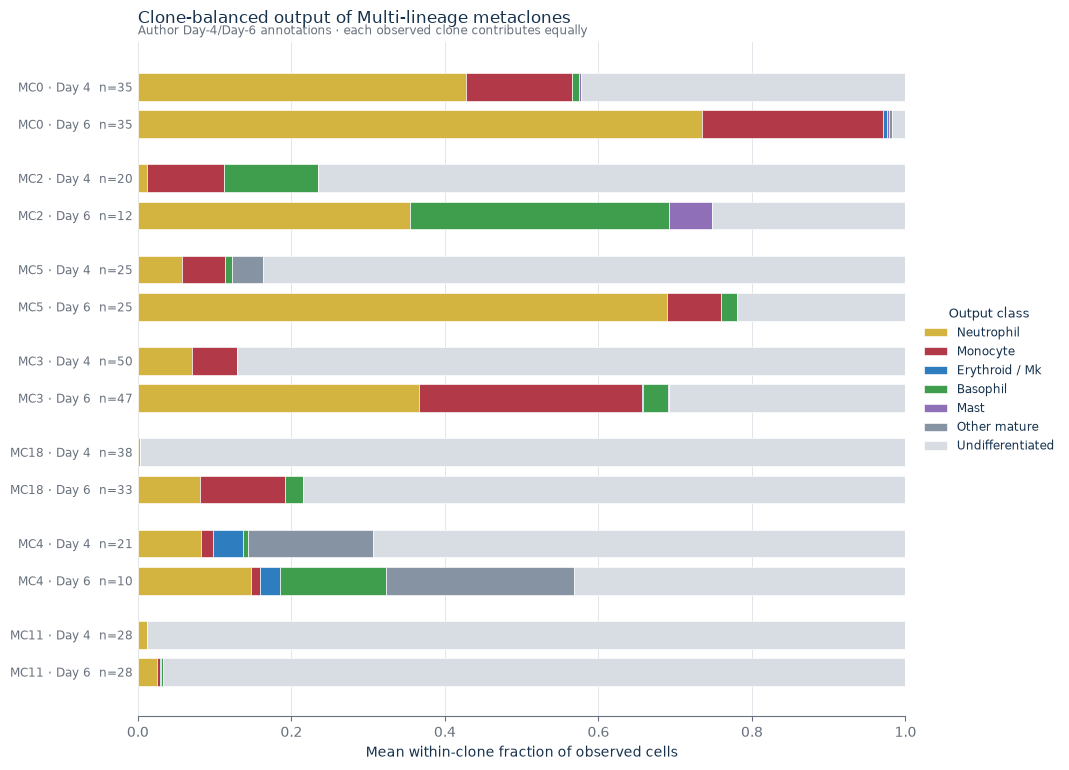

saved: analysis_workspace/analyses/weinreb_day2_hspc_metaclone_gene_programs_20260902/figures/targeted_figure_4a_multilineage_day4_day6_output_composition.svg | analysis_workspace/analyses/weinreb_day2_hspc_metaclone_gene_programs_20260902/figures/targeted_figure_4a_multilineage_day4_day6_output_composition.png


In [41]:
# TARGETED_MAIN_PLOT_INLINE_V1 — Figure 4A
plot_stem = "targeted_figure_4a_multilineage_day4_day6_output_composition"
plot_output_map = {
    "Neutrophil": "Neutrophil", "Monocyte": "Monocyte",
    "Meg": "Erythroid / Mk", "Erythroid": "Erythroid / Mk",
    "Baso": "Basophil", "Mast": "Mast", "Eos": "Other mature",
    "Ccr7_DC": "Other mature", "Lymphoid": "Other mature",
    "Undifferentiated": "Undifferentiated",
}
plot_output_order = [
    "Neutrophil", "Monocyte", "Erythroid / Mk", "Basophil",
    "Mast", "Other mature", "Undifferentiated",
]
plot_output_colors = {
    "Neutrophil": "#D4B441", "Monocyte": "#B23A48",
    "Erythroid / Mk": "#2E7DBF", "Basophil": "#3F9E4D",
    "Mast": "#8E6FB8", "Other mature": "#8693A3",
    "Undifferentiated": "#D8DDE3",
}
plot_data = multilineage_output_clone_balanced.copy()
plot_data["output_class"] = plot_data.cell_type_weinreb.map(plot_output_map)
plot_data = (
    plot_data.groupby(["metaclone", "day", "output_class"], observed=True)
    .fraction.sum().reset_index()
)
plot_data.to_csv(TABLEDIR / f"{plot_stem}_plot_data.csv", index=False)
plot_row_order = [(mc, day) for mc in TARGET_MCS for day in [4, 6]]
plot_matrix = (
    plot_data.pivot_table(
        index=["metaclone", "day"], columns="output_class",
        values="fraction", fill_value=0.0, observed=True,
    ).reindex(
        index=pd.MultiIndex.from_tuples(
            plot_row_order, names=["metaclone", "day"]
        ), columns=plot_output_order, fill_value=0.0,
    )
)
plot_support = multilineage_output_support.set_index(["metaclone", "day"])
y_positions = []
for mc_index in range(len(TARGET_MCS)):
    base = (len(TARGET_MCS) - 1 - mc_index) * 2.7
    y_positions.extend([base + 0.55, base - 0.55])
y_positions = np.asarray(y_positions, dtype=float)
fig, ax = plt.subplots(figsize=(10.8, 7.8))
left = np.zeros(len(plot_matrix), dtype=float)
for output_class in plot_output_order:
    values = plot_matrix[output_class].to_numpy(float)
    ax.barh(
        y_positions, values, left=left, height=0.82,
        color=plot_output_colors[output_class], edgecolor=WHITE,
        linewidth=0.45, label=output_class,
    )
    left += values
row_labels = [
    f"MC{mc} · Day {day}  n={int(plot_support.loc[(mc, day), 'n_clones'])}"
    for mc, day in plot_row_order
]
ax.set_yticks(y_positions, row_labels, fontsize=8.8)
ax.set_xlim(0, 1)
ax.set_xlabel("Mean within-clone fraction of observed cells")
ax.set_title("Clone-balanced output of Multi-lineage metaclones", loc="left", pad=14)
ax.text(
    0, 1.012, "Author Day-4/Day-6 annotations · each observed clone contributes equally",
    transform=ax.transAxes, fontsize=8.6, color=GREY,
)
ax.spines[["top", "right", "left"]].set_visible(False)
ax.tick_params(axis="y", length=0)
ax.grid(axis="x", color=LIGHT_GREY, linewidth=0.7, alpha=0.75)
ax.set_axisbelow(True)
ax.legend(
    title="Output class", loc="center left", bbox_to_anchor=(1.01, 0.5),
    frameon=False, fontsize=8.5, title_fontsize=9,
)
fig.tight_layout()
svg = FIGDIR / f"{plot_stem}.svg"
png = FIGDIR / f"{plot_stem}.png"
fig.savefig(svg, bbox_inches="tight")
fig.savefig(png, dpi=300, bbox_inches="tight")
display(fig)
print("saved:", svg.relative_to(PROJECT_ROOT), "|", png.relative_to(PROJECT_ROOT))
plt.close(fig)

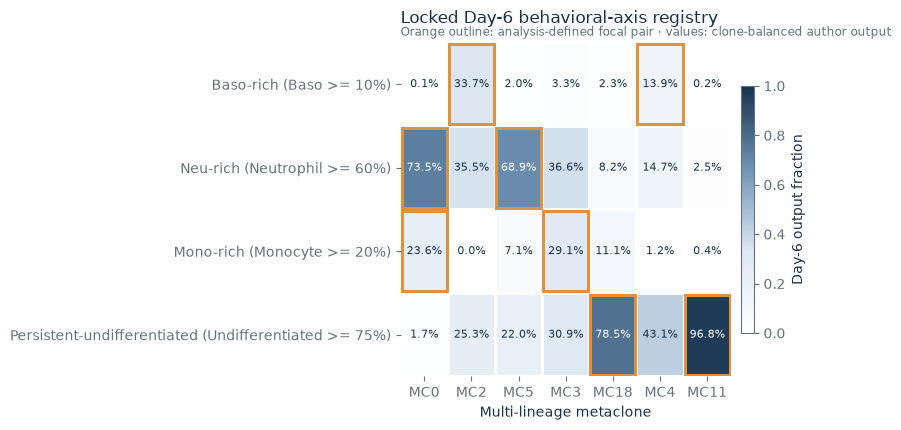

saved: analysis_workspace/analyses/weinreb_day2_hspc_metaclone_gene_programs_20260902/figures/targeted_figure_4b_behavior_axis_registry.svg | analysis_workspace/analyses/weinreb_day2_hspc_metaclone_gene_programs_20260902/figures/targeted_figure_4b_behavior_axis_registry.png


In [42]:
# TARGETED_MAIN_PLOT_INLINE_V1 — Figure 4B
from matplotlib.patches import Rectangle
plot_stem = "targeted_figure_4b_behavior_axis_registry"
plot_axes = [axis["axis_id"] for axis in BEHAVIOR_AXES]
plot_axis_labels = [
    f"{axis['axis_label']} ({axis['output_type']} >= {100 * axis['threshold']:.0f}%)"
    for axis in BEHAVIOR_AXES
]
plot_data = behavior_axis_registry.copy()
plot_data.to_csv(TABLEDIR / f"{plot_stem}_plot_data.csv", index=False)
plot_matrix = (
    plot_data.pivot(index="axis_id", columns="metaclone",
                    values="day6_clone_balanced_fraction")
    .reindex(index=plot_axes, columns=TARGET_MCS)
)
focal_lookup = set(
    zip(plot_data.loc[plot_data.is_focal, "axis_id"],
        plot_data.loc[plot_data.is_focal, "metaclone"])
)
sequential_cmap = LinearSegmentedColormap.from_list(
    "navy_fraction", [WHITE, "#DCE7F2", "#6F93B5", INK]
)
fig, ax = plt.subplots(figsize=(8.2, 4.4))
image_artist = ax.pcolormesh(
    np.arange(plot_matrix.shape[1] + 1),
    np.arange(plot_matrix.shape[0] + 1),
    plot_matrix.to_numpy(float), cmap=sequential_cmap,
    vmin=0, vmax=1, shading="flat", edgecolors=WHITE, linewidth=0.8,
)
for row_index, axis_id in enumerate(plot_matrix.index):
    for column_index, mc in enumerate(plot_matrix.columns):
        value = float(plot_matrix.loc[axis_id, mc])
        ax.text(
            column_index + 0.5, row_index + 0.5, f"{100 * value:.1f}%",
            ha="center", va="center", fontsize=8.1,
            color=WHITE if value > 0.55 else INK,
        )
        if (axis_id, mc) in focal_lookup:
            ax.add_patch(Rectangle(
                (column_index + 0.02, row_index + 0.02), 0.96, 0.96,
                fill=False, edgecolor=ORANGE, linewidth=2.2,
            ))
ax.set_xticks(np.arange(len(TARGET_MCS)) + 0.5, [f"MC{mc}" for mc in TARGET_MCS])
ax.set_yticks(np.arange(len(plot_axes)) + 0.5, plot_axis_labels)
ax.set_xlim(0, len(TARGET_MCS))
ax.set_ylim(0, len(plot_axes))
ax.invert_yaxis()
ax.set_xlabel("Multi-lineage metaclone")
ax.set_title("Locked Day-6 behavioral-axis registry", loc="left", pad=14)
ax.text(
    0, 1.02, "Orange outline: analysis-defined focal pair · values: clone-balanced author output",
    transform=ax.transAxes, fontsize=8.4, color=GREY,
)
ax.spines[:].set_visible(False)
colorbar = fig.colorbar(image_artist, ax=ax, fraction=0.035, pad=0.03)
colorbar.solids.set_rasterized(False)
colorbar.set_label("Day-6 output fraction")
fig.tight_layout()
svg = FIGDIR / f"{plot_stem}.svg"
png = FIGDIR / f"{plot_stem}.png"
fig.savefig(svg, bbox_inches="tight")
fig.savefig(png, dpi=300, bbox_inches="tight")
display(fig)
print("saved:", svg.relative_to(PROJECT_ROOT), "|", png.relative_to(PROJECT_ROOT))
plt.close(fig)

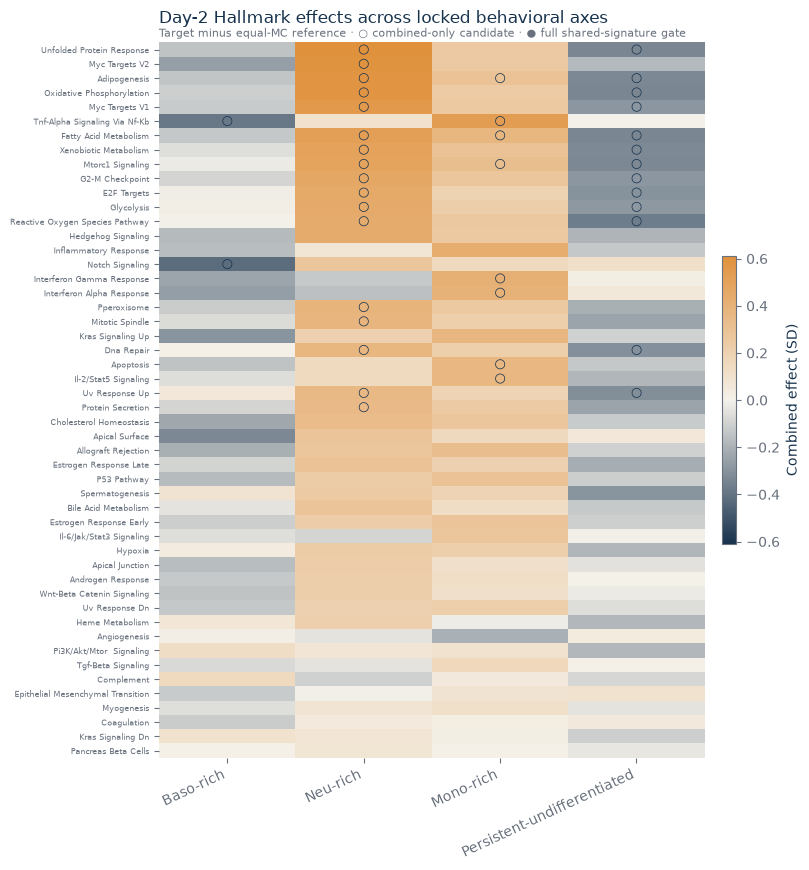

saved: analysis_workspace/analyses/weinreb_day2_hspc_metaclone_gene_programs_20260902/figures/targeted_figure_4c_hallmark_signature_effect_matrix.svg | analysis_workspace/analyses/weinreb_day2_hspc_metaclone_gene_programs_20260902/figures/targeted_figure_4c_hallmark_signature_effect_matrix.png


In [43]:
# TARGETED_MAIN_PLOT_INLINE_V1 — Figure 4C
plot_stem = "targeted_figure_4c_hallmark_signature_effect_matrix"
axis_order = [axis["axis_id"] for axis in BEHAVIOR_AXES]
axis_labels = {axis["axis_id"]: axis["axis_label"] for axis in BEHAVIOR_AXES}
plot_data = targeted_program_signatures.copy()
program_order = (
    plot_data.groupby(["program", "program_label"], observed=True)
    .combined_effect_sd.apply(lambda values: float(np.max(np.abs(values))))
    .sort_values(ascending=False).index.get_level_values("program").tolist()
)
plot_matrix = (
    plot_data.pivot(index="program", columns="axis_id", values="combined_effect_sd")
    .reindex(index=program_order, columns=axis_order)
)
plot_data["display_order"] = plot_data.program.map(
    {program: index for index, program in enumerate(program_order)}
)
plot_data.to_csv(TABLEDIR / f"{plot_stem}_plot_data.csv", index=False)
pooled_lookup = set(zip(
    plot_data.loc[plot_data.pooled_only_candidate, "program"],
    plot_data.loc[plot_data.pooled_only_candidate, "axis_id"],
))
shared_lookup = set(zip(
    plot_data.loc[plot_data.shared_behavioral_signature, "program"],
    plot_data.loc[plot_data.shared_behavioral_signature, "axis_id"],
))
limit = max(0.5, float(np.nanmax(np.abs(plot_matrix.to_numpy(float)))))
fig, ax = plt.subplots(figsize=(8.2, 8.8))
image_artist = ax.pcolormesh(
    np.arange(plot_matrix.shape[1] + 1),
    np.arange(plot_matrix.shape[0] + 1),
    plot_matrix.to_numpy(float), cmap=PROGRAM_CMAP,
    vmin=-limit, vmax=limit, shading="flat",
)
for row_index, program in enumerate(plot_matrix.index):
    for column_index, axis_id in enumerate(plot_matrix.columns):
        if (program, axis_id) in shared_lookup:
            ax.text(column_index + 0.5, row_index + 0.5, "●", ha="center", va="center",
                    fontsize=9.2, color=WHITE)
        elif (program, axis_id) in pooled_lookup:
            ax.text(column_index + 0.5, row_index + 0.5, "○", ha="center", va="center",
                    fontsize=9.2, color=INK)
program_label_map = plot_data.drop_duplicates("program").set_index("program").program_label
ax.set_xticks(np.arange(len(axis_order)) + 0.5, [axis_labels[value] for value in axis_order],
              rotation=25, ha="right")
ax.set_yticks(np.arange(len(program_order)) + 0.5,
              [program_label_map.loc[value] for value in program_order], fontsize=6.1)
ax.set_xlim(0, len(axis_order))
ax.set_ylim(0, len(program_order))
ax.invert_yaxis()
ax.set_title("Day-2 Hallmark effects across locked behavioral axes", loc="left", pad=14)
ax.text(
    0, 1.008, "Target minus equal-MC reference · ○ combined-only candidate · ● full shared-signature gate",
    transform=ax.transAxes, fontsize=8.2, color=GREY,
)
ax.spines[:].set_visible(False)
colorbar = fig.colorbar(image_artist, ax=ax, fraction=0.025, pad=0.03)
colorbar.solids.set_rasterized(False)
colorbar.set_label("Combined effect (SD)")
fig.tight_layout()
svg = FIGDIR / f"{plot_stem}.svg"
png = FIGDIR / f"{plot_stem}.png"
fig.savefig(svg, bbox_inches="tight")
fig.savefig(png, dpi=300, bbox_inches="tight")
display(fig)
print("saved:", svg.relative_to(PROJECT_ROOT), "|", png.relative_to(PROJECT_ROOT))
plt.close(fig)

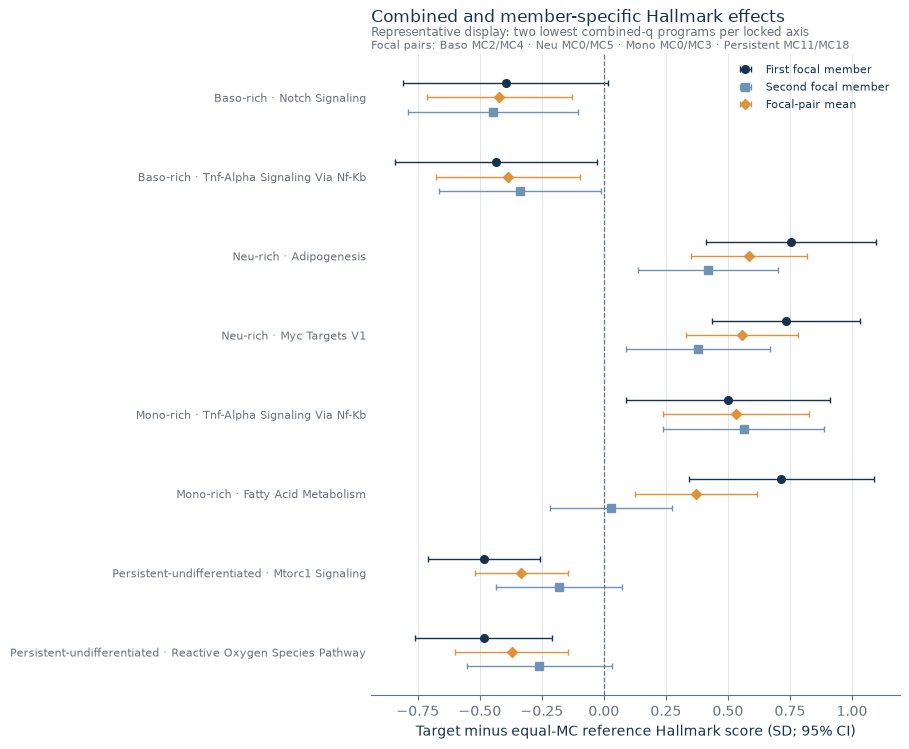

saved: analysis_workspace/analyses/weinreb_day2_hspc_metaclone_gene_programs_20260902/figures/targeted_figure_4d_member_agreement_forest.svg | analysis_workspace/analyses/weinreb_day2_hspc_metaclone_gene_programs_20260902/figures/targeted_figure_4d_member_agreement_forest.png


In [44]:
# TARGETED_MAIN_PLOT_INLINE_V1 — Figure 4D
plot_stem = "targeted_figure_4d_member_agreement_forest"
# Compact representative display: two lowest combined-q Hallmarks per axis.
# Complete results remain in Figure 4C and the exported 200-row table.
top_per_axis = (
    targeted_program_signatures.sort_values(
        ["axis_id", "combined_global_fdr", "conjunction_global_fdr"]
    ).groupby("axis_id", observed=True).head(2)[["axis_id", "program"]]
)
selected_pairs = top_per_axis.drop_duplicates().reset_index(drop=True)
assert len(selected_pairs) == 2 * len(BEHAVIOR_AXES)
selected_signature_rows = targeted_program_signatures.merge(
    selected_pairs, on=["axis_id", "program"], how="inner", validate="one_to_one"
)
selected_signature_rows["axis_order"] = selected_signature_rows.axis_id.map(
    {axis["axis_id"]: index for index, axis in enumerate(BEHAVIOR_AXES)}
)
selected_signature_rows = selected_signature_rows.sort_values(
    ["axis_order", "combined_global_fdr", "program_label"]
).reset_index(drop=True)
forest_parts = []
for row in selected_signature_rows.itertuples(index=False):
    for estimate_type, label, effect, se in [
        ("combined", "Focal-pair mean", row.combined_effect_sd, row.combined_se),
        ("member1", f"MC{int(row.member1_mc)}", row.member1_effect_sd, row.member1_se),
        ("member2", f"MC{int(row.member2_mc)}", row.member2_effect_sd, row.member2_se),
    ]:
        forest_parts.append({
            "axis_id": row.axis_id, "axis_label": row.axis_label,
            "program": row.program, "program_label": row.program_label,
            "estimate_type": estimate_type, "estimate_label": label,
            "effect_sd": effect, "standard_error": se,
            "ci_low": effect - 1.96 * se, "ci_high": effect + 1.96 * se,
            "combined_global_fdr": row.combined_global_fdr,
            "conjunction_global_fdr": row.conjunction_global_fdr,
            "shared_behavioral_signature": row.shared_behavioral_signature,
            "pooled_only_candidate": row.pooled_only_candidate,
        })
plot_data = pd.DataFrame(forest_parts)
plot_data.to_csv(TABLEDIR / f"{plot_stem}_plot_data.csv", index=False)
pair_order = selected_signature_rows[["axis_id", "axis_label", "program", "program_label"]]
pair_labels = [
    f"{row.axis_label} · {row.program_label}" for row in pair_order.itertuples(index=False)
]
pair_key_to_y = {
    (row.axis_id, row.program): len(pair_order) - 1 - index
    for index, row in enumerate(pair_order.itertuples(index=False))
}
style = {
    "combined": {"color": ORANGE, "marker": "D", "offset": 0.0},
    "member1": {"color": INK, "marker": "o", "offset": 0.18},
    "member2": {"color": "#6F93B5", "marker": "s", "offset": -0.18},
}
fig, ax = plt.subplots(figsize=(9.2, 7.6))
for estimate_type in ["member1", "member2", "combined"]:
    subset = plot_data[plot_data.estimate_type == estimate_type]
    y = np.asarray([
        pair_key_to_y[(row.axis_id, row.program)] + style[estimate_type]["offset"]
        for row in subset.itertuples(index=False)
    ])
    ax.errorbar(
        subset.effect_sd, y,
        xerr=np.vstack([
            subset.effect_sd.to_numpy(float) - subset.ci_low.to_numpy(float),
            subset.ci_high.to_numpy(float) - subset.effect_sd.to_numpy(float),
        ]), fmt=style[estimate_type]["marker"],
        color=style[estimate_type]["color"], markersize=5.5,
        elinewidth=1.0, capsize=2.2,
        label={
            "combined": "Focal-pair mean",
            "member1": "First focal member",
            "member2": "Second focal member",
        }[estimate_type],
    )
ax.axvline(0, color=GREY, linewidth=0.9, linestyle="--")
ax.set_yticks(
    np.arange(len(pair_order)), list(reversed(pair_labels)), fontsize=8.2
)
ax.set_xlabel("Target minus equal-MC reference Hallmark score (SD; 95% CI)")
ax.set_title("Combined and member-specific Hallmark effects", loc="left", pad=23)
ax.text(
    0, 1.028, "Representative display: two lowest combined-q programs per locked axis",
    transform=ax.transAxes, fontsize=8.4, color=GREY,
)
ax.text(
    0, 1.008,
    "Focal pairs: Baso MC2/MC4 · Neu MC0/MC5 · Mono MC0/MC3 · Persistent MC11/MC18",
    transform=ax.transAxes, fontsize=8.1, color=GREY,
)
ax.spines[["top", "right", "left"]].set_visible(False)
ax.tick_params(axis="y", length=0)
ax.grid(axis="x", color=LIGHT_GREY, linewidth=0.7, alpha=0.75)
ax.set_axisbelow(True)
ax.legend(frameon=False, loc="best", fontsize=8.2)
fig.tight_layout()
svg = FIGDIR / f"{plot_stem}.svg"
png = FIGDIR / f"{plot_stem}.png"
fig.savefig(svg, bbox_inches="tight")
fig.savefig(png, dpi=300, bbox_inches="tight")
display(fig)
print("saved:", svg.relative_to(PROJECT_ROOT), "|", png.relative_to(PROJECT_ROOT))
plt.close(fig)

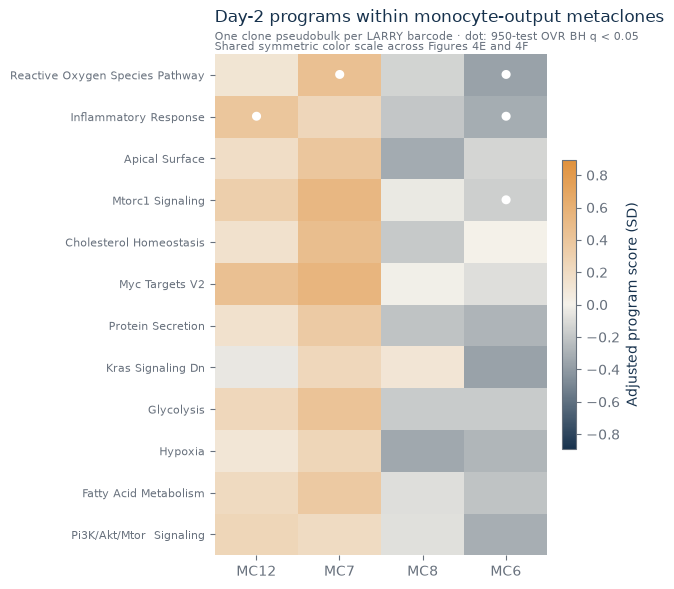

saved: analysis_workspace/analyses/weinreb_day2_hspc_metaclone_gene_programs_20260902/figures/targeted_figure_4e_monocyte_matched_output_program_landscape.svg | analysis_workspace/analyses/weinreb_day2_hspc_metaclone_gene_programs_20260902/figures/targeted_figure_4e_monocyte_matched_output_program_landscape.png


In [45]:
# TARGETED_MAIN_PLOT_INLINE_V1 — Figure 4E
plot_stem = "targeted_figure_4e_monocyte_matched_output_program_landscape"
plot_family = "Monocyte"
plot_metaclones = FAMILY_GROUPS[plot_family]
plot_matrix_full = (
    adjusted_mc_program_means.set_index("metaclone")
    .reindex(plot_metaclones)[list(program_scores.columns)]
)
plot_programs = (
    (plot_matrix_full.max(axis=0) - plot_matrix_full.min(axis=0))
    .sort_values(ascending=False).head(12).index.tolist()
)
plot_matrix = plot_matrix_full[plot_programs].T
plot_data = (
    plot_matrix.rename_axis("program").reset_index()
    .melt(id_vars="program", var_name="metaclone", value_name="adjusted_score_sd")
)
plot_data["lineage_bias"] = plot_family
plot_data.to_csv(TABLEDIR / f"{plot_stem}_plot_data.csv", index=False)
significant_pairs = set(map(tuple, program_tests[
    (program_tests.tier == "within_lineage_ovr")
    & (program_tests.lineage_bias == plot_family)
    & (program_tests.tier_fdr < 0.05)
][["program", "target_mc"]].assign(target_mc=lambda frame: frame.target_mc.astype(int)).to_numpy()))
# Use one reproducibly derived color scale across the monocyte and
# neutrophil matched-output panels.
shared_scale_values = []
for shared_family in ["Monocyte", "Neutrophil"]:
    shared_matrix_full = (
        adjusted_mc_program_means.set_index("metaclone")
        .reindex(FAMILY_GROUPS[shared_family])[list(program_scores.columns)]
    )
    shared_programs = (
        (shared_matrix_full.max(axis=0) - shared_matrix_full.min(axis=0))
        .sort_values(ascending=False).head(12).index.tolist()
    )
    shared_scale_values.append(shared_matrix_full[shared_programs].to_numpy(float))
limit = max(
    0.5,
    float(max(np.nanmax(np.abs(values)) for values in shared_scale_values)),
)
fig, ax = plt.subplots(figsize=(6.6, 6.0))
image_artist = ax.pcolormesh(
    np.arange(plot_matrix.shape[1] + 1),
    np.arange(plot_matrix.shape[0] + 1),
    plot_matrix.to_numpy(float), cmap=PROGRAM_CMAP,
    vmin=-limit, vmax=limit, shading="flat",
)
for row_index, program in enumerate(plot_matrix.index):
    for column_index, metaclone in enumerate(plot_matrix.columns):
        if (program, int(metaclone)) in significant_pairs:
            ax.text(column_index + 0.5, row_index + 0.5, "●", ha="center", va="center",
                    fontsize=8.6, color=WHITE)
ax.set_xticks(np.arange(len(plot_metaclones)) + 0.5, [f"MC{mc}" for mc in plot_metaclones])
ax.set_yticks(np.arange(len(plot_programs)) + 0.5,
              [clean_program_name(program) for program in plot_programs], fontsize=8.2)
ax.set_xlim(0, len(plot_metaclones))
ax.set_ylim(0, len(plot_programs))
ax.invert_yaxis()
ax.set_title("Day-2 programs within monocyte-output metaclones", loc="left", pad=23)
ax.text(0, 1.028, "One clone pseudobulk per LARRY barcode · dot: 950-test OVR BH q < 0.05",
        transform=ax.transAxes, fontsize=8.2, color=GREY)
ax.text(0, 1.008, "Shared symmetric color scale across Figures 4E and 4F",
        transform=ax.transAxes, fontsize=8.1, color=GREY)
ax.spines[:].set_visible(False)
colorbar = fig.colorbar(image_artist, ax=ax, fraction=0.04, pad=0.04)
colorbar.solids.set_rasterized(False)
colorbar.set_label("Adjusted program score (SD)")
fig.tight_layout()
svg = FIGDIR / f"{plot_stem}.svg"
png = FIGDIR / f"{plot_stem}.png"
fig.savefig(svg, bbox_inches="tight")
fig.savefig(png, dpi=300, bbox_inches="tight")
display(fig)
print("saved:", svg.relative_to(PROJECT_ROOT), "|", png.relative_to(PROJECT_ROOT))
plt.close(fig)

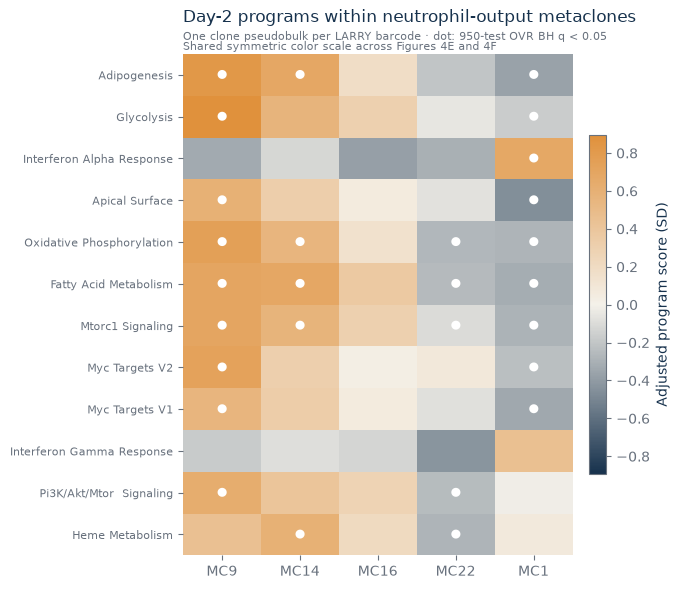

saved: analysis_workspace/analyses/weinreb_day2_hspc_metaclone_gene_programs_20260902/figures/targeted_figure_4f_neutrophil_matched_output_program_landscape.svg | analysis_workspace/analyses/weinreb_day2_hspc_metaclone_gene_programs_20260902/figures/targeted_figure_4f_neutrophil_matched_output_program_landscape.png


In [46]:
# TARGETED_MAIN_PLOT_INLINE_V1 — Figure 4F
plot_stem = "targeted_figure_4f_neutrophil_matched_output_program_landscape"
plot_family = "Neutrophil"
plot_metaclones = FAMILY_GROUPS[plot_family]
plot_matrix_full = (
    adjusted_mc_program_means.set_index("metaclone")
    .reindex(plot_metaclones)[list(program_scores.columns)]
)
plot_programs = (
    (plot_matrix_full.max(axis=0) - plot_matrix_full.min(axis=0))
    .sort_values(ascending=False).head(12).index.tolist()
)
plot_matrix = plot_matrix_full[plot_programs].T
plot_data = (
    plot_matrix.rename_axis("program").reset_index()
    .melt(id_vars="program", var_name="metaclone", value_name="adjusted_score_sd")
)
plot_data["lineage_bias"] = plot_family
plot_data.to_csv(TABLEDIR / f"{plot_stem}_plot_data.csv", index=False)
significant_pairs = set(map(tuple, program_tests[
    (program_tests.tier == "within_lineage_ovr")
    & (program_tests.lineage_bias == plot_family)
    & (program_tests.tier_fdr < 0.05)
][["program", "target_mc"]].assign(target_mc=lambda frame: frame.target_mc.astype(int)).to_numpy()))
# Use one reproducibly derived color scale across the monocyte and
# neutrophil matched-output panels.
shared_scale_values = []
for shared_family in ["Monocyte", "Neutrophil"]:
    shared_matrix_full = (
        adjusted_mc_program_means.set_index("metaclone")
        .reindex(FAMILY_GROUPS[shared_family])[list(program_scores.columns)]
    )
    shared_programs = (
        (shared_matrix_full.max(axis=0) - shared_matrix_full.min(axis=0))
        .sort_values(ascending=False).head(12).index.tolist()
    )
    shared_scale_values.append(shared_matrix_full[shared_programs].to_numpy(float))
limit = max(
    0.5,
    float(max(np.nanmax(np.abs(values)) for values in shared_scale_values)),
)
fig, ax = plt.subplots(figsize=(6.9, 6.0))
image_artist = ax.pcolormesh(
    np.arange(plot_matrix.shape[1] + 1),
    np.arange(plot_matrix.shape[0] + 1),
    plot_matrix.to_numpy(float), cmap=PROGRAM_CMAP,
    vmin=-limit, vmax=limit, shading="flat",
)
for row_index, program in enumerate(plot_matrix.index):
    for column_index, metaclone in enumerate(plot_matrix.columns):
        if (program, int(metaclone)) in significant_pairs:
            ax.text(column_index + 0.5, row_index + 0.5, "●", ha="center", va="center",
                    fontsize=8.6, color=WHITE)
ax.set_xticks(np.arange(len(plot_metaclones)) + 0.5, [f"MC{mc}" for mc in plot_metaclones])
ax.set_yticks(np.arange(len(plot_programs)) + 0.5,
              [clean_program_name(program) for program in plot_programs], fontsize=8.2)
ax.set_xlim(0, len(plot_metaclones))
ax.set_ylim(0, len(plot_programs))
ax.invert_yaxis()
ax.set_title("Day-2 programs within neutrophil-output metaclones", loc="left", pad=23)
ax.text(0, 1.028, "One clone pseudobulk per LARRY barcode · dot: 950-test OVR BH q < 0.05",
        transform=ax.transAxes, fontsize=8.2, color=GREY)
ax.text(0, 1.008, "Shared symmetric color scale across Figures 4E and 4F",
        transform=ax.transAxes, fontsize=8.1, color=GREY)
ax.spines[:].set_visible(False)
colorbar = fig.colorbar(image_artist, ax=ax, fraction=0.04, pad=0.04)
colorbar.solids.set_rasterized(False)
colorbar.set_label("Adjusted program score (SD)")
fig.tight_layout()
svg = FIGDIR / f"{plot_stem}.svg"
png = FIGDIR / f"{plot_stem}.png"
fig.savefig(svg, bbox_inches="tight")
fig.savefig(png, dpi=300, bbox_inches="tight")
display(fig)
print("saved:", svg.relative_to(PROJECT_ROOT), "|", png.relative_to(PROJECT_ROOT))
plt.close(fig)

## Supplementary targeted-analysis figures

The four axis-specific gene volcanoes, complete targeted GSEA matrix, and
true cell-removal/library-refit effect diagnostic are kept separate from the
manuscript panels.

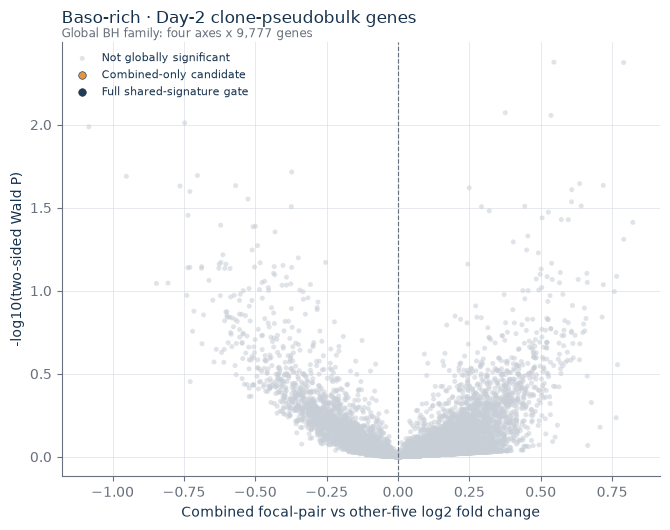

saved: analysis_workspace/analyses/weinreb_day2_hspc_metaclone_gene_programs_20260902/figures/targeted_supp_baso_rich_gene_volcano.svg | analysis_workspace/analyses/weinreb_day2_hspc_metaclone_gene_programs_20260902/figures/targeted_supp_baso_rich_gene_volcano.png


In [47]:
# TARGETED_SUPPLEMENT_PLOT_INLINE_V1 — Baso-rich gene volcano
plot_stem = "targeted_supp_baso_rich_gene_volcano"
plot_axis_id = "baso_rich"
plot_axis_label = "Baso-rich"
plot_data = targeted_gene_signatures[
    targeted_gene_signatures.axis_id == plot_axis_id
].copy()
plot_data["minus_log10_p"] = -np.log10(
    plot_data.combined_pvalue.clip(lower=np.nextafter(0, 1))
)
plot_data["evidence_class"] = np.select(
    [plot_data.shared_behavioral_signature, plot_data.pooled_only_candidate],
    ["Full shared-signature gate", "Combined-only candidate"],
    default="Not globally significant",
)
plot_data.to_csv(TABLEDIR / f"{plot_stem}_plot_data.csv", index=False)
plot_colors = {
    "Not globally significant": "#C8CED6",
    "Combined-only candidate": ORANGE,
    "Full shared-signature gate": INK,
}
fig, ax = plt.subplots(figsize=(6.8, 5.4))
for evidence_class in [
    "Not globally significant", "Combined-only candidate",
    "Full shared-signature gate",
]:
    subset = plot_data[plot_data.evidence_class == evidence_class]
    ax.scatter(
        subset.combined_log2fc, subset.minus_log10_p,
        s=13 if evidence_class == "Not globally significant" else 30,
        color=plot_colors[evidence_class],
        edgecolor="none" if evidence_class == "Not globally significant" else INK,
        linewidth=0 if evidence_class == "Not globally significant" else 0.45,
        alpha=0.55 if evidence_class == "Not globally significant" else 0.95,
        label=evidence_class, rasterized=False,
    )
label_rows = plot_data[plot_data.combined_global_fdr_pass].sort_values(
    ["combined_global_fdr", "combined_pvalue"]
)
for row in label_rows.itertuples(index=False):
    ax.annotate(
        str(row.gene), (row.combined_log2fc, row.minus_log10_p),
        xytext=(4, 4), textcoords="offset points", fontsize=7.2, color=INK,
    )
ax.axvline(0, color=GREY, linewidth=0.85, linestyle="--")
ax.set_xlabel("Combined focal-pair vs other-five log2 fold change")
ax.set_ylabel("-log10(two-sided Wald P)")
ax.set_title(f"{plot_axis_label} · Day-2 clone-pseudobulk genes", loc="left", pad=14)
ax.text(
    0, 1.012, "Global BH family: four axes x 9,777 genes",
    transform=ax.transAxes, fontsize=8.3, color=GREY,
)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(color=LIGHT_GREY, linewidth=0.65, alpha=0.7)
ax.set_axisbelow(True)
ax.legend(frameon=False, fontsize=7.8, loc="best")
fig.tight_layout()
svg = FIGDIR / f"{plot_stem}.svg"
png = FIGDIR / f"{plot_stem}.png"
fig.savefig(svg, bbox_inches="tight")
fig.savefig(png, dpi=300, bbox_inches="tight")
display(fig)
print("saved:", svg.relative_to(PROJECT_ROOT), "|", png.relative_to(PROJECT_ROOT))
plt.close(fig)

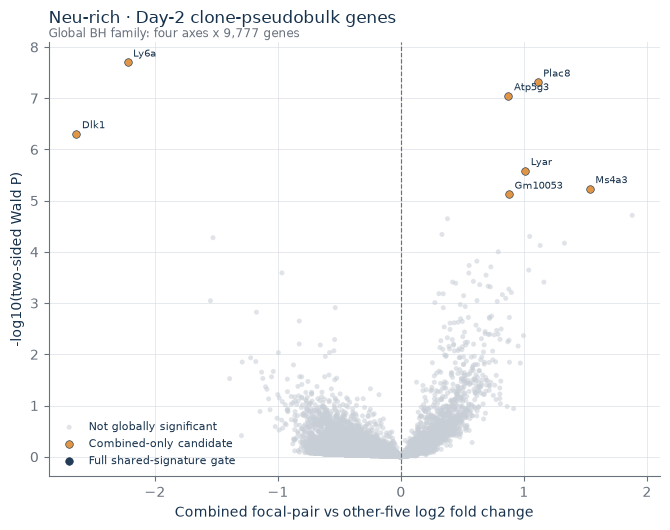

saved: analysis_workspace/analyses/weinreb_day2_hspc_metaclone_gene_programs_20260902/figures/targeted_supp_neu_rich_gene_volcano.svg | analysis_workspace/analyses/weinreb_day2_hspc_metaclone_gene_programs_20260902/figures/targeted_supp_neu_rich_gene_volcano.png


In [48]:
# TARGETED_SUPPLEMENT_PLOT_INLINE_V1 — Neu-rich gene volcano
plot_stem = "targeted_supp_neu_rich_gene_volcano"
plot_axis_id = "neu_rich"
plot_axis_label = "Neu-rich"
plot_data = targeted_gene_signatures[
    targeted_gene_signatures.axis_id == plot_axis_id
].copy()
plot_data["minus_log10_p"] = -np.log10(
    plot_data.combined_pvalue.clip(lower=np.nextafter(0, 1))
)
plot_data["evidence_class"] = np.select(
    [plot_data.shared_behavioral_signature, plot_data.pooled_only_candidate],
    ["Full shared-signature gate", "Combined-only candidate"],
    default="Not globally significant",
)
plot_data.to_csv(TABLEDIR / f"{plot_stem}_plot_data.csv", index=False)
plot_colors = {
    "Not globally significant": "#C8CED6",
    "Combined-only candidate": ORANGE,
    "Full shared-signature gate": INK,
}
fig, ax = plt.subplots(figsize=(6.8, 5.4))
for evidence_class in [
    "Not globally significant", "Combined-only candidate",
    "Full shared-signature gate",
]:
    subset = plot_data[plot_data.evidence_class == evidence_class]
    ax.scatter(
        subset.combined_log2fc, subset.minus_log10_p,
        s=13 if evidence_class == "Not globally significant" else 30,
        color=plot_colors[evidence_class],
        edgecolor="none" if evidence_class == "Not globally significant" else INK,
        linewidth=0 if evidence_class == "Not globally significant" else 0.45,
        alpha=0.55 if evidence_class == "Not globally significant" else 0.95,
        label=evidence_class, rasterized=False,
    )
label_rows = plot_data[plot_data.combined_global_fdr_pass].sort_values(
    ["combined_global_fdr", "combined_pvalue"]
)
for row in label_rows.itertuples(index=False):
    ax.annotate(
        str(row.gene), (row.combined_log2fc, row.minus_log10_p),
        xytext=(4, 4), textcoords="offset points", fontsize=7.2, color=INK,
    )
ax.axvline(0, color=GREY, linewidth=0.85, linestyle="--")
ax.set_xlabel("Combined focal-pair vs other-five log2 fold change")
ax.set_ylabel("-log10(two-sided Wald P)")
ax.set_title(f"{plot_axis_label} · Day-2 clone-pseudobulk genes", loc="left", pad=14)
ax.text(
    0, 1.012, "Global BH family: four axes x 9,777 genes",
    transform=ax.transAxes, fontsize=8.3, color=GREY,
)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(color=LIGHT_GREY, linewidth=0.65, alpha=0.7)
ax.set_axisbelow(True)
ax.legend(frameon=False, fontsize=7.8, loc="best")
fig.tight_layout()
svg = FIGDIR / f"{plot_stem}.svg"
png = FIGDIR / f"{plot_stem}.png"
fig.savefig(svg, bbox_inches="tight")
fig.savefig(png, dpi=300, bbox_inches="tight")
display(fig)
print("saved:", svg.relative_to(PROJECT_ROOT), "|", png.relative_to(PROJECT_ROOT))
plt.close(fig)

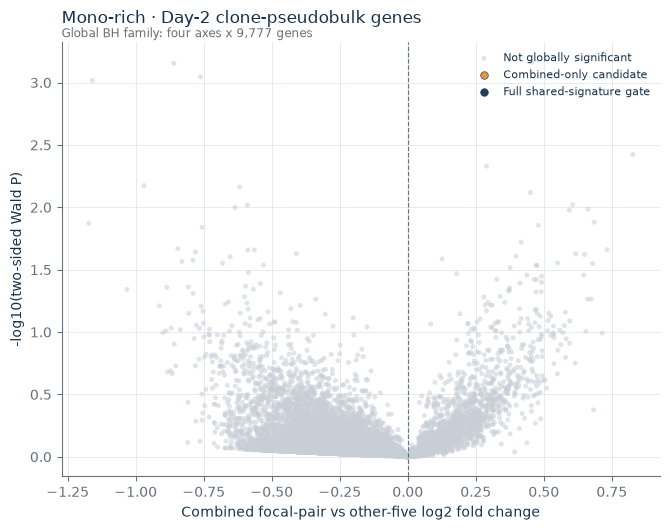

saved: analysis_workspace/analyses/weinreb_day2_hspc_metaclone_gene_programs_20260902/figures/targeted_supp_mono_rich_gene_volcano.svg | analysis_workspace/analyses/weinreb_day2_hspc_metaclone_gene_programs_20260902/figures/targeted_supp_mono_rich_gene_volcano.png


In [49]:
# TARGETED_SUPPLEMENT_PLOT_INLINE_V1 — Mono-rich gene volcano
plot_stem = "targeted_supp_mono_rich_gene_volcano"
plot_axis_id = "mono_rich"
plot_axis_label = "Mono-rich"
plot_data = targeted_gene_signatures[
    targeted_gene_signatures.axis_id == plot_axis_id
].copy()
plot_data["minus_log10_p"] = -np.log10(
    plot_data.combined_pvalue.clip(lower=np.nextafter(0, 1))
)
plot_data["evidence_class"] = np.select(
    [plot_data.shared_behavioral_signature, plot_data.pooled_only_candidate],
    ["Full shared-signature gate", "Combined-only candidate"],
    default="Not globally significant",
)
plot_data.to_csv(TABLEDIR / f"{plot_stem}_plot_data.csv", index=False)
plot_colors = {
    "Not globally significant": "#C8CED6",
    "Combined-only candidate": ORANGE,
    "Full shared-signature gate": INK,
}
fig, ax = plt.subplots(figsize=(6.8, 5.4))
for evidence_class in [
    "Not globally significant", "Combined-only candidate",
    "Full shared-signature gate",
]:
    subset = plot_data[plot_data.evidence_class == evidence_class]
    ax.scatter(
        subset.combined_log2fc, subset.minus_log10_p,
        s=13 if evidence_class == "Not globally significant" else 30,
        color=plot_colors[evidence_class],
        edgecolor="none" if evidence_class == "Not globally significant" else INK,
        linewidth=0 if evidence_class == "Not globally significant" else 0.45,
        alpha=0.55 if evidence_class == "Not globally significant" else 0.95,
        label=evidence_class, rasterized=False,
    )
label_rows = plot_data[plot_data.combined_global_fdr_pass].sort_values(
    ["combined_global_fdr", "combined_pvalue"]
)
for row in label_rows.itertuples(index=False):
    ax.annotate(
        str(row.gene), (row.combined_log2fc, row.minus_log10_p),
        xytext=(4, 4), textcoords="offset points", fontsize=7.2, color=INK,
    )
ax.axvline(0, color=GREY, linewidth=0.85, linestyle="--")
ax.set_xlabel("Combined focal-pair vs other-five log2 fold change")
ax.set_ylabel("-log10(two-sided Wald P)")
ax.set_title(f"{plot_axis_label} · Day-2 clone-pseudobulk genes", loc="left", pad=14)
ax.text(
    0, 1.012, "Global BH family: four axes x 9,777 genes",
    transform=ax.transAxes, fontsize=8.3, color=GREY,
)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(color=LIGHT_GREY, linewidth=0.65, alpha=0.7)
ax.set_axisbelow(True)
ax.legend(frameon=False, fontsize=7.8, loc="best")
fig.tight_layout()
svg = FIGDIR / f"{plot_stem}.svg"
png = FIGDIR / f"{plot_stem}.png"
fig.savefig(svg, bbox_inches="tight")
fig.savefig(png, dpi=300, bbox_inches="tight")
display(fig)
print("saved:", svg.relative_to(PROJECT_ROOT), "|", png.relative_to(PROJECT_ROOT))
plt.close(fig)

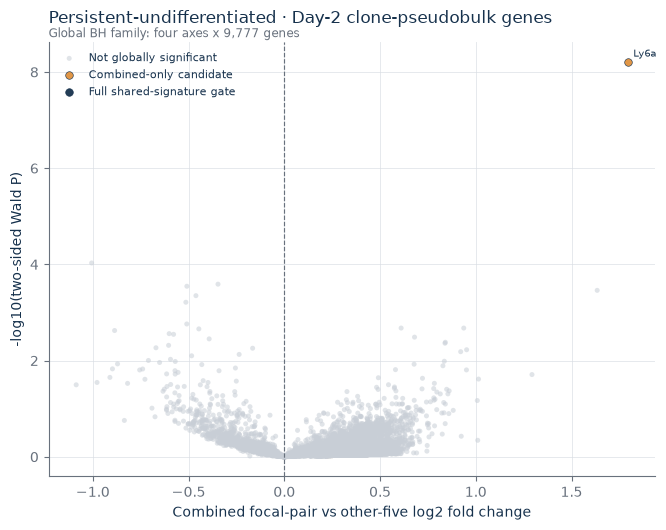

saved: analysis_workspace/analyses/weinreb_day2_hspc_metaclone_gene_programs_20260902/figures/targeted_supp_persistent_undifferentiated_gene_volcano.svg | analysis_workspace/analyses/weinreb_day2_hspc_metaclone_gene_programs_20260902/figures/targeted_supp_persistent_undifferentiated_gene_volcano.png


In [50]:
# TARGETED_SUPPLEMENT_PLOT_INLINE_V1 — Persistent-undifferentiated gene volcano
plot_stem = "targeted_supp_persistent_undifferentiated_gene_volcano"
plot_axis_id = "persistent_undifferentiated"
plot_axis_label = "Persistent-undifferentiated"
plot_data = targeted_gene_signatures[
    targeted_gene_signatures.axis_id == plot_axis_id
].copy()
plot_data["minus_log10_p"] = -np.log10(
    plot_data.combined_pvalue.clip(lower=np.nextafter(0, 1))
)
plot_data["evidence_class"] = np.select(
    [plot_data.shared_behavioral_signature, plot_data.pooled_only_candidate],
    ["Full shared-signature gate", "Combined-only candidate"],
    default="Not globally significant",
)
plot_data.to_csv(TABLEDIR / f"{plot_stem}_plot_data.csv", index=False)
plot_colors = {
    "Not globally significant": "#C8CED6",
    "Combined-only candidate": ORANGE,
    "Full shared-signature gate": INK,
}
fig, ax = plt.subplots(figsize=(6.8, 5.4))
for evidence_class in [
    "Not globally significant", "Combined-only candidate",
    "Full shared-signature gate",
]:
    subset = plot_data[plot_data.evidence_class == evidence_class]
    ax.scatter(
        subset.combined_log2fc, subset.minus_log10_p,
        s=13 if evidence_class == "Not globally significant" else 30,
        color=plot_colors[evidence_class],
        edgecolor="none" if evidence_class == "Not globally significant" else INK,
        linewidth=0 if evidence_class == "Not globally significant" else 0.45,
        alpha=0.55 if evidence_class == "Not globally significant" else 0.95,
        label=evidence_class, rasterized=False,
    )
label_rows = plot_data[plot_data.combined_global_fdr_pass].sort_values(
    ["combined_global_fdr", "combined_pvalue"]
)
for row in label_rows.itertuples(index=False):
    ax.annotate(
        str(row.gene), (row.combined_log2fc, row.minus_log10_p),
        xytext=(4, 4), textcoords="offset points", fontsize=7.2, color=INK,
    )
ax.axvline(0, color=GREY, linewidth=0.85, linestyle="--")
ax.set_xlabel("Combined focal-pair vs other-five log2 fold change")
ax.set_ylabel("-log10(two-sided Wald P)")
ax.set_title(f"{plot_axis_label} · Day-2 clone-pseudobulk genes", loc="left", pad=14)
ax.text(
    0, 1.012, "Global BH family: four axes x 9,777 genes",
    transform=ax.transAxes, fontsize=8.3, color=GREY,
)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(color=LIGHT_GREY, linewidth=0.65, alpha=0.7)
ax.set_axisbelow(True)
ax.legend(frameon=False, fontsize=7.8, loc="best")
fig.tight_layout()
svg = FIGDIR / f"{plot_stem}.svg"
png = FIGDIR / f"{plot_stem}.png"
fig.savefig(svg, bbox_inches="tight")
fig.savefig(png, dpi=300, bbox_inches="tight")
display(fig)
print("saved:", svg.relative_to(PROJECT_ROOT), "|", png.relative_to(PROJECT_ROOT))
plt.close(fig)

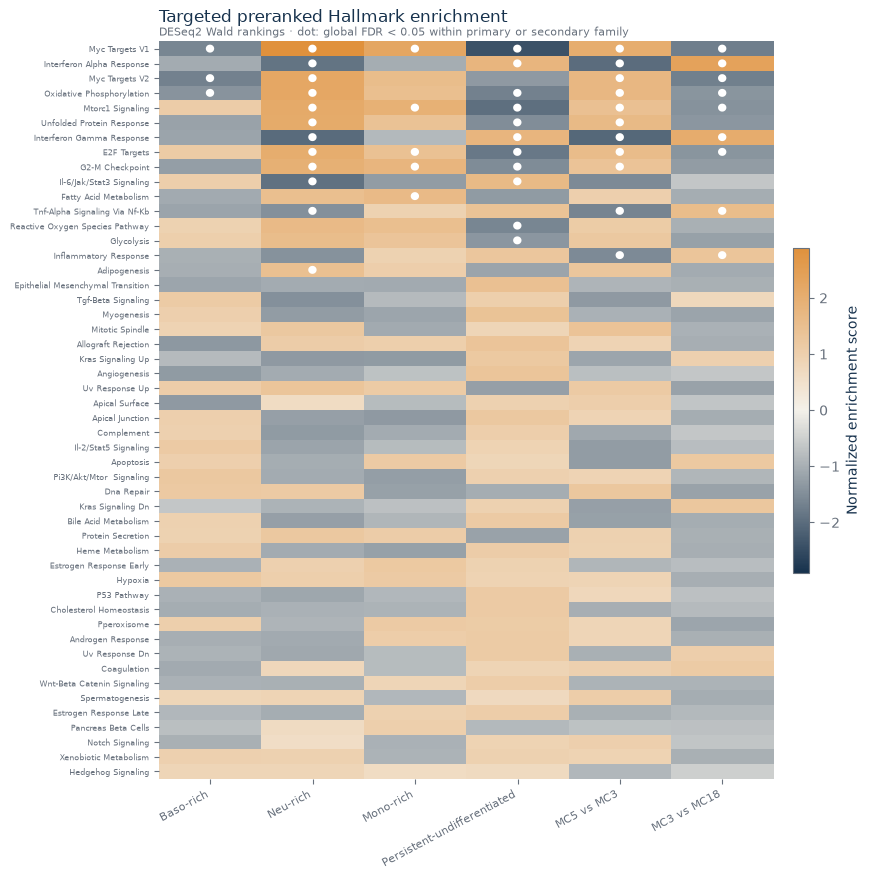

saved: analysis_workspace/analyses/weinreb_day2_hspc_metaclone_gene_programs_20260902/figures/targeted_supp_hallmark_preranked_gsea_matrix.svg | analysis_workspace/analyses/weinreb_day2_hspc_metaclone_gene_programs_20260902/figures/targeted_supp_hallmark_preranked_gsea_matrix.png


In [51]:
# TARGETED_SUPPLEMENT_PLOT_INLINE_V1 — complete targeted GSEA matrix
plot_stem = "targeted_supp_hallmark_preranked_gsea_matrix"
gsea_axis_order = [axis["axis_id"] for axis in BEHAVIOR_AXES] + [
    "mc5_vs_mc3_divergence", "mc3_vs_mc18_convergence"
]
gsea_axis_labels = {
    **{axis["axis_id"]: axis["axis_label"] for axis in BEHAVIOR_AXES},
    "mc5_vs_mc3_divergence": "MC5 vs MC3",
    "mc3_vs_mc18_convergence": "MC3 vs MC18",
}
plot_data = targeted_gsea.copy()
gsea_program_order = (
    plot_data.groupby("Term", observed=True).NES
    .apply(lambda values: float(np.nanmax(np.abs(values))))
    .sort_values(ascending=False).index.tolist()
)
gsea_matrix = (
    plot_data.pivot(index="Term", columns="axis_id", values="NES")
    .reindex(index=gsea_program_order, columns=gsea_axis_order)
)
plot_data["display_order"] = plot_data.Term.map(
    {program: index for index, program in enumerate(gsea_program_order)}
)
plot_data.to_csv(TABLEDIR / f"{plot_stem}_plot_data.csv", index=False)
gsea_significant = set(zip(
    plot_data.loc[plot_data.global_fdr_from_nominal_p < 0.05, "Term"],
    plot_data.loc[plot_data.global_fdr_from_nominal_p < 0.05, "axis_id"],
))
gsea_limit = max(1.0, float(np.nanmax(np.abs(gsea_matrix.to_numpy(float)))))
fig, ax = plt.subplots(figsize=(8.8, 8.9))
image_artist = ax.pcolormesh(
    np.arange(gsea_matrix.shape[1] + 1),
    np.arange(gsea_matrix.shape[0] + 1),
    gsea_matrix.to_numpy(float), cmap=PROGRAM_CMAP,
    vmin=-gsea_limit, vmax=gsea_limit, shading="flat",
)
for row_index, program in enumerate(gsea_matrix.index):
    for column_index, axis_id in enumerate(gsea_matrix.columns):
        if (program, axis_id) in gsea_significant:
            ax.text(column_index + 0.5, row_index + 0.5, "●", ha="center", va="center",
                    fontsize=7.8, color=WHITE)
ax.set_xticks(
    np.arange(len(gsea_axis_order)) + 0.5,
    [gsea_axis_labels[value] for value in gsea_axis_order],
    rotation=28, ha="right", fontsize=8,
)
ax.set_yticks(
    np.arange(len(gsea_program_order)) + 0.5,
    [clean_program_name(value) for value in gsea_program_order], fontsize=6.1,
)
ax.set_xlim(0, len(gsea_axis_order))
ax.set_ylim(0, len(gsea_program_order))
ax.invert_yaxis()
ax.set_title("Targeted preranked Hallmark enrichment", loc="left", pad=14)
ax.text(
    0, 1.008, "DESeq2 Wald rankings · dot: global FDR < 0.05 within primary or secondary family",
    transform=ax.transAxes, fontsize=8.1, color=GREY,
)
ax.spines[:].set_visible(False)
colorbar = fig.colorbar(image_artist, ax=ax, fraction=0.025, pad=0.03)
colorbar.solids.set_rasterized(False)
colorbar.set_label("Normalized enrichment score")
fig.tight_layout()
svg = FIGDIR / f"{plot_stem}.svg"
png = FIGDIR / f"{plot_stem}.png"
fig.savefig(svg, bbox_inches="tight")
fig.savefig(png, dpi=300, bbox_inches="tight")
display(fig)
print("saved:", svg.relative_to(PROJECT_ROOT), "|", png.relative_to(PROJECT_ROOT))
plt.close(fig)

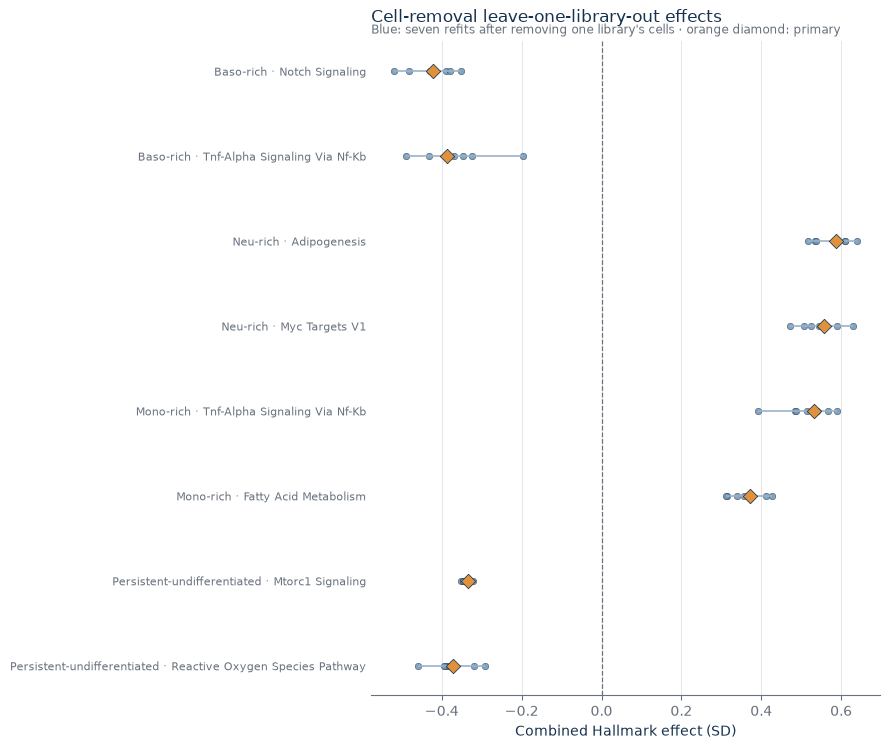

saved: analysis_workspace/analyses/weinreb_day2_hspc_metaclone_gene_programs_20260902/figures/targeted_supp_library_loo_hallmark_effect_diagnostic.svg | analysis_workspace/analyses/weinreb_day2_hspc_metaclone_gene_programs_20260902/figures/targeted_supp_library_loo_hallmark_effect_diagnostic.png


In [52]:
# TARGETED_SUPPLEMENT_PLOT_INLINE_V1 — true library-LOO effects
plot_stem = "targeted_supp_library_loo_hallmark_effect_diagnostic"
loo_plot_data = targeted_library_loo_program_effects[
    targeted_library_loo_program_effects.role == "combined"
].merge(
    selected_pairs, on=["axis_id", "program"], how="inner", validate="many_to_one"
)
primary_plot_data = selected_signature_rows[[
    "axis_id", "axis_label", "program", "program_label", "combined_effect_sd"
]].rename(columns={"combined_effect_sd": "primary_effect_sd"})
loo_plot_data = loo_plot_data.merge(
    primary_plot_data,
    on=["axis_id", "axis_label", "program", "program_label"],
    validate="many_to_one",
)
loo_plot_data.to_csv(TABLEDIR / f"{plot_stem}_plot_data.csv", index=False)
loo_pair_order = selected_signature_rows[[
    "axis_id", "axis_label", "program", "program_label"
]].copy()
assert len(loo_pair_order) == 8
loo_pair_labels = [
    f"{row.axis_label} · {row.program_label}"
    for row in loo_pair_order.itertuples(index=False)
]
loo_y = {
    (row.axis_id, row.program): len(loo_pair_order) - 1 - index
    for index, row in enumerate(loo_pair_order.itertuples(index=False))
}
fig, ax = plt.subplots(figsize=(9.0, 7.6))
for row in loo_pair_order.itertuples(index=False):
    subset = loo_plot_data[
        (loo_plot_data.axis_id == row.axis_id)
        & (loo_plot_data.program == row.program)
    ]
    y = loo_y[(row.axis_id, row.program)]
    ax.hlines(
        y, subset.effect_sd.min(), subset.effect_sd.max(),
        color="#9CB2C8", linewidth=1.2,
    )
    ax.scatter(
        subset.effect_sd, np.full(len(subset), y),
        s=22, color="#6F93B5", edgecolor=INK, linewidth=0.35,
        alpha=0.85,
    )
    ax.scatter(
        subset.primary_effect_sd.iloc[0], y, s=54, marker="D",
        color=ORANGE, edgecolor=INK, linewidth=0.55, zorder=4,
    )
ax.axvline(0, color=GREY, linewidth=0.9, linestyle="--")
ax.set_yticks(np.arange(len(loo_pair_order)), list(reversed(loo_pair_labels)), fontsize=8.2)
ax.set_xlabel("Combined Hallmark effect (SD)")
ax.set_title("Cell-removal leave-one-library-out effects", loc="left", pad=14)
ax.text(
    0, 1.012, "Blue: seven refits after removing one library's cells · orange diamond: primary",
    transform=ax.transAxes, fontsize=8.3, color=GREY,
)
ax.spines[["top", "right", "left"]].set_visible(False)
ax.tick_params(axis="y", length=0)
ax.grid(axis="x", color=LIGHT_GREY, linewidth=0.7, alpha=0.75)
ax.set_axisbelow(True)
fig.tight_layout()
svg = FIGDIR / f"{plot_stem}.svg"
png = FIGDIR / f"{plot_stem}.png"
fig.savefig(svg, bbox_inches="tight")
fig.savefig(png, dpi=300, bbox_inches="tight")
display(fig)
print("saved:", svg.relative_to(PROJECT_ROOT), "|", png.relative_to(PROJECT_ROOT))
plt.close(fig)

## Targeted findings and validation

Findings are generated from the executed tables. Observed statistical
evidence, biological interpretation, and design limitations remain
separate. The final validation also proves that the broad correlation
sensitivity is numerically unchanged from the dated pre-correction snapshot.

In [53]:
# Summarize exact multiplicity families and computed targeted findings
targeted_bh_family_audit = pd.DataFrame([
    {
        "family": "Hallmark combined across four axes",
        "n_tests": len(targeted_program_signatures),
        "expected_n_tests": 4 * 50,
        "n_fdr_lt_0_05": int(targeted_program_signatures.combined_global_fdr_pass.sum()),
    },
    {
        "family": "Hallmark max-P conjunction across four axes",
        "n_tests": len(targeted_program_signatures),
        "expected_n_tests": 4 * 50,
        "n_fdr_lt_0_05": int(targeted_program_signatures.conjunction_global_fdr_pass.sum()),
    },
    {
        "family": "Gene combined across four axes",
        "n_tests": len(targeted_gene_signatures),
        "expected_n_tests": 4 * 9777,
        "n_fdr_lt_0_05": int(targeted_gene_signatures.combined_global_fdr_pass.sum()),
    },
    {
        "family": "Gene max-P conjunction across four axes",
        "n_tests": len(targeted_gene_signatures),
        "expected_n_tests": 4 * 9777,
        "n_fdr_lt_0_05": int(targeted_gene_signatures.conjunction_global_fdr_pass.sum()),
    },
    {
        "family": "Hallmark secondary pair contrasts",
        "n_tests": len(targeted_secondary_programs),
        "expected_n_tests": 2 * 50,
        "n_fdr_lt_0_05": int((targeted_secondary_programs.secondary_global_fdr < 0.05).sum()),
    },
    {
        "family": "Gene secondary pair contrasts",
        "n_tests": len(targeted_secondary_genes),
        "expected_n_tests": 2 * 9777,
        "n_fdr_lt_0_05": int((targeted_secondary_genes.secondary_global_fdr < 0.05).sum()),
    },
])
assert (targeted_bh_family_audit.n_tests == targeted_bh_family_audit.expected_n_tests).all()
targeted_bh_family_audit.to_csv(
    TABLEDIR / "targeted_bh_family_audit.csv", index=False
)

targeted_key_results = targeted_signature_summary.copy()
targeted_key_results.to_csv(
    TABLEDIR / "targeted_key_results.csv", index=False
)
hallmark_combined_hits = targeted_program_signatures[
    targeted_program_signatures.combined_global_fdr_pass
].sort_values(["combined_global_fdr", "combined_pvalue"])
hallmark_shared_hits = targeted_program_signatures[
    targeted_program_signatures.shared_behavioral_signature
].sort_values(["combined_global_fdr", "conjunction_global_fdr"])
gene_combined_hits = targeted_gene_signatures[
    targeted_gene_signatures.combined_global_fdr_pass
].sort_values(["combined_global_fdr", "combined_pvalue"])
gene_shared_hits = targeted_gene_signatures[
    targeted_gene_signatures.shared_behavioral_signature
].sort_values(["combined_global_fdr", "conjunction_global_fdr"])

finding_lines = [
    "OBSERVED TARGETED METACLONAL-SIGNATURE EVIDENCE",
    "- Primary cohort: 217 Day-2 pooled-HSPC LARRY-clone pseudobulks in seven Multi-lineage metaclones.",
    "- Locked analysis-defined axes: Baso-rich MC2/MC4; Neu-rich MC0/MC5; Mono-rich MC0/MC3; persistent-undifferentiated MC11/MC18.",
    (
        f"- Hallmark combined/global FDR hits: {len(hallmark_combined_hits)}/200; "
        f"full shared-signature hits: {len(hallmark_shared_hits)}/200."
    ),
    (
        f"- Gene combined/global FDR hits: {len(gene_combined_hits)}/39108; "
        f"full shared-signature hits: {len(gene_shared_hits)}/39108."
    ),
    "- Combined-significant Hallmark results:",
]
if hallmark_combined_hits.empty:
    finding_lines.append("  - None.")
else:
    for row in hallmark_combined_hits.itertuples(index=False):
        finding_lines.append(
            f"  - {row.axis_label} / {row.program_label}: combined effect={row.combined_effect_sd:+.3f} SD, "
            f"combined global q={row.combined_global_fdr:.3g}, member effects="
            f"{row.member1_effect_sd:+.3f}/{row.member2_effect_sd:+.3f} SD, "
            f"conjunction global q={row.conjunction_global_fdr:.3g}, "
            f"shared={bool(row.shared_behavioral_signature)}, reason={row.pooled_only_failure_reason}."
        )
finding_lines.append("- Combined-significant gene results:")
if gene_combined_hits.empty:
    finding_lines.append("  - None.")
else:
    for row in gene_combined_hits.head(50).itertuples(index=False):
        finding_lines.append(
            f"  - {row.axis_label} / {row.gene}: combined log2FC={row.combined_log2fc:+.3f}, "
            f"combined global q={row.combined_global_fdr:.3g}, member log2FC="
            f"{row.member1_log2fc:+.3f}/{row.member2_log2fc:+.3f}, "
            f"conjunction global q={row.conjunction_global_fdr:.3g}, "
            f"shared={bool(row.shared_behavioral_signature)}, reason={row.pooled_only_failure_reason}."
        )
    if len(gene_combined_hits) > 50:
        finding_lines.append(f"  - {len(gene_combined_hits) - 50} additional rows are in the full table.")
finding_lines.extend([
    "- Secondary contrasts:",
    *[
        (
            f"  - {axis_label}: Hallmarks global q<0.05="
            f"{int((targeted_secondary_programs.loc[targeted_secondary_programs.axis_id == axis_id, 'secondary_global_fdr'] < 0.05).sum())}; "
            f"genes global q<0.05="
            f"{int((targeted_secondary_genes.loc[targeted_secondary_genes.axis_id == axis_id, 'secondary_global_fdr'] < 0.05).sum())}."
        )
        for axis_id, axis_label in [
            ("mc5_vs_mc3_divergence", "MC5 vs MC3 divergence"),
            ("mc3_vs_mc18_convergence", "MC3 vs MC18 branch-compatibility convergence"),
        ]
    ],
    "",
    "INTERPRETATION BOUNDARIES",
    "- A combined-only result is a pooled candidate and is not a shared behavioral signature.",
    "- One-metaclone-driven is reserved for exactly one nominal same-direction member; lack of global max-P support alone is not assigned that label.",
    "- The four groups were defined retrospectively from later sampled output. Day-2 differences are associations, not causal or prospective predictors.",
    "- Persistent undifferentiated output is an observed compartment fraction, not proof of self-renewal.",
    "- Destructive sampling, incomplete clone recovery, source-sublabel imbalance, and absence of independent biological replicates remain limitations.",
])
targeted_findings_text = "\n".join(finding_lines)
(REPORTDIR / "targeted_metaclonal_signature_findings_and_boundaries.txt").write_text(
    targeted_findings_text + "\n"
)
print(targeted_findings_text)
display(targeted_bh_family_audit)

OBSERVED TARGETED METACLONAL-SIGNATURE EVIDENCE
- Primary cohort: 217 Day-2 pooled-HSPC LARRY-clone pseudobulks in seven Multi-lineage metaclones.
- Locked analysis-defined axes: Baso-rich MC2/MC4; Neu-rich MC0/MC5; Mono-rich MC0/MC3; persistent-undifferentiated MC11/MC18.
- Hallmark combined/global FDR hits: 40/200; full shared-signature hits: 0/200.
- Gene combined/global FDR hits: 8/39108; full shared-signature hits: 0/39108.
- Combined-significant Hallmark results:
  - Neu-rich / Adipogenesis: combined effect=+0.586 SD, combined global q=0.000113, member effects=+0.754/+0.418 SD, conjunction global q=0.246, shared=False, reason=global_max_p_conjunction_not_supported.
  - Neu-rich / Myc Targets V1: combined effect=+0.558 SD, combined global q=0.000113, member effects=+0.735/+0.380 SD, conjunction global q=0.403, shared=False, reason=global_max_p_conjunction_not_supported.
  - Neu-rich / Myc Targets V2: combined effect=+0.601 SD, combined global q=0.00021, member effects=+0.759/+0.44

,family,n_tests,expected_n_tests,n_fdr_lt_0_05
0,Hallmark combined across four axes,200,200,40
1,Hallmark max-P conjunction across four axes,200,200,0
2,Gene combined across four axes,39108,39108,8
3,Gene max-P conjunction across four axes,39108,39108,0
4,Hallmark secondary pair contrasts,100,100,9
5,Gene secondary pair contrasts,19554,19554,0


In [54]:
# Final targeted validation, correlation immutability, plot contract, and hashes
SNAPSHOT_DIR = (
    PROJECT_ROOT / "analysis_workspace/archive/analyses/"
    "weinreb_day2_hspc_metaclone_gene_programs_pre_targeted_20260903"
)
snapshot_correlation_path = (
    SNAPSHOT_DIR / "tables/multilineage_program_output_correlations.csv"
)
assert snapshot_correlation_path.exists()
snapshot_correlations = pd.read_csv(snapshot_correlation_path)
current_correlations = pd.read_csv(
    TABLEDIR / "multilineage_program_output_correlations.csv"
)
correlation_keys = ["temporal_scope", "output_type", "program"]
assert not snapshot_correlations.duplicated(correlation_keys).any()
assert not current_correlations.duplicated(correlation_keys).any()
correlation_comparison = snapshot_correlations.merge(
    current_correlations, on=correlation_keys, how="outer",
    suffixes=("__snapshot", "__current"), indicator=True,
    validate="one_to_one",
)
assert (correlation_comparison._merge == "both").all()
correlation_numeric_columns = [
    column for column in snapshot_correlations.select_dtypes(include=[np.number]).columns
    if column not in correlation_keys
]
correlation_max_errors = {}
for column in correlation_numeric_columns:
    before = correlation_comparison[f"{column}__snapshot"].to_numpy(float)
    after = correlation_comparison[f"{column}__current"].to_numpy(float)
    equal_nan = np.isnan(before) & np.isnan(after)
    finite = np.isfinite(before) & np.isfinite(after)
    assert np.all(equal_nan | finite)
    error = float(np.max(np.abs(before[finite] - after[finite]))) if finite.any() else 0.0
    correlation_max_errors[column] = error
    assert error < 1e-12
correlation_boolean_columns = [
    column for column in [
        "lomo_sign_stable", "pooled_direction_agrees",
        "mature_direction_agrees", "stable_endpoint_association",
    ] if column in snapshot_correlations.columns
]
for column in correlation_boolean_columns:
    assert (
        correlation_comparison[f"{column}__snapshot"].astype(str).to_numpy()
        == correlation_comparison[f"{column}__current"].astype(str).to_numpy()
    ).all()
n_estimable_snapshot = int(snapshot_correlations.exact_permutation_pvalue.notna().sum())
n_estimable_current = int(current_correlations.exact_permutation_pvalue.notna().sum())
assert len(snapshot_correlations) == len(current_correlations) == 1500
assert n_estimable_snapshot == n_estimable_current == 1450
targeted_correlation_immutability_audit = pd.DataFrame([{
    "snapshot_path": str(snapshot_correlation_path.relative_to(PROJECT_ROOT)),
    "current_path": str((TABLEDIR / "multilineage_program_output_correlations.csv").relative_to(PROJECT_ROOT)),
    "n_grid_rows": len(current_correlations),
    "n_estimable_rows": n_estimable_current,
    "max_numeric_abs_error": max(correlation_max_errors.values()),
    "boolean_columns_equal": True,
    "passed": True,
}])
targeted_correlation_immutability_audit.to_csv(
    REPORTDIR / "targeted_correlation_immutability_audit.csv", index=False
)

built_notebook = nbformat.read(NOTEBOOK_PATH, as_version=4)
notebook_sources = ["".join(cell.get("source", "")) for cell in built_notebook.cells]
targeted_plot_stems = [
    "targeted_figure_4a_multilineage_day4_day6_output_composition",
    "targeted_figure_4b_behavior_axis_registry",
    "targeted_figure_4c_hallmark_signature_effect_matrix",
    "targeted_figure_4d_member_agreement_forest",
    "targeted_figure_4e_monocyte_matched_output_program_landscape",
    "targeted_figure_4f_neutrophil_matched_output_program_landscape",
    "targeted_supp_baso_rich_gene_volcano",
    "targeted_supp_neu_rich_gene_volcano",
    "targeted_supp_mono_rich_gene_volcano",
    "targeted_supp_persistent_undifferentiated_gene_volcano",
    "targeted_supp_hallmark_preranked_gsea_matrix",
    "targeted_supp_library_loo_hallmark_effect_diagnostic",
]
targeted_plot_sources = [
    source for source in notebook_sources
    if source.lstrip().startswith((
        "# TARGETED_MAIN_PLOT_INLINE_V1",
        "# TARGETED_SUPPLEMENT_PLOT_INLINE_V1",
    ))
]
targeted_plot_contract = all(
    source.count("plt.subplots") == 1
    and source.count("fig.savefig(svg") == 1
    and source.count("fig.savefig(png") == 1
    and source.count("display(fig)") == 1
    and source.count("plt.close(fig)") == 1
    for source in targeted_plot_sources
)
targeted_svg_editable = all(
    "<svg" in (FIGDIR / f"{stem}.svg").read_text(errors="ignore")
    and "<image" not in (FIGDIR / f"{stem}.svg").read_text(errors="ignore")
    for stem in targeted_plot_stems
)
active_plot_stems = plot_stems + correlation_plot_stems + targeted_plot_stems
assert len(active_plot_stems) == len(set(active_plot_stems)) == 24
all_active_svg_editable = all(
    "<svg" in (FIGDIR / f"{stem}.svg").read_text(errors="ignore")
    and "<image" not in (FIGDIR / f"{stem}.svg").read_text(errors="ignore")
    for stem in active_plot_stems
)
targeted_plot_pairs_complete = all(
    (FIGDIR / f"{stem}.svg").stat().st_size > 0
    and (FIGDIR / f"{stem}.png").stat().st_size > 0
    and (TABLEDIR / f"{stem}_plot_data.csv").stat().st_size > 0
    for stem in targeted_plot_stems
)

exact_axis_pairs = {
    row.axis_id: row.focal_mcs
    for row in behavior_axis_definitions.itertuples(index=False)
} == {
    "baso_rich": "2|4", "neu_rich": "0|5", "mono_rich": "0|3",
    "persistent_undifferentiated": "11|18",
}
targeted_validation_rows = [
    ("dated_snapshot_present", SNAPSHOT_DIR.exists(), str(SNAPSHOT_DIR.relative_to(PROJECT_ROOT))),
    ("targeted_clone_units", len(targeted_metadata) == 217, f"observed={len(targeted_metadata)}"),
    ("one_row_per_clone", targeted_metadata.index.is_unique, f"unique={targeted_metadata.index.nunique()}"),
    ("seven_multilineage_metaclones", set(targeted_metadata.metaclone) == set(TARGET_MCS), str(TARGET_MCS)),
    ("exact_behavior_axis_pairs", exact_axis_pairs, str(exact_axis_pairs)),
    ("behavior_rules_reproduced", len(behavior_axis_registry) == 28, f"rows={len(behavior_axis_registry)}"),
    ("population_not_used", "population" not in targeted_metadata.columns and "population" not in targeted_contrast_registry.columns, "metadata and registry checked"),
    ("fixed_gene_universe", targeted_counts.shape[1] == 9777, f"observed={targeted_counts.shape[1]}"),
    ("fixed_hallmark_universe", targeted_program_scores.shape[1] == 50, f"observed={targeted_program_scores.shape[1]}"),
    ("primary_model_full_rank", int(targeted_fit_audit.design_rank.iloc[0]) == int(targeted_fit_audit.design_columns.iloc[0]), targeted_design_formula),
    ("all_targeted_contrasts_oriented", len(targeted_adjusted_mean_orientation_audit) == 14 and (targeted_adjusted_mean_orientation_audit[["program_max_abs_error", "gene_max_abs_error"]].to_numpy(float) < 1e-10).all(), "14/14 specs"),
    ("contrast_vectors_neutral", targeted_vector_neutrality_audit.target_minus_reference_vector_verified.all(), "intercept/library weights cancel"),
    ("hallmark_combined_bh_family_200", len(targeted_program_signatures) == 200, str(len(targeted_program_signatures))),
    ("hallmark_conjunction_bh_family_200", targeted_program_signatures.conjunction_global_fdr.notna().sum() == 200, str(targeted_program_signatures.conjunction_global_fdr.notna().sum())),
    ("gene_combined_bh_family_39108", len(targeted_gene_signatures) == 39108, str(len(targeted_gene_signatures))),
    ("gene_conjunction_bh_family_39108", targeted_gene_signatures.conjunction_global_fdr.notna().sum() == 39108, str(targeted_gene_signatures.conjunction_global_fdr.notna().sum())),
    ("secondary_hallmark_family_100", len(targeted_secondary_programs) == 100, str(len(targeted_secondary_programs))),
    ("secondary_gene_family_19554", len(targeted_secondary_genes) == 19554, str(len(targeted_secondary_genes))),
    ("five_comparator_drops_per_axis", (comparator_program_stability.comparator_drop_n_effects == 15).all(), "5 drops x 3 effects"),
    ("seven_true_library_loo_refits", len(targeted_library_loo_fit_audit) == 7 and targeted_library_loo_fit_audit.estimable.all(), str(len(targeted_library_loo_fit_audit))),
    ("library_loo_removed_cells", (targeted_library_loo_fit_audit.removed_cells > 0).all(), targeted_library_loo_fit_audit.removed_cells.astype(str).str.cat(sep="|")),
    ("library_loo_reaggregated_clone_counts", (targeted_library_loo_fit_audit.remaining_clone_pseudobulks <= 217).all(), targeted_library_loo_fit_audit.remaining_clone_pseudobulks.astype(str).str.cat(sep="|")),
    ("shared_gate_components_exported", all(column in targeted_program_signatures.columns for column in ["combined_global_fdr_pass", "members_same_direction_as_combined", "conjunction_global_fdr_pass", "comparator_drop_all_same_direction", "library_loo_all_estimable_same_direction", "shared_behavioral_signature", "pooled_only_failure_reason"]), "program table"),
    ("broad_correlation_1450_immutable", bool(targeted_correlation_immutability_audit.passed.iloc[0]), f"max_error={targeted_correlation_immutability_audit.max_numeric_abs_error.iloc[0]:.3g}"),
    ("targeted_plot_cell_count", len(targeted_plot_sources) == len(targeted_plot_stems), f"observed={len(targeted_plot_sources)} expected={len(targeted_plot_stems)}"),
    ("targeted_plot_inline_contract", targeted_plot_contract, "one inline plot/save/display/close per cell"),
    ("targeted_plot_triplets_complete", targeted_plot_pairs_complete, f"stems={len(targeted_plot_stems)}"),
    ("targeted_svg_editable", targeted_svg_editable, "no embedded raster images"),
    ("all_active_svg_editable", all_active_svg_editable, f"no embedded raster images across {len(active_plot_stems)} active SVGs"),
    ("input_landing_zone_empty", not any((PROJECT_ROOT / "Input").iterdir()), "Input/ empty"),
]
targeted_validation = pd.DataFrame(
    targeted_validation_rows, columns=["check", "passed", "detail"]
)
targeted_validation.to_csv(
    REPORTDIR / "targeted_metaclonal_signature_validation.csv", index=False
)
assert targeted_validation.passed.all(), targeted_validation.loc[~targeted_validation.passed]

targeted_artifact_paths = [BUILDER_PATH]
for folder in [FIGDIR, TABLEDIR, REPORTDIR, RESOURCEDIR]:
    for path in sorted(folder.rglob("*")):
        if path.is_file() and path.name not in {
            "artifact_manifest.csv", "targeted_artifact_manifest.csv"
        } and not path.name.startswith("cnmf_"):
            targeted_artifact_paths.append(path)
targeted_artifact_manifest = pd.DataFrame([{
    "path": str(path.relative_to(PROJECT_ROOT)),
    "bytes": path.stat().st_size,
    "sha256": sha256(path),
} for path in sorted(set(targeted_artifact_paths))])
targeted_artifact_manifest.to_csv(
    REPORTDIR / "targeted_artifact_manifest.csv", index=False
)
# Refresh the active broad manifest after every targeted artifact exists.
targeted_artifact_manifest.to_csv(
    REPORTDIR / "artifact_manifest.csv", index=False
)
display(targeted_validation)
display(targeted_artifact_manifest.tail(20))
print("All targeted metaclonal-signature validation checks passed.")
print("Notebook:", NOTEBOOK_PATH)
print("Environment: chronoclone |", ENV_PATH)
print("Execution command:", EXECUTION_COMMAND)

,check,passed,detail
0,dated_snapshot_present,True,analysis_workspace/archive/analyses/weinreb_day2_hs...
1,targeted_clone_units,True,observed=217
2,one_row_per_clone,True,unique=217
3,seven_multilineage_metaclones,True,"[0, 2, 5, 3, 18, 4, 11]"
4,exact_behavior_axis_pairs,True,True
5,behavior_rules_reproduced,True,rows=28
6,population_not_used,True,metadata and registry checked
7,fixed_gene_universe,True,observed=9777
8,fixed_hallmark_universe,True,observed=50
9,primary_model_full_rank,True,~ libfrac__LK_d2__multi_z + libfrac__LSK_d2_1_...


,path,bytes,sha256
127,analysis_workspace/analyses/weinreb_day2_hspc_metac...,5267606,8894e569af9d8da1865676cf491e2342f3eb51d4ef3077...
128,analysis_workspace/analyses/weinreb_day2_hspc_metac...,148911,7af65bf5b639db304bcf1434812772b0d8ff8cf6873938...
129,analysis_workspace/analyses/weinreb_day2_hspc_metac...,7311,7216cebbd7d8d91d6e0b20ec1187a1321c0671a6409a11...
130,analysis_workspace/analyses/weinreb_day2_hspc_metac...,5274182,b1a5462abfaeee1fa5196e814941a6ba8235d54794bbb4...
131,analysis_workspace/analyses/weinreb_day2_hspc_metac...,5233930,6d3cf07385695e62494e7aae216116c178f5cd4e81aa03...
132,analysis_workspace/analyses/weinreb_day2_hspc_metac...,5592465,5136531537200315049ab51c2f536ead052747c98b1cd2...
133,analysis_workspace/analyses/weinreb_day2_hspc_metac...,1008,140cde9601fde90b92905a02458cb4f629423f0d1b8cbf...
134,analysis_workspace/analyses/weinreb_day2_hspc_metac...,21806,e8e2bbfcae2baf76faac188bb2fd6e45d297cae7a2bf87...
135,analysis_workspace/analyses/weinreb_day2_hspc_metac...,5114,77344a99f566312136cfa2f02f3969c381041b7900dc5b...
136,analysis_workspace/analyses/weinreb_day2_hspc_metac...,559,05c2ea5c25b8bb6cc4da077af95f655eec320b74472aed...


All targeted metaclonal-signature validation checks passed.
Notebook: /path/to/ChronoClone/analysis_workspace/analyses/weinreb_day2_hspc_metaclone_gene_programs_20260902/0001_weinreb_day2_hspc_metaclone_gene_programs.ipynb
Environment: chronoclone | /path/to/ChronoClone/.runtime/chronoclone
Execution command: /path/to/ChronoClone/.runtime/chronoclone/bin/jupyter-nbconvert --to notebook --execute --inplace --ExecutePreprocessor.kernel_name=chronoclone --ExecutePreprocessor.timeout=7200 /path/to/ChronoClone/analysis_workspace/analyses/weinreb_day2_hspc_metaclone_gene_programs_20260902/0001_weinreb_day2_hspc_metaclone_gene_programs.ipynb


## Independent de novo consensus-NMF program family

This section learns a second program family from **all 1,041** Day-2
`prog_1` + `prog_2` HSPC cells. Cells with no current metaclone are
included in discovery. Metaclone, lineage-bias, later-output,
pseudotime, fate-probability, and library fields are not supplied to
feature selection, NMF, consensus construction, or K selection.
`prog_1`/`prog_2` is used only to define the pooled input compartment;
it is revisited after the programs are frozen for sensitivity analysis.

### Predeclared discovery contract and pre-freeze K-selection amendment

- Recovered counts are normalized to 10,000 counts per cell. Features
  detected in at least 10 cells with at least 20 recovered counts are
  eligible. Exact synthetic barcode/readout features, mitochondrial
  genes, and genes in the fixed KEGG mouse Ribosome set are excluded
  before dispersion selection. Hemoglobin, sex-associated,
  cell-cycle, stress/interferon, and uncharacterized endogenous genes
  remain eligible so that such factors can be identified and flagged.
  **Feature-audit clarification dated 2026-09-09, before the accepted
  definitive run:** `Malat1` is also hard-excluded from the primary
  and every sensitivity factorization matrix. Its single-gene mask is
  applied after within-bin dispersion calibration, so excluding it
  cannot change the calibrated z-scores of unrelated genes; it is
  never eligible for the top-2,000 selection. The post-freeze full-gene
  refit retains it only as an explicit nuclear-QC audit reference.
- The 2,000 highest within-mean-bin dispersion z-scores are scaled to
  unit variance without centering, preserving non-negativity.
- K = 3,...,20 is swept with 30 genuinely random, distinct initializations
  per K (`init="random"`). Converged L2-normalized spectra are pooled;
  local-density outliers above median + 3 scaled MAD are removed;
  retained spectra are clustered into K consensus groups and the
  within-cluster median is frozen. Per-cell usage is then estimated by
  non-negative least squares against those fixed spectra.
- A K is eligible only if at least 90% of restarts converge, every
  consensus cluster is represented in at least 40% of converged
  restarts, overall cosine silhouette is at least 0.80 and the worst
  cluster-mean silhouette is at least 0.30. Every program must have
  mean fractional usage at least 25% of the equal-share expectation
  (0.25/K) and usage at least 0.5/K in at least 10% of cells. No
  spectrum pair may have cosine similarity >= 0.35 or top-50-gene
  Jaccard >= 0.25.
- Among eligible K values, the reconstruction-error elbow is the K
  with greatest distance below the endpoint chord after scaling K and
  error to [0,1]. The selected K is the highest-stability eligible K
  within elbow +/- 1; an exact tie chooses the smaller K. Program
  annotations and any outcome information are unavailable to this rule.
- **Protocol amendment dated 2026-09-09, before any program was frozen
  or any biological annotation/outcome was examined:** a dry execution
  produced only two eligible K values, so a three-point error elbow was
  undefined. If the definitive sweep has one or two eligible values,
  retain eligible K values within 0.01 of the best consensus stability,
  choose the lowest consensus reconstruction error, and use smaller K
  only for an exact error tie. If no K is eligible, stop without fitting
  downstream analyses. This fallback remains entirely diagnostic-driven.

After freezing K and the HVG consensus spectra, normalized-expression
spectra are refitted over the full expressed non-readout gene universe
using non-negative regression. All statistical comparisons use one
mean fractional-usage value per LARRY clone and HC3 inference; there
are no cell-level differential tests. This remains retrospective
ancestry analysis, not classification, prediction, or evidence that a
program prospectively determines fate.

In [55]:
# cNMF feature audit and label-blind matrix construction
import ast
import re
import zlib
from textwrap import dedent

from scipy.optimize import linear_sum_assignment, nnls
from scipy.spatial.distance import cdist
from scipy.stats import hypergeom, spearmanr
from sklearn.cluster import KMeans
from sklearn.decomposition import NMF
from sklearn.exceptions import ConvergenceWarning
from sklearn.metrics import silhouette_samples

OBJECTDIR = ANALYSIS_DIR / "objects"
OBJECTDIR.mkdir(parents=True, exist_ok=True)

CNMF_RUN_ID = "Weinreb_D2_prog1plusprog2_cNMF_20260909"
CNMF_K_GRID = list(range(3, 21))
CNMF_N_RESTARTS = 30
CNMF_N_HVG = 2000
CNMF_MAX_ITER = 1000
CNMF_TOL = 1e-4
CNMF_ROOT_SEED = 20260909
CNMF_DENSITY_MAD = 3.0
CNMF_MIN_CONVERGED = 0.90
CNMF_MIN_RESTART_COVERAGE = 0.40
CNMF_MIN_SILHOUETTE = 0.80
CNMF_MIN_CLUSTER_MEAN_SILHOUETTE = 0.30
CNMF_MIN_USAGE_VS_EQUAL_SHARE = 0.25
CNMF_MIN_ACTIVE_FRACTION = 0.10
CNMF_ACTIVE_USAGE_VS_EQUAL_SHARE = 0.50
CNMF_DUPLICATE_COSINE = 0.35
CNMF_DUPLICATE_TOP50_JACCARD = 0.25

cnmf_environment_addendum = pd.DataFrame({
    "field": [
        "environment_name", "environment_path", "kernel", "python",
        "anndata", "numpy", "scipy", "scikit-learn", "statsmodels",
        "adjustText",
        "official_cnmf_package", "implementation", "execution_command",
    ],
    "value": [
        "chronoclone", str(ENV_PATH), "chronoclone", sys.version.split()[0],
        im.version("anndata"), im.version("numpy"), im.version("scipy"),
        im.version("scikit-learn"), im.version("statsmodels"),
        im.version("adjustText"),
        "not installed; not required",
        "sklearn random NMF + consensus clustering + scipy NNLS",
        EXECUTION_COMMAND,
    ],
})
cnmf_environment_addendum.to_csv(
    REPORTDIR / "cnmf_environment_addendum.csv", index=False
)
display(cnmf_environment_addendum)

KEGG_SOURCE = PROJECT_ROOT / "reference_workspace/data/gene_sets/KEGG_2019_Mouse.gmt"
KEGG_LOCAL = RESOURCEDIR / "KEGG_2019_Mouse.gmt"
EXPECTED_KEGG_SHA256 = "6aabbf753f6d14dd2205f47fc5e461688fa550a9685dffc77d27c28c7fb13df4"
assert sha256(KEGG_SOURCE) == EXPECTED_KEGG_SHA256
if (not KEGG_LOCAL.exists()) or sha256(KEGG_LOCAL) != EXPECTED_KEGG_SHA256:
    shutil.copy2(KEGG_SOURCE, KEGG_LOCAL)
assert sha256(KEGG_LOCAL) == EXPECTED_KEGG_SHA256

kegg_sets = {}
with open(KEGG_LOCAL) as handle:
    for line in handle:
        fields = line.rstrip("\n").split("\t")
        kegg_sets[fields[0]] = {gene.upper() for gene in fields[2:] if gene}
ribosome_term = next(term for term in kegg_sets if term.lower() == "ribosome")
hematopoietic_term = next(
    term for term in kegg_sets if term.lower() == "hematopoietic cell lineage"
)
KEGG_RIBOSOME_GENES = kegg_sets[ribosome_term]

discovery_cells = all_day2_hspc.index.copy()
discovery_indices = POS.loc[discovery_cells].to_numpy()
discovery_counts = COUNTS[discovery_indices].tocsr().astype(np.float64)
discovery_genes = np.asarray(A.var_names.astype(str))
discovery_upper = np.char.upper(discovery_genes.astype(str))
assert discovery_counts.shape == (1041, 25289)
assert len(discovery_cells) == 1041
assert all_day2_hspc.LARRY_ID.nunique() == 784

synthetic_pattern = re.compile(
    r"^(?:Sapphire(?:1|2)?[-_:].*|LARRY(?:[-_:].*)?|Barcode(?:[-_:].*)?|"
    r"Guide(?:[-_:].*)?|gRNA(?:[-_:].*)?|(?:GFP|RFP|mCherry|tdTomato|"
    r"Luciferase|Puro|Hygro|Cre|Flp)(?:[-_:].*|$))$",
    flags=re.IGNORECASE,
)
SEX_AUDIT_GENES = {
    "XIST", "TSIX", "JPX", "FTX", "DDX3Y", "EIF2S3Y", "UTY",
    "KDM5D", "USP9Y", "SRY", "ZFY1", "ZFY2", "XLR3A", "XLR3B",
    "XLR4A", "XLR4B",
}
HEMOGLOBIN_PATTERN = re.compile(
    r"^HB(?:A|B|D|E|G|Q|Z)(?:[-0-9].*)?$"
)
synthetic_flag = np.array([
    bool(synthetic_pattern.match(gene)) for gene in discovery_genes
])
mitochondrial_flag = np.char.startswith(
    np.char.lower(discovery_genes.astype(str)), "mt-"
)
ribosome_flag = np.array([gene in KEGG_RIBOSOME_GENES for gene in discovery_upper])
nuclear_qc_flag = discovery_upper == "MALAT1"
sex_flag = np.array([gene in SEX_AUDIT_GENES for gene in discovery_upper])
hemoglobin_flag = np.array([
    bool(HEMOGLOBIN_PATTERN.match(gene)) for gene in discovery_upper
])
assert int(nuclear_qc_flag.sum()) == 1
assert not hemoglobin_flag[discovery_upper == "HBEGF"].any()

detected_cells = np.asarray((discovery_counts > 0).sum(axis=0)).ravel().astype(int)
total_recovered = np.asarray(discovery_counts.sum(axis=0)).ravel()
dispersion_exclusion = synthetic_flag | mitochondrial_flag | ribosome_flag
hard_exclusion = dispersion_exclusion | nuclear_qc_flag
# MALAT1 is excluded from every factorization matrix after the
# within-bin dispersion calibration. This prevents a one-gene
# technical policy change from shifting the z-scores of unrelated
# genes while still guaranteeing that MALAT1 cannot be selected.
dispersion_calibration_eligible = (
    (detected_cells >= 10) & (total_recovered >= 20)
    & ~dispersion_exclusion
)
basic_eligible = (
    dispersion_calibration_eligible & ~nuclear_qc_flag
)
row_totals = np.asarray(discovery_counts.sum(axis=1)).ravel()
assert (row_totals > 0).all()
normalized_sparse = discovery_counts.multiply((1e4 / row_totals)[:, None]).tocsr()
normalized_mean = np.asarray(normalized_sparse.mean(axis=0)).ravel()
normalized_second = np.asarray(normalized_sparse.power(2).mean(axis=0)).ravel()
normalized_variance = np.maximum(
    (normalized_second - normalized_mean ** 2) * len(discovery_cells) / (len(discovery_cells) - 1),
    0.0,
)
log_dispersion = np.log1p(
    normalized_variance / np.maximum(normalized_mean, 1e-12)
)
dispersion_z = np.full(A.n_vars, np.nan, dtype=float)
eligible_indices = np.flatnonzero(dispersion_calibration_eligible)
mean_bins = pd.qcut(
    pd.Series(np.log1p(normalized_mean[eligible_indices])),
    q=20, duplicates="drop",
)
dispersion_frame = pd.DataFrame({
    "index": eligible_indices,
    "log_dispersion": log_dispersion[eligible_indices],
    "mean_bin": mean_bins.astype(str).to_numpy(),
})
for _, frame in dispersion_frame.groupby("mean_bin", observed=True):
    scale = float(frame.log_dispersion.std(ddof=0))
    scale = scale if scale > 1e-12 else 1.0
    dispersion_z[frame["index"].to_numpy()] = (
        frame.log_dispersion.to_numpy() - frame.log_dispersion.mean()
    ) / scale
hvg_order = np.lexsort((discovery_genes, -np.nan_to_num(dispersion_z, nan=-np.inf)))
cnmf_hvg_indices = hvg_order[basic_eligible[hvg_order]][:CNMF_N_HVG]
assert basic_eligible[cnmf_hvg_indices].all()
cnmf_hvg_genes = discovery_genes[cnmf_hvg_indices]
selected_feature = np.zeros(A.n_vars, dtype=bool)
selected_feature[cnmf_hvg_indices] = True

cnmf_hvg_unscaled = normalized_sparse[:, cnmf_hvg_indices].toarray().astype(np.float64)
cnmf_hvg_sd = cnmf_hvg_unscaled.std(axis=0, ddof=1)
assert (cnmf_hvg_sd > 1e-12).all()
CNMF_MATRIX = (cnmf_hvg_unscaled / cnmf_hvg_sd).astype(np.float32)
assert CNMF_MATRIX.shape == (1041, CNMF_N_HVG)
assert np.isfinite(CNMF_MATRIX).all() and (CNMF_MATRIX >= 0).all()

exclusion_reason = np.full(A.n_vars, "", dtype=object)
exclusion_reason[synthetic_flag] = "synthetic_barcode_or_readout"
exclusion_reason[mitochondrial_flag & ~synthetic_flag] = "mitochondrial"
exclusion_reason[ribosome_flag & ~synthetic_flag & ~mitochondrial_flag] = "KEGG_ribosome"
exclusion_reason[nuclear_qc_flag & (exclusion_reason == "")] = "nuclear_QC_Malat1"
exclusion_reason[(detected_cells < 10) & (exclusion_reason == "")] = "detected_lt_10_cells"
exclusion_reason[(total_recovered < 20) & (exclusion_reason == "")] = "total_counts_lt_20"
exclusion_reason[(~selected_feature) & basic_eligible & (exclusion_reason == "")] = "eligible_not_top_2000"
exclusion_reason[selected_feature] = "selected_HVG"
cnmf_feature_audit = pd.DataFrame({
    "gene": discovery_genes,
    "detected_cells": detected_cells,
    "total_recovered_counts": total_recovered,
    "normalized_mean": normalized_mean,
    "normalized_variance": normalized_variance,
    "dispersion_z_within_mean_bin": dispersion_z,
    "synthetic_barcode_or_readout": synthetic_flag,
    "mitochondrial": mitochondrial_flag,
    "KEGG_ribosome": ribosome_flag,
    "nuclear_QC_Malat1": nuclear_qc_flag,
    "sex_associated_audit": sex_flag,
    "hemoglobin_audit": hemoglobin_flag,
    "hard_excluded": hard_exclusion,
    "eligible_for_dispersion_calibration": dispersion_calibration_eligible,
    "eligible_before_HVG_rank": basic_eligible,
    "selected_for_cNMF": selected_feature,
    "disposition": exclusion_reason,
})
cnmf_feature_audit.to_csv(
    TABLEDIR / "cnmf_feature_matrix_audit.csv.gz", index=False, compression="gzip"
)
cnmf_feature_summary = pd.DataFrame([
    ["all_features", A.n_vars],
    ["synthetic_barcode_or_readout", int(synthetic_flag.sum())],
    ["mitochondrial_excluded", int(mitochondrial_flag.sum())],
    ["KEGG_ribosome_excluded", int((ribosome_flag & ~mitochondrial_flag).sum())],
    ["nuclear_QC_Malat1_excluded", int(nuclear_qc_flag.sum())],
    ["sex_associated_retained_for_postfit_flagging", int(sex_flag.sum())],
    ["hemoglobin_retained_for_postfit_flagging", int(hemoglobin_flag.sum())],
    ["detected_in_at_least_10_cells", int((detected_cells >= 10).sum())],
    ["eligible_after_hard_filters", int(basic_eligible.sum())],
    ["selected_HVG", int(selected_feature.sum())],
], columns=["feature_audit_item", "n_features"])
cnmf_feature_summary.to_csv(TABLEDIR / "cnmf_feature_matrix_summary.csv", index=False)

forbidden_discovery_fields = {
    "metaclone", "lineage_bias", "cell_type_weinreb", "pseudotime",
    "palantir_pseudotime", "neutrophil_pseudotime", "Library",
}
discovery_fields_used = {"day", "cell_type"}
cnmf_discovery_firewall = pd.DataFrame([
    ["input_cells", "all Day-2 prog_1 + prog_2 HSPCs", 1041],
    ["expression_input", "recovered counts only", discovery_counts.shape[1]],
    ["metadata_used_in_discovery", "day|cell_type (eligibility gate only)", 2],
    ["forbidden_fields_used", "", 0],
    ["unassigned_current_metaclone_cells_included", "yes", int(all_day2_hspc.metaclone.isna().sum() + (all_day2_hspc.metaclone == -1).sum())],
], columns=["audit_item", "value", "n"])
assert not (forbidden_discovery_fields & discovery_fields_used)
assert not synthetic_flag.any()
cnmf_discovery_firewall.to_csv(REPORTDIR / "cnmf_discovery_firewall.csv", index=False)
display(cnmf_feature_summary)
display(cnmf_discovery_firewall)

,field,value
0,environment_name,chronoclone
1,environment_path,~/.reference-science/conda/envs/...
2,kernel,chronoclone
3,python,3.11.15
4,anndata,0.12.18
5,numpy,2.4.6
6,scipy,1.17.1
7,scikit-learn,1.9.0
8,statsmodels,0.14.6
9,adjustText,1.4.0


,feature_audit_item,n_features
0,all_features,25289
1,synthetic_barcode_or_readout,0
2,mitochondrial_excluded,13
3,KEGG_ribosome_excluded,129
4,nuclear_QC_Malat1_excluded,1
5,sex_associated_retained_for_postfit_flagging,16
6,hemoglobin_retained_for_postfit_flagging,10
7,detected_in_at_least_10_cells,10208
8,eligible_after_hard_filters,9061
9,selected_HVG,2000


,audit_item,value,n
0,input_cells,all Day-2 prog_1 + prog_2 HSPCs,1041
1,expression_input,recovered counts only,25289
2,metadata_used_in_discovery,day|cell_type (eligibility gate only),2
3,forbidden_fields_used,,0
4,unassigned_current_metaclone_cells_included,yes,266


In [56]:
# Random-restart cNMF, consensus construction, and complete K sweep
def cnmf_seed_registry(context, k, n_restarts):
    context_crc = zlib.crc32(str(context).encode("utf-8")) & 0xFFFFFFFF
    sequence = np.random.SeedSequence([CNMF_ROOT_SEED, context_crc, int(k)])
    children = sequence.spawn(int(n_restarts))
    seeds = [int(child.generate_state(1, dtype=np.uint32)[0]) for child in children]
    assert len(seeds) == len(set(seeds))
    return seeds

def fit_random_nmf(matrix, k, seed):
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always", ConvergenceWarning)
        model = NMF(
            n_components=int(k), init="random", solver="cd",
            beta_loss="frobenius", tol=CNMF_TOL,
            max_iter=CNMF_MAX_ITER, random_state=int(seed),
            shuffle=True,
        )
        usage = model.fit_transform(matrix)
    spectra = model.components_.astype(np.float64)
    norms = np.linalg.norm(spectra, axis=1, keepdims=True)
    norms[norms <= 1e-15] = 1.0
    spectra /= norms
    usage = usage * norms.ravel()[None, :]
    convergence_warnings = [
        item for item in caught if issubclass(item.category, ConvergenceWarning)
    ]
    converged = len(convergence_warnings) == 0 and model.n_iter_ < CNMF_MAX_ITER
    return usage, spectra, float(model.reconstruction_err_), int(model.n_iter_), converged

def fixed_spectrum_nnls(matrix, spectra):
    return np.vstack([nnls(spectra.T, row)[0] for row in matrix])

def fractional_usage(usage):
    denominator = usage.sum(axis=1, keepdims=True)
    denominator[denominator <= 1e-15] = 1.0
    return usage / denominator

def pairwise_top_jaccard(spectra, n_top=50):
    top = [set(np.argsort(row)[-n_top:]) for row in spectra]
    values = []
    for left, right in itertools.combinations(range(len(top)), 2):
        union = top[left] | top[right]
        values.append(len(top[left] & top[right]) / len(union))
    return max(values) if values else 0.0

def run_consensus_cnmf(matrix, k, n_restarts, context):
    seeds = cnmf_seed_registry(context, k, n_restarts)
    pooled = []
    pooled_restart = []
    restart_rows = []
    for restart, seed in enumerate(seeds):
        _, spectra, error, n_iter, converged = fit_random_nmf(matrix, k, seed)
        restart_rows.append({
            "context": context, "K": int(k), "restart": restart,
            "seed": seed, "init": "random", "solver": "cd",
            "reconstruction_error": error,
            "relative_reconstruction_error": error / np.linalg.norm(matrix),
            "n_iter": n_iter, "converged": bool(converged),
        })
        if converged:
            pooled.append(spectra)
            pooled_restart.extend([restart] * int(k))
    restart_diagnostics = pd.DataFrame(restart_rows)
    n_converged = int(restart_diagnostics.converged.sum())
    assert n_converged >= max(2, int(np.ceil(0.50 * n_restarts)))
    pooled_spectra = np.vstack(pooled)
    pooled_restart = np.asarray(pooled_restart, dtype=int)

    distances = cdist(pooled_spectra, pooled_spectra, metric="cosine")
    neighbor_count = max(3, int(round(0.30 * n_converged)))
    local_distance = np.sort(distances, axis=1)[:, 1:neighbor_count + 1].mean(axis=1)
    local_median = float(np.median(local_distance))
    scaled_mad = float(1.4826 * np.median(np.abs(local_distance - local_median)))
    density_cutoff = local_median + CNMF_DENSITY_MAD * max(scaled_mad, 1e-12)
    retained = local_distance <= density_cutoff
    retained_spectra = pooled_spectra[retained]
    assert len(retained_spectra) >= int(k)
    clustering_seed = cnmf_seed_registry(f"{context}__consensus_cluster", k, 1)[0]
    clusterer = KMeans(
        n_clusters=int(k), n_init=50, random_state=clustering_seed
    )
    cluster_labels = clusterer.fit_predict(retained_spectra)
    consensus = np.vstack([
        np.median(retained_spectra[cluster_labels == cluster], axis=0)
        for cluster in range(int(k))
    ])
    consensus_norm = np.linalg.norm(consensus, axis=1, keepdims=True)
    assert (consensus_norm > 1e-15).all()
    consensus /= consensus_norm
    usage = fixed_spectrum_nnls(matrix, consensus)
    usage_fraction = fractional_usage(usage)
    reconstruction = usage @ consensus

    assignment_rows = []
    retained_counter = 0
    for component in range(len(pooled_spectra)):
        cluster = int(cluster_labels[retained_counter]) if retained[component] else -1
        if retained[component]:
            retained_counter += 1
        assignment_rows.append({
            "context": context, "K": int(k), "pooled_component": component,
            "restart": int(pooled_restart[component]),
            "component_within_restart": int(component % int(k)),
            "local_cosine_distance": float(local_distance[component]),
            "density_cutoff": density_cutoff,
            "retained": bool(retained[component]),
            "consensus_cluster": cluster,
        })
    assignments = pd.DataFrame(assignment_rows)
    coverage = (
        assignments[assignments.retained]
        .groupby("consensus_cluster", observed=True).restart.nunique()
        .reindex(range(int(k)), fill_value=0)
    )
    cluster_sizes = (
        assignments[assignments.retained]
        .groupby("consensus_cluster", observed=True).size()
        .reindex(range(int(k)), fill_value=0)
    )
    cosine_matrix = consensus @ consensus.T
    np.fill_diagonal(cosine_matrix, -np.inf)
    max_pair_cosine = float(np.max(cosine_matrix)) if int(k) > 1 else 0.0
    sample_silhouette = silhouette_samples(
        retained_spectra, cluster_labels, metric="cosine"
    )
    stability = float(sample_silhouette.mean())
    cluster_mean_silhouette = pd.Series(sample_silhouette).groupby(
        cluster_labels
    ).mean().reindex(range(int(k)))
    mean_usage = usage_fraction.mean(axis=0)
    active_threshold = CNMF_ACTIVE_USAGE_VS_EQUAL_SHARE / int(k)
    active_fraction = (usage_fraction >= active_threshold).mean(axis=0)
    summary = {
        "K": int(k), "context": context,
        "n_restarts_requested": int(n_restarts),
        "n_restarts_converged": n_converged,
        "converged_fraction": n_converged / n_restarts,
        "n_pooled_components": int(len(pooled_spectra)),
        "n_density_outliers": int((~retained).sum()),
        "density_cutoff": density_cutoff,
        "min_cluster_size": int(cluster_sizes.min()),
        "min_restart_coverage": int(coverage.min()),
        "min_restart_coverage_fraction": float(coverage.min() / n_converged),
        "consensus_silhouette_cosine": stability,
        "minimum_cluster_mean_silhouette": float(cluster_mean_silhouette.min()),
        "median_restart_relative_error": float(
            restart_diagnostics.loc[
                restart_diagnostics.converged, "relative_reconstruction_error"
            ].median()
        ),
        "consensus_relative_error": float(
            np.linalg.norm(matrix - reconstruction) / np.linalg.norm(matrix)
        ),
        "min_program_mean_usage": float(mean_usage.min()),
        "min_mean_usage_vs_equal_share": float(mean_usage.min() * int(k)),
        "max_program_mean_usage": float(mean_usage.max()),
        "min_program_active_fraction": float(active_fraction.min()),
        "active_usage_threshold": float(active_threshold),
        "max_pairwise_consensus_cosine": max_pair_cosine,
        "max_pairwise_top50_jaccard": float(pairwise_top_jaccard(consensus, 50)),
    }
    return {
        "summary": summary, "restart_diagnostics": restart_diagnostics,
        "assignments": assignments, "spectra": consensus,
        "usage": usage, "usage_fraction": usage_fraction,
        "seeds": seeds,
    }

cnmf_k_results = {}
cnmf_sweep_rows = []
cnmf_restart_parts = []
cnmf_assignment_parts = []
for k in CNMF_K_GRID:
    result = run_consensus_cnmf(
        CNMF_MATRIX, k, CNMF_N_RESTARTS, f"primary_K_sweep_K{k:02d}"
    )
    cnmf_k_results[k] = result
    cnmf_sweep_rows.append(result["summary"])
    cnmf_restart_parts.append(result["restart_diagnostics"])
    cnmf_assignment_parts.append(result["assignments"])
    np.savez_compressed(
        OBJECTDIR / f"cnmf_K{k:02d}_consensus.npz",
        spectra_scaled=result["spectra"].astype(np.float32),
        usage_raw=result["usage"].astype(np.float32),
        usage_fraction=result["usage_fraction"].astype(np.float32),
        hvg_genes=cnmf_hvg_genes,
        hvg_indices=cnmf_hvg_indices,
    )
    print(
        f"K={k:02d} | stability={result['summary']['consensus_silhouette_cosine']:.3f} | "
        f"error={result['summary']['consensus_relative_error']:.4f} | "
        f"min usage={result['summary']['min_program_mean_usage']:.3f}"
    )

cnmf_k_diagnostics = pd.DataFrame(cnmf_sweep_rows).sort_values("K").reset_index(drop=True)
cnmf_restart_diagnostics = pd.concat(cnmf_restart_parts, ignore_index=True)
cnmf_component_assignments = pd.concat(cnmf_assignment_parts, ignore_index=True)
cnmf_restart_diagnostics.to_csv(
    TABLEDIR / "cnmf_K_sweep_restart_diagnostics.csv.gz",
    index=False, compression="gzip",
)
cnmf_component_assignments.to_csv(
    TABLEDIR / "cnmf_K_sweep_component_consensus_assignments.csv.gz",
    index=False, compression="gzip",
)

cnmf_k_diagnostics["convergence_gate"] = (
    cnmf_k_diagnostics.converged_fraction >= CNMF_MIN_CONVERGED
)
cnmf_k_diagnostics["restart_coverage_gate"] = (
    cnmf_k_diagnostics.min_restart_coverage_fraction >= CNMF_MIN_RESTART_COVERAGE
)
cnmf_k_diagnostics["stability_gate"] = (
    cnmf_k_diagnostics.consensus_silhouette_cosine >= CNMF_MIN_SILHOUETTE
)
cnmf_k_diagnostics["worst_cluster_stability_gate"] = (
    cnmf_k_diagnostics.minimum_cluster_mean_silhouette
    >= CNMF_MIN_CLUSTER_MEAN_SILHOUETTE
)
cnmf_k_diagnostics["minimum_usage_gate"] = (
    cnmf_k_diagnostics.min_mean_usage_vs_equal_share
    >= CNMF_MIN_USAGE_VS_EQUAL_SHARE
)
cnmf_k_diagnostics["active_usage_gate"] = (
    cnmf_k_diagnostics.min_program_active_fraction >= CNMF_MIN_ACTIVE_FRACTION
)
cnmf_k_diagnostics["no_duplicate_cosine_gate"] = (
    cnmf_k_diagnostics.max_pairwise_consensus_cosine < CNMF_DUPLICATE_COSINE
)
cnmf_k_diagnostics["no_duplicate_top50_gate"] = (
    cnmf_k_diagnostics.max_pairwise_top50_jaccard < CNMF_DUPLICATE_TOP50_JACCARD
)
gate_columns = [
    "convergence_gate", "restart_coverage_gate", "stability_gate",
    "worst_cluster_stability_gate",
    "minimum_usage_gate", "active_usage_gate",
    "no_duplicate_cosine_gate", "no_duplicate_top50_gate",
]
cnmf_k_diagnostics["eligible"] = cnmf_k_diagnostics[gate_columns].all(axis=1)
eligible_k = cnmf_k_diagnostics[cnmf_k_diagnostics.eligible].copy()
assert len(eligible_k) >= 1, cnmf_k_diagnostics
best_eligible_stability = float(
    eligible_k.consensus_silhouette_cosine.max()
)
fallback_stability_cutoff = best_eligible_stability - 0.01
eligible_k["reconstruction_elbow_distance"] = np.nan
if len(eligible_k) >= 3:
    k_scaled = (
        eligible_k.K - eligible_k.K.min()
    ) / (eligible_k.K.max() - eligible_k.K.min())
    error_scaled = (
        eligible_k.consensus_relative_error
        - eligible_k.consensus_relative_error.min()
    ) / (
        eligible_k.consensus_relative_error.max()
        - eligible_k.consensus_relative_error.min()
    )
    endpoint_line = error_scaled.iloc[0] + (
        error_scaled.iloc[-1] - error_scaled.iloc[0]
    ) * k_scaled
    eligible_k["reconstruction_elbow_distance"] = (
        endpoint_line - error_scaled.to_numpy()
    )
    elbow_k = int(
        eligible_k.sort_values(
            ["reconstruction_elbow_distance", "K"],
            ascending=[False, True],
        ).iloc[0].K
    )
    selection_candidates = eligible_k[
        (eligible_k.K - elbow_k).abs() <= 1
    ].copy()
    selected_row = selection_candidates.sort_values(
        ["consensus_silhouette_cosine", "K"],
        ascending=[False, True],
    ).iloc[0]
    selection_mode = "eligible_error_elbow_then_stability"
else:
    elbow_k = np.nan
    selection_candidates = eligible_k[
        eligible_k.consensus_silhouette_cosine
        >= fallback_stability_cutoff
    ].copy()
    selected_row = selection_candidates.sort_values(
        ["consensus_relative_error", "K"],
        ascending=[True, True],
    ).iloc[0]
    selection_mode = (
        "protocol_amendment_fewer_than_3_eligible__"
        "stability_within_0.01_then_min_error"
    )
CNMF_SELECTED_K = int(selected_row.K)
cnmf_k_diagnostics["reconstruction_elbow_distance"] = cnmf_k_diagnostics.K.map(
    eligible_k.set_index("K").reconstruction_elbow_distance
)
cnmf_k_diagnostics["error_elbow_K"] = elbow_k
cnmf_k_diagnostics["within_elbow_plusminus_one"] = (
    False if not np.isfinite(elbow_k) else (
        cnmf_k_diagnostics.eligible
        & ((cnmf_k_diagnostics.K - elbow_k).abs() <= 1)
    )
)
cnmf_k_diagnostics["selection_candidate"] = (
    cnmf_k_diagnostics.K.isin(selection_candidates.K)
)
cnmf_k_diagnostics["best_eligible_stability"] = best_eligible_stability
cnmf_k_diagnostics["fallback_stability_cutoff"] = fallback_stability_cutoff
cnmf_k_diagnostics["selection_mode"] = selection_mode
cnmf_k_diagnostics["selected_K"] = cnmf_k_diagnostics.K == CNMF_SELECTED_K
assert cnmf_k_diagnostics.selected_K.sum() == 1
cnmf_k_diagnostics.to_csv(TABLEDIR / "cnmf_K_selection_diagnostics.csv", index=False)
protocol_note = (
    "cNMF K-selection protocol record\n"
    f"selection_mode={selection_mode}\n"
    f"eligible_K={','.join(map(str, eligible_k.K.tolist()))}\n"
    f"best_eligible_stability={best_eligible_stability:.12g}\n"
    f"fallback_stability_cutoff={fallback_stability_cutoff:.12g}\n"
    f"selection_candidate_K={','.join(map(str, selection_candidates.K.tolist()))}\n"
    f"selected_K={CNMF_SELECTED_K}\n"
    "No biological annotations, metaclone labels, lineage outputs, or pseudotime entered selection.\n"
)
(REPORTDIR / "cnmf_K_selection_protocol_record.txt").write_text(protocol_note)
display(cnmf_k_diagnostics)
print("Frozen K:", CNMF_SELECTED_K, "| selection mode:", selection_mode)

K=03 | stability=0.815 | error=0.9327 | min usage=0.048


K=04 | stability=0.984 | error=0.9233 | min usage=0.043


K=05 | stability=0.901 | error=0.9607 | min usage=0.190


K=06 | stability=0.992 | error=0.9609 | min usage=0.084


K=07 | stability=1.000 | error=0.9468 | min usage=0.134


K=08 | stability=1.000 | error=0.9096 | min usage=0.049


... (10 outputs left out)

K=19 | stability=0.984 | error=0.8806 | min usage=0.046


K=20 | stability=0.982 | error=0.8850 | min usage=0.001


,K,context,n_restarts_requested,n_restarts_converged,converged_fraction,n_pooled_components,n_density_outliers,density_cutoff,min_cluster_size,min_restart_coverage,...,no_duplicate_top50_gate,eligible,reconstruction_elbow_distance,error_elbow_K,within_elbow_plusminus_one,selection_candidate,best_eligible_stability,fallback_stability_cutoff,selection_mode,selected_K
0,3,primary_K_sweep_K03,30,30,1.0,90,31,0.036571,13,13,...,False,False,NaN,NaN,False,False,0.999952,0.989952,protocol_amendment_fewer_than_3_eligible__stab...,False
1,4,primary_K_sweep_K04,30,30,1.0,120,43,0.010447,13,13,...,True,False,NaN,NaN,False,False,0.999952,0.989952,protocol_amendment_fewer_than_3_eligible__stab...,False
2,5,primary_K_sweep_K05,30,30,1.0,150,59,0.001656,11,11,...,True,False,NaN,NaN,False,False,0.999952,0.989952,protocol_amendment_fewer_than_3_eligible__stab...,False
3,6,primary_K_sweep_K06,30,30,1.0,180,82,0.001286,6,6,...,False,False,NaN,NaN,False,False,0.999952,0.989952,protocol_amendment_fewer_than_3_eligible__stab...,False
4,7,primary_K_sweep_K07,30,30,1.0,210,82,0.000259,11,11,...,True,False,NaN,NaN,False,False,0.999952,0.989952,protocol_amendment_fewer_than_3_eligible__stab...,False
5,8,primary_K_sweep_K08,30,30,1.0,240,80,0.000333,5,5,...,True,False,NaN,NaN,False,False,0.999952,0.989952,protocol_amendment_fewer_than_3_eligible__stab...,False
6,9,primary_K_sweep_K09,30,30,1.0,270,96,0.000254,7,7,...,False,False,NaN,NaN,False,False,0.999952,0.989952,protocol_amendment_fewer_than_3_eligible__stab...,False
7,10,primary_K_sweep_K10,30,30,1.0,300,105,0.000185,11,11,...,True,False,NaN,NaN,False,False,0.999952,0.989952,protocol_amendment_fewer_than_3_eligible__stab...,False
8,11,primary_K_sweep_K11,30,30,1.0,330,107,0.000195,12,12,...,True,True,NaN,NaN,False,True,0.999952,0.989952,protocol_amendment_fewer_than_3_eligible__stab...,False
9,12,primary_K_sweep_K12,30,30,1.0,360,101,0.000106,7,7,...,True,False,NaN,NaN,False,False,0.999952,0.989952,protocol_amendment_fewer_than_3_eligible__stab...,False


Frozen K: 13 | selection mode: protocol_amendment_fewer_than_3_eligible__stability_within_0.01_then_min_error


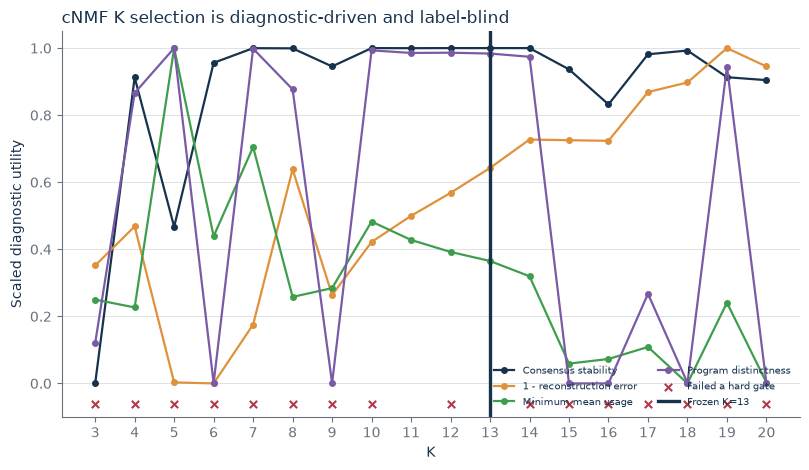

saved: analysis_workspace/analyses/weinreb_day2_hspc_metaclone_gene_programs_20260902/figures/cnmf_01_K_selection_diagnostics.svg | analysis_workspace/analyses/weinreb_day2_hspc_metaclone_gene_programs_20260902/figures/cnmf_01_K_selection_diagnostics.png


In [57]:
# CNMF_K_SELECTION_PLOT_INLINE_V1 — predeclared diagnostic rule
plot_stem = "cnmf_01_K_selection_diagnostics"
plot_data = cnmf_k_diagnostics.copy()
metric_map = {
    "Consensus stability": "consensus_silhouette_cosine",
    "1 - reconstruction error": "consensus_relative_error",
    "Minimum mean usage": "min_program_mean_usage",
    "Program distinctness": "max_pairwise_consensus_cosine",
}
plot_rows = []
for label, column in metric_map.items():
    values = plot_data[column].to_numpy(float)
    if label in {"1 - reconstruction error", "Program distinctness"}:
        values = -values
    scaled = (values - values.min()) / max(values.max() - values.min(), 1e-12)
    for k, value in zip(plot_data.K, scaled):
        plot_rows.append({"K": int(k), "diagnostic": label, "scaled_utility": float(value)})
plot_long = pd.DataFrame(plot_rows)
plot_long.to_csv(TABLEDIR / f"{plot_stem}_plot_data.csv", index=False)

fig, ax = plt.subplots(figsize=(8.2, 4.8))
colors = [INK, ORANGE, "#3F9E4D", "#7A5AA6"]
for (label, frame), color in zip(plot_long.groupby("diagnostic", sort=False), colors):
    ax.plot(frame.K, frame.scaled_utility, marker="o", linewidth=1.6,
            markersize=4, color=color, label=label)
failed = plot_data.loc[~plot_data.eligible, "K"]
ax.scatter(failed, np.full(len(failed), -0.06), marker="x", s=28,
           color="#B23A48", label="Failed a hard gate", clip_on=False)
if np.isfinite(elbow_k):
    ax.axvline(elbow_k, color=GREY, linestyle="--", linewidth=1.0,
               label=f"Error elbow K={int(elbow_k)}")
ax.axvline(CNMF_SELECTED_K, color=INK, linewidth=2.4,
           label=f"Frozen K={CNMF_SELECTED_K}")
ax.set(xlabel="K", ylabel="Scaled diagnostic utility", ylim=(-0.10, 1.05),
       xticks=CNMF_K_GRID)
ax.set_title("cNMF K selection is diagnostic-driven and label-blind", loc="left")
ax.grid(axis="y", color=LIGHT_GREY, linewidth=0.6)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, fontsize=7.5, ncol=2, loc="lower right")
fig.tight_layout()
svg = FIGDIR / f"{plot_stem}.svg"
png = FIGDIR / f"{plot_stem}.png"
fig.savefig(svg, bbox_inches="tight")
fig.savefig(png, dpi=300, bbox_inches="tight")
display(fig)
print("saved:", svg.relative_to(PROJECT_ROOT), "|", png.relative_to(PROJECT_ROOT))
plt.close(fig)

In [58]:
# Freeze selected programs, refit full-gene spectra, and save complete matrices
selected_cnmf = cnmf_k_results[CNMF_SELECTED_K]
cnmf_selected_spectra_scaled = selected_cnmf["spectra"].copy()
cnmf_selected_usage_raw = selected_cnmf["usage"].copy()
cnmf_selected_usage_fraction = selected_cnmf["usage_fraction"].copy()

# A label-blind, deterministic abundance ordering gives stable program IDs.
abundance_order = np.argsort(
    -cnmf_selected_usage_fraction.mean(axis=0), kind="mergesort"
)
cnmf_selected_spectra_scaled = cnmf_selected_spectra_scaled[abundance_order]
cnmf_selected_usage_raw = cnmf_selected_usage_raw[:, abundance_order]
cnmf_selected_usage_fraction = cnmf_selected_usage_fraction[:, abundance_order]
cnmf_program_ids = [
    f"Weinreb_D2_cNMF_K{CNMF_SELECTED_K:02d}_P{index:02d}"
    for index in range(1, CNMF_SELECTED_K + 1)
]
assert np.allclose(cnmf_selected_usage_fraction.sum(axis=1), 1.0)

cnmf_hvg_spectra = pd.DataFrame(
    cnmf_selected_spectra_scaled,
    index=pd.Index(cnmf_program_ids, name="program"),
    columns=cnmf_hvg_genes,
)
cnmf_hvg_spectra.to_csv(
    TABLEDIR / "cnmf_selected_consensus_spectra_HVG_scaled.csv.gz",
    compression="gzip",
)
cnmf_cell_usage_raw = pd.DataFrame(
    cnmf_selected_usage_raw,
    index=pd.Index(discovery_cells, name="cell"),
    columns=cnmf_program_ids,
)
cnmf_cell_usage_fraction = pd.DataFrame(
    cnmf_selected_usage_fraction,
    index=pd.Index(discovery_cells, name="cell"),
    columns=cnmf_program_ids,
)
cnmf_cell_usage_raw.to_csv(
    TABLEDIR / "cnmf_selected_per_cell_usage_raw.csv.gz", compression="gzip"
)
cnmf_cell_usage_fraction.to_csv(
    TABLEDIR / "cnmf_selected_per_cell_usage_fraction.csv.gz", compression="gzip"
)
cnmf_postfreeze_cell_metadata = all_day2_hspc[[
    "LARRY_ID", "Library", "cell_type", "day", "metaclone"
]].copy()
cnmf_postfreeze_cell_metadata.index.name = "cell"
cnmf_postfreeze_cell_metadata.rename(
    columns={"cell_type": "source_sublabel_postfreeze"}
).to_csv(
    TABLEDIR / "cnmf_discovery_cell_metadata_postfreeze.csv.gz",
    compression="gzip",
)

# Refit normalized-expression spectra over every expressed, non-readout
# gene while keeping the selected cell-usage matrix fixed. Excluded
# mt/ribosomal genes can therefore diagnose technical alignment without
# influencing discovery or K selection.
full_spectrum_mask = (detected_cells > 0) & ~synthetic_flag
cnmf_full_genes = discovery_genes[full_spectrum_mask]
full_normalized = normalized_sparse[:, full_spectrum_mask].tocsc()
cnmf_full_spectra_coeff = np.zeros(
    (CNMF_SELECTED_K, int(full_spectrum_mask.sum())), dtype=np.float64
)
for gene_index in range(full_normalized.shape[1]):
    response = full_normalized[:, gene_index].toarray().ravel()
    cnmf_full_spectra_coeff[:, gene_index] = nnls(
        cnmf_selected_usage_raw, response
    )[0]
    if (gene_index + 1) % 3000 == 0:
        print(f"full-gene frozen-usage refit: {gene_index + 1}/{full_normalized.shape[1]}")
row_sum = cnmf_full_spectra_coeff.sum(axis=1, keepdims=True)
assert (row_sum > 0).all()
cnmf_full_loading = cnmf_full_spectra_coeff / row_sum
across_program_mean = cnmf_full_loading.mean(axis=0)
across_program_sd = cnmf_full_loading.std(axis=0, ddof=0)
cnmf_full_specificity = np.zeros_like(cnmf_full_loading)
variable_genes = across_program_sd > 1e-15
cnmf_full_specificity[:, variable_genes] = (
    cnmf_full_loading[:, variable_genes] - across_program_mean[variable_genes]
) / across_program_sd[variable_genes]

cnmf_full_spectra = pd.DataFrame(
    cnmf_full_spectra_coeff,
    index=pd.Index(cnmf_program_ids, name="program"),
    columns=cnmf_full_genes,
)
cnmf_full_spectra.to_csv(
    TABLEDIR / "cnmf_selected_consensus_spectra_all_expressed_genes.csv.gz",
    compression="gzip",
)
np.savez_compressed(
    OBJECTDIR / "cnmf_selected_frozen_programs.npz",
    selected_K=CNMF_SELECTED_K,
    program_ids=np.asarray(cnmf_program_ids),
    hvg_genes=cnmf_hvg_genes,
    hvg_spectra_scaled=cnmf_selected_spectra_scaled.astype(np.float32),
    cell_usage_raw=cnmf_selected_usage_raw.astype(np.float32),
    cell_usage_fraction=cnmf_selected_usage_fraction.astype(np.float32),
    full_genes=cnmf_full_genes,
    full_gene_spectra=cnmf_full_spectra_coeff.astype(np.float32),
)

loading_frame = pd.DataFrame(
    cnmf_full_loading, index=cnmf_program_ids, columns=cnmf_full_genes
)
specificity_frame = pd.DataFrame(
    cnmf_full_specificity, index=cnmf_program_ids, columns=cnmf_full_genes
)
loading_rank = loading_frame.rank(axis=1, ascending=False, method="first")
specificity_rank = specificity_frame.rank(axis=1, ascending=False, method="first")
ranking_parts = []
for p_index, program in enumerate(cnmf_program_ids):
    floor = float(np.quantile(cnmf_full_loading[p_index], 0.90))
    eligible_for_leading = cnmf_full_loading[p_index] >= floor
    eligible_ranking = pd.DataFrame({
        "gene": cnmf_full_genes[eligible_for_leading],
        "specificity": cnmf_full_specificity[p_index, eligible_for_leading],
        "loading": cnmf_full_loading[p_index, eligible_for_leading],
    }).sort_values(
        ["specificity", "loading", "gene"],
        ascending=[False, False, True], kind="mergesort",
    )
    floor_specificity = pd.Series(
        np.arange(1, len(eligible_ranking) + 1),
        index=eligible_ranking.gene,
    )
    frame = pd.DataFrame({
        "program": program,
        "gene": cnmf_full_genes,
        "spectrum_coefficient": cnmf_full_spectra_coeff[p_index],
        "normalized_loading": cnmf_full_loading[p_index],
        "specificity_z_across_programs": cnmf_full_specificity[p_index],
        "loading_rank": loading_rank.loc[program].to_numpy(int),
        "specificity_rank_all_genes": specificity_rank.loc[program].to_numpy(int),
        "passes_program_loading_floor": eligible_for_leading,
        "specificity_rank_with_loading_floor": np.nan,
    })
    frame.loc[eligible_for_leading, "specificity_rank_with_loading_floor"] = (
        frame.loc[eligible_for_leading, "gene"].map(floor_specificity).to_numpy()
    )
    ranking_parts.append(frame)
cnmf_gene_rankings = pd.concat(ranking_parts, ignore_index=True)
cnmf_gene_rankings = cnmf_gene_rankings.merge(
    cnmf_feature_audit[[
        "gene", "synthetic_barcode_or_readout", "mitochondrial",
        "KEGG_ribosome", "nuclear_QC_Malat1",
        "sex_associated_audit", "hemoglobin_audit",
        "selected_for_cNMF",
    ]], on="gene", how="left", validate="many_to_one",
)
cnmf_leading_genes = (
    cnmf_gene_rankings[
        cnmf_gene_rankings.specificity_rank_with_loading_floor <= 100
    ]
    .sort_values(["program", "specificity_rank_with_loading_floor"])
    .reset_index(drop=True)
)
assert cnmf_leading_genes.groupby("program").size().eq(100).all()
cnmf_gene_rankings.to_csv(
    TABLEDIR / "cnmf_selected_program_complete_gene_rankings.csv.gz",
    index=False, compression="gzip",
)
cnmf_leading_genes.to_csv(
    TABLEDIR / "cnmf_selected_program_top100_genes.csv", index=False
)

frozen_program_registry = pd.DataFrame({
    "program": cnmf_program_ids,
    "selected_K": CNMF_SELECTED_K,
    "mean_cell_usage_fraction": cnmf_selected_usage_fraction.mean(axis=0),
    "active_cell_fraction_usage_ge_0_05": (
        cnmf_selected_usage_fraction >= 0.05
    ).mean(axis=0),
    "top_gene_preannotation": [
        cnmf_leading_genes.loc[
            cnmf_leading_genes.program == program, "gene"
        ].iloc[0]
        for program in cnmf_program_ids
    ],
    "program_order_rule": "descending mean fractional usage; stable sort",
})
frozen_program_registry.to_csv(TABLEDIR / "cnmf_frozen_program_registry.csv", index=False)
display(frozen_program_registry)
display(cnmf_leading_genes.groupby("program", observed=True).head(10))

full-gene frozen-usage refit: 3000/16139


full-gene frozen-usage refit: 6000/16139


full-gene frozen-usage refit: 9000/16139


full-gene frozen-usage refit: 12000/16139


full-gene frozen-usage refit: 15000/16139


,program,selected_K,mean_cell_usage_fraction,active_cell_fraction_usage_ge_0_05,top_gene_preannotation,program_order_rule
0,Weinreb_D2_cNMF_K13_P01,13,0.087939,0.939481,Zcchc6,descending mean fractional usage; stable sort
1,Weinreb_D2_cNMF_K13_P02,13,0.085394,0.921230,Ascc2,descending mean fractional usage; stable sort
2,Weinreb_D2_cNMF_K13_P03,13,0.081036,0.897214,Eci2,descending mean fractional usage; stable sort
3,Weinreb_D2_cNMF_K13_P04,13,0.080046,0.901057,Eml2,descending mean fractional usage; stable sort
4,Weinreb_D2_cNMF_K13_P05,13,0.076504,0.864553,Vps4b,descending mean fractional usage; stable sort
5,Weinreb_D2_cNMF_K13_P06,13,0.076085,0.858790,Ccdc122,descending mean fractional usage; stable sort
6,Weinreb_D2_cNMF_K13_P07,13,0.075948,0.856868,Vat1,descending mean fractional usage; stable sort
7,Weinreb_D2_cNMF_K13_P08,13,0.075681,0.827089,Mapk8,descending mean fractional usage; stable sort
8,Weinreb_D2_cNMF_K13_P09,13,0.075335,0.856868,Ccdc90b,descending mean fractional usage; stable sort
9,Weinreb_D2_cNMF_K13_P10,13,0.073385,0.847262,Ralgds,descending mean fractional usage; stable sort


,program,gene,spectrum_coefficient,normalized_loading,specificity_z_across_programs,loading_rank,specificity_rank_all_genes,passes_program_loading_floor,specificity_rank_with_loading_floor,synthetic_barcode_or_readout,mitochondrial,KEGG_ribosome,nuclear_QC_Malat1,sex_associated_audit,hemoglobin_audit,selected_for_cNMF
0,Weinreb_D2_cNMF_K13_P01,Zcchc6,0.192376,0.000669,3.464102,297,6,True,1.0,False,False,False,False,False,False,True
1,Weinreb_D2_cNMF_K13_P01,Pepd,0.183086,0.000636,3.464102,310,3,True,2.0,False,False,False,False,False,False,True
2,Weinreb_D2_cNMF_K13_P01,Umad1,0.178760,0.000621,3.464102,324,5,True,3.0,False,False,False,False,False,False,True
3,Weinreb_D2_cNMF_K13_P01,Ap3s2,0.171039,0.000594,3.464102,333,1,True,4.0,False,False,False,False,False,False,True
4,Weinreb_D2_cNMF_K13_P01,Gstt1,0.167635,0.000583,3.464102,339,2,True,5.0,False,False,False,False,False,False,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1205,Weinreb_D2_cNMF_K13_P13,Ciao1,0.180472,0.000753,3.464102,292,3,True,6.0,False,False,False,False,False,False,True
1206,Weinreb_D2_cNMF_K13_P13,Lst1,0.174505,0.000729,3.464102,297,4,True,7.0,False,False,False,False,False,False,True
1207,Weinreb_D2_cNMF_K13_P13,Zeb2,0.169958,0.000710,3.464102,310,12,True,8.0,False,False,False,False,False,False,True
1208,Weinreb_D2_cNMF_K13_P13,Sil1,0.166749,0.000696,3.464102,318,7,True,9.0,False,False,False,False,False,False,True


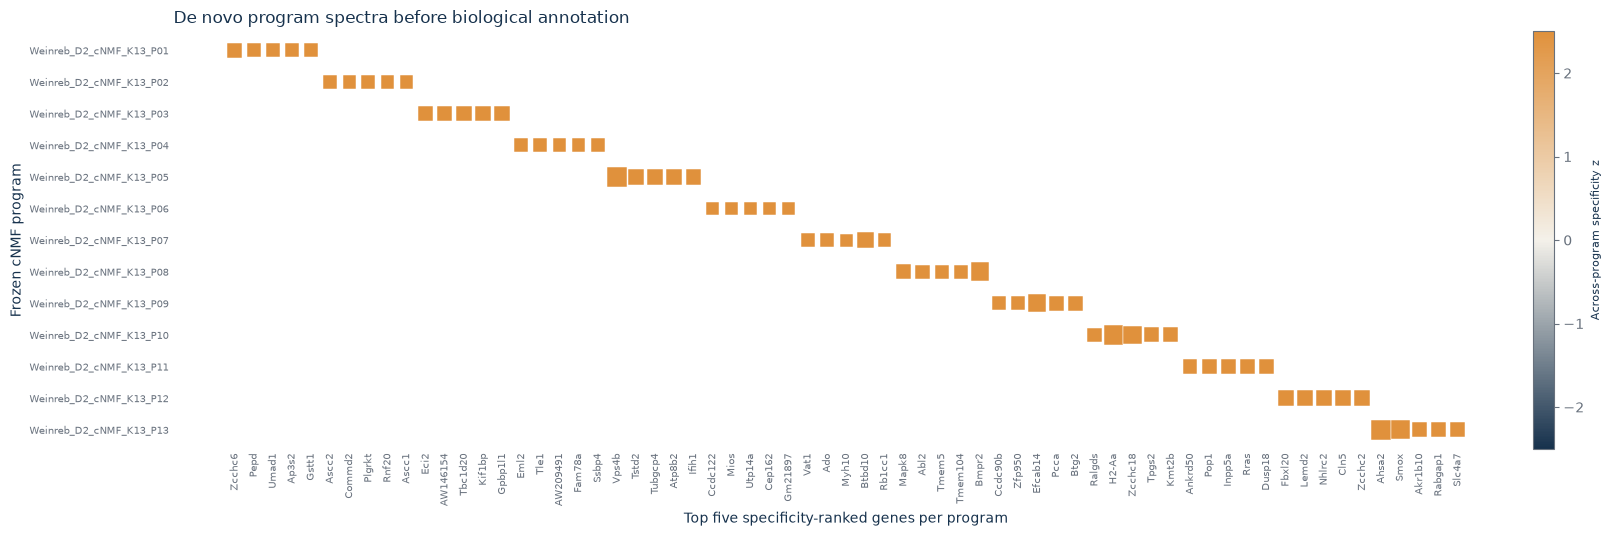

saved: analysis_workspace/analyses/weinreb_day2_hspc_metaclone_gene_programs_20260902/figures/cnmf_02_frozen_program_leading_genes.svg | analysis_workspace/analyses/weinreb_day2_hspc_metaclone_gene_programs_20260902/figures/cnmf_02_frozen_program_leading_genes.png


In [59]:
# CNMF_SPECTRA_PLOT_INLINE_V1 — frozen program leading genes
plot_stem = "cnmf_02_frozen_program_leading_genes"
plot_data = (
    cnmf_leading_genes[cnmf_leading_genes.specificity_rank_with_loading_floor <= 5]
    .copy()
)
gene_order = list(dict.fromkeys(plot_data.gene.tolist()))
plot_data["gene_x"] = plot_data.gene.map({gene: i for i, gene in enumerate(gene_order)})
plot_data["program_y"] = plot_data.program.map({
    program: i for i, program in enumerate(cnmf_program_ids[::-1])
})
plot_data.to_csv(TABLEDIR / f"{plot_stem}_plot_data.csv", index=False)

fig, ax = plt.subplots(figsize=(max(9.5, 0.25 * len(gene_order)),
                                 max(4.2, 0.42 * CNMF_SELECTED_K)))
color_values = np.clip(plot_data.specificity_z_across_programs, -2.5, 2.5)
size_values = 35 + 180 * (
    plot_data.normalized_loading / max(plot_data.normalized_loading.max(), 1e-12)
)
points = ax.scatter(
    plot_data.gene_x, plot_data.program_y, c=color_values,
    s=size_values, marker="s", cmap=PROGRAM_CMAP, vmin=-2.5, vmax=2.5,
    edgecolors=WHITE, linewidths=0.35,
)
ax.set_xticks(range(len(gene_order)), gene_order, rotation=90, fontsize=7)
ax.set_yticks(range(CNMF_SELECTED_K), cnmf_program_ids[::-1], fontsize=7)
ax.set(xlabel="Top five specificity-ranked genes per program", ylabel="Frozen cNMF program")
ax.set_title("De novo program spectra before biological annotation", loc="left")
ax.spines[["top", "right", "left", "bottom"]].set_visible(False)
ax.tick_params(length=0)
colorbar = fig.colorbar(points, ax=ax, pad=0.01, fraction=0.025)
colorbar.solids.set_rasterized(False)
colorbar.set_label("Across-program specificity z", fontsize=8)
fig.tight_layout()
svg = FIGDIR / f"{plot_stem}.svg"
png = FIGDIR / f"{plot_stem}.png"
fig.savefig(svg, bbox_inches="tight")
fig.savefig(png, dpi=300, bbox_inches="tight")
display(fig)
print("saved:", svg.relative_to(PROJECT_ROOT), "|", png.relative_to(PROJECT_ROOT))
plt.close(fig)

### Frozen program usage at the LARRY-clone level

Fractional usage is averaged over the Day-2 cells of each LARRY clone.
The all-cell discovery export contains 784 clones. Only after this
aggregation are the 569 clones in the current 20-metaclone partition
joined to the existing library-fraction designs. The exact 94 broad
contrasts, orientation vectors, support gates, HC3 covariance, and BH
families from the curated-program analysis are reused.

In [60]:
# One mean fractional-usage record per LARRY clone; no cell-level inference
postfreeze_usage_metadata = all_day2_hspc[[
    "LARRY_ID", "Library", "cell_type"
]].copy()
postfreeze_usage_metadata.index = discovery_cells
usage_with_clone = cnmf_cell_usage_fraction.join(
    postfreeze_usage_metadata[["LARRY_ID", "cell_type"]]
)
cnmf_clone_usage_all = usage_with_clone.groupby("LARRY_ID", observed=True)[
    cnmf_program_ids
].mean()
clone_support_all = usage_with_clone.groupby("LARRY_ID", observed=True).agg(
    n_day2_cells=("cell_type", "size"),
    n_source_sublabels=("cell_type", "nunique"),
    n_prog_1_cells=("cell_type", lambda values: int((values == "prog_1").sum())),
    n_prog_2_cells=("cell_type", lambda values: int((values == "prog_2").sum())),
)
cnmf_clone_usage_all = clone_support_all.join(cnmf_clone_usage_all)
assert len(cnmf_clone_usage_all) == 784
assert np.allclose(cnmf_clone_usage_all[cnmf_program_ids].sum(axis=1), 1.0)
cnmf_clone_usage_all.to_csv(
    TABLEDIR / "cnmf_clone_usage_all_discovery_clones.csv.gz", compression="gzip"
)

cnmf_clone_usage_assigned_raw = (
    cnmf_clone_usage_all[cnmf_program_ids]
    .reindex(pseudobulk_metadata.index)
)
assert cnmf_clone_usage_assigned_raw.notna().all().all()
assert len(cnmf_clone_usage_assigned_raw) == 569
cnmf_clone_scores = (
    cnmf_clone_usage_assigned_raw - cnmf_clone_usage_assigned_raw.mean(axis=0)
) / cnmf_clone_usage_assigned_raw.std(axis=0, ddof=1)
assert np.isfinite(cnmf_clone_scores.to_numpy()).all()
cnmf_clone_usage_export = pseudobulk_metadata[[
    "clone", "metaclone", "mc_group", "lineage_bias", "lineage_bias_key",
    "n_cells", "n_prog_1_cells", "n_prog_2_cells",
]].join(cnmf_clone_usage_assigned_raw.add_suffix("__usage_fraction"))
cnmf_clone_usage_export = cnmf_clone_usage_export.join(
    cnmf_clone_scores.add_suffix("__z")
)
cnmf_clone_usage_export.to_csv(
    TABLEDIR / "cnmf_clone_usage_current_metaclones.csv.gz", compression="gzip"
)

cnmf_fits_mc = {
    program: sm.OLS(
        cnmf_clone_scores[program].to_numpy(float), mc_design.to_numpy(float)
    ).fit(cov_type="HC3")
    for program in cnmf_program_ids
}
cnmf_fits_family = {
    program: sm.OLS(
        cnmf_clone_scores[program].to_numpy(float), family_design.to_numpy(float)
    ).fit(cov_type="HC3")
    for program in cnmf_program_ids
}
cnmf_broad_rows = []
for spec in contrast_specs:
    fits = cnmf_fits_mc if spec["model"] == "metaclone" else cnmf_fits_family
    for program, fit_result in fits.items():
        test = fit_result.t_test(np.asarray(spec["vector"], dtype=float))
        cnmf_broad_rows.append({
            "program": program, "model": spec["model"], "tier": spec["tier"],
            "contrast_id": spec["contrast_id"],
            "contrast_label": spec["contrast_label"],
            "target": spec["target"], "reference": spec["reference"],
            "lineage_bias": spec["lineage_bias"],
            "target_mc": spec["target_mc"], "reference_mc": spec["reference_mc"],
            "support_gate": spec["support_gate"],
            "effect_sd": float(np.asarray(test.effect).squeeze()),
            "standard_error": float(np.asarray(test.sd).squeeze()),
            "t_stat": float(np.asarray(test.tvalue).squeeze()),
            "pvalue": float(np.asarray(test.pvalue).squeeze()),
        })
cnmf_broad_tests = pd.DataFrame(cnmf_broad_rows)
cnmf_broad_tests["contrast_fdr"] = (
    cnmf_broad_tests.groupby("contrast_id", observed=True, group_keys=False).pvalue
    .transform(bh_adjust)
)
cnmf_broad_tests["tier_fdr"] = (
    cnmf_broad_tests.groupby("tier", observed=True, group_keys=False).pvalue
    .transform(bh_adjust)
)
metaclone_search_mask = (
    cnmf_broad_tests.tier.isin({
        "all_metaclones_ovr", "within_lineage_ovr",
        "within_lineage_pairwise",
    })
    & cnmf_broad_tests.support_gate
)
cnmf_broad_tests["metaclone_search_global_fdr"] = np.nan
cnmf_broad_tests.loc[
    metaclone_search_mask, "metaclone_search_global_fdr"
] = bh_adjust(
    cnmf_broad_tests.loc[metaclone_search_mask, "pvalue"].to_numpy(float)
)
assert len(cnmf_broad_tests) == 94 * CNMF_SELECTED_K
cnmf_broad_tests.to_csv(TABLEDIR / "cnmf_clone_level_broad_contrasts.csv", index=False)

cnmf_orientation_rows = []
for spec in contrast_specs:
    dds = dds_mc if spec["model"] == "metaclone" else dds_family
    factor = "mc_group" if spec["model"] == "metaclone" else "lineage_bias_key"
    fits = cnmf_fits_mc if spec["model"] == "metaclone" else cnmf_fits_family
    target_row = condition_mean_vector(dds, factor, spec["target_levels"])
    reference_row = condition_mean_vector(dds, factor, spec["reference_levels"])
    observed_effect = cnmf_broad_tests[
        cnmf_broad_tests.contrast_id == spec["contrast_id"]
    ].set_index("program").effect_sd
    expected_effect = pd.Series({
        program: float((target_row - reference_row) @ np.asarray(fit.params))
        for program, fit in fits.items()
    })
    error = float((observed_effect.reindex(expected_effect.index) - expected_effect).abs().max())
    cnmf_orientation_rows.append({
        "contrast_id": spec["contrast_id"], "max_abs_error": error,
        "target_minus_reference_verified": error < 1e-10,
    })
cnmf_orientation_audit = pd.DataFrame(cnmf_orientation_rows)
assert cnmf_orientation_audit.target_minus_reference_verified.all()
cnmf_orientation_audit.to_csv(
    TABLEDIR / "cnmf_clone_level_contrast_orientation_audit.csv", index=False
)

def cnmf_adjusted_means(design, fits, metadata, factor, levels, dds):
    coefficient_matrix = np.column_stack([
        fits[program].params for program in cnmf_program_ids
    ])
    rows = []
    for level in levels:
        sample = metadata.index[metadata[factor].astype(str) == str(level)][0]
        design_row = design.loc[sample].copy()
        design_row.loc[[c for c in design_row.index if c in library_covariates]] = 0.0
        estimates = design_row.to_numpy(float) @ coefficient_matrix
        rows.append({"group": str(level), **dict(zip(cnmf_program_ids, estimates))})
    return pd.DataFrame(rows)

cnmf_adjusted_mc_means = cnmf_adjusted_means(
    mc_design, cnmf_fits_mc, pseudobulk_metadata, "mc_group",
    [f"MC{mc}" for mc in MC_ORDER], dds_mc,
)
cnmf_adjusted_mc_means["metaclone"] = cnmf_adjusted_mc_means.group.str[2:].astype(int)
cnmf_adjusted_mc_means["lineage_bias"] = cnmf_adjusted_mc_means.metaclone.map(MC_TO_FAMILY)
cnmf_adjusted_family_means = cnmf_adjusted_means(
    family_design, cnmf_fits_family, pseudobulk_metadata, "lineage_bias_key",
    FAMILY_KEY_ORDER, dds_family,
)
cnmf_adjusted_family_means["lineage_bias"] = cnmf_adjusted_family_means.group.map(FAMILY_DISPLAY)
cnmf_adjusted_mc_means.to_csv(
    TABLEDIR / "cnmf_adjusted_usage_by_metaclone.csv", index=False
)
cnmf_adjusted_family_means.to_csv(
    TABLEDIR / "cnmf_adjusted_usage_by_lineage_bias.csv", index=False
)
display(
    cnmf_broad_tests.groupby("tier", observed=True).agg(
        n_tests=("program", "size"),
        n_supported=("support_gate", "sum"),
        n_tier_fdr_lt_0_05=("tier_fdr", lambda values: int((values < 0.05).sum())),
    ).reset_index()
)

,tier,n_tests,n_supported,n_tier_fdr_lt_0_05
0,all_metaclones_ovr,260,260,2
1,lineage_bias_ovr,65,65,0
2,lineage_bias_pairwise,130,130,2
3,within_lineage_ovr,247,247,1
4,within_lineage_pairwise,520,468,3


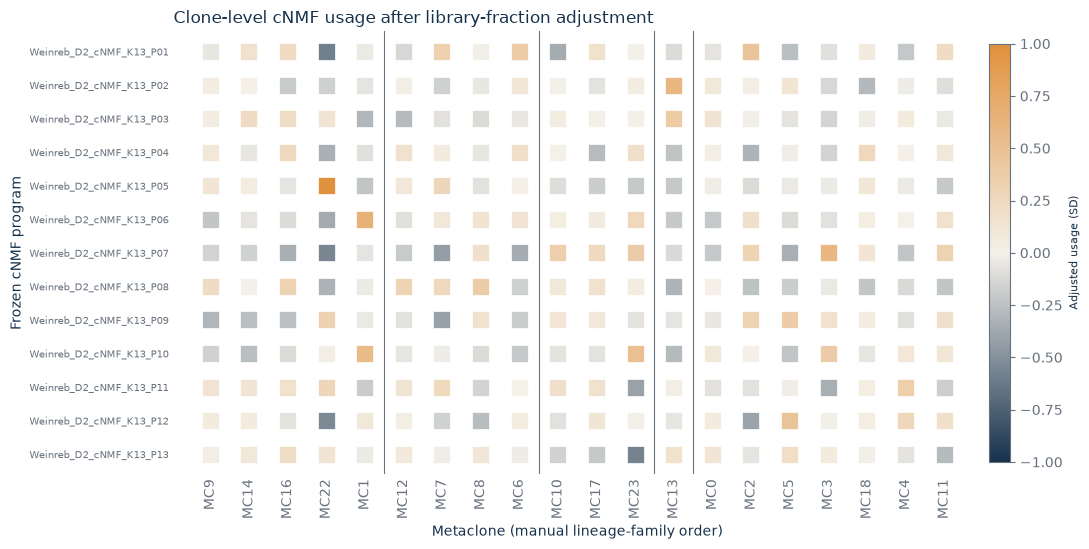

saved: analysis_workspace/analyses/weinreb_day2_hspc_metaclone_gene_programs_20260902/figures/cnmf_03_adjusted_usage_by_metaclone.svg | analysis_workspace/analyses/weinreb_day2_hspc_metaclone_gene_programs_20260902/figures/cnmf_03_adjusted_usage_by_metaclone.png


In [61]:
# CNMF_METACLONE_PLOT_INLINE_V1 — library-adjusted clone usage
plot_stem = "cnmf_03_adjusted_usage_by_metaclone"
plot_data = cnmf_adjusted_mc_means.melt(
    id_vars=["group", "metaclone", "lineage_bias"],
    value_vars=cnmf_program_ids,
    var_name="program", value_name="adjusted_usage_z",
)
plot_data["mc_x"] = plot_data.metaclone.map({mc: i for i, mc in enumerate(MC_ORDER)})
plot_data["program_y"] = plot_data.program.map({
    program: i for i, program in enumerate(cnmf_program_ids[::-1])
})
plot_data.to_csv(TABLEDIR / f"{plot_stem}_plot_data.csv", index=False)

limit = max(1.0, float(np.nanquantile(np.abs(plot_data.adjusted_usage_z), 0.98)))
fig, ax = plt.subplots(figsize=(11.0, max(4.2, 0.43 * CNMF_SELECTED_K)))
points = ax.scatter(
    plot_data.mc_x, plot_data.program_y,
    c=np.clip(plot_data.adjusted_usage_z, -limit, limit),
    s=150, marker="s", cmap=PROGRAM_CMAP, vmin=-limit, vmax=limit,
    edgecolors=WHITE, linewidths=0.5,
)
ax.set_xticks(range(len(MC_ORDER)), [f"MC{mc}" for mc in MC_ORDER], rotation=90)
ax.set_yticks(range(CNMF_SELECTED_K), cnmf_program_ids[::-1], fontsize=7)
ax.set(xlabel="Metaclone (manual lineage-family order)", ylabel="Frozen cNMF program")
ax.set_title("Clone-level cNMF usage after library-fraction adjustment", loc="left")
family_boundaries = np.cumsum([len(FAMILY_GROUPS[name]) for name in FAMILY_ORDER])[:-1] - 0.5
for boundary in family_boundaries:
    ax.axvline(boundary, color=GREY, linewidth=0.8)
ax.spines[["top", "right", "left", "bottom"]].set_visible(False)
ax.tick_params(length=0)
colorbar = fig.colorbar(points, ax=ax, pad=0.01, fraction=0.025)
colorbar.solids.set_rasterized(False)
colorbar.set_label("Adjusted usage (SD)", fontsize=8)
fig.tight_layout()
svg = FIGDIR / f"{plot_stem}.svg"
png = FIGDIR / f"{plot_stem}.png"
fig.savefig(svg, bbox_inches="tight")
fig.savefig(png, dpi=300, bbox_inches="tight")
display(fig)
print("saved:", svg.relative_to(PROJECT_ROOT), "|", png.relative_to(PROJECT_ROOT))
plt.close(fig)

### Output-matched Multi-lineage comparisons

The four locked Day-6 behavior axes and two secondary pairs are copied
exactly from the curated-program registry. Programs remain fixed.
Fractional usage is re-standardized over the same 217 Multi-lineage
clone units, then fitted with the same 13-column seven-metaclone plus
library-fraction design. Primary combined and max-P member-conjunction
FDR families contain 4 x K tests; the secondary family contains 2 x K.

In [62]:
# Exact targeted 14-contrast mirror for frozen cNMF clone usage
targeted_cnmf_usage_raw = cnmf_clone_usage_assigned_raw.loc[targeted_metadata.index]
targeted_cnmf_scores = (
    targeted_cnmf_usage_raw - targeted_cnmf_usage_raw.mean(axis=0)
) / targeted_cnmf_usage_raw.std(axis=0, ddof=1)
assert len(targeted_cnmf_scores) == 217
assert targeted_cnmf_scores.index.tolist() == targeted_program_design.index.tolist()
targeted_cnmf_fits = {
    program: sm.OLS(
        targeted_cnmf_scores[program].to_numpy(float),
        targeted_program_design.to_numpy(float),
    ).fit(cov_type="HC3")
    for program in cnmf_program_ids
}
targeted_cnmf_rows = []
for spec in targeted_specs:
    for program, fit_result in targeted_cnmf_fits.items():
        test = fit_result.t_test(np.asarray(spec["vector"], dtype=float))
        targeted_cnmf_rows.append({
            "analysis": spec["analysis"], "axis_id": spec["axis_id"],
            "axis_label": spec["axis_label"], "role": spec["role"],
            "member_mc": spec["member_mc"],
            "contrast_id": spec["contrast_id"],
            "contrast_label": spec["contrast_label"],
            "program": program,
            "effect_sd": float(np.asarray(test.effect).squeeze()),
            "standard_error": float(np.asarray(test.sd).squeeze()),
            "t_stat": float(np.asarray(test.tvalue).squeeze()),
            "pvalue": float(np.asarray(test.pvalue).squeeze()),
        })
targeted_cnmf_all = pd.DataFrame(targeted_cnmf_rows)
assert len(targeted_cnmf_all) == 14 * CNMF_SELECTED_K
targeted_cnmf_all.to_csv(
    TABLEDIR / "cnmf_targeted_output_matched_effects_all.csv", index=False
)

primary_combined = targeted_cnmf_all[
    (targeted_cnmf_all.analysis == "primary_behavior_axis")
    & (targeted_cnmf_all.role == "combined")
][[
    "axis_id", "axis_label", "program", "effect_sd", "standard_error",
    "t_stat", "pvalue",
]].rename(columns={
    "effect_sd": "combined_effect_sd", "standard_error": "combined_se",
    "t_stat": "combined_t", "pvalue": "combined_pvalue",
})
primary_members = targeted_cnmf_all[
    (targeted_cnmf_all.analysis == "primary_behavior_axis")
    & (targeted_cnmf_all.role == "member")
].copy()
member_parts = []
for axis in BEHAVIOR_AXES:
    axis_frame = primary_members[primary_members.axis_id == axis["axis_id"]]
    left_mc, right_mc = axis["focal_mcs"]
    left = axis_frame[axis_frame.member_mc == left_mc][[
        "program", "effect_sd", "standard_error", "t_stat", "pvalue"
    ]].rename(columns={
        "effect_sd": "member1_effect_sd", "standard_error": "member1_se",
        "t_stat": "member1_t", "pvalue": "member1_pvalue",
    })
    right = axis_frame[axis_frame.member_mc == right_mc][[
        "program", "effect_sd", "standard_error", "t_stat", "pvalue"
    ]].rename(columns={
        "effect_sd": "member2_effect_sd", "standard_error": "member2_se",
        "t_stat": "member2_t", "pvalue": "member2_pvalue",
    })
    merged = left.merge(right, on="program", validate="one_to_one")
    merged["axis_id"] = axis["axis_id"]
    merged["member1_mc"] = left_mc
    merged["member2_mc"] = right_mc
    member_parts.append(merged)
member_wide = pd.concat(member_parts, ignore_index=True)
cnmf_targeted_signatures = primary_combined.merge(
    member_wide, on=["axis_id", "program"], validate="one_to_one"
)
cnmf_targeted_signatures["combined_global_fdr"] = bh_adjust(
    cnmf_targeted_signatures.combined_pvalue.to_numpy(float)
)
cnmf_targeted_signatures["conjunction_pvalue"] = cnmf_targeted_signatures[[
    "member1_pvalue", "member2_pvalue"
]].max(axis=1)
cnmf_targeted_signatures["conjunction_global_fdr"] = bh_adjust(
    cnmf_targeted_signatures.conjunction_pvalue.to_numpy(float)
)
cnmf_targeted_signatures["members_same_direction_as_combined"] = (
    (np.sign(cnmf_targeted_signatures.member1_effect_sd)
     == np.sign(cnmf_targeted_signatures.combined_effect_sd))
    & (np.sign(cnmf_targeted_signatures.member2_effect_sd)
       == np.sign(cnmf_targeted_signatures.combined_effect_sd))
    & (cnmf_targeted_signatures.combined_effect_sd != 0)
)
secondary_cnmf = targeted_cnmf_all[
    targeted_cnmf_all.analysis == "secondary_pair"
].copy()
secondary_cnmf["secondary_global_fdr"] = bh_adjust(
    secondary_cnmf.pvalue.to_numpy(float)
)
assert len(cnmf_targeted_signatures) == 4 * CNMF_SELECTED_K
assert len(secondary_cnmf) == 2 * CNMF_SELECTED_K
secondary_cnmf.to_csv(
    TABLEDIR / "cnmf_targeted_secondary_pair_effects.csv", index=False
)

# Same five comparator drops per primary axis as the curated analysis.
comparator_rows = []
for axis in BEHAVIOR_AXES:
    focal = list(axis["focal_mcs"])
    comparators = [mc for mc in TARGET_MCS if mc not in focal]
    for omitted_mc in comparators:
        remaining = [mc for mc in comparators if mc != omitted_mc]
        role_targets = [
            ("combined", np.nan, focal),
            ("member1", focal[0], [focal[0]]),
            ("member2", focal[1], [focal[1]]),
        ]
        for role, member_mc, target_mcs in role_targets:
            vector = explicit_target_minus_reference(
                dds_targeted, "multi_mc_group",
                [f"MC{mc}" for mc in target_mcs],
                [f"MC{mc}" for mc in remaining],
            )
            for program, fit_result in targeted_cnmf_fits.items():
                comparator_rows.append({
                    "axis_id": axis["axis_id"],
                    "axis_label": axis["axis_label"],
                    "omitted_comparator_mc": omitted_mc,
                    "remaining_comparator_mcs": "|".join(map(str, remaining)),
                    "role": role, "member_mc": member_mc,
                    "program": program,
                    "effect_sd": float(np.asarray(fit_result.params) @ vector),
                })
cnmf_comparator_effects = pd.DataFrame(comparator_rows)
assert len(cnmf_comparator_effects) == 4 * 5 * 3 * CNMF_SELECTED_K
primary_direction = cnmf_targeted_signatures[[
    "axis_id", "program", "combined_effect_sd"
]]
comparator_check = cnmf_comparator_effects.merge(
    primary_direction, on=["axis_id", "program"], validate="many_to_one"
)
comparator_check["direction_agrees"] = (
    (np.sign(comparator_check.effect_sd)
     == np.sign(comparator_check.combined_effect_sd))
    & (comparator_check.combined_effect_sd != 0)
)
cnmf_comparator_stability = (
    comparator_check.groupby(["axis_id", "program"], observed=True)
    .agg(
        comparator_drop_n_effects=("direction_agrees", "size"),
        comparator_drop_n_direction_agree=("direction_agrees", "sum"),
        comparator_drop_all_same_direction=("direction_agrees", "all"),
    ).reset_index()
)
assert cnmf_comparator_stability.comparator_drop_n_effects.eq(15).all()
cnmf_comparator_effects.to_csv(
    TABLEDIR / "cnmf_targeted_comparator_drop_effects.csv", index=False
)
display(cnmf_targeted_signatures.sort_values("combined_global_fdr").head(20))

,axis_id,axis_label,program,combined_effect_sd,combined_se,combined_t,combined_pvalue,member1_effect_sd,member1_se,member1_t,...,member2_effect_sd,member2_se,member2_t,member2_pvalue,member1_mc,member2_mc,combined_global_fdr,conjunction_pvalue,conjunction_global_fdr,members_same_direction_as_combined
19,neu_rich,Neu-rich,Weinreb_D2_cNMF_K13_P07,-0.516889,0.148609,-3.478188,0.000505,-0.484890,0.170522,-2.843556,...,-0.548888,0.208886,-2.627686,0.008597,0,5,0.026250,0.008597,0.447032,True
40,persistent_undifferentiated,Persistent-undifferentiated,Weinreb_D2_cNMF_K13_P02,-0.461632,0.163495,-2.823530,0.004750,-0.256352,0.235673,-1.087745,...,-0.666911,0.175223,-3.806083,0.000141,11,18,0.123495,0.276708,0.992948,True
14,neu_rich,Neu-rich,Weinreb_D2_cNMF_K13_P02,0.461104,0.204291,2.257100,0.024002,0.463307,0.247456,1.872281,...,0.458901,0.290412,1.580172,0.114068,0,5,0.416032,0.114068,0.992948,True
36,mono_rich,Mono-rich,Weinreb_D2_cNMF_K13_P11,-0.239704,0.136834,-1.751784,0.079811,-0.117060,0.160589,-0.728943,...,-0.362347,0.165196,-2.193435,0.028276,0,3,0.830034,0.466036,0.992948,True
31,mono_rich,Mono-rich,Weinreb_D2_cNMF_K13_P06,-0.252769,0.144280,-1.751938,0.079784,-0.338848,0.203076,-1.668575,...,-0.166690,0.159672,-1.043951,0.296508,0,3,0.830034,0.296508,0.992948,True
45,persistent_undifferentiated,Persistent-undifferentiated,Weinreb_D2_cNMF_K13_P07,0.234994,0.156961,1.497155,0.134353,0.353114,0.194979,1.811041,...,0.116874,0.214636,0.544524,0.586081,11,18,0.840773,0.586081,0.992948,True
42,persistent_undifferentiated,Persistent-undifferentiated,Weinreb_D2_cNMF_K13_P04,0.245934,0.175740,1.399420,0.161687,0.157740,0.235297,0.670387,...,0.334127,0.220303,1.516673,0.129349,11,18,0.840773,0.502611,0.992948,True
35,mono_rich,Mono-rich,Weinreb_D2_cNMF_K13_P10,0.272720,0.165180,1.651048,0.098729,0.129871,0.205388,0.632322,...,0.415570,0.194448,2.137176,0.032584,0,3,0.840773,0.527177,0.992948,True
18,neu_rich,Neu-rich,Weinreb_D2_cNMF_K13_P06,-0.274826,0.193270,-1.421981,0.155032,-0.345150,0.204097,-1.691109,...,-0.204502,0.282310,-0.724389,0.468827,0,5,0.840773,0.468827,0.992948,True
13,neu_rich,Neu-rich,Weinreb_D2_cNMF_K13_P01,-0.231901,0.148313,-1.563595,0.117913,-0.151689,0.150350,-1.008905,...,-0.312113,0.217330,-1.436127,0.150966,0,5,0.840773,0.313020,0.992948,True


### Program-recovery stability

Program discovery is rerun at the frozen K after removing each of seven
libraries, including a fresh group-blind 2,000-HVG selection and fresh
scaling inside each retained subset. A second
sensitivity repeats a within-library balanced sample of `prog_1` and
`prog_2` cells ten times. These labels are read only here, after the
primary K, spectra, usage, and program IDs have been frozen. Each refit
uses 20 new random restarts and is aligned to the primary spectra by a
label-blind Hungarian maximum-cosine assignment after undoing each
fit's gene-specific variance scaling and zero-filling over the union of
primary/refit HVGs. Intersection size and common-feature spectral norm
coverage are retained as audits. Predeclared recovery support requires
every expected refit to return finite metrics, minimum matched spectral
cosine >= 0.75 in both sensitivity families, and median retained-cell
raw-usage Spearman rho >= 0.50. Raw usage is used for this rank
diagnostic because component-wise scale changes do not alter Spearman
ranks; fractional usage would inherit cross-component normalization.
Both matched spectra must also retain at least `sqrt(0.5)` = 0.7071
of their L2 norm on common genes, guaranteeing at least 50% of squared
spectral energy is shared-feature evaluable.

In [63]:
# Leave-one-library-out and prog-composition-balanced program recovery
CNMF_SENSITIVITY_RESTARTS = 20
CNMF_BALANCE_REPEATS = 10
CNMF_RECOVERY_COSINE_GATE = 0.75
CNMF_RECOVERY_USAGE_RHO_GATE = 0.50
CNMF_RECOVERY_COMMON_NORM_GATE = float(np.sqrt(0.5))

def build_sensitivity_feature_matrix(row_indices):
    subset_counts = discovery_counts[row_indices].tocsr()
    subset_totals = np.asarray(subset_counts.sum(axis=1)).ravel()
    subset_normalized = subset_counts.multiply(
        (1e4 / subset_totals)[:, None]
    ).tocsr()
    subset_detected = np.asarray((subset_counts > 0).sum(axis=0)).ravel()
    subset_recovered = np.asarray(subset_counts.sum(axis=0)).ravel()
    subset_dispersion_eligible = (
        (subset_detected >= 10) & (subset_recovered >= 20)
        & ~dispersion_exclusion
    )
    subset_eligible = subset_dispersion_eligible & ~nuclear_qc_flag
    calibration_indices = np.flatnonzero(subset_dispersion_eligible)
    assert int(subset_eligible.sum()) >= CNMF_N_HVG
    subset_mean = np.asarray(subset_normalized.mean(axis=0)).ravel()
    subset_second = np.asarray(
        subset_normalized.power(2).mean(axis=0)
    ).ravel()
    n_subset = len(row_indices)
    subset_variance = np.maximum(
        (subset_second - subset_mean ** 2) * n_subset / (n_subset - 1),
        0.0,
    )
    subset_dispersion = np.log1p(
        subset_variance / np.maximum(subset_mean, 1e-12)
    )
    subset_z = np.full(A.n_vars, np.nan, dtype=float)
    subset_bins = pd.qcut(
        pd.Series(np.log1p(subset_mean[calibration_indices])), q=20,
        duplicates="drop",
    )
    subset_frame = pd.DataFrame({
        "index": calibration_indices,
        "dispersion": subset_dispersion[calibration_indices],
        "mean_bin": subset_bins.astype(str).to_numpy(),
    })
    for _, frame in subset_frame.groupby("mean_bin", observed=True):
        scale = float(frame.dispersion.std(ddof=0))
        scale = scale if scale > 1e-12 else 1.0
        subset_z[frame["index"].to_numpy()] = (
            frame.dispersion.to_numpy() - frame.dispersion.mean()
        ) / scale
    order = np.lexsort((
        discovery_genes,
        -np.nan_to_num(subset_z, nan=-np.inf),
    ))
    hvg_indices = order[subset_eligible[order]][:CNMF_N_HVG]
    assert subset_eligible[hvg_indices].all()
    unscaled = subset_normalized[:, hvg_indices].toarray().astype(np.float64)
    feature_sd = unscaled.std(axis=0, ddof=1)
    assert (feature_sd > 1e-12).all()
    matrix = (unscaled / feature_sd).astype(np.float32)
    return matrix, hvg_indices, subset_z[hvg_indices], feature_sd

def align_cnmf_refit(
    refit_result, refit_hvg_indices, refit_feature_sd,
    row_indices, sensitivity, replicate
):
    refit_spectra = refit_result["spectra"]
    primary_position = {
        int(gene_index): position
        for position, gene_index in enumerate(cnmf_hvg_indices)
    }
    refit_position = {
        int(gene_index): position
        for position, gene_index in enumerate(refit_hvg_indices)
    }
    common_indices = sorted(set(primary_position) & set(refit_position))
    assert len(common_indices) >= 500
    primary_native = (
        cnmf_selected_spectra_scaled * cnmf_hvg_sd[None, :]
    )
    refit_native = refit_spectra * refit_feature_sd[None, :]
    primary_common = primary_native[:, [
        primary_position[index] for index in common_indices
    ]]
    refit_common = refit_native[:, [
        refit_position[index] for index in common_indices
    ]]
    primary_common_coverage = (
        np.linalg.norm(primary_common, axis=1)
        / np.maximum(np.linalg.norm(primary_native, axis=1), 1e-15)
    )
    refit_common_coverage = (
        np.linalg.norm(refit_common, axis=1)
        / np.maximum(np.linalg.norm(refit_native, axis=1), 1e-15)
    )
    union_indices = sorted(set(primary_position) | set(refit_position))
    union_position = {
        gene_index: position
        for position, gene_index in enumerate(union_indices)
    }
    primary_union = np.zeros(
        (CNMF_SELECTED_K, len(union_indices)), dtype=float
    )
    refit_union = np.zeros_like(primary_union)
    for gene_index, source_position in primary_position.items():
        primary_union[:, union_position[gene_index]] = (
            primary_native[:, source_position]
        )
    for gene_index, source_position in refit_position.items():
        refit_union[:, union_position[gene_index]] = (
            refit_native[:, source_position]
        )
    primary_union /= np.maximum(
        np.linalg.norm(primary_union, axis=1, keepdims=True), 1e-15
    )
    refit_union /= np.maximum(
        np.linalg.norm(refit_union, axis=1, keepdims=True), 1e-15
    )
    cosine = primary_union @ refit_union.T
    full_index, refit_index = linear_sum_assignment(-cosine)
    mapping = dict(zip(full_index, refit_index))
    assert set(mapping) == set(range(CNMF_SELECTED_K))
    rows = []
    for program_index, program in enumerate(cnmf_program_ids):
        matched_index = mapping[program_index]
        rho, _ = spearmanr(
            cnmf_selected_usage_raw[row_indices, program_index],
            refit_result["usage"][:, matched_index],
        )
        rows.append({
            "sensitivity": sensitivity, "replicate": replicate,
            "program": program, "matched_refit_component": int(matched_index),
            "matched_spectrum_cosine": float(cosine[program_index, matched_index]),
            "retained_cell_raw_usage_spearman_rho": float(rho),
            "n_cells": int(len(row_indices)),
            "n_common_HVGs": int(len(common_indices)),
            "n_union_HVGs": int(len(union_indices)),
            "spectral_comparison_coordinates": (
                "normalized_expression_units_union_zero_filled"
            ),
            "refit_reselected_HVGs": True,
            "primary_common_spectral_norm_fraction": float(
                primary_common_coverage[program_index]
            ),
            "refit_common_spectral_norm_fraction": float(
                refit_common_coverage[matched_index]
            ),
        })
    return pd.DataFrame(rows)

recovery_parts = []
recovery_restart_parts = []
recovery_assignment_parts = []
recovery_feature_parts = []
discovery_library = all_day2_hspc.Library.astype(str).to_numpy()
for omitted_library in sorted(pd.unique(discovery_library)):
    keep_rows = np.flatnonzero(discovery_library != omitted_library)
    sensitivity_matrix, sensitivity_hvgs, sensitivity_dispersion_z, sensitivity_sd = (
        build_sensitivity_feature_matrix(keep_rows)
    )
    result = run_consensus_cnmf(
        sensitivity_matrix, CNMF_SELECTED_K,
        CNMF_SENSITIVITY_RESTARTS,
        f"LOLO_discovery__{safe_name(omitted_library)}",
    )
    recovery_parts.append(align_cnmf_refit(
        result, sensitivity_hvgs, sensitivity_sd, keep_rows,
        "leave_one_library_out", omitted_library
    ))
    recovery_feature_parts.append(pd.DataFrame({
        "sensitivity": "leave_one_library_out",
        "replicate": str(omitted_library),
        "feature_rank": np.arange(1, CNMF_N_HVG + 1),
        "gene": discovery_genes[sensitivity_hvgs],
        "gene_index": sensitivity_hvgs,
        "dispersion_z": sensitivity_dispersion_z,
        "also_primary_HVG": np.isin(sensitivity_hvgs, cnmf_hvg_indices),
    }))
    recovery_restart_parts.append(result["restart_diagnostics"])
    recovery_assignment_parts.append(result["assignments"])
    print("program recovery LOO:", omitted_library)

discovery_source = all_day2_hspc.cell_type.astype(str).to_numpy()
for repeat in range(CNMF_BALANCE_REPEATS):
    balanced_rows = []
    for library in sorted(pd.unique(discovery_library)):
        library_rows = np.flatnonzero(discovery_library == library)
        prog1 = library_rows[discovery_source[library_rows] == "prog_1"]
        prog2 = library_rows[discovery_source[library_rows] == "prog_2"]
        n_take = min(len(prog1), len(prog2))
        assert n_take > 0
        seed = cnmf_seed_registry(
            f"prog_balance_sampling__{safe_name(library)}__repeat{repeat:02d}",
            CNMF_SELECTED_K, 1,
        )[0]
        rng = np.random.default_rng(seed)
        take1 = prog1 if len(prog1) == n_take else rng.choice(prog1, n_take, replace=False)
        take2 = prog2 if len(prog2) == n_take else rng.choice(prog2, n_take, replace=False)
        balanced_rows.extend(take1.tolist())
        balanced_rows.extend(take2.tolist())
    balanced_rows = np.asarray(sorted(balanced_rows), dtype=int)
    sensitivity_matrix, sensitivity_hvgs, sensitivity_dispersion_z, sensitivity_sd = (
        build_sensitivity_feature_matrix(balanced_rows)
    )
    result = run_consensus_cnmf(
        sensitivity_matrix, CNMF_SELECTED_K,
        CNMF_SENSITIVITY_RESTARTS,
        f"prog_composition_balance__repeat{repeat:02d}",
    )
    recovery_parts.append(align_cnmf_refit(
        result, sensitivity_hvgs, sensitivity_sd, balanced_rows,
        "within_library_prog1_prog2_balance", repeat
    ))
    recovery_feature_parts.append(pd.DataFrame({
        "sensitivity": "within_library_prog1_prog2_balance",
        "replicate": str(repeat),
        "feature_rank": np.arange(1, CNMF_N_HVG + 1),
        "gene": discovery_genes[sensitivity_hvgs],
        "gene_index": sensitivity_hvgs,
        "dispersion_z": sensitivity_dispersion_z,
        "also_primary_HVG": np.isin(sensitivity_hvgs, cnmf_hvg_indices),
    }))
    recovery_restart_parts.append(result["restart_diagnostics"])
    recovery_assignment_parts.append(result["assignments"])
    print("program recovery composition balance:", repeat, "cells:", len(balanced_rows))

cnmf_program_recovery = pd.concat(recovery_parts, ignore_index=True)
cnmf_recovery_restart_diagnostics = pd.concat(
    recovery_restart_parts, ignore_index=True
)
cnmf_recovery_component_assignments = pd.concat(
    recovery_assignment_parts, ignore_index=True
)
cnmf_recovery_feature_selection = pd.concat(
    recovery_feature_parts, ignore_index=True
)
cnmf_program_recovery.to_csv(
    TABLEDIR / "cnmf_postfreeze_program_recovery.csv", index=False
)
cnmf_recovery_restart_diagnostics.to_csv(
    TABLEDIR / "cnmf_postfreeze_recovery_restart_diagnostics.csv.gz",
    index=False, compression="gzip",
)
cnmf_recovery_component_assignments.to_csv(
    TABLEDIR / "cnmf_postfreeze_recovery_component_assignments.csv.gz",
    index=False, compression="gzip",
)
cnmf_recovery_feature_selection.to_csv(
    TABLEDIR / "cnmf_postfreeze_recovery_feature_selection.csv.gz",
    index=False, compression="gzip",
)
cnmf_program_recovery_summary = (
    cnmf_program_recovery.groupby(["sensitivity", "program"], observed=True)
    .agg(
        n_refits=("replicate", "size"),
        n_finite_matched_spectrum_cosine=(
            "matched_spectrum_cosine",
            lambda values: int(np.isfinite(values).sum()),
        ),
        n_finite_usage_spearman_rho=(
            "retained_cell_raw_usage_spearman_rho",
            lambda values: int(np.isfinite(values).sum()),
        ),
        minimum_matched_spectrum_cosine=("matched_spectrum_cosine", "min"),
        median_matched_spectrum_cosine=("matched_spectrum_cosine", "median"),
        minimum_usage_spearman_rho=("retained_cell_raw_usage_spearman_rho", "min"),
        median_usage_spearman_rho=("retained_cell_raw_usage_spearman_rho", "median"),
        minimum_common_HVGs=("n_common_HVGs", "min"),
        minimum_primary_common_spectral_norm_fraction=(
            "primary_common_spectral_norm_fraction", "min"
        ),
        minimum_refit_common_spectral_norm_fraction=(
            "refit_common_spectral_norm_fraction", "min"
        ),
    ).reset_index()
)
expected_recovery_refits = {
    "leave_one_library_out": len(day2_libraries),
    "within_library_prog1_prog2_balance": CNMF_BALANCE_REPEATS,
}
cnmf_program_recovery_summary["expected_refits"] = (
    cnmf_program_recovery_summary.sensitivity.map(expected_recovery_refits)
)
cnmf_program_recovery_summary["recovery_supported"] = (
    cnmf_program_recovery_summary.n_refits.eq(
        cnmf_program_recovery_summary.expected_refits
    )
    & cnmf_program_recovery_summary.n_finite_matched_spectrum_cosine.eq(
        cnmf_program_recovery_summary.expected_refits
    )
    & cnmf_program_recovery_summary.n_finite_usage_spearman_rho.eq(
        cnmf_program_recovery_summary.expected_refits
    )
    & (cnmf_program_recovery_summary.minimum_matched_spectrum_cosine
     >= CNMF_RECOVERY_COSINE_GATE)
    & (cnmf_program_recovery_summary.median_usage_spearman_rho
       >= CNMF_RECOVERY_USAGE_RHO_GATE)
    & (cnmf_program_recovery_summary.minimum_primary_common_spectral_norm_fraction
       >= CNMF_RECOVERY_COMMON_NORM_GATE)
    & (cnmf_program_recovery_summary.minimum_refit_common_spectral_norm_fraction
       >= CNMF_RECOVERY_COMMON_NORM_GATE)
)
cnmf_program_recovery_summary.to_csv(
    TABLEDIR / "cnmf_postfreeze_program_recovery_summary.csv", index=False
)
display(cnmf_program_recovery_summary)

program recovery LOO: LK_d2


program recovery LOO: LSK_d2_1


program recovery LOO: LSK_d2_2


program recovery LOO: LSK_d2_3


program recovery LOO: d2_1


program recovery LOO: d2_2


... (8 outputs left out)

program recovery composition balance: 7 cells: 510


program recovery composition balance: 8 cells: 510


program recovery composition balance: 9 cells: 510


,sensitivity,program,n_refits,n_finite_matched_spectrum_cosine,n_finite_usage_spearman_rho,minimum_matched_spectrum_cosine,median_matched_spectrum_cosine,minimum_usage_spearman_rho,median_usage_spearman_rho,minimum_common_HVGs,minimum_primary_common_spectral_norm_fraction,minimum_refit_common_spectral_norm_fraction,expected_refits,recovery_supported
0,leave_one_library_out,Weinreb_D2_cNMF_K13_P01,7,7,7,0.432010,0.968916,0.084122,0.963651,1410,0.857644,0.955905,7,False
1,leave_one_library_out,Weinreb_D2_cNMF_K13_P02,7,7,7,0.447894,0.986217,0.014516,0.967154,1410,0.875845,0.919172,7,False
2,leave_one_library_out,Weinreb_D2_cNMF_K13_P03,7,7,7,0.500727,0.979690,0.264113,0.951562,1410,0.873852,0.947014,7,False
3,leave_one_library_out,Weinreb_D2_cNMF_K13_P04,7,7,7,0.443530,0.967003,0.019284,0.925414,1410,0.906690,0.941113,7,False
4,leave_one_library_out,Weinreb_D2_cNMF_K13_P05,7,7,7,0.584571,0.984646,0.151658,0.906234,1410,0.816136,0.942923,7,False
5,leave_one_library_out,Weinreb_D2_cNMF_K13_P06,7,7,7,0.489645,0.950951,-0.172559,0.796663,1410,0.892947,0.952148,7,False
6,leave_one_library_out,Weinreb_D2_cNMF_K13_P07,7,7,7,0.344642,0.936129,-0.230138,0.888521,1410,0.903992,0.952978,7,False
7,leave_one_library_out,Weinreb_D2_cNMF_K13_P08,7,7,7,0.430638,0.968194,0.076324,0.923086,1410,0.876330,0.922283,7,False
8,leave_one_library_out,Weinreb_D2_cNMF_K13_P09,7,7,7,0.461033,0.977577,0.218165,0.960302,1410,0.881934,0.952647,7,False
9,leave_one_library_out,Weinreb_D2_cNMF_K13_P10,7,7,7,0.334227,0.965846,0.018691,0.947475,1410,0.865395,0.939404,7,False


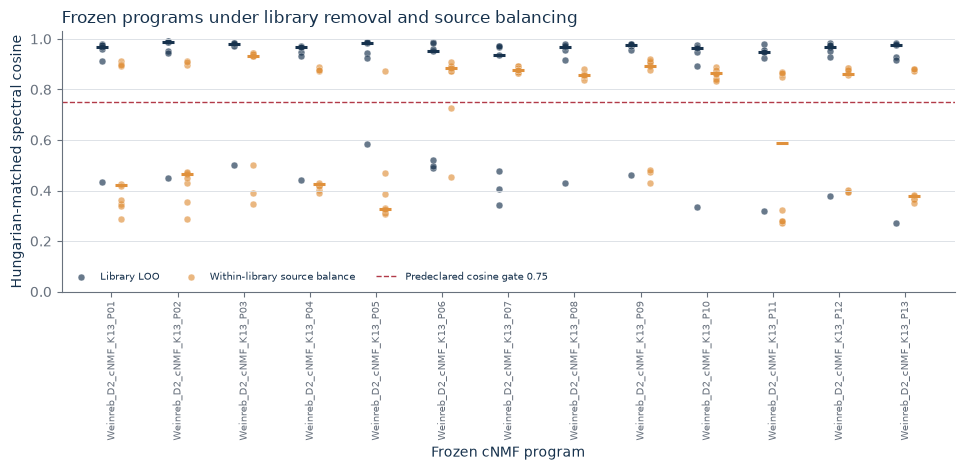

saved: analysis_workspace/analyses/weinreb_day2_hspc_metaclone_gene_programs_20260902/figures/cnmf_04_program_recovery_stability.svg | analysis_workspace/analyses/weinreb_day2_hspc_metaclone_gene_programs_20260902/figures/cnmf_04_program_recovery_stability.png


In [64]:
# CNMF_RECOVERY_PLOT_INLINE_V1 — spectral recovery sensitivities
plot_stem = "cnmf_04_program_recovery_stability"
plot_data = cnmf_program_recovery.copy()
sensitivity_offset = {
    "leave_one_library_out": -0.14,
    "within_library_prog1_prog2_balance": 0.14,
}
program_x = {program: i for i, program in enumerate(cnmf_program_ids)}
plot_data["x"] = plot_data.program.map(program_x) + plot_data.sensitivity.map(sensitivity_offset)
plot_data.to_csv(TABLEDIR / f"{plot_stem}_plot_data.csv", index=False)

fig, ax = plt.subplots(figsize=(max(8.5, 0.75 * CNMF_SELECTED_K), 4.8))
style = {
    "leave_one_library_out": (INK, "Library LOO"),
    "within_library_prog1_prog2_balance": (ORANGE, "Within-library source balance"),
}
for sensitivity, frame in plot_data.groupby("sensitivity", sort=False):
    color, label = style[sensitivity]
    ax.scatter(frame.x, frame.matched_spectrum_cosine, s=24, alpha=0.65,
               color=color, edgecolors=WHITE, linewidths=0.3, label=label)
    medians = frame.groupby("program", observed=True).matched_spectrum_cosine.median()
    xs = np.array([program_x[p] + sensitivity_offset[sensitivity] for p in medians.index])
    ax.scatter(xs, medians.to_numpy(), s=70, marker="_", linewidths=2.2,
               color=color)
ax.axhline(CNMF_RECOVERY_COSINE_GATE, color="#B23A48", linestyle="--",
           linewidth=1.0, label=f"Predeclared cosine gate {CNMF_RECOVERY_COSINE_GATE:.2f}")
ax.set_xticks(range(CNMF_SELECTED_K), cnmf_program_ids, rotation=90, fontsize=7)
ax.set(xlabel="Frozen cNMF program", ylabel="Hungarian-matched spectral cosine",
       ylim=(0, 1.03))
ax.set_title("Frozen programs under library removal and source balancing", loc="left")
ax.grid(axis="y", color=LIGHT_GREY, linewidth=0.6)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, fontsize=7.5, ncol=3, loc="lower left")
fig.tight_layout()
svg = FIGDIR / f"{plot_stem}.svg"
png = FIGDIR / f"{plot_stem}.png"
fig.savefig(svg, bbox_inches="tight")
fig.savefig(png, dpi=300, bbox_inches="tight")
display(fig)
print("saved:", svg.relative_to(PROJECT_ROOT), "|", png.relative_to(PROJECT_ROOT))
plt.close(fig)

### Clone-level sensitivity to library removal and source composition

Library leave-one-out inference removes cells, re-averages the frozen
per-cell usage within surviving LARRY clones, recomputes library
fractions, rebuilds full-rank designs, and refits HC3 models. It covers
all 94 broad contrasts and the exact 14 targeted contrasts. Separately,
clone `prog_2` fraction is added to the full-data designs only as a
sensitivity covariate; because source composition and metaclone are
strongly associated, this conditional estimand is not promoted over
the prespecified pooled-HSPC analysis.

In [65]:
# Reusable clone-level design for true cell-removal cNMF inference
def aggregate_frozen_usage_by_clone(cell_frame):
    usage = cnmf_cell_usage_fraction.loc[cell_frame.index, cnmf_program_ids]
    clone_usage = usage.join(cell_frame[["LARRY_ID"]]).groupby(
        "LARRY_ID", observed=True
    )[cnmf_program_ids].mean()
    rows = []
    for clone, clone_cells in cell_frame.groupby("LARRY_ID", observed=True):
        assert clone_cells.metaclone.nunique() == 1
        mc = int(clone_cells.metaclone.iloc[0])
        library_counts = clone_cells.Library.astype(str).value_counts()
        source_counts = clone_cells.cell_type.astype(str).value_counts()
        record = {
            "sample": str(clone), "clone": str(clone), "metaclone": mc,
            "mc_group": f"MC{mc}", "multi_mc_group": f"MC{mc}",
            "lineage_bias": MC_TO_FAMILY[mc],
            "lineage_bias_key": MC_TO_FAMILY_KEY[mc],
            "n_cells": int(len(clone_cells)),
            "n_prog_1_cells": int(source_counts.get("prog_1", 0)),
            "n_prog_2_cells": int(source_counts.get("prog_2", 0)),
        }
        for library in day2_libraries:
            record[f"libfrac__{safe_name(library)}"] = float(
                library_counts.get(library, 0) / len(clone_cells)
            )
        rows.append(record)
    metadata = pd.DataFrame(rows).set_index("sample").loc[clone_usage.index]
    return clone_usage, metadata

def prepare_usage_design_metadata(metadata, selection_factor, suffix):
    frame = metadata.copy()
    canonical_library_fractions = {
        f"libfrac__{safe_name(library)}" for library in day2_libraries
    }
    generated_library_columns = [
        column for column in frame.columns
        if column.startswith("libfrac__")
        and column not in canonical_library_fractions
    ]
    frame = frame.drop(columns=generated_library_columns)
    assert canonical_library_fractions.issubset(frame.columns)
    frame[selection_factor] = frame[selection_factor].astype(str)
    frame, covariates, reference, dropped = select_library_covariates(
        frame, selection_factor, suffix
    )
    return frame, covariates, reference, dropped

def manual_usage_design(metadata, factor, levels, covariates):
    factor_values = pd.Categorical(
        metadata[factor].astype(str), categories=list(levels), ordered=True
    )
    assert not pd.isna(factor_values).any()
    dummies = pd.get_dummies(factor_values, drop_first=True, dtype=float)
    dummies.index = metadata.index
    dummies.columns = [f"{factor}::{level}" for level in levels[1:]]
    design = pd.DataFrame({"Intercept": np.ones(len(metadata))}, index=metadata.index)
    for column in covariates:
        design[column] = metadata[column].to_numpy(float)
    design = pd.concat([design, dummies], axis=1)
    assert np.linalg.matrix_rank(design.to_numpy(float)) == design.shape[1]
    return design

def manual_group_row(design_columns, factor, levels, level):
    row = pd.Series(0.0, index=design_columns)
    row["Intercept"] = 1.0
    if str(level) != str(levels[0]):
        row[f"{factor}::{level}"] = 1.0
    return row.to_numpy(float)

def manual_contrast_vector(design, factor, levels, targets, references):
    target = np.mean(np.vstack([
        manual_group_row(design.columns, factor, levels, value)
        for value in targets
    ]), axis=0)
    reference = np.mean(np.vstack([
        manual_group_row(design.columns, factor, levels, value)
        for value in references
    ]), axis=0)
    vector = target - reference
    nonfactor = [
        index for index, column in enumerate(design.columns)
        if not column.startswith(f"{factor}::")
    ]
    assert np.allclose(vector[nonfactor], 0.0, atol=1e-12)
    return vector

def fit_manual_usage_models(scores, design):
    assert scores.index.tolist() == design.index.tolist()
    return {
        program: sm.OLS(
            scores[program].to_numpy(float), design.to_numpy(float)
        ).fit(cov_type="HC3")
        for program in cnmf_program_ids
    }

def usage_fit_is_estimable(fit, expected_n):
    return bool(
        int(fit.nobs) == int(expected_n)
        and float(fit.df_resid) > 0
        and np.isfinite(np.asarray(fit.params, dtype=float)).all()
        and np.isfinite(np.asarray(fit.bse, dtype=float)).all()
        and np.isfinite(np.asarray(fit.pvalues, dtype=float)).all()
    )

def loo_pair_support(metadata, target_mc, reference_mc):
    qualifying = []
    for library in day2_libraries:
        column = f"libfrac__{safe_name(library)}"
        target_n = int(
            ((metadata.metaclone == int(target_mc)) & (metadata[column] > 0)).sum()
        )
        reference_n = int(
            ((metadata.metaclone == int(reference_mc)) & (metadata[column] > 0)).sum()
        )
        if target_n >= 3 and reference_n >= 3:
            qualifying.append(str(library))
    return qualifying

# Independent equivalence check on the complete data before LOO use.
full_manual_metadata, full_manual_covariates, full_manual_reference, _ = (
    prepare_usage_design_metadata(pseudobulk_metadata, "mc_group", "cnmf_fullcheck")
)
full_manual_mc = manual_usage_design(
    full_manual_metadata, "mc_group", [f"MC{mc}" for mc in MC_ORDER],
    full_manual_covariates,
)
full_manual_family = manual_usage_design(
    full_manual_metadata, "lineage_bias_key", FAMILY_KEY_ORDER,
    full_manual_covariates,
)
manual_mc_fits = fit_manual_usage_models(cnmf_clone_scores, full_manual_mc)
manual_family_fits = fit_manual_usage_models(cnmf_clone_scores, full_manual_family)
equivalence_errors = []
for spec in contrast_specs:
    factor = "mc_group" if spec["model"] == "metaclone" else "lineage_bias_key"
    levels = [f"MC{mc}" for mc in MC_ORDER] if spec["model"] == "metaclone" else FAMILY_KEY_ORDER
    design = full_manual_mc if spec["model"] == "metaclone" else full_manual_family
    fits = manual_mc_fits if spec["model"] == "metaclone" else manual_family_fits
    vector = manual_contrast_vector(
        design, factor, levels, spec["target_levels"], spec["reference_levels"]
    )
    observed = cnmf_broad_tests[
        cnmf_broad_tests.contrast_id == spec["contrast_id"]
    ].set_index("program").effect_sd
    projected = pd.Series({
        program: float(np.asarray(fit.params) @ vector)
        for program, fit in fits.items()
    })
    equivalence_errors.append({
        "contrast_id": spec["contrast_id"],
        "max_abs_effect_error": float((observed - projected).abs().max()),
    })
cnmf_manual_design_equivalence = pd.DataFrame(equivalence_errors)
assert (cnmf_manual_design_equivalence.max_abs_effect_error < 1e-9).all()
cnmf_manual_design_equivalence.to_csv(
    TABLEDIR / "cnmf_manual_design_equivalence_audit.csv", index=False
)

cnmf_loo_broad_parts = []
cnmf_loo_targeted_parts = []
cnmf_loo_fit_rows = []
for omitted_library in day2_libraries:
    surviving_cells = hspc_cells[hspc_cells.Library != omitted_library].copy()
    clone_usage, metadata = aggregate_frozen_usage_by_clone(surviving_cells)
    assert set(metadata.mc_group) == {f"MC{mc}" for mc in MC_ORDER}
    scores = (clone_usage - clone_usage.mean(axis=0)) / clone_usage.std(axis=0, ddof=1)
    prepared, covariates, reference, dropped = prepare_usage_design_metadata(
        metadata, "mc_group", f"cnmf_loo_{safe_name(omitted_library)}"
    )
    mc_levels = [f"MC{mc}" for mc in MC_ORDER]
    mc_loo_design = manual_usage_design(prepared, "mc_group", mc_levels, covariates)
    family_loo_design = manual_usage_design(
        prepared, "lineage_bias_key", FAMILY_KEY_ORDER, covariates
    )
    mc_loo_fits = fit_manual_usage_models(scores, mc_loo_design)
    family_loo_fits = fit_manual_usage_models(scores, family_loo_design)
    broad_program_variance_ok = scores.std(axis=0, ddof=1).gt(1e-12)
    broad_rows = []
    for spec in contrast_specs:
        factor = "mc_group" if spec["model"] == "metaclone" else "lineage_bias_key"
        levels = mc_levels if spec["model"] == "metaclone" else FAMILY_KEY_ORDER
        design = mc_loo_design if spec["model"] == "metaclone" else family_loo_design
        fits = mc_loo_fits if spec["model"] == "metaclone" else family_loo_fits
        vector = manual_contrast_vector(
            design, factor, levels, spec["target_levels"], spec["reference_levels"]
        )
        qualifying_shared_libraries = (
            loo_pair_support(metadata, spec["target_mc"], spec["reference_mc"])
            if spec["tier"] == "within_lineage_pairwise"
            else []
        )
        loo_support_gate = bool(qualifying_shared_libraries) if (
            spec["tier"] == "within_lineage_pairwise"
        ) else bool(spec["support_gate"])
        for program, fit in fits.items():
            test = fit.t_test(vector)
            test_values = np.asarray([
                np.asarray(test.effect).squeeze(),
                np.asarray(test.sd).squeeze(),
                np.asarray(test.pvalue).squeeze(),
            ], dtype=float)
            estimable = bool(
                broad_program_variance_ok.loc[program]
                and usage_fit_is_estimable(fit, len(scores))
                and np.isfinite(test_values).all()
            )
            broad_rows.append({
                "omitted_library": omitted_library,
                "program": program, "model": spec["model"], "tier": spec["tier"],
                "contrast_id": spec["contrast_id"],
                "support_gate": loo_support_gate,
                "qualifying_shared_libraries_ge3_per_arm": "|".join(
                    qualifying_shared_libraries
                ),
                "effect_sd": float(np.asarray(test.effect).squeeze()),
                "standard_error": float(np.asarray(test.sd).squeeze()),
                "pvalue": float(np.asarray(test.pvalue).squeeze()),
                "estimable": estimable,
            })
    cnmf_loo_broad_parts.append(pd.DataFrame(broad_rows))

    target_mask = prepared.metaclone.isin(TARGET_MCS)
    target_metadata = prepared.loc[target_mask].copy()
    target_usage = clone_usage.loc[target_metadata.index]
    target_scores = (
        target_usage - target_usage.mean(axis=0)
    ) / target_usage.std(axis=0, ddof=1)
    target_prepared, target_covariates, target_reference, target_dropped = (
        prepare_usage_design_metadata(
            target_metadata, "multi_mc_group",
            f"cnmf_target_loo_{safe_name(omitted_library)}",
        )
    )
    target_levels = [f"MC{mc}" for mc in TARGET_MCS]
    target_loo_design = manual_usage_design(
        target_prepared, "multi_mc_group", target_levels, target_covariates
    )
    target_loo_fits = fit_manual_usage_models(target_scores, target_loo_design)
    target_program_variance_ok = target_scores.std(axis=0, ddof=1).gt(1e-12)
    targeted_rows = []
    for spec in targeted_specs:
        vector = manual_contrast_vector(
            target_loo_design, "multi_mc_group", target_levels,
            spec["target_levels"], spec["reference_levels"],
        )
        role = spec["role"]
        if role == "member":
            axis = next(axis for axis in BEHAVIOR_AXES if axis["axis_id"] == spec["axis_id"])
            role = "member1" if int(spec["member_mc"]) == axis["focal_mcs"][0] else "member2"
        for program, fit in target_loo_fits.items():
            test = fit.t_test(vector)
            test_values = np.asarray([
                np.asarray(test.effect).squeeze(),
                np.asarray(test.sd).squeeze(),
                np.asarray(test.pvalue).squeeze(),
            ], dtype=float)
            estimable = bool(
                target_program_variance_ok.loc[program]
                and usage_fit_is_estimable(fit, len(target_scores))
                and np.isfinite(test_values).all()
            )
            targeted_rows.append({
                "omitted_library": omitted_library,
                "analysis": spec["analysis"], "axis_id": spec["axis_id"],
                "axis_label": spec["axis_label"], "role": role,
                "member_mc": spec["member_mc"], "contrast_id": spec["contrast_id"],
                "program": program,
                "effect_sd": float(np.asarray(test.effect).squeeze()),
                "standard_error": float(np.asarray(test.sd).squeeze()),
                "pvalue": float(np.asarray(test.pvalue).squeeze()),
                "estimable": estimable,
            })
    cnmf_loo_targeted_parts.append(pd.DataFrame(targeted_rows))
    broad_frame = pd.DataFrame(broad_rows)
    targeted_frame = pd.DataFrame(targeted_rows)
    cnmf_loo_fit_rows.append({
        "omitted_library": omitted_library,
        "removed_assigned_cells": int((hspc_cells.Library == omitted_library).sum()),
        "remaining_assigned_cells": int(len(surviving_cells)),
        "remaining_clone_units": int(len(metadata)),
        "remaining_targeted_clone_units": int(len(target_metadata)),
        "broad_reference_library": reference,
        "broad_library_covariates": "|".join(covariates),
        "broad_rank_dropped": "|".join(dropped),
        "target_reference_library": target_reference,
        "target_library_covariates": "|".join(target_covariates),
        "target_rank_dropped": "|".join(target_dropped),
        "broad_mc_design_rank": int(np.linalg.matrix_rank(mc_loo_design)),
        "broad_mc_design_columns": int(mc_loo_design.shape[1]),
        "target_design_rank": int(np.linalg.matrix_rank(target_loo_design)),
        "target_design_columns": int(target_loo_design.shape[1]),
        "broad_all_programs_variable": bool(broad_program_variance_ok.all()),
        "target_all_programs_variable": bool(target_program_variance_ok.all()),
        "broad_all_fit_nobs_match": bool(all(
            int(fit.nobs) == len(scores)
            for fit in list(mc_loo_fits.values()) + list(family_loo_fits.values())
        )),
        "target_all_fit_nobs_match": bool(all(
            int(fit.nobs) == len(target_scores)
            for fit in target_loo_fits.values()
        )),
        "broad_all_tests_estimable": bool(broad_frame.estimable.all()),
        "target_all_tests_estimable": bool(targeted_frame.estimable.all()),
        "broad_outcome_index_matches_metadata": bool(
            scores.index.tolist() == prepared.index.tolist()
        ),
        "target_outcome_index_matches_metadata": bool(
            target_scores.index.tolist() == target_prepared.index.tolist()
        ),
        "estimable": bool(
            broad_frame.estimable.all() and targeted_frame.estimable.all()
        ),
    })
    print("clone-level cNMF inference LOO:", omitted_library)

cnmf_library_loo_broad = pd.concat(cnmf_loo_broad_parts, ignore_index=True)
cnmf_library_loo_targeted = pd.concat(cnmf_loo_targeted_parts, ignore_index=True)
cnmf_library_loo_fit_audit = pd.DataFrame(cnmf_loo_fit_rows)
assert len(cnmf_library_loo_broad) == 7 * 94 * CNMF_SELECTED_K
assert len(cnmf_library_loo_targeted) == 7 * 14 * CNMF_SELECTED_K
assert len(cnmf_library_loo_fit_audit) == len(day2_libraries) == 7
assert cnmf_library_loo_fit_audit.estimable.notna().all()
cnmf_library_loo_broad.to_csv(
    TABLEDIR / "cnmf_library_loo_broad_clone_effects.csv.gz",
    index=False, compression="gzip",
)
cnmf_library_loo_targeted.to_csv(
    TABLEDIR / "cnmf_library_loo_targeted_clone_effects.csv.gz",
    index=False, compression="gzip",
)
cnmf_library_loo_fit_audit.to_csv(
    TABLEDIR / "cnmf_library_loo_clone_model_audit.csv", index=False
)

broad_primary_direction = cnmf_broad_tests[[
    "contrast_id", "program", "effect_sd"
]].rename(columns={"effect_sd": "full_effect_sd"})
broad_loo_check = cnmf_library_loo_broad.merge(
    broad_primary_direction, on=["contrast_id", "program"], validate="many_to_one"
)
broad_loo_check["direction_agrees"] = (
    np.sign(broad_loo_check.effect_sd) == np.sign(broad_loo_check.full_effect_sd)
) & (broad_loo_check.full_effect_sd != 0) & broad_loo_check.estimable
cnmf_library_loo_broad_summary = (
    broad_loo_check.groupby(["contrast_id", "program"], observed=True)
    .agg(
        n_library_loo=("omitted_library", "size"),
        n_library_loo_estimable=("estimable", "sum"),
        n_library_loo_supported=("support_gate", "sum"),
        n_direction_agree=("direction_agrees", "sum"),
        all_library_loo_effects_finite=("estimable", "all"),
        all_library_loo_supported=("support_gate", "all"),
        all_library_loo_same_direction=("direction_agrees", "all"),
        min_abs_effect_sd=("effect_sd", lambda values: float(np.min(np.abs(values)))),
    ).reset_index()
)
cnmf_library_loo_broad_summary["complete_supported_stability"] = (
    cnmf_library_loo_broad_summary.n_library_loo.eq(len(day2_libraries))
    & cnmf_library_loo_broad_summary.all_library_loo_effects_finite
    & cnmf_library_loo_broad_summary.all_library_loo_supported
    & cnmf_library_loo_broad_summary.all_library_loo_same_direction
)
cnmf_library_loo_broad_summary.to_csv(
    TABLEDIR / "cnmf_library_loo_broad_effect_stability.csv", index=False
)

loo_primary = cnmf_library_loo_targeted[
    cnmf_library_loo_targeted.analysis == "primary_behavior_axis"
].merge(primary_direction, on=["axis_id", "program"], validate="many_to_one")
loo_primary["direction_agrees"] = (
    (np.sign(loo_primary.effect_sd) == np.sign(loo_primary.combined_effect_sd))
    & (loo_primary.combined_effect_sd != 0) & loo_primary.estimable
)
cnmf_targeted_loo_stability = (
    loo_primary.groupby(["axis_id", "program"], observed=True)
    .agg(
        library_loo_n_requested_effects=("direction_agrees", "size"),
        library_loo_n_estimable_effects=("estimable", "sum"),
        library_loo_n_direction_agree=("direction_agrees", "sum"),
        library_loo_all_effects_finite=("estimable", "all"),
        library_loo_all_estimable_same_direction=("direction_agrees", "all"),
    ).reset_index()
)
assert cnmf_targeted_loo_stability.library_loo_n_requested_effects.eq(21).all()
display(cnmf_library_loo_fit_audit)

clone-level cNMF inference LOO: LK_d2


clone-level cNMF inference LOO: LSK_d2_1


clone-level cNMF inference LOO: LSK_d2_2


clone-level cNMF inference LOO: LSK_d2_3


clone-level cNMF inference LOO: d2_1


clone-level cNMF inference LOO: d2_2


clone-level cNMF inference LOO: d2_3


,omitted_library,removed_assigned_cells,remaining_assigned_cells,remaining_clone_units,remaining_targeted_clone_units,broad_reference_library,broad_library_covariates,broad_rank_dropped,target_reference_library,target_library_covariates,...,target_design_columns,broad_all_programs_variable,target_all_programs_variable,broad_all_fit_nobs_match,target_all_fit_nobs_match,broad_all_tests_estimable,target_all_tests_estimable,broad_outcome_index_matches_metadata,target_outcome_index_matches_metadata,estimable
0,LK_d2,50,725,528,204,libfrac__LSK_d2_2,libfrac__LSK_d2_1__cnmf_loo_LK_d2_z|libfrac__L...,,libfrac__LSK_d2_3,libfrac__LSK_d2_1__cnmf_target_loo_LK_d2_z|lib...,...,12,True,True,True,True,True,True,True,True,True
1,LSK_d2_1,169,606,453,178,libfrac__LSK_d2_2,libfrac__LK_d2__cnmf_loo_LSK_d2_1_z|libfrac__L...,,libfrac__LSK_d2_3,libfrac__LK_d2__cnmf_target_loo_LSK_d2_1_z|lib...,...,12,True,True,True,True,True,True,True,True,True
2,LSK_d2_2,199,576,444,181,libfrac__LSK_d2_1,libfrac__LK_d2__cnmf_loo_LSK_d2_2_z|libfrac__L...,,libfrac__LSK_d2_3,libfrac__LK_d2__cnmf_target_loo_LSK_d2_2_z|lib...,...,12,True,True,True,True,True,True,True,True,True
3,LSK_d2_3,160,615,466,163,libfrac__LSK_d2_2,libfrac__LK_d2__cnmf_loo_LSK_d2_3_z|libfrac__L...,,libfrac__LSK_d2_1,libfrac__LK_d2__cnmf_target_loo_LSK_d2_3_z|lib...,...,12,True,True,True,True,True,True,True,True,True
4,d2_1,58,717,540,203,libfrac__LSK_d2_2,libfrac__LK_d2__cnmf_loo_d2_1_z|libfrac__LSK_d...,,libfrac__LSK_d2_3,libfrac__LK_d2__cnmf_target_loo_d2_1_z|libfrac...,...,12,True,True,True,True,True,True,True,True,True
5,d2_2,66,709,540,203,libfrac__LSK_d2_2,libfrac__LK_d2__cnmf_loo_d2_2_z|libfrac__LSK_d...,,libfrac__LSK_d2_3,libfrac__LK_d2__cnmf_target_loo_d2_2_z|libfrac...,...,12,True,True,True,True,True,True,True,True,True
6,d2_3,73,702,533,202,libfrac__LSK_d2_2,libfrac__LK_d2__cnmf_loo_d2_3_z|libfrac__LSK_d...,,libfrac__LSK_d2_3,libfrac__LK_d2__cnmf_target_loo_d2_3_z|libfrac...,...,12,True,True,True,True,True,True,True,True,True


In [66]:
# Clone prog_2-fraction covariate sensitivity on the exact full-data designs
prog2_fraction = (
    pseudobulk_metadata.n_prog_2_cells
    / (pseudobulk_metadata.n_prog_1_cells + pseudobulk_metadata.n_prog_2_cells)
).astype(float)
prog2_fraction_z = (
    prog2_fraction - prog2_fraction.mean()
) / prog2_fraction.std(ddof=0)

def append_source_covariate(design, source_z):
    out = design.copy()
    out["prog2_fraction_postfreeze_z"] = source_z.loc[out.index].to_numpy(float)
    full_rank = np.linalg.matrix_rank(out.to_numpy(float)) == out.shape[1]
    assert full_rank
    return out

mc_source_design = append_source_covariate(mc_design, prog2_fraction_z)
family_source_design = append_source_covariate(family_design, prog2_fraction_z)
targeted_source_design = append_source_covariate(
    targeted_program_design, prog2_fraction_z.loc[targeted_program_design.index]
)
source_fit_sets = {
    "metaclone": fit_manual_usage_models(cnmf_clone_scores, mc_source_design),
    "family": fit_manual_usage_models(cnmf_clone_scores, family_source_design),
}
source_sensitivity_rows = []
for spec in contrast_specs:
    fits = source_fit_sets[spec["model"]]
    vector = np.append(np.asarray(spec["vector"], dtype=float), 0.0)
    for program, fit in fits.items():
        test = fit.t_test(vector)
        source_sensitivity_rows.append({
            "scope": "broad", "contrast_id": spec["contrast_id"],
            "tier": spec["tier"], "program": program,
            "source_adjusted_effect_sd": float(np.asarray(test.effect).squeeze()),
            "source_adjusted_pvalue": float(np.asarray(test.pvalue).squeeze()),
        })
targeted_source_fits = fit_manual_usage_models(
    targeted_cnmf_scores, targeted_source_design
)
for spec in targeted_specs:
    vector = np.append(np.asarray(spec["vector"], dtype=float), 0.0)
    for program, fit in targeted_source_fits.items():
        test = fit.t_test(vector)
        source_sensitivity_rows.append({
            "scope": "targeted", "contrast_id": spec["contrast_id"],
            "tier": spec["analysis"], "program": program,
            "source_adjusted_effect_sd": float(np.asarray(test.effect).squeeze()),
            "source_adjusted_pvalue": float(np.asarray(test.pvalue).squeeze()),
        })
cnmf_source_covariate_effects = pd.DataFrame(source_sensitivity_rows)
primary_effect_lookup = pd.concat([
    cnmf_broad_tests[["contrast_id", "program", "effect_sd"]].assign(scope="broad"),
    targeted_cnmf_all[["contrast_id", "program", "effect_sd"]].assign(scope="targeted"),
], ignore_index=True).rename(columns={"effect_sd": "primary_effect_sd"})
cnmf_source_covariate_effects = cnmf_source_covariate_effects.merge(
    primary_effect_lookup, on=["scope", "contrast_id", "program"],
    validate="one_to_one",
)
cnmf_source_covariate_effects["direction_agrees"] = (
    np.sign(cnmf_source_covariate_effects.source_adjusted_effect_sd)
    == np.sign(cnmf_source_covariate_effects.primary_effect_sd)
) & (cnmf_source_covariate_effects.primary_effect_sd != 0)
cnmf_source_covariate_effects["absolute_effect_change"] = (
    cnmf_source_covariate_effects.source_adjusted_effect_sd
    - cnmf_source_covariate_effects.primary_effect_sd
).abs()
cnmf_source_covariate_effects.to_csv(
    TABLEDIR / "cnmf_prog2_fraction_covariate_effect_sensitivity.csv", index=False
)
cnmf_source_design_audit = pd.DataFrame([
    ["broad_metaclone", len(mc_source_design), mc_source_design.shape[1],
     np.linalg.matrix_rank(mc_source_design), np.linalg.cond(mc_source_design)],
    ["broad_lineage_family", len(family_source_design), family_source_design.shape[1],
     np.linalg.matrix_rank(family_source_design), np.linalg.cond(family_source_design)],
    ["targeted_seven_MC", len(targeted_source_design), targeted_source_design.shape[1],
     np.linalg.matrix_rank(targeted_source_design), np.linalg.cond(targeted_source_design)],
], columns=["model", "n_clone_units", "n_columns", "rank", "condition_number"])
cnmf_source_design_audit.to_csv(
    TABLEDIR / "cnmf_prog2_fraction_covariate_design_audit.csv", index=False
)
display(cnmf_source_design_audit)
display(
    cnmf_source_covariate_effects.groupby("scope", observed=True).agg(
        n_effects=("program", "size"),
        direction_agreement=("direction_agrees", "mean"),
    ).reset_index()
)

,model,n_clone_units,n_columns,rank,condition_number
0,broad_metaclone,569,27,27,29.472973
1,broad_lineage_family,569,12,12,7.031193
2,targeted_seven_MC,217,14,14,27.333442


,scope,n_effects,direction_agreement
0,broad,1222,0.846154
1,targeted,182,0.686813


### Post-fit annotation and conservative novelty test

Annotation begins only now. The frozen top-100 genes are compared with
all 50 fixed Hallmarks and a fixed hematopoietic reference assembled
from two pre-existing, hash-locked research marker/module registries plus
KEGG Hematopoietic Cell Lineage. The nearby Singh UCell program names
are not used because their gene memberships are unavailable in this
dataset. Technical/context flags take precedence over biological names.

Post-fit overlap flags use global overlap FDR < 0.05 with at least
three leading genes for cell-cycle, mitochondrial, ribosomal, and AP1
stress sets, and at least two for sex-associated or hemoglobin sets.
A library flag requires the metaclone-adjusted joint library test FDR
< 0.05 and partial R-squared >= 0.03; a residual QC flag requires FDR
< 0.05 and absolute rho >= 0.30 with detected-HVG complexity.

A program is considered captured by the reference family if either
(a) its top-100 overlap has global FDR < 0.05 with at least three genes,
or (b) clone usage has positive Spearman rho >= 0.50 with any fixed
Hallmark/hematopoietic score. Strong negative correlations are reported
separately because closed fractional usages can induce anticorrelation;
they are not treated as capture. A metaclone-associated program is called a
conservative *not-captured candidate* only when it additionally has a
metaclone effect passing one global BH correction across every supported
MC-specific search test, retains that direction in all seven supported,
finite library-removal refits and after `prog_2`-fraction adjustment,
passes both program-recovery sensitivities, and has no technical or
context flag. This is novelty relative to the audited reference panel,
not proof of a new biological mechanism.

In [67]:
# Hash-locked curated hematopoietic memberships, loaded only post-fit
CURATED_MODULE_SOURCE = (
    PROJECT_ROOT / "analysis_workspace/paper_figures/metaclone_gene_analysis.py"
)
CURATED_MARKER_SOURCE = (
    PROJECT_ROOT
    / "analysis_workspace/analyses/singh_full_scrna_landscape_20260806/build_notebooks.py"
)
EXPECTED_CURATED_MODULE_SHA256 = "21438bd1152dc1863068873883d33843fb9bb6eb2f9563bda90ade95114dabc1"
EXPECTED_CURATED_MARKER_SHA256 = "14662bfc08a1003e8400a80e727598a0355a03ba2eee204ecc16e97929a97a5a"
assert sha256(CURATED_MODULE_SOURCE) == EXPECTED_CURATED_MODULE_SHA256
assert sha256(CURATED_MARKER_SOURCE) == EXPECTED_CURATED_MARKER_SHA256

def literal_assignments(path, variable):
    outer_tree = ast.parse(path.read_text())
    trees = [outer_tree]
    for node in ast.walk(outer_tree):
        if (
            isinstance(node, ast.Constant)
            and isinstance(node.value, str)
            and variable in node.value
        ):
            try:
                trees.append(ast.parse(dedent(node.value)))
            except SyntaxError:
                pass
    values = []
    for tree in trees:
        for node in ast.walk(tree):
            if isinstance(node, ast.Assign):
                if any(
                    isinstance(target, ast.Name) and target.id == variable
                    for target in node.targets
                ):
                    try:
                        values.append(ast.literal_eval(node.value))
                    except Exception:
                        pass
    return values

curated_modules = literal_assignments(CURATED_MODULE_SOURCE, "CURATED_MODULES")
assert len(curated_modules) == 1
curated_modules = curated_modules[0]
marker_candidates = literal_assignments(CURATED_MARKER_SOURCE, "marker_panel")
marker_candidates = [
    value for value in marker_candidates
    if isinstance(value, dict) and {"HSC", "MPP", "Mk", "GMP"}.issubset(value)
]
assert len(marker_candidates) >= 1
curated_marker_panel = marker_candidates[0]

curated_hematopoietic_sets = {
    f"Module::{name}": {str(gene).upper() for gene in genes}
    for name, genes in curated_modules.items()
}
curated_hematopoietic_sets.update({
    f"State_marker::{state}": {str(gene).upper() for gene in genes}
    for state, genes in curated_marker_panel.items()
})
curated_hematopoietic_sets["KEGG::Hematopoietic_cell_lineage"] = set(
    kegg_sets[hematopoietic_term]
)
curated_membership_rows = []
for program, genes in curated_hematopoietic_sets.items():
    if program.startswith("Module::"):
        source = str(CURATED_MODULE_SOURCE.relative_to(PROJECT_ROOT))
        source_hash = EXPECTED_CURATED_MODULE_SHA256
    elif program.startswith("State_marker::"):
        source = str(CURATED_MARKER_SOURCE.relative_to(PROJECT_ROOT))
        source_hash = EXPECTED_CURATED_MARKER_SHA256
    else:
        source = str(KEGG_SOURCE.relative_to(PROJECT_ROOT))
        source_hash = EXPECTED_KEGG_SHA256
    for gene in sorted(genes):
        curated_membership_rows.append({
            "program": program, "gene_upper": gene,
            "source_path": source, "source_sha256": source_hash,
            "loaded_after_cnmf_freeze": True,
        })
curated_hematopoietic_membership = pd.DataFrame(curated_membership_rows)
curated_hematopoietic_membership.to_csv(
    RESOURCEDIR / "curated_hematopoietic_program_membership_20260909.csv",
    index=False,
)
curated_resource_audit = (
    curated_hematopoietic_membership.groupby(
        ["program", "source_path", "source_sha256"], observed=True
    ).gene_upper.nunique().rename("n_genes").reset_index()
)
curated_resource_audit.to_csv(
    REPORTDIR / "cnmf_curated_hematopoietic_resource_audit.csv", index=False
)
display(curated_resource_audit)

,program,source_path,source_sha256,n_genes
0,KEGG::Hematopoietic_cell_lineage,reference_workspace/data/gene_sets/KEGG_2019_Mouse.gmt,6aabbf753f6d14dd2205f47fc5e461688fa550a9685dff...,94
1,Module::AP1_early_response,analysis_workspace/paper_figures/metaclone_gene_ana...,21438bd1152dc1863068873883d33843fb9bb6eb2f9563...,17
2,Module::HSC_stemness,analysis_workspace/paper_figures/metaclone_gene_ana...,21438bd1152dc1863068873883d33843fb9bb6eb2f9563...,10
3,Module::myeloid_maturation,analysis_workspace/paper_figures/metaclone_gene_ana...,21438bd1152dc1863068873883d33843fb9bb6eb2f9563...,10
4,Module::reported_ancestry_memory,analysis_workspace/paper_figures/metaclone_gene_ana...,21438bd1152dc1863068873883d33843fb9bb6eb2f9563...,5
5,State_marker::Basophil,analysis_workspace/analyses/singh_full_scrna_landsc...,14662bfc08a1003e8400a80e727598a0355a03ba2eee20...,3
6,State_marker::Ery,analysis_workspace/analyses/singh_full_scrna_landsc...,14662bfc08a1003e8400a80e727598a0355a03ba2eee20...,3
7,State_marker::GMP,analysis_workspace/analyses/singh_full_scrna_landsc...,14662bfc08a1003e8400a80e727598a0355a03ba2eee20...,3
8,State_marker::HSC,analysis_workspace/analyses/singh_full_scrna_landsc...,14662bfc08a1003e8400a80e727598a0355a03ba2eee20...,3
9,State_marker::MPP,analysis_workspace/analyses/singh_full_scrna_landsc...,14662bfc08a1003e8400a80e727598a0355a03ba2eee20...,3


In [68]:
# Top-gene overlap, clone-score correlations, and technical/context flags
full_upper = np.char.upper(cnmf_full_genes.astype(str))
universe = set(full_upper)
upper_to_display = {}
for gene, upper in zip(cnmf_full_genes, full_upper):
    upper_to_display.setdefault(upper, gene)

reference_sets = {}
for name, genes in hallmark_sets.items():
    reference_sets[("Hallmark", name)] = set(genes) & universe
for name, genes in curated_hematopoietic_sets.items():
    reference_sets[("Curated_hematopoietic", name)] = set(genes) & universe
technical_reference_sets = {
    "Mitochondrial": {
        upper for gene, upper in zip(cnmf_full_genes, full_upper)
        if str(gene).lower().startswith("mt-")
    },
    "Ribosomal": KEGG_RIBOSOME_GENES & universe,
    "Sex_associated": SEX_AUDIT_GENES & universe,
    "Hemoglobin": {
        upper for upper in universe if HEMOGLOBIN_PATTERN.match(upper)
    },
    "Nuclear_QC_Malat1": {"MALAT1"} & universe,
}
for name, genes in technical_reference_sets.items():
    reference_sets[("Technical_audit", name)] = genes

top100_by_program = {
    program: set(
        cnmf_leading_genes.loc[
            cnmf_leading_genes.program == program, "gene"
        ].astype(str).str.upper()
    )
    for program in cnmf_program_ids
}
overlap_rows = []
universe_size = len(universe)
for program in cnmf_program_ids:
    top = top100_by_program[program] & universe
    for (reference_type, reference), genes in reference_sets.items():
        overlap = top & genes
        pvalue = float(hypergeom.sf(
            len(overlap) - 1, universe_size, len(genes), len(top)
        )) if genes else 1.0
        overlap_rows.append({
            "program": program, "reference_type": reference_type,
            "reference_program": reference,
            "universe_genes": universe_size,
            "reference_genes_in_universe": len(genes),
            "leading_genes": len(top), "overlap_n": len(overlap),
            "jaccard": len(overlap) / max(len(top | genes), 1),
            "hypergeom_pvalue": pvalue,
            "overlap_genes": "|".join(sorted(overlap)),
        })
cnmf_reference_overlap = pd.DataFrame(overlap_rows)
cnmf_reference_overlap["global_fdr"] = bh_adjust(
    cnmf_reference_overlap.hypergeom_pvalue.to_numpy(float)
)
cnmf_reference_overlap.to_csv(
    TABLEDIR / "cnmf_program_reference_gene_overlap.csv", index=False
)

# Clone-level scores for the fixed curated memberships use the same
# DESeq-normalized, gene-z matrix as the existing Hallmark analysis.
curated_score_data = {}
curated_mapping_rows = []
for reference, genes in curated_hematopoietic_sets.items():
    mapped = sorted({
        index for gene in genes for index in upper_to_indices.get(gene, [])
    })
    curated_mapping_rows.append({
        "reference_program": reference, "n_requested": len(genes),
        "n_mapped_filtered_genes": len(mapped),
    })
    if len(mapped) >= 2:
        curated_score_data[reference] = gene_z[:, mapped].mean(axis=1)
curated_clone_scores = pd.DataFrame(
    curated_score_data, index=pseudobulk_metadata.index
)
curated_clone_scores = (
    curated_clone_scores - curated_clone_scores.mean(axis=0)
) / curated_clone_scores.std(axis=0, ddof=1)
pd.DataFrame(curated_mapping_rows).to_csv(
    TABLEDIR / "cnmf_curated_hematopoietic_score_mapping.csv", index=False
)
curated_clone_scores.to_csv(
    TABLEDIR / "cnmf_curated_hematopoietic_clone_scores.csv.gz",
    compression="gzip",
)

correlation_rows = []
capture_score_families = {
    "Hallmark": program_scores,
    "Curated_hematopoietic": curated_clone_scores,
}
for cnmf_program in cnmf_program_ids:
    for reference_type, reference_scores in capture_score_families.items():
        for reference_program in reference_scores.columns:
            rho, pvalue = spearmanr(
                cnmf_clone_scores[cnmf_program],
                reference_scores[reference_program],
            )
            correlation_rows.append({
                "program": cnmf_program, "reference_type": reference_type,
                "reference_program": reference_program,
                "spearman_rho": float(rho), "pvalue": float(pvalue),
            })
cnmf_reference_correlations = pd.DataFrame(correlation_rows)
cnmf_reference_correlations["global_fdr"] = bh_adjust(
    cnmf_reference_correlations.pvalue.to_numpy(float)
)
cnmf_reference_correlations.to_csv(
    TABLEDIR / "cnmf_program_clone_score_reference_correlations.csv", index=False
)

# Library-fraction joint association and residual QC association both
# use one record per clone and adjust for current metaclone.
library_column_indices = [
    mc_design.columns.get_loc(column) for column in library_covariates
]
joint_rows = []
reduced_columns = [
    index for index, column in enumerate(mc_design.columns)
    if column not in library_covariates
]
selected_detected_per_cell = np.asarray(
    (discovery_counts[:, cnmf_hvg_indices] > 0).sum(axis=1)
).ravel()
detected_series = pd.Series(selected_detected_per_cell, index=discovery_cells)
clone_detected = detected_series.loc[hspc_cells.index].groupby(
    hspc_cells.LARRY_ID.astype(str), observed=True
).mean().reindex(pseudobulk_metadata.index)
qc_residual = sm.OLS(
    clone_detected.to_numpy(float), mc_design.to_numpy(float)
).fit().resid
for program, fit in cnmf_fits_mc.items():
    restriction = np.zeros((len(library_column_indices), mc_design.shape[1]))
    for row_index, column_index in enumerate(library_column_indices):
        restriction[row_index, column_index] = 1.0
    joint_test = fit.f_test(restriction)
    reduced_fit = sm.OLS(
        cnmf_clone_scores[program].to_numpy(float),
        mc_design.to_numpy(float)[:, reduced_columns],
    ).fit()
    partial_r2 = max(
        0.0, float((reduced_fit.ssr - fit.ssr) / max(reduced_fit.ssr, 1e-12))
    )
    program_residual = sm.OLS(
        cnmf_clone_scores[program].to_numpy(float), mc_design.to_numpy(float)
    ).fit().resid
    qc_rho, qc_pvalue = spearmanr(program_residual, qc_residual)
    joint_rows.append({
        "program": program,
        "library_joint_pvalue": float(np.asarray(joint_test.pvalue).squeeze()),
        "library_partial_r2": partial_r2,
        "residual_detected_HVG_spearman_rho": float(qc_rho),
        "residual_detected_HVG_pvalue": float(qc_pvalue),
    })
cnmf_technical_association = pd.DataFrame(joint_rows)
cnmf_technical_association["library_joint_fdr"] = bh_adjust(
    cnmf_technical_association.library_joint_pvalue.to_numpy(float)
)
cnmf_technical_association["residual_detected_HVG_fdr"] = bh_adjust(
    cnmf_technical_association.residual_detected_HVG_pvalue.to_numpy(float)
)
cnmf_technical_association.to_csv(
    TABLEDIR / "cnmf_program_technical_association_audit.csv", index=False
)

def normalized_program_label(value):
    return re.sub(r"[^A-Z0-9]+", "_", str(value).upper()).strip("_")

CELL_CYCLE_HALLMARK_KEYS = {
    "E2F_TARGETS", "G2_M_CHECKPOINT", "G2M_CHECKPOINT",
    "MITOTIC_SPINDLE",
}
# Fail closed if a future resource/display-name change would make the
# annotation rules silently match no fixed reference sets.
hallmark_reference_labels = (
    cnmf_reference_overlap.loc[
        cnmf_reference_overlap.reference_type == "Hallmark",
        "reference_program",
    ].drop_duplicates()
)
normalized_hallmark_labels = set(
    hallmark_reference_labels.map(normalized_program_label)
)
required_hallmark_labels = {
    "E2F_TARGETS", "G2_M_CHECKPOINT", "MITOTIC_SPINDLE",
}
assert required_hallmark_labels.issubset(normalized_hallmark_labels), (
    required_hallmark_labels - normalized_hallmark_labels
)
curated_reference_labels = set(
    cnmf_reference_overlap.loc[
        cnmf_reference_overlap.reference_type == "Curated_hematopoietic",
        "reference_program",
    ].drop_duplicates()
)
assert "Module::AP1_early_response" in curated_reference_labels
technical_reference_labels = set(
    cnmf_reference_overlap.loc[
        cnmf_reference_overlap.reference_type == "Technical_audit",
        "reference_program",
    ].drop_duplicates()
)
required_technical_labels = {
    "Mitochondrial", "Ribosomal", "Sex_associated", "Hemoglobin",
    "Nuclear_QC_Malat1",
}
assert required_technical_labels.issubset(technical_reference_labels), (
    required_technical_labels - technical_reference_labels
)
program_annotation_rows = []
for program in cnmf_program_ids:
    overlaps = cnmf_reference_overlap[cnmf_reference_overlap.program == program]
    technical = overlaps[overlaps.reference_type == "Technical_audit"].set_index(
        "reference_program"
    )
    biological = overlaps[overlaps.reference_type != "Technical_audit"].copy()
    best = biological.sort_values(
        ["global_fdr", "hypergeom_pvalue", "reference_type", "reference_program"]
    ).iloc[0]
    assoc = cnmf_technical_association.set_index("program").loc[program]
    def tech_overlap(name, minimum):
        return bool(
            name in technical.index
            and technical.loc[name, "global_fdr"] < 0.05
            and technical.loc[name, "overlap_n"] >= minimum
        )
    cell_cycle_rows = overlaps[
        (overlaps.reference_type == "Hallmark")
        & overlaps.reference_program.map(normalized_program_label).isin(
            CELL_CYCLE_HALLMARK_KEYS
        )
    ]
    cell_cycle = bool(
        ((cell_cycle_rows.global_fdr < 0.05)
         & (cell_cycle_rows.overlap_n >= 3)).any()
    )
    stress_rows = overlaps[
        (overlaps.reference_type == "Curated_hematopoietic")
        & (overlaps.reference_program == "Module::AP1_early_response")
    ]
    stress = bool(
        len(stress_rows)
        and (stress_rows.global_fdr.iloc[0] < 0.05)
        and (stress_rows.overlap_n.iloc[0] >= 3)
    )
    flags = {
        "cell_cycle_flag": cell_cycle,
        "mitochondrial_flag": tech_overlap("Mitochondrial", 3),
        "ribosomal_flag": tech_overlap("Ribosomal", 3),
        "sex_associated_flag": tech_overlap("Sex_associated", 2),
        "hemoglobin_context_flag": tech_overlap("Hemoglobin", 2),
        "nuclear_qc_malat1_flag": tech_overlap("Nuclear_QC_Malat1", 1),
        "stress_immediate_early_flag": stress,
        "library_associated_flag": bool(
            assoc.library_joint_fdr < 0.05 and assoc.library_partial_r2 >= 0.03
        ),
        "qc_associated_flag": bool(
            assoc.residual_detected_HVG_fdr < 0.05
            and abs(assoc.residual_detected_HVG_spearman_rho) >= 0.30
        ),
    }
    flagged_names = [name.replace("_flag", "") for name, value in flags.items() if value]
    any_flag = bool(flagged_names)
    biological_supported = bool(best.global_fdr < 0.05 and best.overlap_n >= 3)
    annotation = (
        "Flagged: " + "; ".join(flagged_names)
        if any_flag else
        (f"{best.reference_type}: {best.reference_program}" if biological_supported
         else "Unannotated by fixed references")
    )
    program_annotation_rows.append({
        "program": program,
        **flags,
        "any_technical_or_context_flag": any_flag,
        "best_reference_type": best.reference_type,
        "best_reference_program": best.reference_program,
        "best_reference_overlap_n": int(best.overlap_n),
        "best_reference_global_fdr": float(best.global_fdr),
        "postfit_annotation": annotation,
    })
cnmf_program_annotations = pd.DataFrame(program_annotation_rows)
expected_cell_cycle_programs = set(
    cnmf_reference_overlap[
        (cnmf_reference_overlap.reference_type == "Hallmark")
        & cnmf_reference_overlap.reference_program.map(
            normalized_program_label
        ).isin(CELL_CYCLE_HALLMARK_KEYS)
        & (cnmf_reference_overlap.global_fdr < 0.05)
        & (cnmf_reference_overlap.overlap_n >= 3)
    ].program
)
observed_cell_cycle_programs = set(
    cnmf_program_annotations.loc[
        cnmf_program_annotations.cell_cycle_flag, "program"
    ]
)
assert observed_cell_cycle_programs == expected_cell_cycle_programs
cnmf_program_annotations.to_csv(
    TABLEDIR / "cnmf_postfit_program_annotations.csv", index=False
)
display(cnmf_program_annotations)

,program,cell_cycle_flag,mitochondrial_flag,ribosomal_flag,sex_associated_flag,hemoglobin_context_flag,nuclear_qc_malat1_flag,stress_immediate_early_flag,library_associated_flag,qc_associated_flag,any_technical_or_context_flag,best_reference_type,best_reference_program,best_reference_overlap_n,best_reference_global_fdr,postfit_annotation
0,Weinreb_D2_cNMF_K13_P01,False,False,False,False,False,False,False,False,False,False,Hallmark,UV Response Up,4,0.569008,Unannotated by fixed references
1,Weinreb_D2_cNMF_K13_P02,False,False,False,False,False,False,False,False,False,False,Hallmark,Estrogen Response Early,4,0.569008,Unannotated by fixed references
2,Weinreb_D2_cNMF_K13_P03,False,False,False,False,False,False,False,False,False,False,Hallmark,IL-6/JAK/STAT3 Signaling,3,0.569008,Unannotated by fixed references
3,Weinreb_D2_cNMF_K13_P04,False,False,False,False,False,False,False,False,False,False,Hallmark,Protein Secretion,3,0.569008,Unannotated by fixed references
4,Weinreb_D2_cNMF_K13_P05,False,False,False,False,False,False,False,False,False,False,Hallmark,Myc Targets V2,3,0.569008,Unannotated by fixed references
5,Weinreb_D2_cNMF_K13_P06,False,False,False,False,False,False,False,False,False,False,Hallmark,TGF-beta Signaling,2,0.754819,Unannotated by fixed references
6,Weinreb_D2_cNMF_K13_P07,False,False,False,False,False,False,False,True,False,True,Hallmark,TNF-alpha Signaling via NF-kB,5,0.569008,Flagged: library_associated
7,Weinreb_D2_cNMF_K13_P08,False,False,False,False,False,False,False,True,False,True,Hallmark,E2F Targets,5,0.569008,Flagged: library_associated
8,Weinreb_D2_cNMF_K13_P09,False,False,False,False,False,False,False,False,False,False,Hallmark,Apoptosis,4,0.569008,Unannotated by fixed references
9,Weinreb_D2_cNMF_K13_P10,False,False,False,False,False,False,False,False,False,False,Curated_hematopoietic,KEGG::Hematopoietic_cell_lineage,3,0.569008,Unannotated by fixed references


In [69]:
# Complete targeted shared-signature gates and conservative novelty decision
cnmf_targeted_signatures = (
    cnmf_targeted_signatures
    .merge(cnmf_comparator_stability, on=["axis_id", "program"], validate="one_to_one")
    .merge(cnmf_targeted_loo_stability, on=["axis_id", "program"], validate="one_to_one")
)
cnmf_targeted_signatures["combined_global_fdr_pass"] = (
    cnmf_targeted_signatures.combined_global_fdr < 0.05
)
cnmf_targeted_signatures["conjunction_global_fdr_pass"] = (
    cnmf_targeted_signatures.conjunction_global_fdr < 0.05
)
cnmf_targeted_signatures["shared_behavioral_signature"] = (
    cnmf_targeted_signatures.combined_global_fdr_pass
    & cnmf_targeted_signatures.members_same_direction_as_combined
    & cnmf_targeted_signatures.conjunction_global_fdr_pass
    & cnmf_targeted_signatures.comparator_drop_all_same_direction
    & cnmf_targeted_signatures.library_loo_all_estimable_same_direction
)
cnmf_targeted_signatures["pooled_only_candidate"] = (
    cnmf_targeted_signatures.combined_global_fdr_pass
    & ~cnmf_targeted_signatures.shared_behavioral_signature
)
cnmf_targeted_signatures["pooled_only_failure_reason"] = np.select(
    [
        ~cnmf_targeted_signatures.combined_global_fdr_pass,
        ~cnmf_targeted_signatures.members_same_direction_as_combined,
        ~cnmf_targeted_signatures.conjunction_global_fdr_pass,
        ~cnmf_targeted_signatures.comparator_drop_all_same_direction,
        ~cnmf_targeted_signatures.library_loo_all_estimable_same_direction,
    ],
    [
        "combined_global_fdr_not_supported",
        "member_direction_disagreement",
        "global_max_p_conjunction_not_supported",
        "comparator_drop_direction_unstable",
        "library_loo_direction_unstable",
    ],
    default="all_shared_signature_gates_pass",
)
cnmf_targeted_signatures.to_csv(
    TABLEDIR / "cnmf_targeted_behavior_program_signatures.csv", index=False
)

recovery_wide = cnmf_program_recovery_summary.pivot(
    index="program", columns="sensitivity", values="recovery_supported"
).rename(columns={
    "leave_one_library_out": "library_recovery_supported",
    "within_library_prog1_prog2_balance": "source_balance_recovery_supported",
}).reset_index()
capture_correlation = (
    cnmf_reference_correlations.sort_values(
        ["program", "spearman_rho", "reference_type", "reference_program"],
        ascending=[True, False, True, True],
    ).groupby("program", observed=True).head(1)[[
        "program", "reference_type", "reference_program", "spearman_rho"
    ]].rename(columns={
        "reference_type": "max_positive_correlation_reference_type",
        "reference_program": "max_positive_correlation_reference_program",
        "spearman_rho": "max_positive_reference_rho",
    })
)
inverse_correlation = (
    cnmf_reference_correlations.sort_values(
        ["program", "spearman_rho", "reference_type", "reference_program"],
        ascending=[True, True, True, True],
    ).groupby("program", observed=True).head(1)[[
        "program", "reference_type", "reference_program", "spearman_rho"
    ]].rename(columns={
        "reference_type": "most_negative_correlation_reference_type",
        "reference_program": "most_negative_correlation_reference_program",
        "spearman_rho": "most_negative_reference_rho",
    })
)
capture_overlap = (
    cnmf_reference_overlap[
        cnmf_reference_overlap.reference_type != "Technical_audit"
    ].sort_values(
        ["program", "global_fdr", "overlap_n", "reference_program"],
        ascending=[True, True, False, True],
    ).groupby("program", observed=True).head(1)[[
        "program", "reference_type", "reference_program", "overlap_n",
        "jaccard", "global_fdr",
    ]].rename(columns={
        "reference_type": "best_overlap_reference_type",
        "reference_program": "best_overlap_reference_program",
        "overlap_n": "best_overlap_n", "jaccard": "best_overlap_jaccard",
        "global_fdr": "best_overlap_global_fdr",
    })
)
metaclone_tiers = {
    "all_metaclones_ovr", "within_lineage_ovr", "within_lineage_pairwise"
}
best_metaclone_effect = (
    cnmf_broad_tests[
        cnmf_broad_tests.tier.isin(metaclone_tiers)
        & cnmf_broad_tests.support_gate
    ].sort_values(
        ["program", "metaclone_search_global_fdr", "pvalue", "contrast_id"]
    ).groupby("program", observed=True).head(1)[[
        "program", "contrast_id", "contrast_label", "tier", "effect_sd",
        "pvalue", "tier_fdr", "metaclone_search_global_fdr",
    ]].rename(columns={
        "contrast_id": "best_metaclone_contrast_id",
        "contrast_label": "best_metaclone_contrast_label",
        "tier": "best_metaclone_tier",
        "effect_sd": "best_metaclone_effect_sd",
        "pvalue": "best_metaclone_pvalue",
        "tier_fdr": "best_metaclone_tier_fdr",
        "metaclone_search_global_fdr": "best_metaclone_search_global_fdr",
    })
)
novelty = (
    pd.DataFrame({"program": cnmf_program_ids})
    .merge(cnmf_program_annotations, on="program", validate="one_to_one")
    .merge(recovery_wide, on="program", validate="one_to_one")
    .merge(capture_correlation, on="program", validate="one_to_one")
    .merge(inverse_correlation, on="program", validate="one_to_one")
    .merge(capture_overlap, on="program", validate="one_to_one")
    .merge(best_metaclone_effect, on="program", validate="one_to_one")
)
novelty = novelty.merge(
    cnmf_library_loo_broad_summary.rename(columns={
        "contrast_id": "best_metaclone_contrast_id"
    })[[
        "best_metaclone_contrast_id", "program",
        "all_library_loo_same_direction", "all_library_loo_effects_finite",
        "all_library_loo_supported", "complete_supported_stability",
    ]],
    on=["best_metaclone_contrast_id", "program"], validate="one_to_one",
)
source_best = cnmf_source_covariate_effects[
    cnmf_source_covariate_effects.scope == "broad"
].rename(columns={"contrast_id": "best_metaclone_contrast_id"})[[
    "best_metaclone_contrast_id", "program", "direction_agrees",
]].rename(columns={"direction_agrees": "source_covariate_direction_agrees"})
novelty = novelty.merge(
    source_best, on=["best_metaclone_contrast_id", "program"],
    validate="one_to_one",
)
novelty["captured_by_clone_score_correlation"] = (
    novelty.max_positive_reference_rho >= 0.50
)
novelty["captured_by_gene_overlap"] = (
    (novelty.best_overlap_global_fdr < 0.05)
    & (novelty.best_overlap_n >= 3)
)
novelty["metaclone_association_supported"] = (
    novelty.best_metaclone_search_global_fdr < 0.05
)
novelty["novel_not_captured_candidate"] = (
    novelty.metaclone_association_supported
    & ~novelty.captured_by_clone_score_correlation
    & ~novelty.captured_by_gene_overlap
    & novelty.library_recovery_supported
    & novelty.source_balance_recovery_supported
    & novelty.complete_supported_stability
    & novelty.source_covariate_direction_agrees
    & ~novelty.any_technical_or_context_flag
)
novelty["novelty_decision_reason"] = np.select(
    [
        ~novelty.metaclone_association_supported,
        novelty.any_technical_or_context_flag,
        novelty.captured_by_clone_score_correlation,
        novelty.captured_by_gene_overlap,
        ~novelty.library_recovery_supported,
        ~novelty.source_balance_recovery_supported,
        ~novelty.all_library_loo_effects_finite,
        ~novelty.all_library_loo_supported,
        ~novelty.all_library_loo_same_direction,
        ~novelty.source_covariate_direction_agrees,
    ],
    [
        "no multiplicity-controlled metaclone association",
        "technical/context flag takes precedence",
        "captured by fixed clone-score correlation",
        "captured by fixed gene-set overlap",
        "library-removal program recovery failed",
        "prog-composition program recovery failed",
        "library-removal effect not finite/estimable",
        "library-removal support gate failed",
        "library-removal effect direction unstable",
        "prog2-fraction-adjusted effect direction changed",
    ],
    default="passes conservative not-captured criteria",
)
cnmf_novelty_assessment = novelty
cnmf_novelty_assessment.to_csv(
    TABLEDIR / "cnmf_metaclone_program_novelty_assessment.csv", index=False
)
display(cnmf_novelty_assessment[[
    "program", "postfit_annotation", "best_metaclone_contrast_label",
    "best_metaclone_effect_sd", "best_metaclone_search_global_fdr",
    "max_positive_reference_rho", "most_negative_reference_rho",
    "best_overlap_global_fdr",
    "novel_not_captured_candidate", "novelty_decision_reason",
]])

,program,postfit_annotation,best_metaclone_contrast_label,best_metaclone_effect_sd,best_metaclone_search_global_fdr,max_positive_reference_rho,most_negative_reference_rho,best_overlap_global_fdr,novel_not_captured_candidate,novelty_decision_reason
0,Weinreb_D2_cNMF_K13_P01,Unannotated by fixed references,MC16 vs MC22 within Neutrophil,0.816838,0.455590,0.119111,-0.034698,0.569008,False,no multiplicity-controlled metaclone association
1,Weinreb_D2_cNMF_K13_P02,Unannotated by fixed references,MC18 vs equal-MC mean of Multi-lineage peers,-0.296219,0.067320,0.114031,-0.049334,0.569008,False,no multiplicity-controlled metaclone association
2,Weinreb_D2_cNMF_K13_P03,Unannotated by fixed references,MC12 vs equal-MC mean of other 19,-0.311657,0.309891,0.111034,-0.062081,0.569008,False,no multiplicity-controlled metaclone association
3,Weinreb_D2_cNMF_K13_P04,Unannotated by fixed references,MC2 vs MC18 within Multi-lineage,-0.578174,0.612575,0.046145,-0.103882,0.569008,False,no multiplicity-controlled metaclone association
4,Weinreb_D2_cNMF_K13_P05,Unannotated by fixed references,MC7 vs MC8 within Monocyte,0.356536,0.256813,0.230553,-0.055831,0.569008,False,no multiplicity-controlled metaclone association
5,Weinreb_D2_cNMF_K13_P06,Unannotated by fixed references,MC1 vs equal-MC mean of Neutrophil peers,0.855510,0.121290,0.073133,-0.177104,0.754819,False,no multiplicity-controlled metaclone association
6,Weinreb_D2_cNMF_K13_P07,Flagged: library_associated,MC3 vs equal-MC mean of other 19,0.665766,0.007506,0.168373,-0.259449,0.569008,False,technical/context flag takes precedence
7,Weinreb_D2_cNMF_K13_P08,Flagged: library_associated,MC6 vs equal-MC mean of Monocyte peers,-0.475908,0.441835,0.310356,-0.108287,0.569008,False,no multiplicity-controlled metaclone association
8,Weinreb_D2_cNMF_K13_P09,Unannotated by fixed references,MC9 vs equal-MC mean of other 19,-0.323542,0.044412,0.187394,-0.150111,0.569008,False,library-removal program recovery failed
9,Weinreb_D2_cNMF_K13_P10,Unannotated by fixed references,MC5 vs MC3 within Multi-lineage,-0.608604,0.441835,0.126521,-0.125861,0.569008,False,no multiplicity-controlled metaclone association


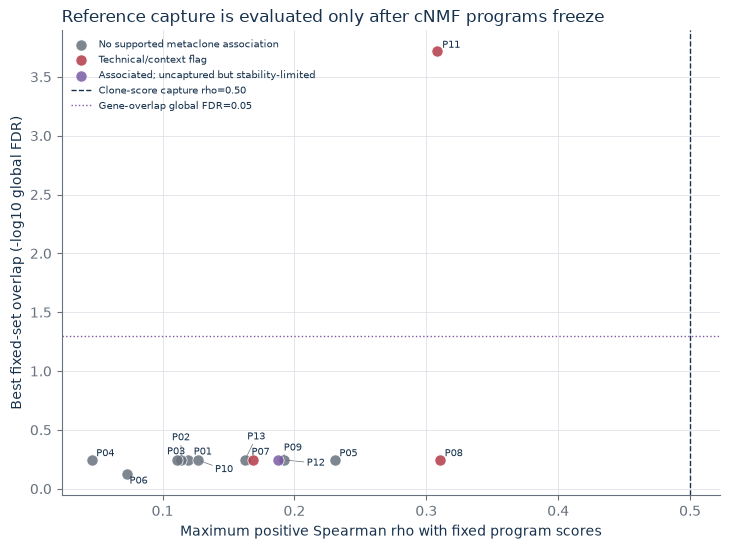

saved: analysis_workspace/analyses/weinreb_day2_hspc_metaclone_gene_programs_20260902/figures/cnmf_05_reference_capture_and_novelty.svg | analysis_workspace/analyses/weinreb_day2_hspc_metaclone_gene_programs_20260902/figures/cnmf_05_reference_capture_and_novelty.png


In [70]:
# CNMF_ANNOTATION_PLOT_INLINE_V1 — reference capture and flags
from adjustText import adjust_text

plot_stem = "cnmf_05_reference_capture_and_novelty"
plot_data = cnmf_novelty_assessment.copy()
plot_data["max_positive_reference_rho_plot"] = (
    plot_data.max_positive_reference_rho
)
plot_data["overlap_strength"] = -np.log10(
    np.clip(plot_data.best_overlap_global_fdr.to_numpy(float), 1e-300, 1.0)
)
plot_data["plot_class"] = np.select(
    [
        plot_data.novel_not_captured_candidate,
        plot_data.any_technical_or_context_flag,
        (
            plot_data.metaclone_association_supported
            & (
                plot_data.captured_by_clone_score_correlation
                | plot_data.captured_by_gene_overlap
            )
        ),
        plot_data.metaclone_association_supported,
    ],
    [
        "Not-captured candidate", "Technical/context flag",
        "Metaclone-associated; captured",
        "Associated; uncaptured but stability-limited",
    ],
    default="No supported metaclone association",
)
plot_data.to_csv(TABLEDIR / f"{plot_stem}_plot_data.csv", index=False)

class_colors = {
    "Not-captured candidate": "#3F9E4D",
    "Technical/context flag": "#B23A48",
    "Metaclone-associated; captured": ORANGE,
    "Associated; uncaptured but stability-limited": "#7A5AA6",
    "No supported metaclone association": GREY,
}
fig, ax = plt.subplots(figsize=(7.4, 5.6))
label_texts = []
for plot_class, frame in plot_data.groupby("plot_class", sort=False):
    ax.scatter(
        frame.max_positive_reference_rho_plot, frame.overlap_strength,
        s=65, color=class_colors[plot_class], alpha=0.85,
        edgecolors=WHITE, linewidths=0.6, label=plot_class,
    )
    for row in frame.itertuples(index=False):
        label_texts.append(ax.text(
            row.max_positive_reference_rho_plot,
            row.overlap_strength,
            row.program.rsplit("_", 1)[-1],
            fontsize=7, color=INK,
        ))
ax.axvline(0.50, color=INK, linestyle="--", linewidth=1.0,
           label="Clone-score capture rho=0.50")
ax.axhline(-np.log10(0.05), color="#7A5AA6", linestyle=":", linewidth=1.0,
           label="Gene-overlap global FDR=0.05")
ax.set(xlabel="Maximum positive Spearman rho with fixed program scores",
       ylabel="Best fixed-set overlap (-log10 global FDR)")
ax.set_title("Reference capture is evaluated only after cNMF programs freeze", loc="left")
ax.grid(color=LIGHT_GREY, linewidth=0.5)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, fontsize=7.2, loc="best")
np.random.seed(CNMF_ROOT_SEED + 5)
adjust_text(
    label_texts, ax=ax, ensure_inside_axes=True,
    expand=(1.25, 1.35), force_text=(0.35, 0.55),
    force_static=(0.15, 0.25),
    arrowprops={"arrowstyle": "-", "color": GREY, "linewidth": 0.5},
)
fig.tight_layout()
svg = FIGDIR / f"{plot_stem}.svg"
png = FIGDIR / f"{plot_stem}.png"
fig.savefig(svg, bbox_inches="tight")
fig.savefig(png, dpi=300, bbox_inches="tight")
display(fig)
print("saved:", svg.relative_to(PROJECT_ROOT), "|", png.relative_to(PROJECT_ROOT))
plt.close(fig)

In [71]:
# Computed cNMF findings and interpretation boundaries
selected_diagnostics = cnmf_k_diagnostics.loc[
    cnmf_k_diagnostics.selected_K
].iloc[0]
broad_supported_hits = cnmf_broad_tests[
    cnmf_broad_tests.support_gate & (cnmf_broad_tests.tier_fdr < 0.05)
].sort_values(["tier_fdr", "pvalue"])
targeted_combined_hits = cnmf_targeted_signatures[
    cnmf_targeted_signatures.combined_global_fdr < 0.05
].sort_values("combined_global_fdr")
targeted_shared_hits = cnmf_targeted_signatures[
    cnmf_targeted_signatures.shared_behavioral_signature
].sort_values("combined_global_fdr")
targeted_hit_audit = (
    targeted_combined_hits
    .merge(
        cnmf_program_annotations[[
            "program", "postfit_annotation",
            "any_technical_or_context_flag",
            "library_associated_flag",
        ]],
        on="program", validate="many_to_one",
    )
    .merge(recovery_wide, on="program", validate="many_to_one")
)
targeted_hit_audit["fully_stable_unflagged_shared_signal"] = (
    targeted_hit_audit.shared_behavioral_signature
    & targeted_hit_audit.library_recovery_supported
    & targeted_hit_audit.source_balance_recovery_supported
    & ~targeted_hit_audit.any_technical_or_context_flag
)
targeted_hit_audit.to_csv(
    TABLEDIR / "cnmf_targeted_combined_hit_interpretation.csv", index=False
)
novel_candidates = cnmf_novelty_assessment[
    cnmf_novelty_assessment.novel_not_captured_candidate
].sort_values("best_metaclone_tier_fdr")

finding_lines = [
    "INDEPENDENT DE NOVO cNMF PROGRAM FAMILY — COMPUTED FINDINGS",
    "",
    "DISCOVERY (LABEL-BLIND)",
    f"- Frozen K={CNMF_SELECTED_K}; selection mode={selection_mode}; "
    f"eligible K={','.join(map(str, eligible_k.K.tolist()))}; "
    f"stability={selected_diagnostics.consensus_silhouette_cosine:.3f}; "
    f"worst-cluster stability={selected_diagnostics.minimum_cluster_mean_silhouette:.3f}; "
    f"consensus relative error={selected_diagnostics.consensus_relative_error:.4f}.",
    f"- {CNMF_N_RESTARTS} distinct random restarts per K; "
    f"selected-K convergence={selected_diagnostics.converged_fraction:.1%}; "
    f"minimum restart coverage={selected_diagnostics.min_restart_coverage_fraction:.1%}.",
    f"- Discovery used 1,041 cells / 784 clones and 2,000 audited genes; "
    f"synthetic readout features found={int(synthetic_flag.sum())}.",
    "",
    "CLONE-LEVEL METACLONE INFERENCE",
    f"- Broad supported tier-FDR<0.05 effects: {len(broad_supported_hits)} "
    f"of {int(cnmf_broad_tests.support_gate.sum())} supported program-contrast tests.",
    f"- Targeted combined global-FDR<0.05 effects: {len(targeted_combined_hits)} "
    f"of {len(cnmf_targeted_signatures)}; full shared-signature gate: "
    f"{len(targeted_shared_hits)}.",
    f"- Post-freeze program recovery: library-removal gate "
    f"{int(recovery_wide.library_recovery_supported.sum())}/{CNMF_SELECTED_K}; "
    f"within-library prog_1/prog_2-balance gate "
    f"{int(recovery_wide.source_balance_recovery_supported.sum())}/{CNMF_SELECTED_K}.",
]
if len(targeted_hit_audit):
    finding_lines.append("- Targeted combined hits:")
    for row in targeted_hit_audit.itertuples(index=False):
        finding_lines.append(
            f"  - {row.axis_label} / {row.program}: effect={row.combined_effect_sd:+.3f} SD, "
            f"combined q={row.combined_global_fdr:.3g}, conjunction q={row.conjunction_global_fdr:.3g}, "
            f"shared={bool(row.shared_behavioral_signature)}, "
            f"annotation={row.postfit_annotation}, "
            f"library-associated={bool(row.library_associated_flag)}, "
            f"library-recovery={bool(row.library_recovery_supported)}, "
            f"source-balance-recovery={bool(row.source_balance_recovery_supported)}, "
            f"fully stable/unflagged={bool(row.fully_stable_unflagged_shared_signal)}."
        )
    finding_lines.append(
        f"- Targeted hits passing shared behavior, both program-recovery gates, "
        f"and no technical/context flag: "
        f"{int(targeted_hit_audit.fully_stable_unflagged_shared_signal.sum())}."
    )
else:
    finding_lines.append("- No targeted combined effect passes global FDR 0.05.")
finding_lines.extend([
    "",
    "POST-FIT ANNOTATION AND REFERENCE CAPTURE",
    f"- Programs with a technical/context flag: "
    f"{int(cnmf_program_annotations.any_technical_or_context_flag.sum())}/{CNMF_SELECTED_K}.",
    f"- Conservative metaclone-associated not-captured candidates: "
    f"{len(novel_candidates)}/{CNMF_SELECTED_K}.",
])
if len(novel_candidates):
    for row in novel_candidates.itertuples(index=False):
        finding_lines.append(
            f"  - {row.program}: {row.best_metaclone_contrast_label}; "
            f"effect={row.best_metaclone_effect_sd:+.3f} SD, global search q={row.best_metaclone_search_global_fdr:.3g}; "
            f"max positive fixed-score rho={row.max_positive_reference_rho:.3f}."
        )
else:
    finding_lines.append(
        "  - None pass the complete association, capture, technical, library, and source-composition gates."
    )
finding_lines.extend([
    "",
    "INTERPRETATION BOUNDARIES",
    "- cNMF discovery is cell-resolved, but every comparison and p-value uses one LARRY-clone usage value.",
    "- Program usage is compositional; increasing one fractional usage necessarily reduces others.",
    "- Metaclone and behavior-axis labels summarize later realized descendants; associations are retrospective.",
    "- No classifier or prediction model is fitted, and no result shows that a Day-2 program prospectively determines fate.",
    "- Novelty is assessed only against the fixed, hash-audited Hallmark/hematopoietic reference family.",
])
cnmf_findings_text = "\n".join(finding_lines)
(REPORTDIR / "cnmf_findings_and_boundaries.txt").write_text(
    cnmf_findings_text + "\n"
)
print(cnmf_findings_text)

INDEPENDENT DE NOVO cNMF PROGRAM FAMILY — COMPUTED FINDINGS

DISCOVERY (LABEL-BLIND)
- Frozen K=13; selection mode=protocol_amendment_fewer_than_3_eligible__stability_within_0.01_then_min_error; eligible K=11,13; stability=1.000; worst-cluster stability=1.000; consensus relative error=0.9093.
- 30 distinct random restarts per K; selected-K convergence=100.0%; minimum restart coverage=46.7%.
- Discovery used 1,041 cells / 784 clones and 2,000 audited genes; synthetic readout features found=0.

CLONE-LEVEL METACLONE INFERENCE
- Broad supported tier-FDR<0.05 effects: 8 of 1170 supported program-contrast tests.
- Targeted combined global-FDR<0.05 effects: 1 of 52; full shared-signature gate: 0.
- Post-freeze program recovery: library-removal gate 0/13; within-library prog_1/prog_2-balance gate 3/13.
- Targeted combined hits:
  - Neu-rich / Weinreb_D2_cNMF_K13_P07: effect=-0.517 SD, combined q=0.0263, conjunction q=0.447, shared=False, annotation=Flagged: library_associated, library-associa

### Z-scored clone-level cNMF usage heatmaps

These three descriptive views use the same library-adjusted means
estimated from one fractional-usage value per LARRY clone. For each
frozen program, the first heatmap standardizes across all 20
metaclones, the second across the five pooled lineage-bias families,
and the third separately across metaclones within each lineage-bias
family. Positive z-scores are red, zero is white, and negative
z-scores are blue. The Basophil family contains only MC13, so its
within-family z-score is not estimable and remains grey/NE rather
than being converted to zero. Rings mark supported tier-wide FDR
below 0.05. All three panels share a display range of -2.5 to +2.5;
unclipped z-scores and clipping flags remain in each plot-source
table. The color scale itself is descriptive and does not encode a
p-value or create a new inferential test.

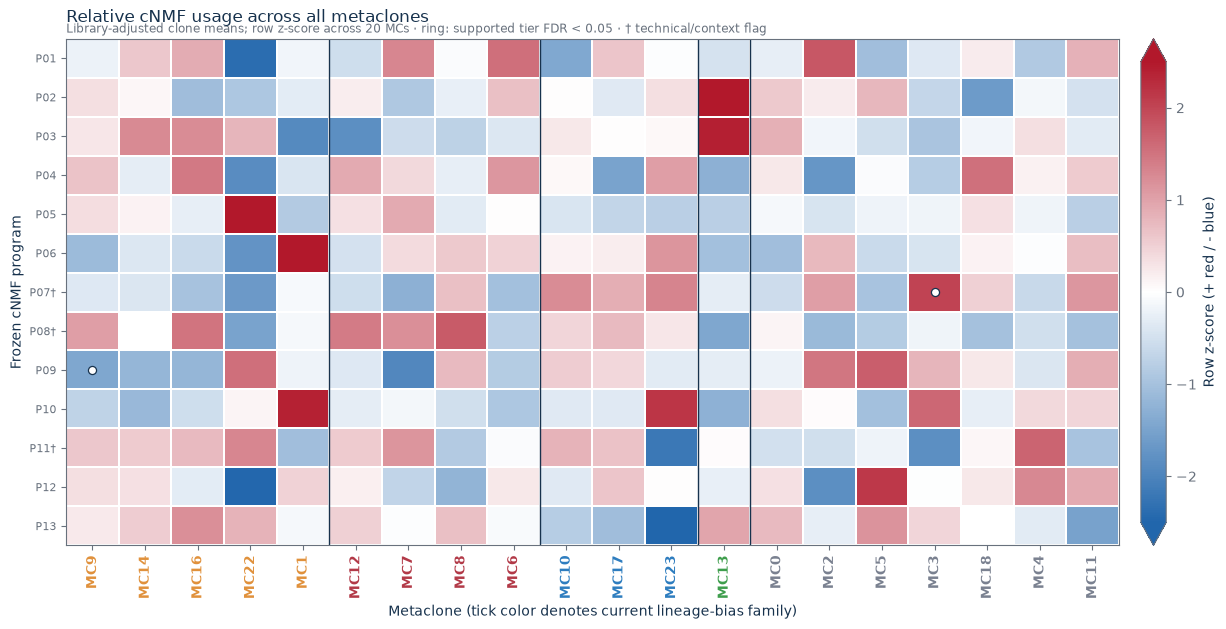

saved: analysis_workspace/analyses/weinreb_day2_hspc_metaclone_gene_programs_20260902/figures/cnmf_06_all_metaclone_usage_row_zscore_heatmap.svg | analysis_workspace/analyses/weinreb_day2_hspc_metaclone_gene_programs_20260902/figures/cnmf_06_all_metaclone_usage_row_zscore_heatmap.png


In [72]:
# CNMF_ALL_MC_ZSCORE_HEATMAP_INLINE_V1 — descriptive row z-scores across 20 MCs
plot_stem = "cnmf_06_all_metaclone_usage_row_zscore_heatmap"
cnmf_all_mc_adjusted_matrix = (
    cnmf_adjusted_mc_means.set_index("metaclone")
    .reindex(MC_ORDER)[cnmf_program_ids]
    .T
)
cnmf_all_mc_row_mean = cnmf_all_mc_adjusted_matrix.mean(axis=1)
cnmf_all_mc_row_sd = cnmf_all_mc_adjusted_matrix.std(axis=1, ddof=0)
assert cnmf_all_mc_row_sd.gt(1e-12).all()
cnmf_all_mc_zscore_matrix = (
    cnmf_all_mc_adjusted_matrix
    .sub(cnmf_all_mc_row_mean, axis=0)
    .div(cnmf_all_mc_row_sd, axis=0)
)
cnmf_all_mc_heatmap_long = (
    cnmf_all_mc_zscore_matrix.rename_axis("program").reset_index()
    .melt(id_vars="program", var_name="metaclone", value_name="row_zscore")
)
cnmf_all_mc_heatmap_long["metaclone"] = (
    cnmf_all_mc_heatmap_long.metaclone.astype(int)
)
cnmf_all_mc_adjusted_long = (
    cnmf_all_mc_adjusted_matrix.rename_axis("program").reset_index()
    .melt(
        id_vars="program", var_name="metaclone",
        value_name="adjusted_clone_usage_sd",
    )
)
cnmf_all_mc_adjusted_long["metaclone"] = (
    cnmf_all_mc_adjusted_long.metaclone.astype(int)
)
cnmf_all_mc_heatmap_long = cnmf_all_mc_heatmap_long.merge(
    cnmf_all_mc_adjusted_long,
    on=["program", "metaclone"], validate="one_to_one",
)
cnmf_all_mc_heatmap_long["lineage_bias"] = (
    cnmf_all_mc_heatmap_long.metaclone.map(MC_TO_FAMILY)
)
cnmf_all_mc_heatmap_long["program_order"] = (
    cnmf_all_mc_heatmap_long.program.map(
        {program: index for index, program in enumerate(cnmf_program_ids)}
    )
)
cnmf_all_mc_heatmap_long["metaclone_order"] = (
    cnmf_all_mc_heatmap_long.metaclone.map(
        {metaclone: index for index, metaclone in enumerate(MC_ORDER)}
    )
)
cnmf_all_mc_heatmap_long["z_reference"] = "all_20_metaclones"
cnmf_all_mc_heatmap_long["z_center"] = (
    cnmf_all_mc_heatmap_long.program.map(cnmf_all_mc_row_mean)
)
cnmf_all_mc_heatmap_long["z_scale"] = (
    cnmf_all_mc_heatmap_long.program.map(cnmf_all_mc_row_sd)
)
cnmf_all_mc_heatmap_long["z_ddof"] = 0
cnmf_all_mc_heatmap_long["z_estimable"] = True
cnmf_all_mc_heatmap_long["undefined_reason"] = ""
cnmf_all_mc_heatmap_long["display_z"] = (
    cnmf_all_mc_heatmap_long.row_zscore.clip(-2.5, 2.5)
)
cnmf_all_mc_heatmap_long["was_clipped"] = (
    cnmf_all_mc_heatmap_long.row_zscore.abs().gt(2.5)
)
cnmf_all_mc_stats = cnmf_broad_tests[
    cnmf_broad_tests.tier.eq("all_metaclones_ovr")
][[
    "program", "target_mc", "contrast_id", "effect_sd",
    "support_gate", "tier_fdr",
]].copy()
cnmf_all_mc_stats["metaclone"] = cnmf_all_mc_stats.target_mc.astype(int)
cnmf_all_mc_stats = cnmf_all_mc_stats.rename(
    columns={"effect_sd": "one_vs_rest_effect_sd"}
).drop(columns="target_mc")
cnmf_all_mc_heatmap_long = cnmf_all_mc_heatmap_long.merge(
    cnmf_all_mc_stats,
    on=["program", "metaclone"], how="left", validate="one_to_one",
)
assert cnmf_all_mc_heatmap_long.contrast_id.notna().all()
cnmf_all_mc_heatmap_long["tier_fdr_lt_0_05"] = (
    cnmf_all_mc_heatmap_long.support_gate
    & cnmf_all_mc_heatmap_long.tier_fdr.lt(0.05)
)
cnmf_all_mc_heatmap_long.to_csv(
    TABLEDIR / f"{plot_stem}_plot_data.csv", index=False
)

cnmf_flagged_programs = set(
    cnmf_program_annotations.loc[
        cnmf_program_annotations.any_technical_or_context_flag, "program"
    ]
)
cnmf_program_tick_labels = [
    f"{program.rsplit('_', 1)[-1]}{'†' if program in cnmf_flagged_programs else ''}"
    for program in cnmf_program_ids
]
cnmf_all_mc_limit = 2.5
cnmf_all_mc_cmap = LinearSegmentedColormap.from_list(
    "all_mc_negative_blue_zero_white_positive_red",
    ["#2166AC", "#FFFFFF", "#B2182B"], N=257,
)
cnmf_all_mc_cmap.set_bad("#D9DEE5")
cnmf_all_mc_norm = mpl.colors.TwoSlopeNorm(
    vmin=-cnmf_all_mc_limit, vcenter=0.0, vmax=cnmf_all_mc_limit
)

fig, ax = plt.subplots(figsize=(12.4, 6.4))
image_artist = ax.pcolormesh(
    np.arange(len(MC_ORDER) + 1),
    np.arange(CNMF_SELECTED_K + 1),
    cnmf_all_mc_zscore_matrix.to_numpy(float),
    cmap=cnmf_all_mc_cmap, norm=cnmf_all_mc_norm,
    shading="flat", edgecolors=WHITE, linewidth=0.25,
)
cnmf_all_mc_sig = cnmf_all_mc_heatmap_long[
    cnmf_all_mc_heatmap_long.tier_fdr_lt_0_05
]
cnmf_all_mc_x = {metaclone: index for index, metaclone in enumerate(MC_ORDER)}
cnmf_program_y = {program: index for index, program in enumerate(cnmf_program_ids)}
ax.scatter(
    [cnmf_all_mc_x[int(value)] + 0.5 for value in cnmf_all_mc_sig.metaclone],
    [cnmf_program_y[value] + 0.5 for value in cnmf_all_mc_sig.program],
    s=34, marker="o", facecolors=WHITE, edgecolors=INK,
    linewidths=0.9, zorder=4,
)
cnmf_family_boundaries = np.cumsum(
    [len(FAMILY_GROUPS[family]) for family in FAMILY_ORDER]
)[:-1]
for boundary in cnmf_family_boundaries:
    ax.axvline(boundary, color=INK, linewidth=1.0)
ax.set_xticks(
    np.arange(len(MC_ORDER)) + 0.5,
    [f"MC{metaclone}" for metaclone in MC_ORDER], rotation=90,
)
for tick, metaclone in zip(ax.get_xticklabels(), MC_ORDER):
    tick.set_color(FAMILY_COLORS[MC_TO_FAMILY[metaclone]])
    tick.set_fontweight("bold")
ax.set_yticks(
    np.arange(CNMF_SELECTED_K) + 0.5,
    cnmf_program_tick_labels, fontsize=8,
)
ax.set_xlim(0, len(MC_ORDER))
ax.set_ylim(0, CNMF_SELECTED_K)
ax.invert_yaxis()
ax.set_xlabel("Metaclone (tick color denotes current lineage-bias family)")
ax.set_ylabel("Frozen cNMF program")
ax.set_title("Relative cNMF usage across all metaclones", loc="left", pad=12)
ax.text(
    0, 1.012,
    "Library-adjusted clone means; row z-score across 20 MCs · ring: supported tier FDR < 0.05 · \u2020 technical/context flag",
    transform=ax.transAxes, fontsize=8.4, color=GREY,
)
colorbar = fig.colorbar(
    image_artist, ax=ax, fraction=0.027, pad=0.02, extend="both"
)
colorbar.solids.set_rasterized(False)
colorbar.set_label("Row z-score (+ red / - blue)")
fig.tight_layout()
svg = FIGDIR / f"{plot_stem}.svg"
png = FIGDIR / f"{plot_stem}.png"
fig.savefig(svg, bbox_inches="tight")
fig.savefig(png, dpi=300, bbox_inches="tight")
display(fig)
print("saved:", svg.relative_to(PROJECT_ROOT), "|", png.relative_to(PROJECT_ROOT))
plt.close(fig)

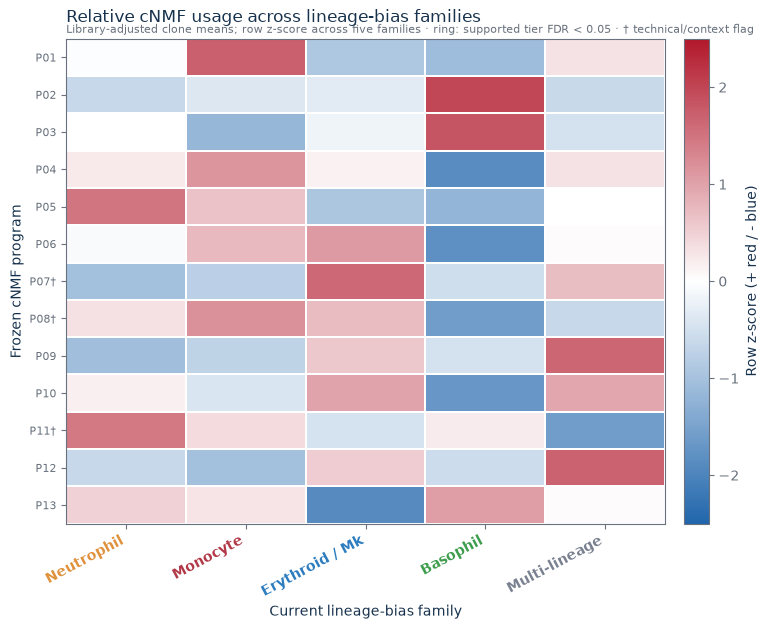

saved: analysis_workspace/analyses/weinreb_day2_hspc_metaclone_gene_programs_20260902/figures/cnmf_07_lineage_bias_usage_row_zscore_heatmap.svg | analysis_workspace/analyses/weinreb_day2_hspc_metaclone_gene_programs_20260902/figures/cnmf_07_lineage_bias_usage_row_zscore_heatmap.png


In [73]:
# CNMF_LINEAGE_BIAS_ZSCORE_HEATMAP_INLINE_V1 — descriptive row z-scores across 5 families
plot_stem = "cnmf_07_lineage_bias_usage_row_zscore_heatmap"
cnmf_family_adjusted_matrix = (
    cnmf_adjusted_family_means.set_index("lineage_bias")
    .reindex(FAMILY_ORDER)[cnmf_program_ids]
    .T
)
cnmf_family_row_mean = cnmf_family_adjusted_matrix.mean(axis=1)
cnmf_family_row_sd = cnmf_family_adjusted_matrix.std(axis=1, ddof=0)
assert cnmf_family_row_sd.gt(1e-12).all()
cnmf_family_zscore_matrix = (
    cnmf_family_adjusted_matrix
    .sub(cnmf_family_row_mean, axis=0)
    .div(cnmf_family_row_sd, axis=0)
)
cnmf_family_heatmap_long = (
    cnmf_family_zscore_matrix.rename_axis("program").reset_index()
    .melt(
        id_vars="program", var_name="lineage_bias",
        value_name="row_zscore",
    )
)
cnmf_family_adjusted_long = (
    cnmf_family_adjusted_matrix.rename_axis("program").reset_index()
    .melt(
        id_vars="program", var_name="lineage_bias",
        value_name="adjusted_clone_usage_sd",
    )
)
cnmf_family_heatmap_long = cnmf_family_heatmap_long.merge(
    cnmf_family_adjusted_long,
    on=["program", "lineage_bias"], validate="one_to_one",
)
cnmf_family_heatmap_long["program_order"] = (
    cnmf_family_heatmap_long.program.map(
        {program: index for index, program in enumerate(cnmf_program_ids)}
    )
)
cnmf_family_heatmap_long["family_order"] = (
    cnmf_family_heatmap_long.lineage_bias.map(
        {family: index for index, family in enumerate(FAMILY_ORDER)}
    )
)
cnmf_family_heatmap_long["z_reference"] = "five_lineage_bias_families"
cnmf_family_heatmap_long["z_center"] = (
    cnmf_family_heatmap_long.program.map(cnmf_family_row_mean)
)
cnmf_family_heatmap_long["z_scale"] = (
    cnmf_family_heatmap_long.program.map(cnmf_family_row_sd)
)
cnmf_family_heatmap_long["z_ddof"] = 0
cnmf_family_heatmap_long["z_estimable"] = True
cnmf_family_heatmap_long["undefined_reason"] = ""
cnmf_family_heatmap_long["display_z"] = (
    cnmf_family_heatmap_long.row_zscore.clip(-2.5, 2.5)
)
cnmf_family_heatmap_long["was_clipped"] = (
    cnmf_family_heatmap_long.row_zscore.abs().gt(2.5)
)
cnmf_family_stats = cnmf_broad_tests[
    cnmf_broad_tests.tier.eq("lineage_bias_ovr")
][[
    "program", "lineage_bias", "contrast_id", "effect_sd",
    "support_gate", "tier_fdr",
]].copy().rename(columns={"effect_sd": "one_vs_rest_effect_sd"})
cnmf_family_heatmap_long = cnmf_family_heatmap_long.merge(
    cnmf_family_stats,
    on=["program", "lineage_bias"], how="left", validate="one_to_one",
)
assert cnmf_family_heatmap_long.contrast_id.notna().all()
cnmf_family_heatmap_long["tier_fdr_lt_0_05"] = (
    cnmf_family_heatmap_long.support_gate
    & cnmf_family_heatmap_long.tier_fdr.lt(0.05)
)
cnmf_family_heatmap_long.to_csv(
    TABLEDIR / f"{plot_stem}_plot_data.csv", index=False
)

cnmf_flagged_programs = set(
    cnmf_program_annotations.loc[
        cnmf_program_annotations.any_technical_or_context_flag, "program"
    ]
)
cnmf_program_tick_labels = [
    f"{program.rsplit('_', 1)[-1]}{'†' if program in cnmf_flagged_programs else ''}"
    for program in cnmf_program_ids
]
cnmf_family_limit = 2.5
cnmf_family_cmap = LinearSegmentedColormap.from_list(
    "family_negative_blue_zero_white_positive_red",
    ["#2166AC", "#FFFFFF", "#B2182B"], N=257,
)
cnmf_family_cmap.set_bad("#D9DEE5")
cnmf_family_norm = mpl.colors.TwoSlopeNorm(
    vmin=-cnmf_family_limit, vcenter=0.0, vmax=cnmf_family_limit
)

fig, ax = plt.subplots(figsize=(8.0, 6.4))
image_artist = ax.pcolormesh(
    np.arange(len(FAMILY_ORDER) + 1),
    np.arange(CNMF_SELECTED_K + 1),
    cnmf_family_zscore_matrix.to_numpy(float),
    cmap=cnmf_family_cmap, norm=cnmf_family_norm,
    shading="flat", edgecolors=WHITE, linewidth=0.35,
)
cnmf_family_sig = cnmf_family_heatmap_long[
    cnmf_family_heatmap_long.tier_fdr_lt_0_05
]
cnmf_family_x = {family: index for index, family in enumerate(FAMILY_ORDER)}
cnmf_program_y = {program: index for index, program in enumerate(cnmf_program_ids)}
ax.scatter(
    [cnmf_family_x[value] + 0.5 for value in cnmf_family_sig.lineage_bias],
    [cnmf_program_y[value] + 0.5 for value in cnmf_family_sig.program],
    s=34, marker="o", facecolors=WHITE, edgecolors=INK,
    linewidths=0.9, zorder=4,
)
ax.set_xticks(
    np.arange(len(FAMILY_ORDER)) + 0.5,
    FAMILY_ORDER, rotation=28, ha="right",
)
for tick, family in zip(ax.get_xticklabels(), FAMILY_ORDER):
    tick.set_color(FAMILY_COLORS[family])
    tick.set_fontweight("bold")
ax.set_yticks(
    np.arange(CNMF_SELECTED_K) + 0.5,
    cnmf_program_tick_labels, fontsize=8,
)
ax.set_xlim(0, len(FAMILY_ORDER))
ax.set_ylim(0, CNMF_SELECTED_K)
ax.invert_yaxis()
ax.set_xlabel("Current lineage-bias family")
ax.set_ylabel("Frozen cNMF program")
ax.set_title("Relative cNMF usage across lineage-bias families", loc="left", pad=12)
ax.text(
    0, 1.012,
    "Library-adjusted clone means; row z-score across five families · ring: supported tier FDR < 0.05 · \u2020 technical/context flag",
    transform=ax.transAxes, fontsize=8.2, color=GREY,
)
colorbar = fig.colorbar(image_artist, ax=ax, fraction=0.043, pad=0.03)
colorbar.solids.set_rasterized(False)
colorbar.set_label("Row z-score (+ red / - blue)")
fig.tight_layout()
svg = FIGDIR / f"{plot_stem}.svg"
png = FIGDIR / f"{plot_stem}.png"
fig.savefig(svg, bbox_inches="tight")
fig.savefig(png, dpi=300, bbox_inches="tight")
display(fig)
print("saved:", svg.relative_to(PROJECT_ROOT), "|", png.relative_to(PROJECT_ROOT))
plt.close(fig)

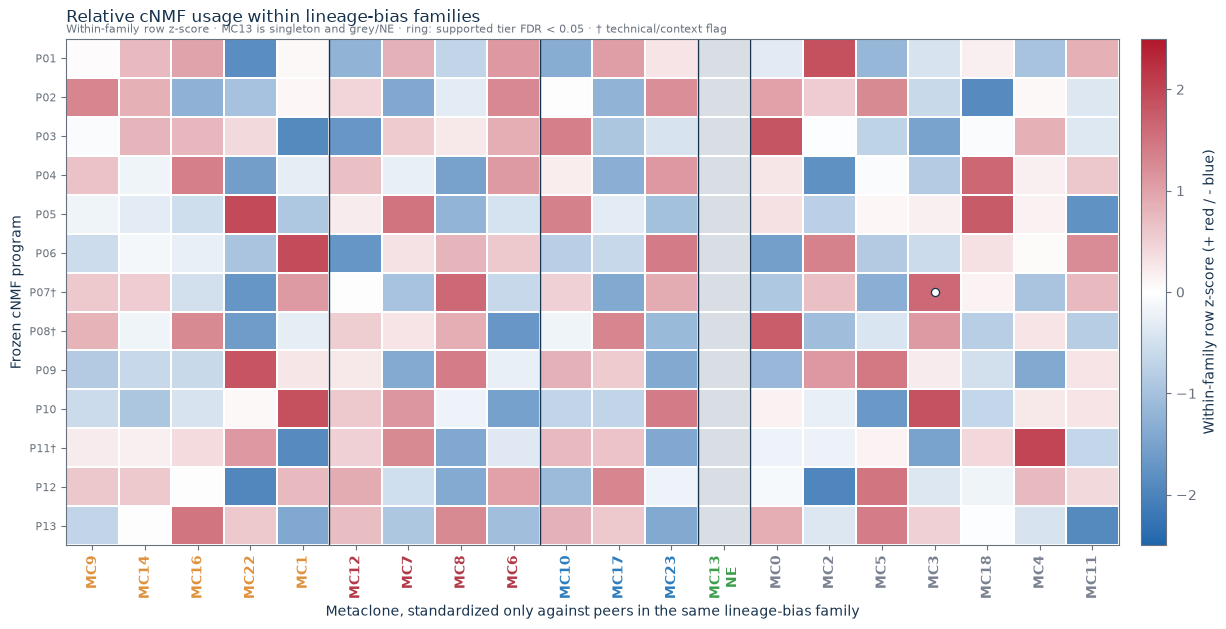

saved: analysis_workspace/analyses/weinreb_day2_hspc_metaclone_gene_programs_20260902/figures/cnmf_08_within_lineage_bias_usage_row_zscore_heatmap.svg | analysis_workspace/analyses/weinreb_day2_hspc_metaclone_gene_programs_20260902/figures/cnmf_08_within_lineage_bias_usage_row_zscore_heatmap.png


In [74]:
# CNMF_WITHIN_BIAS_ZSCORE_HEATMAP_INLINE_V1 — z-scores within each family
plot_stem = "cnmf_08_within_lineage_bias_usage_row_zscore_heatmap"
cnmf_within_family_heatmap_long = (
    cnmf_adjusted_mc_means.set_index("metaclone")
    .reindex(MC_ORDER)[cnmf_program_ids]
    .T.rename_axis("program").reset_index()
    .melt(
        id_vars="program", var_name="metaclone",
        value_name="adjusted_clone_usage_sd",
    )
)
cnmf_within_family_heatmap_long["metaclone"] = (
    cnmf_within_family_heatmap_long.metaclone.astype(int)
)
cnmf_within_family_heatmap_long["lineage_bias"] = (
    cnmf_within_family_heatmap_long.metaclone.map(MC_TO_FAMILY)
)
cnmf_within_groups = cnmf_within_family_heatmap_long.groupby(
    ["program", "lineage_bias"], observed=True
).adjusted_clone_usage_sd
cnmf_within_family_heatmap_long["family_n_metaclones"] = (
    cnmf_within_groups.transform("size")
)
cnmf_within_family_heatmap_long["family_program_mean"] = (
    cnmf_within_groups.transform("mean")
)
cnmf_within_family_heatmap_long["family_program_sd_ddof0"] = (
    cnmf_within_groups.transform(lambda values: values.std(ddof=0))
)
cnmf_within_family_heatmap_long["zscore_defined"] = (
    cnmf_within_family_heatmap_long.family_n_metaclones.ge(2)
    & cnmf_within_family_heatmap_long.family_program_sd_ddof0.gt(1e-12)
)
cnmf_within_family_heatmap_long["within_family_row_zscore"] = np.where(
    cnmf_within_family_heatmap_long.zscore_defined,
    (
        cnmf_within_family_heatmap_long.adjusted_clone_usage_sd
        - cnmf_within_family_heatmap_long.family_program_mean
    ) / cnmf_within_family_heatmap_long.family_program_sd_ddof0,
    np.nan,
)
cnmf_within_family_heatmap_long["program_order"] = (
    cnmf_within_family_heatmap_long.program.map(
        {program: index for index, program in enumerate(cnmf_program_ids)}
    )
)
cnmf_within_family_heatmap_long["metaclone_order"] = (
    cnmf_within_family_heatmap_long.metaclone.map(
        {metaclone: index for index, metaclone in enumerate(MC_ORDER)}
    )
)
cnmf_within_family_heatmap_long["family_order"] = (
    cnmf_within_family_heatmap_long.lineage_bias.map(
        {family: index for index, family in enumerate(FAMILY_ORDER)}
    )
)
cnmf_within_family_heatmap_long["z_reference"] = (
    "metaclones_within_" + cnmf_within_family_heatmap_long.lineage_bias
)
cnmf_within_family_heatmap_long["z_center"] = (
    cnmf_within_family_heatmap_long.family_program_mean
)
cnmf_within_family_heatmap_long["z_scale"] = (
    cnmf_within_family_heatmap_long.family_program_sd_ddof0
)
cnmf_within_family_heatmap_long["z_ddof"] = 0
cnmf_within_family_heatmap_long["z_estimable"] = (
    cnmf_within_family_heatmap_long.zscore_defined
)
cnmf_within_family_heatmap_long["undefined_reason"] = np.select(
    [
        cnmf_within_family_heatmap_long.family_n_metaclones.lt(2),
        cnmf_within_family_heatmap_long.family_program_sd_ddof0.le(1e-12),
    ],
    ["one metaclone in lineage-bias family", "zero within-family variance"],
    default="",
)
cnmf_within_family_heatmap_long["display_z"] = (
    cnmf_within_family_heatmap_long.within_family_row_zscore.clip(-2.5, 2.5)
)
cnmf_within_family_heatmap_long["was_clipped"] = (
    cnmf_within_family_heatmap_long.within_family_row_zscore.abs().gt(2.5)
)
cnmf_within_mc_stats = cnmf_broad_tests[
    cnmf_broad_tests.tier.eq("within_lineage_ovr")
][[
    "program", "target_mc", "contrast_id", "effect_sd",
    "support_gate", "tier_fdr",
]].copy()
cnmf_within_mc_stats["metaclone"] = cnmf_within_mc_stats.target_mc.astype(int)
cnmf_within_mc_stats = cnmf_within_mc_stats.rename(
    columns={"effect_sd": "within_family_one_vs_rest_effect_sd"}
).drop(columns="target_mc")
cnmf_within_family_heatmap_long = cnmf_within_family_heatmap_long.merge(
    cnmf_within_mc_stats,
    on=["program", "metaclone"], how="left", validate="one_to_one",
)
cnmf_within_family_heatmap_long["tier_fdr_lt_0_05"] = (
    cnmf_within_family_heatmap_long.support_gate.eq(True)
    & cnmf_within_family_heatmap_long.tier_fdr.lt(0.05)
)
cnmf_within_family_zscore_matrix = (
    cnmf_within_family_heatmap_long.pivot(
        index="program", columns="metaclone",
        values="within_family_row_zscore",
    ).reindex(index=cnmf_program_ids, columns=MC_ORDER)
)
cnmf_within_family_heatmap_long.to_csv(
    TABLEDIR / f"{plot_stem}_plot_data.csv", index=False
)

cnmf_flagged_programs = set(
    cnmf_program_annotations.loc[
        cnmf_program_annotations.any_technical_or_context_flag, "program"
    ]
)
cnmf_program_tick_labels = [
    f"{program.rsplit('_', 1)[-1]}{'†' if program in cnmf_flagged_programs else ''}"
    for program in cnmf_program_ids
]
cnmf_within_family_limit = 2.5
cnmf_within_family_cmap = LinearSegmentedColormap.from_list(
    "within_family_negative_blue_zero_white_positive_red",
    ["#2166AC", "#FFFFFF", "#B2182B"], N=257,
)
cnmf_within_family_cmap.set_bad("#D9DEE5")
cnmf_within_family_norm = mpl.colors.TwoSlopeNorm(
    vmin=-cnmf_within_family_limit,
    vcenter=0.0,
    vmax=cnmf_within_family_limit,
)

fig, ax = plt.subplots(figsize=(12.4, 6.4))
image_artist = ax.pcolormesh(
    np.arange(len(MC_ORDER) + 1),
    np.arange(CNMF_SELECTED_K + 1),
    np.ma.masked_invalid(cnmf_within_family_zscore_matrix.to_numpy(float)),
    cmap=cnmf_within_family_cmap, norm=cnmf_within_family_norm,
    shading="flat", edgecolors=WHITE, linewidth=0.25,
)
cnmf_within_sig = cnmf_within_family_heatmap_long[
    cnmf_within_family_heatmap_long.tier_fdr_lt_0_05
]
cnmf_within_x = {metaclone: index for index, metaclone in enumerate(MC_ORDER)}
cnmf_program_y = {program: index for index, program in enumerate(cnmf_program_ids)}
ax.scatter(
    [cnmf_within_x[int(value)] + 0.5 for value in cnmf_within_sig.metaclone],
    [cnmf_program_y[value] + 0.5 for value in cnmf_within_sig.program],
    s=34, marker="o", facecolors=WHITE, edgecolors=INK,
    linewidths=0.9, zorder=4,
)
cnmf_family_boundaries = np.cumsum(
    [len(FAMILY_GROUPS[family]) for family in FAMILY_ORDER]
)[:-1]
for boundary in cnmf_family_boundaries:
    ax.axvline(boundary, color=INK, linewidth=1.0)
cnmf_singleton_metaclones = {
    members[0]
    for members in FAMILY_GROUPS.values()
    if len(members) == 1
}
ax.set_xticks(
    np.arange(len(MC_ORDER)) + 0.5,
    [
        f"MC{metaclone}\nNE" if metaclone in cnmf_singleton_metaclones
        else f"MC{metaclone}"
        for metaclone in MC_ORDER
    ],
    rotation=90,
)
for tick, metaclone in zip(ax.get_xticklabels(), MC_ORDER):
    tick.set_color(FAMILY_COLORS[MC_TO_FAMILY[metaclone]])
    tick.set_fontweight("bold")
ax.set_yticks(
    np.arange(CNMF_SELECTED_K) + 0.5,
    cnmf_program_tick_labels, fontsize=8,
)
ax.set_xlim(0, len(MC_ORDER))
ax.set_ylim(0, CNMF_SELECTED_K)
ax.invert_yaxis()
ax.set_xlabel("Metaclone, standardized only against peers in the same lineage-bias family")
ax.set_ylabel("Frozen cNMF program")
ax.set_title("Relative cNMF usage within lineage-bias families", loc="left", pad=12)
ax.text(
    0, 1.012,
    "Within-family row z-score · MC13 is singleton and grey/NE · ring: supported tier FDR < 0.05 · \u2020 technical/context flag",
    transform=ax.transAxes, fontsize=8.25, color=GREY,
)
colorbar = fig.colorbar(image_artist, ax=ax, fraction=0.027, pad=0.02)
colorbar.solids.set_rasterized(False)
colorbar.set_label("Within-family row z-score (+ red / - blue)")
fig.tight_layout()
svg = FIGDIR / f"{plot_stem}.svg"
png = FIGDIR / f"{plot_stem}.png"
fig.savefig(svg, bbox_inches="tight")
fig.savefig(png, dpi=300, bbox_inches="tight")
display(fig)
print("saved:", svg.relative_to(PROJECT_ROOT), "|", png.relative_to(PROJECT_ROOT))
plt.close(fig)

In [75]:
# cNMF validation, editable-plot contract, and active manifest refresh
cnmf_plot_stems = [
    "cnmf_01_K_selection_diagnostics",
    "cnmf_02_frozen_program_leading_genes",
    "cnmf_03_adjusted_usage_by_metaclone",
    "cnmf_04_program_recovery_stability",
    "cnmf_05_reference_capture_and_novelty",
    "cnmf_06_all_metaclone_usage_row_zscore_heatmap",
    "cnmf_07_lineage_bias_usage_row_zscore_heatmap",
    "cnmf_08_within_lineage_bias_usage_row_zscore_heatmap",
]
built_notebook = nbformat.read(NOTEBOOK_PATH, as_version=4)
notebook_sources = ["".join(cell.get("source", "")) for cell in built_notebook.cells]
cnmf_plot_sources = [
    source for source in notebook_sources
    if source.lstrip().startswith((
        "# CNMF_K_SELECTION_PLOT_INLINE_V1",
        "# CNMF_SPECTRA_PLOT_INLINE_V1",
        "# CNMF_METACLONE_PLOT_INLINE_V1",
        "# CNMF_RECOVERY_PLOT_INLINE_V1",
        "# CNMF_ANNOTATION_PLOT_INLINE_V1",
        "# CNMF_ALL_MC_ZSCORE_HEATMAP_INLINE_V1",
        "# CNMF_LINEAGE_BIAS_ZSCORE_HEATMAP_INLINE_V1",
        "# CNMF_WITHIN_BIAS_ZSCORE_HEATMAP_INLINE_V1",
    ))
]
cnmf_plot_contract = all(
    source.count("plt.subplots") == 1
    and source.count("fig.savefig(svg") == 1
    and source.count("fig.savefig(png") == 1
    and source.count("display(fig)") == 1
    and source.count("plt.close(fig)") == 1
    for source in cnmf_plot_sources
)
cnmf_svg_editable = all(
    "<svg" in (FIGDIR / f"{stem}.svg").read_text(errors="ignore")
    and "<image" not in (FIGDIR / f"{stem}.svg").read_text(errors="ignore")
    for stem in cnmf_plot_stems
)
cnmf_plot_triplets = all(
    (FIGDIR / f"{stem}.svg").stat().st_size > 0
    and (FIGDIR / f"{stem}.png").stat().st_size > 0
    and (TABLEDIR / f"{stem}_plot_data.csv").stat().st_size > 0
    for stem in cnmf_plot_stems
)
unique_restart_seeds = (
    cnmf_restart_diagnostics.groupby(["context", "K"], observed=True)
    .agg(n_rows=("seed", "size"), n_unique_seeds=("seed", "nunique"))
)
recovery_counts = cnmf_program_recovery.groupby("sensitivity", observed=True).replicate.nunique()
targeted_manifest_path = REPORTDIR / "targeted_artifact_manifest.csv"
targeted_manifest_before_refresh = pd.read_csv(targeted_manifest_path)
assert targeted_manifest_before_refresh.path.is_unique
targeted_manifest_scope = sorted(targeted_manifest_before_refresh.path.tolist())
targeted_manifest_scope_paths = [
    PROJECT_ROOT / relative_path for relative_path in targeted_manifest_scope
]
assert all(path.is_file() for path in targeted_manifest_scope_paths)
targeted_manifest_scope_is_targeted = not any(
    path.name.startswith("cnmf_") for path in targeted_manifest_scope_paths
)
targeted_artifact_manifest_refreshed = pd.DataFrame([{
    "path": str(path.relative_to(PROJECT_ROOT)),
    "bytes": path.stat().st_size,
    "sha256": sha256(path),
} for path in targeted_manifest_scope_paths])
assert targeted_artifact_manifest_refreshed.path.tolist() == targeted_manifest_scope
targeted_artifact_manifest_refreshed.to_csv(targeted_manifest_path, index=False)
targeted_manifest_refresh_exact = all(
    (PROJECT_ROOT / row.path).stat().st_size == row.bytes
    and sha256(PROJECT_ROOT / row.path) == row.sha256
    for row in targeted_artifact_manifest_refreshed.itertuples(index=False)
)
cnmf_zscore_heatmap_sources = [
    source for source in cnmf_plot_sources
    if "ZSCORE_HEATMAP_INLINE_V1" in source
]
cnmf_all_mc_zscore_audit = cnmf_all_mc_heatmap_long.groupby(
    "program", observed=True
).row_zscore.agg(
    row_mean="mean", row_sd_ddof0=lambda values: values.std(ddof=0)
)
cnmf_family_zscore_audit = cnmf_family_heatmap_long.groupby(
    "program", observed=True
).row_zscore.agg(
    row_mean="mean", row_sd_ddof0=lambda values: values.std(ddof=0)
)
cnmf_within_defined = cnmf_within_family_heatmap_long[
    cnmf_within_family_heatmap_long.zscore_defined
]
cnmf_within_zscore_audit = cnmf_within_defined.groupby(
    ["program", "lineage_bias"], observed=True
).within_family_row_zscore.agg(
    row_mean="mean", row_sd_ddof0=lambda values: values.std(ddof=0)
)
cnmf_within_undefined = cnmf_within_family_heatmap_long[
    ~cnmf_within_family_heatmap_long.zscore_defined
]
cnmf_heatmap_palette_contract = all(
    "LinearSegmentedColormap.from_list" in source
    and "[\"#2166AC\", \"#FFFFFF\", \"#B2182B\"]" in source
    and "N=257" in source
    and "TwoSlopeNorm" in source
    and "vcenter=0.0" in source
    for source in cnmf_zscore_heatmap_sources
)
cnmf_heatmap_color_contract = all(
    [
        mpl.colors.to_hex(cmap(0.0)).lower(),
        mpl.colors.to_hex(cmap(0.5)).lower(),
        mpl.colors.to_hex(cmap(1.0)).lower(),
    ] == ["#2166ac", "#ffffff", "#b2182b"]
    for cmap in [
        cnmf_all_mc_cmap, cnmf_family_cmap, cnmf_within_family_cmap
    ]
)
cnmf_heatmap_clone_level_only = not any(
    token in source
    for source in cnmf_zscore_heatmap_sources
    for token in ["cnmf_cell_usage_raw", "cnmf_cell_usage_fraction"]
)
cnmf_all_mc_reconstructed = (
    cnmf_all_mc_heatmap_long.pivot(
        index="program", columns="metaclone",
        values="adjusted_clone_usage_sd",
    ).reindex(index=cnmf_program_ids, columns=MC_ORDER)
)
cnmf_family_reconstructed = (
    cnmf_family_heatmap_long.pivot(
        index="program", columns="lineage_bias",
        values="adjusted_clone_usage_sd",
    ).reindex(index=cnmf_program_ids, columns=FAMILY_ORDER)
)
cnmf_heatmap_adjusted_means_exact = (
    np.allclose(
        cnmf_all_mc_reconstructed.to_numpy(float),
        cnmf_all_mc_adjusted_matrix.to_numpy(float),
        atol=1e-12,
    )
    and np.allclose(
        cnmf_family_reconstructed.to_numpy(float),
        cnmf_family_adjusted_matrix.to_numpy(float),
        atol=1e-12,
    )
    and np.allclose(
        cnmf_within_family_heatmap_long.pivot(
            index="program", columns="metaclone",
            values="adjusted_clone_usage_sd",
        ).reindex(index=cnmf_program_ids, columns=MC_ORDER).to_numpy(float),
        cnmf_all_mc_adjusted_matrix.to_numpy(float),
        atol=1e-12,
    )
)
cnmf_heatmap_keys_complete = (
    len(cnmf_all_mc_heatmap_long) == CNMF_SELECTED_K * len(MC_ORDER)
    and len(cnmf_family_heatmap_long) == CNMF_SELECTED_K * len(FAMILY_ORDER)
    and len(cnmf_within_family_heatmap_long) == CNMF_SELECTED_K * len(MC_ORDER)
    and not cnmf_all_mc_heatmap_long.duplicated(["program", "metaclone"]).any()
    and not cnmf_family_heatmap_long.duplicated(["program", "lineage_bias"]).any()
    and not cnmf_within_family_heatmap_long.duplicated(
        ["program", "metaclone"]
    ).any()
    and cnmf_all_mc_adjusted_matrix.index.tolist() == cnmf_program_ids
    and cnmf_all_mc_adjusted_matrix.columns.tolist() == MC_ORDER
    and cnmf_family_adjusted_matrix.index.tolist() == cnmf_program_ids
    and cnmf_family_adjusted_matrix.columns.tolist() == FAMILY_ORDER
    and cnmf_within_family_zscore_matrix.index.tolist() == cnmf_program_ids
    and cnmf_within_family_zscore_matrix.columns.tolist() == MC_ORDER
)
cnmf_heatmap_display_clipping_audit = all(
    frame.loc[frame.z_estimable, "display_z"].abs().le(2.5).all()
    and frame.loc[frame.z_estimable, "was_clipped"].eq(
        frame.loc[frame.z_estimable, z_column].abs().gt(2.5)
    ).all()
    for frame, z_column in [
        (cnmf_all_mc_heatmap_long, "row_zscore"),
        (cnmf_family_heatmap_long, "row_zscore"),
        (cnmf_within_family_heatmap_long, "within_family_row_zscore"),
    ]
)
required_annotation_flags = {
    "cell_cycle_flag", "mitochondrial_flag", "ribosomal_flag",
    "sex_associated_flag", "nuclear_qc_malat1_flag",
    "library_associated_flag",
}
cnmf_inference_unit_rows = [
    {
        "model": "broad_metaclone", "unit": "LARRY_clone",
        "expected_units": len(cnmf_clone_scores),
        "unique_clone_units": pseudobulk_metadata.index.nunique(),
        "all_fit_nobs_match": all(
            int(fit.nobs) == len(cnmf_clone_scores)
            for fit in cnmf_fits_mc.values()
        ),
        "outcome_index_matches_clone_metadata": (
            cnmf_clone_scores.index.tolist() == pseudobulk_metadata.index.tolist()
        ),
    },
    {
        "model": "broad_lineage_family", "unit": "LARRY_clone",
        "expected_units": len(cnmf_clone_scores),
        "unique_clone_units": pseudobulk_metadata.index.nunique(),
        "all_fit_nobs_match": all(
            int(fit.nobs) == len(cnmf_clone_scores)
            for fit in cnmf_fits_family.values()
        ),
        "outcome_index_matches_clone_metadata": (
            cnmf_clone_scores.index.tolist() == pseudobulk_metadata.index.tolist()
        ),
    },
    {
        "model": "targeted_multilineage", "unit": "LARRY_clone",
        "expected_units": len(targeted_cnmf_scores),
        "unique_clone_units": targeted_metadata.index.nunique(),
        "all_fit_nobs_match": all(
            int(fit.nobs) == len(targeted_cnmf_scores)
            for fit in targeted_cnmf_fits.values()
        ),
        "outcome_index_matches_clone_metadata": (
            targeted_cnmf_scores.index.tolist() == targeted_metadata.index.tolist()
        ),
    },
]
for audit_row in cnmf_library_loo_fit_audit.itertuples(index=False):
    cnmf_inference_unit_rows.extend([
        {
            "model": f"library_LOO_broad::{audit_row.omitted_library}",
            "unit": "LARRY_clone",
            "expected_units": int(audit_row.remaining_clone_units),
            "unique_clone_units": int(audit_row.remaining_clone_units),
            "all_fit_nobs_match": bool(audit_row.broad_all_fit_nobs_match),
            "outcome_index_matches_clone_metadata": bool(
                audit_row.broad_outcome_index_matches_metadata
            ),
        },
        {
            "model": f"library_LOO_targeted::{audit_row.omitted_library}",
            "unit": "LARRY_clone",
            "expected_units": int(audit_row.remaining_targeted_clone_units),
            "unique_clone_units": int(audit_row.remaining_targeted_clone_units),
            "all_fit_nobs_match": bool(audit_row.target_all_fit_nobs_match),
            "outcome_index_matches_clone_metadata": bool(
                audit_row.target_outcome_index_matches_metadata
            ),
        },
    ])
cnmf_inference_unit_audit = pd.DataFrame(cnmf_inference_unit_rows)
cnmf_inference_unit_audit["passed"] = (
    cnmf_inference_unit_audit.unit.eq("LARRY_clone")
    & cnmf_inference_unit_audit.expected_units.eq(
        cnmf_inference_unit_audit.unique_clone_units
    )
    & cnmf_inference_unit_audit.all_fit_nobs_match
    & cnmf_inference_unit_audit.outcome_index_matches_clone_metadata
)
cnmf_inference_unit_audit.to_csv(
    REPORTDIR / "cnmf_inference_unit_audit.csv", index=False
)
loo_support_audit_frame = cnmf_library_loo_broad.merge(
    cnmf_broad_tests[["contrast_id", "support_gate"]]
    .drop_duplicates()
    .rename(columns={"support_gate": "full_data_support_gate"}),
    on="contrast_id", validate="many_to_one",
)
cnmf_loo_support_audit = (
    loo_support_audit_frame.groupby(
        ["omitted_library", "contrast_id"], observed=True
    ).agg(
        full_data_support_gate=("full_data_support_gate", "first"),
        loo_support_gate=("support_gate", "first"),
        all_program_rows_agree=("support_gate", "nunique"),
    ).reset_index()
)
cnmf_loo_support_audit["support_lost_after_removal"] = (
    cnmf_loo_support_audit.full_data_support_gate
    & ~cnmf_loo_support_audit.loo_support_gate
)
cnmf_loo_support_audit.to_csv(
    REPORTDIR / "cnmf_library_loo_support_recalculation_audit.csv",
    index=False,
)
expected_metaclone_global_fdr = bh_adjust(
    cnmf_broad_tests.loc[
        metaclone_search_mask, "pvalue"
    ].to_numpy(float)
)
if len(eligible_k) >= 3:
    audit_elbow_k = int(
        eligible_k.sort_values(
            ["reconstruction_elbow_distance", "K"],
            ascending=[False, True],
        ).iloc[0].K
    )
    audit_selection_candidates = eligible_k[
        (eligible_k.K - audit_elbow_k).abs() <= 1
    ]
    audit_selected_k = int(
        audit_selection_candidates.sort_values(
            ["consensus_silhouette_cosine", "K"],
            ascending=[False, True],
        ).iloc[0].K
    )
else:
    audit_selection_candidates = eligible_k[
        eligible_k.consensus_silhouette_cosine
        >= eligible_k.consensus_silhouette_cosine.max() - 0.01
    ]
    audit_selected_k = int(
        audit_selection_candidates.sort_values(
            ["consensus_relative_error", "K"],
            ascending=[True, True],
        ).iloc[0].K
    )
cnmf_validation_rows = [
    ("discovery_all_1041_cells", len(cnmf_cell_usage_fraction) == 1041, str(len(cnmf_cell_usage_fraction))),
    ("discovery_all_784_clones", len(cnmf_clone_usage_all) == 784, str(len(cnmf_clone_usage_all))),
    ("inference_569_current_MC_clones", len(cnmf_clone_scores) == 569, str(len(cnmf_clone_scores))),
    ("targeted_217_multilineage_clones", len(targeted_cnmf_scores) == 217, str(len(targeted_cnmf_scores))),
    ("no_forbidden_discovery_metadata", not (forbidden_discovery_fields & discovery_fields_used), str(sorted(discovery_fields_used))),
    ("zero_synthetic_features_entered", int(synthetic_flag[cnmf_hvg_indices].sum()) == 0, str(int(synthetic_flag[cnmf_hvg_indices].sum()))),
    ("zero_mitochondrial_features_entered", int(mitochondrial_flag[cnmf_hvg_indices].sum()) == 0, str(int(mitochondrial_flag[cnmf_hvg_indices].sum()))),
    ("zero_KEGG_ribosome_features_entered", int(ribosome_flag[cnmf_hvg_indices].sum()) == 0, str(int(ribosome_flag[cnmf_hvg_indices].sum()))),
    ("zero_Malat1_features_entered", int(nuclear_qc_flag[cnmf_hvg_indices].sum()) == 0, str(int(nuclear_qc_flag[cnmf_hvg_indices].sum()))),
    ("Malat1_absent_from_recovery_HVGs", ~cnmf_recovery_feature_selection.gene.astype(str).str.upper().eq("MALAT1").any(), str(int(cnmf_recovery_feature_selection.gene.astype(str).str.upper().eq("MALAT1").sum()))),
    ("Hbegf_not_misclassified_as_hemoglobin", not hemoglobin_flag[discovery_upper == "HBEGF"].any(), str(int(hemoglobin_flag[discovery_upper == "HBEGF"].sum()))),
    ("K_grid_complete", cnmf_k_diagnostics.K.tolist() == CNMF_K_GRID, str(CNMF_K_GRID)),
    ("random_restart_init_only", set(cnmf_restart_diagnostics.init) == {"random"}, str(set(cnmf_restart_diagnostics.init))),
    ("restart_seeds_unique_within_fit", (unique_restart_seeds.n_rows == unique_restart_seeds.n_unique_seeds).all(), str(len(unique_restart_seeds))),
    ("selected_K_passes_all_gates", bool(cnmf_k_diagnostics.loc[cnmf_k_diagnostics.selected_K, "eligible"].iloc[0]), str(CNMF_SELECTED_K)),
    ("one_selected_K", int(cnmf_k_diagnostics.selected_K.sum()) == 1, str(int(cnmf_k_diagnostics.selected_K.sum()))),
    ("K_selection_rule_reproduced", audit_selected_k == CNMF_SELECTED_K, str({"audit": audit_selected_k, "selected": CNMF_SELECTED_K, "candidates": audit_selection_candidates.K.tolist()})),
    ("frozen_HVG_spectra_complete", cnmf_hvg_spectra.shape == (CNMF_SELECTED_K, 2000), str(cnmf_hvg_spectra.shape)),
    ("frozen_all_gene_spectra_complete", cnmf_full_spectra.shape[0] == CNMF_SELECTED_K and cnmf_full_spectra.shape[1] == int(full_spectrum_mask.sum()), str(cnmf_full_spectra.shape)),
    ("top100_every_program", cnmf_leading_genes.groupby("program").size().eq(100).all(), str(cnmf_leading_genes.groupby("program").size().min())),
    ("fractional_usage_sums_one", np.allclose(cnmf_cell_usage_fraction.sum(axis=1), 1.0), str(float(np.max(np.abs(cnmf_cell_usage_fraction.sum(axis=1) - 1))))),
    ("broad_94_registry_mirror", len(cnmf_broad_tests) == 94 * CNMF_SELECTED_K, str(len(cnmf_broad_tests))),
    ("targeted_14_registry_mirror", len(targeted_cnmf_all) == 14 * CNMF_SELECTED_K, str(len(targeted_cnmf_all))),
    ("novelty_search_global_BH_exact", np.allclose(cnmf_broad_tests.loc[metaclone_search_mask, "metaclone_search_global_fdr"], expected_metaclone_global_fdr), str(int(metaclone_search_mask.sum()))),
    ("manual_design_equivalent", (cnmf_manual_design_equivalence.max_abs_effect_error < 1e-9).all(), str(cnmf_manual_design_equivalence.max_abs_effect_error.max())),
    ("seven_library_program_refits", int(recovery_counts.get("leave_one_library_out", 0)) == 7, str(recovery_counts.to_dict())),
    ("ten_source_balance_refits", int(recovery_counts.get("within_library_prog1_prog2_balance", 0)) == 10, str(recovery_counts.to_dict())),
    ("sensitivity_HVGs_reselected", cnmf_program_recovery.refit_reselected_HVGs.all() and len(cnmf_recovery_feature_selection) == 17 * CNMF_N_HVG, str(len(cnmf_recovery_feature_selection))),
    ("sensitivity_common_HVG_support", int(cnmf_program_recovery.n_common_HVGs.min()) >= 500, str(int(cnmf_program_recovery.n_common_HVGs.min()))),
    ("seven_library_inference_refits_audited", len(cnmf_library_loo_fit_audit) == 7 and cnmf_library_loo_fit_audit.estimable.notna().all(), str({"refits": len(cnmf_library_loo_fit_audit), "fully_estimable": int(cnmf_library_loo_fit_audit.estimable.sum())})),
    ("library_LOO_support_recomputed", cnmf_loo_support_audit.all_program_rows_agree.eq(1).all() and cnmf_loo_support_audit.support_lost_after_removal.any(), str(int(cnmf_loo_support_audit.support_lost_after_removal.sum()))),
    ("targeted_LOO_library_candidates_canonical", ~cnmf_library_loo_fit_audit.target_rank_dropped.str.contains("__cnmf_loo_", regex=False).any(), "generated standardized columns excluded"),
    ("source_covariate_models_full_rank", (cnmf_source_design_audit.n_columns == cnmf_source_design_audit["rank"]).all(), cnmf_source_design_audit.n_columns.astype(str).str.cat(sep="|")),
    ("annotation_flags_explicit", required_annotation_flags.issubset(cnmf_program_annotations.columns), str(sorted(required_annotation_flags))),
    ("annotation_reference_labels_resolved", required_hallmark_labels.issubset(normalized_hallmark_labels) and "Module::AP1_early_response" in curated_reference_labels and required_technical_labels.issubset(technical_reference_labels), "fixed Hallmark/AP1/technical labels present"),
    ("cell_cycle_flags_match_fixed_Hallmark_rule", observed_cell_cycle_programs == expected_cell_cycle_programs, str(sorted(observed_cell_cycle_programs))),
    ("targeted_hit_interpretation_complete", len(targeted_hit_audit) == len(targeted_combined_hits) and targeted_hit_audit[["postfit_annotation", "library_recovery_supported", "source_balance_recovery_supported"]].notna().all().all(), str(len(targeted_hit_audit))),
    ("curated_membership_loaded_postfreeze", curated_hematopoietic_membership.loaded_after_cnmf_freeze.all(), str(len(curated_hematopoietic_membership))),
    ("all_inferential_models_use_unique_clone_units", cnmf_inference_unit_audit.passed.all(), f"{int(cnmf_inference_unit_audit.passed.sum())}/{len(cnmf_inference_unit_audit)} model contexts"),
    ("all_metaclone_heatmap_rows_zscored", np.allclose(cnmf_all_mc_zscore_audit.row_mean, 0.0, atol=1e-12) and np.allclose(cnmf_all_mc_zscore_audit.row_sd_ddof0, 1.0, atol=1e-12), str(cnmf_all_mc_zscore_audit.shape)),
    ("lineage_bias_heatmap_rows_zscored", np.allclose(cnmf_family_zscore_audit.row_mean, 0.0, atol=1e-12) and np.allclose(cnmf_family_zscore_audit.row_sd_ddof0, 1.0, atol=1e-12), str(cnmf_family_zscore_audit.shape)),
    ("within_lineage_heatmap_rows_zscored", np.allclose(cnmf_within_zscore_audit.row_mean, 0.0, atol=1e-12) and np.allclose(cnmf_within_zscore_audit.row_sd_ddof0, 1.0, atol=1e-12), str(cnmf_within_zscore_audit.shape)),
    ("within_lineage_singleton_is_NE", set(cnmf_within_undefined.lineage_bias) == {"Basophil"} and set(cnmf_within_undefined.metaclone) == {13} and cnmf_within_undefined.within_family_row_zscore.isna().all() and len(cnmf_within_undefined) == CNMF_SELECTED_K, str(len(cnmf_within_undefined))),
    ("zscore_heatmap_dimensions_and_keys", cnmf_heatmap_keys_complete, str({"all_mc": len(cnmf_all_mc_heatmap_long), "families": len(cnmf_family_heatmap_long), "within_family": len(cnmf_within_family_heatmap_long)})),
    ("zscore_heatmap_adjusted_means_exact", cnmf_heatmap_adjusted_means_exact, "plot sources reconstruct fitted clone-level adjusted means"),
    ("zscore_heatmap_shared_display_clip_exact", cnmf_heatmap_display_clipping_audit, str({"limit": 2.5, "all_mc_clipped": int(cnmf_all_mc_heatmap_long.was_clipped.sum()), "families_clipped": int(cnmf_family_heatmap_long.was_clipped.sum()), "within_family_clipped": int(cnmf_within_family_heatmap_long.was_clipped.sum())})),
    ("zscore_heatmap_palette_declared", cnmf_heatmap_palette_contract, "custom blue-white-red with zero-centered normalization"),
    ("zscore_heatmap_palette_exact", cnmf_heatmap_color_contract, "negative=#2166AC; zero=#FFFFFF; positive=#B2182B"),
    ("zscore_heatmaps_clone_level_only", cnmf_heatmap_clone_level_only, "no per-cell usage object accessed by heatmap cells"),
    ("targeted_manifest_refreshed_and_exact", targeted_manifest_refresh_exact, str(len(targeted_artifact_manifest_refreshed))),
    ("targeted_manifest_excludes_cnmf_scope", targeted_manifest_scope_is_targeted, "no cnmf_* artifact in targeted-only manifest"),
    ("cnmf_plot_cell_count", len(cnmf_plot_sources) == len(cnmf_plot_stems), f"{len(cnmf_plot_sources)}/{len(cnmf_plot_stems)}"),
    ("cnmf_inline_plot_contract", cnmf_plot_contract, "one plot/save/display/close per cell"),
    ("cnmf_plot_triplets_complete", cnmf_plot_triplets, str(len(cnmf_plot_stems))),
    ("cnmf_SVGs_editable", cnmf_svg_editable, "no embedded raster images"),
    ("input_landing_zone_empty", not any((PROJECT_ROOT / "Input").iterdir()), "Input/ empty"),
]
cnmf_validation = pd.DataFrame(
    cnmf_validation_rows, columns=["check", "passed", "detail"]
)
cnmf_validation.to_csv(REPORTDIR / "cnmf_validation.csv", index=False)
assert cnmf_validation.passed.all(), cnmf_validation.loc[~cnmf_validation.passed]

helper_path = ANALYSIS_DIR / "scripts/cnmf_append_cells.py"
artifact_paths = [BUILDER_PATH, helper_path]
for folder in [FIGDIR, TABLEDIR, REPORTDIR, RESOURCEDIR, OBJECTDIR]:
    for path in sorted(folder.rglob("*")):
        if path.is_file() and path.name not in {
            "artifact_manifest.csv", "targeted_artifact_manifest.csv",
            "cnmf_artifact_manifest.csv",
        }:
            artifact_paths.append(path)
cnmf_artifact_manifest = pd.DataFrame([{
    "path": str(path.relative_to(PROJECT_ROOT)),
    "bytes": path.stat().st_size,
    "sha256": sha256(path),
} for path in sorted(set(artifact_paths))])
cnmf_artifact_manifest.to_csv(
    REPORTDIR / "cnmf_artifact_manifest.csv", index=False
)
cnmf_artifact_manifest.to_csv(
    REPORTDIR / "artifact_manifest.csv", index=False
)
display(cnmf_validation)
display(cnmf_artifact_manifest.tail(25))
print("All cNMF validation checks passed.")
print("Notebook:", NOTEBOOK_PATH)
print("Environment: chronoclone |", ENV_PATH)
print("Execution command:", EXECUTION_COMMAND)

,check,passed,detail
0,discovery_all_1041_cells,True,1041
1,discovery_all_784_clones,True,784
2,inference_569_current_MC_clones,True,569
3,targeted_217_multilineage_clones,True,217
4,no_forbidden_discovery_metadata,True,"['cell_type', 'day']"
5,zero_synthetic_features_entered,True,0
6,zero_mitochondrial_features_entered,True,0
7,zero_KEGG_ribosome_features_entered,True,0
8,zero_Malat1_features_entered,True,0
9,Malat1_absent_from_recovery_HVGs,True,0


,path,bytes,sha256
217,analysis_workspace/analyses/weinreb_day2_hspc_metac...,101120,c45216e0cbf5bf49930478ebccfe489c369b642c015456...
218,analysis_workspace/analyses/weinreb_day2_hspc_metac...,106,293f7d92502e9afd57766b72673c2047545bd6200889cd...
219,analysis_workspace/analyses/weinreb_day2_hspc_metac...,1047024,e0ec32fa2b09ce47c781c798c85db4609eff02c63f1087...
220,analysis_workspace/analyses/weinreb_day2_hspc_metac...,23896,65745c9803b4172e356914f96231480ce1e92fac906e07...
221,analysis_workspace/analyses/weinreb_day2_hspc_metac...,576,764eec1acc1b8629ff216b4753694ecab10a16667f0a05...
222,analysis_workspace/analyses/weinreb_day2_hspc_metac...,5267606,8894e569af9d8da1865676cf491e2342f3eb51d4ef3077...
223,analysis_workspace/analyses/weinreb_day2_hspc_metac...,148911,7af65bf5b639db304bcf1434812772b0d8ff8cf6873938...
224,analysis_workspace/analyses/weinreb_day2_hspc_metac...,7311,7216cebbd7d8d91d6e0b20ec1187a1321c0671a6409a11...
225,analysis_workspace/analyses/weinreb_day2_hspc_metac...,5274182,b1a5462abfaeee1fa5196e814941a6ba8235d54794bbb4...
226,analysis_workspace/analyses/weinreb_day2_hspc_metac...,5233930,6d3cf07385695e62494e7aae216116c178f5cd4e81aa03...


All cNMF validation checks passed.
Notebook: /path/to/ChronoClone/analysis_workspace/analyses/weinreb_day2_hspc_metaclone_gene_programs_20260902/0001_weinreb_day2_hspc_metaclone_gene_programs.ipynb
Environment: chronoclone | /path/to/ChronoClone/.runtime/chronoclone
Execution command: /path/to/ChronoClone/.runtime/chronoclone/bin/jupyter-nbconvert --to notebook --execute --inplace --ExecutePreprocessor.kernel_name=chronoclone --ExecutePreprocessor.timeout=7200 /path/to/ChronoClone/analysis_workspace/analyses/weinreb_day2_hspc_metaclone_gene_programs_20260902/0001_weinreb_day2_hspc_metaclone_gene_programs.ipynb
